In [ ]:
pip install pandas numpy scipy scikit-learn xgboost lightgbm catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 24.6 MB/s  0:00:04


In [ ]:

# ============================================================
# SCRIPT 06
# Leakage-Aware Stratified 5-Fold Cross-Validation
#
# Pipeline within each fold:
# 1. Fit imputation on fold-training data
# 2. Statistical screening
# 3. Near-zero variance (NZV) screening
# 4. Correlation screening
# 5. LightGBM embedded feature selection
# 6. XGBoost predictive model
# 7. Evaluation on fold-validation data
#
# IMPORTANT:
# - Input must be training data BEFORE imputation/feature selection.
# - The independent test set must NOT be used here.
# - Status: 1 = stunting (positive class), 2 = non-stunting.
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from scipy.stats import mannwhitneyu, pointbiserialr, chi2_contingency

from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    brier_score_loss
)

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier


# ============================================================
# 1. CONFIGURATION
# ============================================================

INPUT_FILE = "SSGI_2024_br_screening1_83.csv"
TARGET = "Status"

N_SPLITS = 5
RANDOM_STATE = 42

# Existing decision threshold from the previous workflow.
# This is used for fold-level diagnostic metrics only.
FIXED_THRESHOLD = 0.20

# Set True to apply statistical screening within each fold.
USE_STATISTICAL_SCREENING = True

# NZV settings
NZV_FREQ_RATIO = 19.0
NZV_PERCENT_UNIQUE = 10.0

# Correlation threshold
CORRELATION_THRESHOLD = 0.90

# LightGBM embedded feature selection
N_ESTIMATORS_SELECTOR = 500
LEARNING_RATE_SELECTOR = 0.05
CUMULATIVE_IMPORTANCE_THRESHOLD = 95.0

# Numeric predictors explicitly identified in the previous script.
# All other predictors are treated as categorical.
NUMERIC_FEATURES = [
    "P915FK3",
    "P915GK3",
    "P1509",
    "P4073_IBU",
    "P4073_AYAH"
]


# ============================================================
# 2. LOAD DATA
# ============================================================

data = pd.read_csv(INPUT_FILE)

if TARGET not in data.columns:
    raise ValueError(f"Target column '{TARGET}' was not found.")

data = data.dropna(subset=[TARGET]).copy()

# Explicitly exclude target-defining variables from predictors.
# They must not be used to predict a target constructed from HAZ.
TARGET_DEFINING_VARIABLES = [
    "P1512",
    "P4072_Anak",
    "P404_Anak"
]

excluded_present = [
    col for col in TARGET_DEFINING_VARIABLES
    if col in data.columns
]

X = data.drop(
    columns=[TARGET] + excluded_present,
    errors="ignore"
)

# Encode target:
# 1 = stunting -> 1
# 2 = non-stunting -> 0
y_original = data[TARGET]

if not set(pd.unique(y_original)).issubset({1, 2}):
    raise ValueError(
        "Unexpected target labels. Expected Status values 1 and 2."
    )

y = (y_original == 1).astype(int)

# Retain only numeric feature names actually present.
NUMERIC_FEATURES = [
    col for col in NUMERIC_FEATURES if col in X.columns
]

# Treat all remaining predictors as categorical, including
# variables whose category codes happen to be stored as numbers.
CATEGORICAL_FEATURES = [
    col for col in X.columns
    if col not in NUMERIC_FEATURES
]

print("=" * 72)
print("LEAKAGE-AWARE STRATIFIED 5-FOLD CROSS-VALIDATION")
print("=" * 72)
print("Input file              :", INPUT_FILE)
print("Number of observations  :", len(data))
print("Number of predictors    :", X.shape[1])
print("Numeric predictors      :", len(NUMERIC_FEATURES))
print("Categorical predictors  :", len(CATEGORICAL_FEATURES))
print("Stunting cases          :", int(y.sum()))
print("Non-stunting cases      :", int((y == 0).sum()))
print("Excluded target variables:", excluded_present)
print("=" * 72)


# ============================================================
# 3. HELPER FUNCTIONS
# ============================================================

def fit_fold_imputation(X_train_raw, X_valid_raw):
    """
    Learn median/mode only from fold-training data.
    All-missing training-fold columns are excluded.
    """

    X_train = X_train_raw.copy()
    X_valid = X_valid_raw.copy()

    # Remove columns completely missing in this training fold.
    usable_cols = [
        col for col in X_train.columns
        if X_train[col].notna().any()
    ]

    X_train = X_train[usable_cols]
    X_valid = X_valid[usable_cols]

    numeric_cols = [
        c for c in usable_cols if c in NUMERIC_FEATURES
    ]
    categorical_cols = [
        c for c in usable_cols if c not in NUMERIC_FEATURES
    ]

    # Numeric imputation: median
    if numeric_cols:
        numeric_imputer = SimpleImputer(strategy="median")

        X_train.loc[:, numeric_cols] = numeric_imputer.fit_transform(
            X_train[numeric_cols]
        )
        X_valid.loc[:, numeric_cols] = numeric_imputer.transform(
            X_valid[numeric_cols]
        )

    # Categorical imputation: most frequent value
    if categorical_cols:
        categorical_imputer = SimpleImputer(
            strategy="most_frequent"
        )

        X_train.loc[:, categorical_cols] = (
            categorical_imputer.fit_transform(
                X_train[categorical_cols]
            )
        )
        X_valid.loc[:, categorical_cols] = (
            categorical_imputer.transform(
                X_valid[categorical_cols]
            )
        )

    # Normalize categorical values to strings.
    # This avoids mixed data types during one-hot encoding.
    for col in categorical_cols:
        X_train[col] = X_train[col].astype(str)
        X_valid[col] = X_valid[col].astype(str)

    return X_train, X_valid, numeric_cols, categorical_cols


def cramers_v_from_table(table):
    """Bias-corrected Cramer's V."""

    observed = np.asarray(table)

    if observed.size == 0:
        return 0.0

    n = observed.sum()
    r, k = observed.shape

    if n <= 1 or min(r, k) <= 1:
        return 0.0

    chi2 = chi2_contingency(
        observed, correction=False
    )[0]

    phi2 = chi2 / n
    phi2_corrected = max(
        0.0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    r_corrected = r - ((r - 1) ** 2) / (n - 1)
    k_corrected = k - ((k - 1) ** 2) / (n - 1)

    denominator = min(
        r_corrected - 1,
        k_corrected - 1
    )

    if denominator <= 0:
        return 0.0

    return float(np.sqrt(phi2_corrected / denominator))


def statistical_screening(X_train, y_train, numeric_cols,
                          categorical_cols):
    """
    Screening is fitted using fold-training labels only.

    Numeric variables:
        Mann-Whitney U p-value is used for screening.
        Point-biserial correlation is calculated for diagnostics.

    Categorical variables:
        Chi-square p-value is used for screening.

    If no feature passes p < 0.05, retain the feature with
    the smallest valid p-value as a fallback.
    """

    p_values = {}
    diagnostic_rows = []

    # Numeric screening
    for col in numeric_cols:
        values = X_train[col]
        group1 = values[y_train.to_numpy() == 1]
        group0 = values[y_train.to_numpy() == 0]

        try:
            if group1.nunique() > 1 or group0.nunique() > 1:
                _, p_mw = mannwhitneyu(
                    group1,
                    group0,
                    alternative="two-sided"
                )
            else:
                p_mw = 1.0
        except Exception:
            p_mw = 1.0

        try:
            r_pb, p_pb = pointbiserialr(
                y_train.to_numpy(),
                values.to_numpy(dtype=float)
            )
            if not np.isfinite(r_pb):
                r_pb = np.nan
            if not np.isfinite(p_pb):
                p_pb = np.nan
        except Exception:
            r_pb, p_pb = np.nan, np.nan

        p_values[col] = (
            float(p_mw) if np.isfinite(p_mw) else 1.0
        )

        diagnostic_rows.append({
            "Feature": col,
            "Type": "Numeric",
            "Mann_Whitney_P": p_mw,
            "Point_Biserial_r": r_pb,
            "Point_Biserial_P": p_pb,
            "Chi_Square_P": np.nan,
            "Cramers_V": np.nan
        })

    # Categorical screening
    for col in categorical_cols:
        try:
            table = pd.crosstab(
                X_train[col],
                y_train
            )

            if table.shape[0] < 2 or table.shape[1] < 2:
                p_chi = 1.0
                cv = 0.0
            else:
                chi2, p_chi, _, _ = chi2_contingency(
                    table,
                    correction=False
                )
                cv = cramers_v_from_table(table)

        except Exception:
            p_chi = 1.0
            cv = 0.0

        p_values[col] = (
            float(p_chi) if np.isfinite(p_chi) else 1.0
        )

        diagnostic_rows.append({
            "Feature": col,
            "Type": "Categorical",
            "Mann_Whitney_P": np.nan,
            "Point_Biserial_r": np.nan,
            "Point_Biserial_P": np.nan,
            "Chi_Square_P": p_chi,
            "Cramers_V": cv
        })

    selected = [
        col for col, p in p_values.items()
        if p < 0.05
    ]

    # Fallback: avoid an empty feature set.
    if len(selected) == 0 and len(p_values) > 0:
        selected = [
            min(p_values, key=p_values.get)
        ]

    diagnostics = pd.DataFrame(diagnostic_rows)

    return selected, diagnostics


def nzv_screening(X_train, candidate_features):
    """
    Remove constant and near-zero-variance variables.
    Criteria follow frequency ratio and percent unique.
    """

    selected = []

    for col in candidate_features:
        s = X_train[col]

        if s.nunique(dropna=False) <= 1:
            continue

        counts = s.value_counts(dropna=False)

        if len(counts) < 2:
            continue

        freq_ratio = counts.iloc[0] / counts.iloc[1]
        percent_unique = (
            s.nunique(dropna=False) / len(s)
        ) * 100

        is_nzv = (
            freq_ratio > NZV_FREQ_RATIO
            and percent_unique < NZV_PERCENT_UNIQUE
        )

        if not is_nzv:
            selected.append(col)

    # Fallback if every feature is removed.
    if len(selected) == 0 and len(candidate_features) > 0:
        selected = candidate_features.copy()

    return selected


def correlation_screening(X_train, y_train, candidate_features):
    """
    Remove highly correlated NUMERIC predictors only.
    For a correlated pair, retain the feature with the larger
    absolute point-biserial correlation with the target.

    Categorical variables are not converted to arbitrary numeric
    codes for correlation screening.
    """

    numeric_candidates = [
        col for col in candidate_features
        if col in NUMERIC_FEATURES
    ]

    categorical_candidates = [
        col for col in candidate_features
        if col not in NUMERIC_FEATURES
    ]

    if len(numeric_candidates) <= 1:
        return candidate_features.copy()

    numeric_data = X_train[numeric_candidates].astype(float)

    corr_matrix = numeric_data.corr().abs()
    target_assoc = {}

    for col in numeric_candidates:
        try:
            r, _ = pointbiserialr(
                y_train.to_numpy(),
                numeric_data[col].to_numpy()
            )
            target_assoc[col] = (
                abs(r) if np.isfinite(r) else 0.0
            )
        except Exception:
            target_assoc[col] = 0.0

    # Evaluate strongest correlations first.
    numeric_ranked = sorted(
        numeric_candidates,
        key=lambda c: target_assoc[c],
        reverse=True
    )

    kept_numeric = []

    for col in numeric_ranked:
        too_correlated = any(
            corr_matrix.loc[col, kept] > CORRELATION_THRESHOLD
            for kept in kept_numeric
        )

        if not too_correlated:
            kept_numeric.append(col)

    return kept_numeric + categorical_candidates


def lightgbm_embedded_selection(X_train, y_train,
                                candidate_features):
    """
    Fit LightGBM on the fold-training partition only.
    Select features using cumulative gain importance up to 95%,
    plus the next feature when available.
    """

    X_fit = X_train[candidate_features].copy()

    categorical_cols = [
        col for col in candidate_features
        if col not in NUMERIC_FEATURES
    ]

    for col in categorical_cols:
        X_fit[col] = X_fit[col].astype("category")

    selector = LGBMClassifier(
        objective="binary",
        random_state=RANDOM_STATE,
        n_estimators=N_ESTIMATORS_SELECTOR,
        learning_rate=LEARNING_RATE_SELECTOR,
        max_depth=-1,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        class_weight="balanced",
        n_jobs=-1,
        importance_type="gain",
        verbosity=-1
    )

    selector.fit(
        X_fit,
        y_train,
        categorical_feature=categorical_cols
    )

    importance = pd.DataFrame({
        "Feature": candidate_features,
        "Importance": selector.feature_importances_
    }).sort_values(
        "Importance",
        ascending=False
    ).reset_index(drop=True)

    total_gain = importance["Importance"].sum()

    if total_gain > 0:
        importance["Importance (%)"] = (
            importance["Importance"] / total_gain * 100
        )
    else:
        importance["Importance (%)"] = (
            100.0 / len(importance)
            if len(importance) else 0.0
        )

    importance["Cumulative (%)"] = (
        importance["Importance (%)"].cumsum()
    )

    selected = importance[
        importance["Cumulative (%)"]
        <= CUMULATIVE_IMPORTANCE_THRESHOLD
    ]

    # Keep the next feature that crosses the threshold.
    if len(selected) < len(importance):
        selected = importance.iloc[:len(selected) + 1]

    selected_features = selected["Feature"].tolist()

    # Fallback for zero-gain models.
    if len(selected_features) == 0:
        selected_features = importance["Feature"].head(1).tolist()

    return selected_features, importance


def fit_xgboost_and_predict(X_train, y_train,
                            X_valid, selected_features):
    """
    One-hot encode categorical predictors using fold-training data.
    Validation columns are aligned to training columns.
    """

    Xtr = X_train[selected_features].copy()
    Xva = X_valid[selected_features].copy()

    cat_cols = [
        col for col in selected_features
        if col not in NUMERIC_FEATURES
    ]

    # One-hot encoding; categories are learned separately per fold.
    Xtr_enc = pd.get_dummies(
        Xtr,
        columns=cat_cols,
        dummy_na=False
    )

    Xva_enc = pd.get_dummies(
        Xva,
        columns=cat_cols,
        dummy_na=False
    )

    # Validation-only categories are ignored; missing columns
    # are filled with zero to match training design matrix.
    Xva_enc = Xva_enc.reindex(
        columns=Xtr_enc.columns,
        fill_value=0
    )

    # Ensure identical column order and numeric values.
    Xtr_enc = Xtr_enc.astype(float)
    Xva_enc = Xva_enc.astype(float)

    n_positive = int(y_train.sum())
    n_negative = int((y_train == 0).sum())

    scale_pos_weight = (
        n_negative / n_positive if n_positive > 0 else 1.0
    )

    model = XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_estimators=500,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        tree_method="hist",
        n_jobs=-1
    )

    model.fit(Xtr_enc, y_train)

    probabilities = model.predict_proba(Xva_enc)[:, 1]

    return model, probabilities


def calculate_metrics(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp) if (tn + fp) > 0 else np.nan
    )

    return {
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "PR_AUC": average_precision_score(
            y_true, probabilities
        ),
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "Specificity": specificity,
        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "Brier_Score": brier_score_loss(
            y_true, probabilities
        ),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }


# ============================================================
# 4. STRATIFIED 5-FOLD CROSS-VALIDATION
# ============================================================

skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

fold_metrics = []
oof_records = []
feature_records = []
importance_records = []
screening_records = []

for fold, (train_idx, valid_idx) in enumerate(
    skf.split(X, y), start=1
):

    print("\n" + "=" * 72)
    print(f"FOLD {fold}/{N_SPLITS}")
    print("=" * 72)

    # --------------------------------------------------------
    # Split raw data for this fold
    # --------------------------------------------------------

    X_train_raw = X.iloc[train_idx].copy()
    X_valid_raw = X.iloc[valid_idx].copy()

    y_train = y.iloc[train_idx].copy()
    y_valid = y.iloc[valid_idx].copy()

    print("Fold-training rows :", len(X_train_raw))
    print("Fold-validation rows:", len(X_valid_raw))

    # --------------------------------------------------------
    # STEP 1: IMPUTATION
    # Fit imputers only on fold-training data
    # --------------------------------------------------------

    X_train_imp, X_valid_imp, numeric_cols, categorical_cols = (
        fit_fold_imputation(
            X_train_raw,
            X_valid_raw
        )
    )

    # --------------------------------------------------------
    # STEP 2: STATISTICAL SCREENING
    # Only fold-training labels are used
    # --------------------------------------------------------

    all_available = list(X_train_imp.columns)

    if USE_STATISTICAL_SCREENING:
        screened_features, screening_table = (
            statistical_screening(
                X_train_imp,
                y_train,
                numeric_cols,
                categorical_cols
            )
        )
    else:
        screened_features = all_available
        screening_table = pd.DataFrame()

    for _, row in screening_table.iterrows():
        record = row.to_dict()
        record["Fold"] = fold
        screening_records.append(record)

    print("Features after statistical screening:",
          len(screened_features))

    # --------------------------------------------------------
    # STEP 3A: NZV SCREENING
    # Learn feature properties from fold-training data
    # --------------------------------------------------------

    nzv_features = nzv_screening(
        X_train_imp,
        screened_features
    )

    print("Features after NZV screening:",
          len(nzv_features))

    # --------------------------------------------------------
    # STEP 3B: CORRELATION SCREENING
    # --------------------------------------------------------

    correlation_features = correlation_screening(
        X_train_imp,
        y_train,
        nzv_features
    )

    print("Features after correlation screening:",
          len(correlation_features))

    # --------------------------------------------------------
    # STEP 4: LIGHTGBM EMBEDDED FEATURE SELECTION
    # Fit only on fold-training data
    # --------------------------------------------------------

    selected_features, importance_table = (
        lightgbm_embedded_selection(
            X_train_imp,
            y_train,
            correlation_features
        )
    )

    print("Features selected by LightGBM:",
          len(selected_features))

    for feature in selected_features:
        feature_records.append({
            "Fold": fold,
            "Feature": feature
        })

    importance_table["Fold"] = fold
    importance_records.append(importance_table)

    # --------------------------------------------------------
    # STEP 5: FIT PREDICTIVE MODEL
    # --------------------------------------------------------

    model, valid_probabilities = fit_xgboost_and_predict(
        X_train_imp,
        y_train,
        X_valid_imp,
        selected_features
    )

    # --------------------------------------------------------
    # STEP 6: EVALUATE ON VALIDATION FOLD
    # --------------------------------------------------------

    metrics = calculate_metrics(
        y_valid,
        valid_probabilities,
        FIXED_THRESHOLD
    )

    metrics["Fold"] = fold
    metrics["N_Train"] = len(train_idx)
    metrics["N_Validation"] = len(valid_idx)
    metrics["N_Features_Selected"] = len(selected_features)

    fold_metrics.append(metrics)

    # Save out-of-fold probabilities.
    # Original index is retained to help merge with source data.
    for local_pos, original_idx in enumerate(valid_idx):
        oof_records.append({
            "Row_Index": int(original_idx),
            "Fold": fold,
            "Actual_Status": int(y_valid.iloc[local_pos]),
            "Predicted_Probability": float(
                valid_probabilities[local_pos]
            ),
            "Predicted_Status_at_0.20": int(
                valid_probabilities[local_pos] >= FIXED_THRESHOLD
            )
        })

    print(f"ROC-AUC      : {metrics['ROC_AUC']:.4f}")
    print(f"PR-AUC       : {metrics['PR_AUC']:.4f}")
    print(f"Recall       : {metrics['Recall']:.4f}")
    print(f"Precision    : {metrics['Precision']:.4f}")
    print(f"Specificity  : {metrics['Specificity']:.4f}")
    print(f"F1-score     : {metrics['F1']:.4f}")
    print(f"Brier score  : {metrics['Brier_Score']:.5f}")


# ============================================================
# 5. SAVE RESULTS
# ============================================================

metrics_df = pd.DataFrame(fold_metrics)

oof_df = pd.DataFrame(oof_records).sort_values("Row_Index")

features_df = pd.DataFrame(feature_records)

importance_df = pd.concat(
    importance_records,
    ignore_index=True
)

screening_df = pd.DataFrame(screening_records)

metrics_df.to_csv(
    "CV5_Fold_Metrics.csv",
    index=False
)

oof_df.to_csv(
    "CV5_OutOfFold_Predictions.csv",
    index=False
)

features_df.to_csv(
    "CV5_Selected_Features_By_Fold.csv",
    index=False
)

importance_df.to_csv(
    "CV5_LightGBM_Importance_By_Fold.csv",
    index=False
)

screening_df.to_csv(
    "CV5_Statistical_Screening_By_Fold.csv",
    index=False
)


# ============================================================
# 6. SUMMARY
# ============================================================

metric_columns = [
    "ROC_AUC",
    "PR_AUC",
    "Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "Brier_Score"
]

summary = pd.DataFrame({
    "Metric": metric_columns,
    "Mean": [
        metrics_df[col].mean() for col in metric_columns
    ],
    "SD": [
        metrics_df[col].std(ddof=1) for col in metric_columns
    ]
})

summary.to_csv(
    "CV5_Mean_SD_Summary.csv",
    index=False
)

with pd.ExcelWriter(
    "CV5_LeakageAware_Results.xlsx",
    engine="openpyxl"
) as writer:
    metrics_df.to_excel(
        writer, sheet_name="Fold_Metrics", index=False
    )
    summary.to_excel(
        writer, sheet_name="Mean_SD", index=False
    )
    oof_df.to_excel(
        writer, sheet_name="OOF_Predictions", index=False
    )
    features_df.to_excel(
        writer, sheet_name="Selected_Features", index=False
    )
    importance_df.to_excel(
        writer, sheet_name="LGBM_Importance", index=False
    )
    screening_df.to_excel(
        writer, sheet_name="Statistical_Screening", index=False
    )

print("\n" + "=" * 72)
print("CROSS-VALIDATION COMPLETED")
print("=" * 72)

print("\nFold-level metrics:")
print(metrics_df[["Fold"] + metric_columns].round(4).to_string(
    index=False
))

print("\nMean and standard deviation:")
print(summary.round(4).to_string(index=False))

print("\nOutput files:")
print("- CV5_Fold_Metrics.csv")
print("- CV5_OutOfFold_Predictions.csv")
print("- CV5_Selected_Features_By_Fold.csv")
print("- CV5_LightGBM_Importance_By_Fold.csv")
print("- CV5_Statistical_Screening_By_Fold.csv")
print("- CV5_Mean_SD_Summary.csv")
print("- CV5_LeakageAware_Results.xlsx")
print("=" * 72)


LEAKAGE-AWARE STRATIFIED 5-FOLD CROSS-VALIDATION
Input file              : SSGI_2024_br_screening1_83.csv
Number of observations  : 246511
Number of predictors    : 82
Numeric predictors      : 5
Categorical predictors  : 77
Stunting cases          : 47360
Non-stunting cases      : 199151
Excluded target variables: []

FOLD 1/5
Fold-training rows : 197208
Fold-validation rows: 49303
Features after statistical screening: 79
Features after NZV screening: 68
Features after correlation screening: 68
Features selected by LightGBM: 29
ROC-AUC      : 0.8166
PR-AUC       : 0.5171
Recall       : 0.9578
Precision    : 0.2677
Specificity  : 0.3770
F1-score     : 0.4185
Brier score  : 0.17718

FOLD 2/5
Fold-training rows : 197209
Fold-validation rows: 49302
Features after statistical screening: 79
Features after NZV screening: 68
Features after correlation screening: 68
Features selected by LightGBM: 29
ROC-AUC      : 0.8230
PR-AUC       : 0.5309
Recall       : 0.9616
Precision    : 0.2690
Specifi

In [ ]:

import pandas as pd
from sklearn.model_selection import train_test_split

# ============================================================
# RECONSTRUCT THE ORIGINAL 80:20 TRAIN-TEST SPLIT
# ============================================================

DATA_FILE = "SSGI_2024_br_screening1_83.csv"
TARGET = "Status"
RANDOM_STATE = 42
TEST_SIZE = 0.20

df = pd.read_csv(DATA_FILE)

# Basic validation
assert TARGET in df.columns, f"Target '{TARGET}' tidak ditemukan."
assert df[TARGET].notna().all(), "Target memiliki missing values."

X = df.drop(columns=[TARGET])
y = df[TARGET]

# Verify target-defining variables are absent
excluded_variables = [
    "P1512",
    "P4072_Anak",
    "P404_Anak"
]

print("Dataset shape:", df.shape)
print("Number of predictors:", X.shape[1])
print("\nTarget distribution (full dataset):")
print(y.value_counts().sort_index())
print("\nTarget proportion (full dataset):")
print(y.value_counts(normalize=True).sort_index())

print("\nTarget-defining variables present among predictors:")
print([col for col in excluded_variables if col in X.columns])

# Stratified 80:20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTRAIN-TEST SPLIT")
print("=" * 55)
print("Training observations:", len(X_train))
print("Testing observations :", len(X_test))
print("Training predictors  :", X_train.shape[1])
print("Testing predictors   :", X_test.shape[1])

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())
print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())
print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True).sort_index())

# Save the reconstructed partitions, including the target
train_df = X_train.copy()
train_df[TARGET] = y_train

test_df = X_test.copy()
test_df[TARGET] = y_test

train_df.to_csv("Train_Reconstructed_80.csv", index=False)
test_df.to_csv("Test_Reconstructed_20.csv", index=False)

print("\nSaved:")
print("- Train_Reconstructed_80.csv")
print("- Test_Reconstructed_20.csv")


Dataset shape: (246511, 83)
Number of predictors: 82

Target distribution (full dataset):
Status
1     47360
2    199151
Name: count, dtype: int64

Target proportion (full dataset):
Status
1    0.192121
2    0.807879
Name: proportion, dtype: float64

Target-defining variables present among predictors:
[]

TRAIN-TEST SPLIT
Training observations: 197208
Testing observations : 49303
Training predictors  : 82
Testing predictors   : 82

Training target distribution:
Status
1     37888
2    159320
Name: count, dtype: int64

Training target proportions:
Status
1    0.192122
2    0.807878
Name: proportion, dtype: float64

Testing target distribution:
Status
1     9472
2    39831
Name: count, dtype: int64

Testing target proportions:
Status
1    0.192118
2    0.807882
Name: proportion, dtype: float64

Saved:
- Train_Reconstructed_80.csv
- Test_Reconstructed_20.csv


In [ ]:

# ================================================================
# EXPERIMENT: LEAKAGE-AWARE 5-FOLD CV + INDEPENDENT TEST
# Application: Individual-level stunting prediction, SSGI 2024
#
# Data:
#   Train_Reconstructed_80.csv
#   Test_Reconstructed_20.csv
#
# Main safeguards:
#   1. Preprocessing and feature selection are fold-specific.
#   2. Test data are not used for model/feature/threshold selection.
#   3. Threshold is selected from training OOF probabilities.
#   4. Final evaluation is performed on the independent test set.
#
# Target:
#   Original Status = 1 (stunting)     -> binary target 1
#   Original Status = 2 (non-stunting)-> binary target 0
#
# NOTE:
#   Check the screening thresholds against the previous experiment
#   script before treating this as an exact reproduction.
# ================================================================

import os
import json
import warnings
import numpy as np
import pandas as pd

from scipy.stats import mannwhitneyu, chi2_contingency, pointbiserialr

from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")


# ================================================================
# 1. CONFIGURATION
# ================================================================

TRAIN_FILE = "Train_Reconstructed_80.csv"
TEST_FILE = "Test_Reconstructed_20.csv"
TARGET = "Status"

OUTPUT_DIR = "EXP_LEAKAGE_AWARE_RESULTS"
os.makedirs(OUTPUT_DIR, exist_ok=True)

RANDOM_STATE = 42
N_SPLITS = 5

# EXP-2B threshold search settings
MIN_RECALL = 0.75
THRESHOLDS = np.round(np.arange(0.05, 0.501, 0.01), 2)

# Numeric predictors documented in the previous workflow
NUMERIC_COLS = [
    "P915FK3",
    "P915GK3",
    "P1509",
    "P4073_IBU",
    "P4073_AYAH",
]

# Statistical screening
P_VALUE_THRESHOLD = 0.05

# Near-zero variance:
# Remove a feature when its frequency ratio exceeds 19
# AND its percentage of unique values is <= 10%.
NZV_FREQ_RATIO = 19.0
NZV_UNIQUE_PERCENT = 10.0

# Numeric-only correlation screening
CORRELATION_THRESHOLD = 0.90

# LightGBM gain selection
CUMULATIVE_GAIN_THRESHOLD = 0.95

# XGBoost configuration follows the earlier EXP-2B configuration.
# scale_pos_weight is intentionally NOT specified.
XGB_PARAMS = dict(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

# No class weighting is applied to the other models either.
# This keeps the comparison focused on threshold selection,
# rather than adding a new class-weighting experiment.


# ================================================================
# 2. LOAD AND VALIDATE DATA
# ================================================================

train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)

for name, data in [
    ("training", train_df),
    ("testing", test_df)
]:
    if TARGET not in data.columns:
        raise ValueError(f"Target '{TARGET}' not found in {name} data.")

    if data[TARGET].isna().any():
        raise ValueError(f"Missing target values in {name} data.")

    if not set(data[TARGET].unique()).issubset({1, 2}):
        raise ValueError(
            f"Unexpected target values in {name} data: "
            f"{sorted(data[TARGET].unique())}"
        )

X_train = train_df.drop(columns=[TARGET]).copy()
y_train = train_df[TARGET].map({1: 1, 2: 0}).astype(int)

X_test = test_df.drop(columns=[TARGET]).copy()
y_test = test_df[TARGET].map({1: 1, 2: 0}).astype(int)

# Align test predictors to the training columns.
if set(X_train.columns) != set(X_test.columns):
    missing_test = sorted(set(X_train.columns) - set(X_test.columns))
    extra_test = sorted(set(X_test.columns) - set(X_train.columns))
    raise ValueError(
        f"Predictor mismatch.\nMissing in test: {missing_test}\n"
        f"Extra in test: {extra_test}"
    )

X_test = X_test[X_train.columns]

# Confirm target-defining variables are not predictors.
TARGET_DERIVED = ["P1512", "P4072_Anak", "P404_Anak"]
present_leakage = [c for c in TARGET_DERIVED if c in X_train.columns]

if present_leakage:
    raise ValueError(
        "Potential target leakage variables found: "
        f"{present_leakage}"
    )

# Confirm the documented numeric columns exist.
missing_numeric = [c for c in NUMERIC_COLS if c not in X_train.columns]
if missing_numeric:
    raise ValueError(
        f"Numeric columns not found in training data: {missing_numeric}"
    )

# Remaining predictors are treated as categorical.
CATEGORICAL_COLS = [
    c for c in X_train.columns if c not in NUMERIC_COLS
]

print("=" * 72)
print("LEAKAGE-AWARE 5-FOLD CV + INDEPENDENT TEST")
print("=" * 72)
print("Training shape:", X_train.shape)
print("Testing shape :", X_test.shape)
print("Numeric features:", len(NUMERIC_COLS))
print("Categorical features:", len(CATEGORICAL_COLS))
print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())
print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())


# ================================================================
# 3. BASIC IMPUTATION FOR FEATURE SCREENING
#    Imputers are fitted ONLY on the current training fold.
# ================================================================

def impute_for_screening(X_fit, X_apply):
    """
    Fit median/mode imputation on X_fit and apply to X_apply.
    Does not use target information for imputation.
    """

    X_fit = X_fit.copy()
    X_apply = X_apply.copy()

    numeric_cols = [c for c in NUMERIC_COLS if c in X_fit.columns]
    categorical_cols = [
        c for c in X_fit.columns if c not in numeric_cols
    ]

    fit_out = pd.DataFrame(index=X_fit.index)
    apply_out = pd.DataFrame(index=X_apply.index)

    if numeric_cols:
        # Coerce documented numeric variables to numeric.
        fit_num = X_fit[numeric_cols].apply(
            pd.to_numeric, errors="coerce"
        )
        apply_num = X_apply[numeric_cols].apply(
            pd.to_numeric, errors="coerce"
        )

        # Remove columns that are entirely missing in this fold.
        usable_num = [
            c for c in numeric_cols if fit_num[c].notna().any()
        ]

        if usable_num:
            num_imputer = SimpleImputer(strategy="median")
            fit_num_imp = num_imputer.fit_transform(fit_num[usable_num])
            apply_num_imp = num_imputer.transform(
                apply_num[usable_num]
            )

            fit_out[usable_num] = fit_num_imp
            apply_out[usable_num] = apply_num_imp

    if categorical_cols:
        # Convert to string so coded values and string values
        # are consistently treated as categorical.
        fit_cat = X_fit[categorical_cols].copy()
        apply_cat = X_apply[categorical_cols].copy()

        for c in categorical_cols:
            fit_cat[c] = fit_cat[c].map(
                lambda v: np.nan if pd.isna(v) else str(v)
            )
            apply_cat[c] = apply_cat[c].map(
                lambda v: np.nan if pd.isna(v) else str(v)
            )

        # Remove columns that are entirely missing in this fold.
        usable_cat = [
            c for c in categorical_cols if fit_cat[c].notna().any()
        ]

        if usable_cat:
            cat_imputer = SimpleImputer(strategy="most_frequent")
            fit_cat_imp = cat_imputer.fit_transform(fit_cat[usable_cat])
            apply_cat_imp = cat_imputer.transform(
                apply_cat[usable_cat]
            )

            fit_cat_df = pd.DataFrame(
                fit_cat_imp,
                columns=usable_cat,
                index=X_fit.index
            )
            apply_cat_df = pd.DataFrame(
                apply_cat_imp,
                columns=usable_cat,
                index=X_apply.index
            )

            fit_out = pd.concat([fit_out, fit_cat_df], axis=1)
            apply_out = pd.concat([apply_out, apply_cat_df], axis=1)

    # Preserve original training column order.
    retained = [c for c in X_fit.columns if c in fit_out.columns]
    return fit_out[retained], apply_out[retained]


# ================================================================
# 4. STATISTICAL SCREENING
#    Numeric: Mann-Whitney U + point-biserial correlation.
#    Categorical: chi-square + bias-corrected Cramer's V.
#
#    Screening decisions use the current fold's training data only.
# ================================================================

def bias_corrected_cramers_v(table):
    """Bias-corrected Cramer's V for a contingency table."""

    table = np.asarray(table, dtype=float)

    if table.size == 0 or min(table.shape) < 2:
        return 0.0

    n = table.sum()
    if n <= 1:
        return 0.0

    try:
        chi2 = chi2_contingency(table, correction=False)[0]
    except ValueError:
        return 0.0

    r, k = table.shape
    phi2 = chi2 / n

    phi2_corrected = max(
        0.0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    r_corrected = r - ((r - 1) ** 2) / (n - 1)
    k_corrected = k - ((k - 1) ** 2) / (n - 1)

    denominator = min(k_corrected - 1, r_corrected - 1)

    if denominator <= 0:
        return 0.0

    return float(np.sqrt(phi2_corrected / denominator))


def statistical_screen(X_fit, y_fit):
    """
    Keep features with p < P_VALUE_THRESHOLD.
    If no feature passes, retain the feature with the smallest p-value.

    Cramer's V and absolute point-biserial correlation are recorded
    for diagnostics and correlation screening.
    """

    scores = []

    for col in X_fit.columns:
        x = X_fit[col]
        is_numeric = col in NUMERIC_COLS

        try:
            if is_numeric:
                values = pd.to_numeric(x, errors="coerce").to_numpy()
                mask = np.isfinite(values)
                values = values[mask]
                target = y_fit.loc[x.index[mask]].to_numpy()

                if len(np.unique(target)) < 2 or len(values) == 0:
                    p_value = 1.0
                    effect = 0.0
                else:
                    group0 = values[target == 0]
                    group1 = values[target == 1]

                    if len(group0) == 0 or len(group1) == 0:
                        p_value = 1.0
                    else:
                        p_value = float(
                            mannwhitneyu(
                                group0, group1,
                                alternative="two-sided"
                            ).pvalue
                        )

                    if np.std(values) == 0:
                        effect = 0.0
                    else:
                        effect = float(
                            abs(pointbiserialr(target, values).statistic)
                        )
                        if not np.isfinite(effect):
                            effect = 0.0

                method = "Mann-Whitney U"

            else:
                contingency = pd.crosstab(x, y_fit)

                if contingency.shape[0] < 2 or contingency.shape[1] < 2:
                    p_value = 1.0
                    effect = 0.0
                else:
                    p_value = float(
                        chi2_contingency(
                            contingency, correction=False
                        ).pvalue
                    )
                    effect = bias_corrected_cramers_v(
                        contingency.to_numpy()
                    )

                method = "Chi-square"

        except Exception:
            p_value = 1.0
            effect = 0.0
            method = "failed_test"

        scores.append({
            "feature": col,
            "method": method,
            "p_value": p_value,
            "effect_size": effect
        })

    score_df = pd.DataFrame(scores)
    score_df = score_df.sort_values(
        ["p_value", "effect_size"],
        ascending=[True, False]
    )

    selected = score_df.loc[
        score_df["p_value"] < P_VALUE_THRESHOLD, "feature"
    ].tolist()

    if not selected and not score_df.empty:
        selected = [score_df.iloc[0]["feature"]]

    return selected, score_df


# ================================================================
# 5. NEAR-ZERO VARIANCE FILTER
#    Uses frequency ratio and percentage of unique values.
# ================================================================

def near_zero_variance_filter(X_fit):
    keep = []
    removed = []

    n = len(X_fit)

    for col in X_fit.columns:
        counts = X_fit[col].value_counts(dropna=False)

        if len(counts) <= 1:
            removed.append(col)
            continue

        largest = counts.iloc[0]
        second_largest = counts.iloc[1]

        if second_largest == 0:
            freq_ratio = np.inf
        else:
            freq_ratio = largest / second_largest

        unique_percent = 100.0 * X_fit[col].nunique(dropna=False) / n

        is_nzv = (
            freq_ratio > NZV_FREQ_RATIO
            and unique_percent <= NZV_UNIQUE_PERCENT
        )

        if is_nzv:
            removed.append(col)
        else:
            keep.append(col)

    # Do not allow an empty feature set.
    if not keep and len(X_fit.columns):
        keep = list(X_fit.columns[:1])
        removed = [c for c in removed if c not in keep]

    return keep, removed


# ================================================================
# 6. NUMERIC CORRELATION FILTER
#    For |r| > 0.90, retain the feature with stronger absolute
#    point-biserial correlation with the target.
# ================================================================

def numeric_correlation_filter(X_fit, y_fit, feature_list):
    numeric = [c for c in feature_list if c in NUMERIC_COLS]
    selected = list(feature_list)

    if len(numeric) < 2:
        return selected, []

    strength = {}

    for col in numeric:
        x = pd.to_numeric(X_fit[col], errors="coerce").to_numpy()

        if np.std(x) == 0:
            strength[col] = 0.0
        else:
            r = pointbiserialr(y_fit.to_numpy(), x).statistic
            strength[col] = (
                abs(float(r)) if np.isfinite(r) else 0.0
            )

    corr = X_fit[numeric].astype(float).corr().abs()
    removed = []

    # Greedy screening; strongest target association is preferred.
    ordered = sorted(numeric, key=lambda c: strength[c], reverse=True)
    kept_numeric = []

    for col in ordered:
        too_correlated = any(
            corr.loc[col, other] > CORRELATION_THRESHOLD
            for other in kept_numeric
        )

        if too_correlated:
            removed.append(col)
        else:
            kept_numeric.append(col)

    selected = [
        c for c in selected
        if c not in numeric or c in kept_numeric
    ]

    if not selected and feature_list:
        selected = [feature_list[0]]

    return selected, removed


# ================================================================
# 7. ENCODING FOR LIGHTGBM FEATURE SELECTION / FINAL MODELS
#
# Categorical predictors are ordinal-encoded. This retains one
# column per original predictor and makes feature-level gain
# selection possible.
#
# Important limitation:
# Ordinal encoding introduces an artificial order for nominal
# categories. The same convention is applied consistently across
# the five models here. If the original study used a different
# categorical encoding, this part must be aligned before reporting.
# ================================================================

def fit_encode_features(X_fit, X_apply, features):
    X_fit = X_fit[features].copy()
    X_apply = X_apply[features].copy()

    num_cols = [c for c in features if c in NUMERIC_COLS]
    cat_cols = [c for c in features if c not in NUMERIC_COLS]

    fit_parts = {}
    apply_parts = {}

    if num_cols:
        fit_num = X_fit[num_cols].apply(pd.to_numeric, errors="coerce")
        apply_num = X_apply[num_cols].apply(
            pd.to_numeric, errors="coerce"
        )

        usable_num = [
            c for c in num_cols if fit_num[c].notna().any()
        ]

        if usable_num:
            imputer_num = SimpleImputer(strategy="median")

            fit_arr = imputer_num.fit_transform(fit_num[usable_num])
            apply_arr = imputer_num.transform(
                apply_num[usable_num]
            )

            for j, col in enumerate(usable_num):
                fit_parts[col] = fit_arr[:, j]
                apply_parts[col] = apply_arr[:, j]

    if cat_cols:
        fit_cat = X_fit[cat_cols].copy()
        apply_cat = X_apply[cat_cols].copy()

        for col in cat_cols:
            fit_cat[col] = fit_cat[col].map(
                lambda v: np.nan if pd.isna(v) else str(v)
            )
            apply_cat[col] = apply_cat[col].map(
                lambda v: np.nan if pd.isna(v) else str(v)
            )

        usable_cat = [
            c for c in cat_cols if fit_cat[c].notna().any()
        ]

        if usable_cat:
            imputer_cat = SimpleImputer(strategy="most_frequent")
            fit_cat_imp = imputer_cat.fit_transform(
                fit_cat[usable_cat]
            )
            apply_cat_imp = imputer_cat.transform(
                apply_cat[usable_cat]
            )

            encoder = OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            )

            fit_enc = encoder.fit_transform(fit_cat_imp)
            apply_enc = encoder.transform(apply_cat_imp)

            for j, col in enumerate(usable_cat):
                fit_parts[col] = fit_enc[:, j]
                apply_parts[col] = apply_enc[:, j]

    usable_features = [c for c in features if c in fit_parts]

    fit_encoded = pd.DataFrame(
        {c: fit_parts[c] for c in usable_features},
        index=X_fit.index
    )

    apply_encoded = pd.DataFrame(
        {c: apply_parts[c] for c in usable_features},
        index=X_apply.index
    )

    return fit_encoded, apply_encoded, usable_features


# ================================================================
# 8. LIGHTGBM GAIN-BASED FEATURE SELECTION
#    Select features covering >=95% cumulative gain, plus the
#    next feature when available, as in the described workflow.
# ================================================================

def lightgbm_gain_selection(X_fit, y_fit, candidate_features):
    X_enc, _, usable = fit_encode_features(
        X_fit, X_fit, candidate_features
    )

    selector = LGBMClassifier(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1
    )

    selector.fit(X_enc, y_fit)

    gains = selector.booster_.feature_importance(
        importance_type="gain"
    )

    gain_df = pd.DataFrame({
        "feature": usable,
        "gain": gains
    }).sort_values("gain", ascending=False)

    total_gain = gain_df["gain"].sum()

    if total_gain <= 0 or gain_df.empty:
        selected = usable[:min(10, len(usable))]
    else:
        gain_df["gain_share"] = gain_df["gain"] / total_gain
        gain_df["cumulative_gain"] = gain_df["gain_share"].cumsum()

        n_keep = int(
            np.searchsorted(
                gain_df["cumulative_gain"].to_numpy(),
                CUMULATIVE_GAIN_THRESHOLD,
                side="left"
            ) + 1
        )

        # Include the next feature, when available.
        n_keep = min(n_keep + 1, len(gain_df))
        selected = gain_df["feature"].iloc[:n_keep].tolist()

    if not selected:
        selected = usable[:1]

    return selected, gain_df


# ================================================================
# 9. COMPLETE FEATURE SELECTION FOR ONE FOLD
# ================================================================

def select_features_for_fold(X_fit, y_fit):
    # Stage 1: median/mode imputation fitted on fold-training data.
    X_imp, _ = impute_for_screening(X_fit, X_fit)

    # Stage 2: statistical screening.
    stat_features, stat_table = statistical_screen(X_imp, y_fit)

    # Stage 3: near-zero variance filtering.
    X_stat = X_imp[stat_features]
    nzv_features, nzv_removed = near_zero_variance_filter(X_stat)

    # Stage 4: numeric-only correlation screening.
    X_nzv = X_imp[nzv_features]
    corr_features, corr_removed = numeric_correlation_filter(
        X_nzv, y_fit, nzv_features
    )

    # Stage 5: LightGBM gain selection.
    final_features, gain_table = lightgbm_gain_selection(
        X_fit, y_fit, corr_features
    )

    audit = {
        "n_input": len(X_fit.columns),
        "n_statistical": len(stat_features),
        "n_after_nzv": len(nzv_features),
        "n_after_correlation": len(corr_features),
        "n_final": len(final_features),
        "statistically_screened_features": stat_features,
        "nzv_removed": nzv_removed,
        "correlation_removed": corr_removed,
        "final_features": final_features,
        "statistical_scores": stat_table,
        "gain_table": gain_table,
    }

    return final_features, audit


# ================================================================
# 10. DEFINE FIVE MODELS
# ================================================================

def make_models():
    return {
        "LogisticRegression": Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                max_iter=2000,
                random_state=RANDOM_STATE
            ))
        ]),

        "RandomForest": RandomForestClassifier(
            n_estimators=500,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),

        "XGBoost": XGBClassifier(**XGB_PARAMS),

        "LightGBM": LGBMClassifier(
            n_estimators=500,
            learning_rate=0.05,
            max_depth=5,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=-1
        ),

        "CatBoost": CatBoostClassifier(
            iterations=500,
            learning_rate=0.05,
            depth=5,
            loss_function="Logloss",
            random_seed=RANDOM_STATE,
            verbose=0,
            thread_count=-1
        ),
    }


# ================================================================
# 11. METRICS AND THRESHOLD SELECTION
# ================================================================

def calculate_metrics(y_true, probabilities, threshold):
    y_pred = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) else 0.0

    return {
        "Threshold": float(threshold),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "Specificity": specificity,
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "PR_AUC": average_precision_score(y_true, probabilities),
        "Brier_Score": brier_score_loss(y_true, probabilities),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
    }


def choose_threshold(y_true, probabilities):
    """
    Select the threshold maximizing F1 among thresholds that satisfy
    the minimum recall constraint.

    Tie-break:
      1. Higher F1
      2. Higher precision
      3. Higher threshold
    """

    rows = []

    for threshold in THRESHOLDS:
        metrics = calculate_metrics(
            y_true, probabilities, threshold
        )
        if metrics["Recall"] >= MIN_RECALL:
            rows.append(metrics)

    if not rows:
        # Fallback: choose the threshold with highest recall.
        # This does not guarantee that the recall constraint is met.
        all_rows = [
            calculate_metrics(y_true, probabilities, t)
            for t in THRESHOLDS
        ]

        best = sorted(
            all_rows,
            key=lambda r: (
                r["Recall"], r["F1"], r["Precision"], r["Threshold"]
            ),
            reverse=True
        )[0]

        best["Recall_Constraint_Met"] = (
            best["Recall"] >= MIN_RECALL
        )
        return best

    best = sorted(
        rows,
        key=lambda r: (
            r["F1"], r["Precision"], r["Threshold"]
        ),
        reverse=True
    )[0]

    best["Recall_Constraint_Met"] = True
    return best


# ================================================================
# 12. STRATIFIED 5-FOLD CV ON TRAINING DATA ONLY
#
# Feature selection is repeated inside every fold.
# OOF probabilities are collected for threshold selection.
# ================================================================

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

model_names = list(make_models().keys())

oof_probabilities = {
    name: np.full(len(X_train), np.nan)
    for name in model_names
}

fold_metric_rows = []
fold_feature_rows = []
fold_audit_rows = []

for fold, (fit_idx, valid_idx) in enumerate(
    cv.split(X_train, y_train), start=1
):
    print("\n" + "=" * 72)
    print(f"FOLD {fold}/{N_SPLITS}")
    print("=" * 72)

    X_fit = X_train.iloc[fit_idx].copy()
    y_fit = y_train.iloc[fit_idx].copy()

    X_valid = X_train.iloc[valid_idx].copy()
    y_valid = y_train.iloc[valid_idx].copy()

    # Crucial: all screening and feature selection use X_fit/y_fit.
    selected_features, audit = select_features_for_fold(
        X_fit, y_fit
    )

    print(
        "Feature counts:",
        audit["n_input"], "->",
        audit["n_statistical"], "->",
        audit["n_after_nzv"], "->",
        audit["n_after_correlation"], "->",
        audit["n_final"]
    )

    fold_audit_rows.append({
        "Fold": fold,
        "N_Train": len(fit_idx),
        "N_Validation": len(valid_idx),
        "N_Input": audit["n_input"],
        "N_After_Statistical": audit["n_statistical"],
        "N_After_NZV": audit["n_after_nzv"],
        "N_After_Correlation": audit["n_after_correlation"],
        "N_Final": audit["n_final"],
    })

    for feature in selected_features:
        fold_feature_rows.append({
            "Fold": fold,
            "Feature": feature
        })

    # Encode/impute based on fold-training data only.
    X_fit_enc, X_valid_enc, encoded_features = fit_encode_features(
        X_fit, X_valid, selected_features
    )

    if not encoded_features:
        raise RuntimeError(
            f"No usable features in fold {fold}."
        )

    for model_name, model in make_models().items():
        print("Fitting:", model_name)

        model.fit(X_fit_enc, y_fit)

        probabilities = model.predict_proba(X_valid_enc)[:, 1]
        oof_probabilities[model_name][valid_idx] = probabilities

        # Fixed threshold 0.20 is reported as a diagnostic only.
        # The final threshold is selected from all training OOF data.
        metrics = calculate_metrics(
            y_valid, probabilities, threshold=0.20
        )

        metrics.update({
            "Fold": fold,
            "Model": model_name
        })

        fold_metric_rows.append(metrics)


# Validate that every training row has an OOF prediction.
for model_name, probs in oof_probabilities.items():
    if np.isnan(probs).any():
        raise RuntimeError(
            f"OOF probabilities incomplete for {model_name}."
        )


# ================================================================
# 13. SUMMARIZE FOLD METRICS
# ================================================================

fold_metrics_df = pd.DataFrame(fold_metric_rows)

metric_columns = [
    "Accuracy", "Precision", "Recall", "Specificity",
    "F1", "ROC_AUC", "PR_AUC", "Brier_Score"
]

cv_summary_rows = []

for model_name in model_names:
    subset = fold_metrics_df[
        fold_metrics_df["Model"] == model_name
    ]

    row = {"Model": model_name}

    for metric in metric_columns:
        row[f"{metric}_Mean"] = subset[metric].mean()
        row[f"{metric}_SD"] = subset[metric].std(ddof=1)

    cv_summary_rows.append(row)

cv_summary_df = pd.DataFrame(cv_summary_rows)


# ================================================================
# 14. SELECT MODEL AND THRESHOLD FROM TRAINING OOF PREDICTIONS
# ================================================================

threshold_rows = []

for model_name in model_names:
    probs = oof_probabilities[model_name]

    selected_threshold_metrics = choose_threshold(
        y_train.to_numpy(), probs
    )

    # Record OOF performance at the selected threshold.
    row = {
        "Model": model_name,
        **selected_threshold_metrics
    }

    threshold_rows.append(row)

threshold_df = pd.DataFrame(threshold_rows)

# Primary ranking:
#   1. Must meet recall >= 0.75 if any model can meet it.
#   2. Highest F1.
#   3. Highest precision.
#   4. Highest ROC-AUC.
eligible = threshold_df[
    threshold_df["Recall_Constraint_Met"] == True
].copy()

if not eligible.empty:
    eligible = eligible.sort_values(
        ["F1", "Precision", "ROC_AUC"],
        ascending=False
    )
    selected_model_name = eligible.iloc[0]["Model"]
else:
    # If none meets the recall constraint, select the highest-recall
    # model, but report explicitly that the constraint was not met.
    eligible = threshold_df.sort_values(
        ["Recall", "F1", "Precision"],
        ascending=False
    )
    selected_model_name = eligible.iloc[0]["Model"]

selected_row = threshold_df[
    threshold_df["Model"] == selected_model_name
].iloc[0]

selected_threshold = float(selected_row["Threshold"])

print("\n" + "=" * 72)
print("MODEL AND THRESHOLD SELECTED FROM TRAINING OOF")
print("=" * 72)
print("Selected model:", selected_model_name)
print("Selected threshold:", selected_threshold)
print("OOF recall:", round(float(selected_row["Recall"]), 4))
print("OOF precision:", round(float(selected_row["Precision"]), 4))
print("OOF F1:", round(float(selected_row["F1"]), 4))
print(
    "Recall constraint met:",
    bool(selected_row["Recall_Constraint_Met"])
)


# ================================================================
# 15. FINAL FEATURE SELECTION ON ALL TRAINING DATA
# ================================================================

print("\n" + "=" * 72)
print("FINAL FEATURE SELECTION ON FULL TRAINING DATA")
print("=" * 72)

final_features, final_audit = select_features_for_fold(
    X_train, y_train
)

print("Initial features:", final_audit["n_input"])
print("After statistical screening:", final_audit["n_statistical"])
print("After NZV:", final_audit["n_after_nzv"])
print("After correlation:", final_audit["n_after_correlation"])
print("Final selected features:", final_audit["n_final"])

# Save final screening diagnostics.
final_audit["statistical_scores"].to_csv(
    os.path.join(OUTPUT_DIR, "Final_Statistical_Screening.csv"),
    index=False
)
final_audit["gain_table"].to_csv(
    os.path.join(OUTPUT_DIR, "Final_LightGBM_Gain.csv"),
    index=False
)

with open(
    os.path.join(OUTPUT_DIR, "Final_Selected_Features.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(final_features, f, indent=2, ensure_ascii=False)


# ================================================================
# 16. FIT FINAL MODEL AND EVALUATE ON INDEPENDENT TEST SET
#
# Test data are not used to:
#   - select features
#   - select the model
#   - select the threshold
# ================================================================

X_train_final, X_test_final, encoded_features = fit_encode_features(
    X_train, X_test, final_features
)

final_model = make_models()[selected_model_name]
final_model.fit(X_train_final, y_train)

test_probabilities = final_model.predict_proba(X_test_final)[:, 1]

test_metrics = calculate_metrics(
    y_test.to_numpy(),
    test_probabilities,
    selected_threshold
)

test_metrics["Model"] = selected_model_name
test_metrics["Recall_Constraint_Met"] = (
    test_metrics["Recall"] >= MIN_RECALL
)

print("\n" + "=" * 72)
print("FINAL INDEPENDENT TEST RESULTS")
print("=" * 72)

for key, value in test_metrics.items():
    if isinstance(value, (float, np.floating)):
        print(f"{key:25s}: {value:.6f}")
    else:
        print(f"{key:25s}: {value}")


# ================================================================
# 17. SAVE RESULTS
# ================================================================

fold_metrics_df.to_csv(
    os.path.join(OUTPUT_DIR, "CV_Fold_Metrics_Threshold020.csv"),
    index=False
)

cv_summary_df.to_csv(
    os.path.join(OUTPUT_DIR, "CV_Mean_SD_Threshold020.csv"),
    index=False
)

threshold_df.to_csv(
    os.path.join(OUTPUT_DIR, "OOF_Threshold_Selection.csv"),
    index=False
)

pd.DataFrame(fold_audit_rows).to_csv(
    os.path.join(OUTPUT_DIR, "CV_Feature_Counts_By_Fold.csv"),
    index=False
)

pd.DataFrame(fold_feature_rows).to_csv(
    os.path.join(OUTPUT_DIR, "CV_Selected_Features_By_Fold.csv"),
    index=False
)

pd.DataFrame([test_metrics]).to_csv(
    os.path.join(OUTPUT_DIR, "Independent_Test_Metrics.csv"),
    index=False
)

test_predictions = pd.DataFrame({
    "Status_Original": test_df[TARGET].to_numpy(),
    "Actual_Stunting": y_test.to_numpy(),
    "Predicted_Probability": test_probabilities,
    "Predicted_Stunting": (
        test_probabilities >= selected_threshold
    ).astype(int),
    "Threshold": selected_threshold
})

test_predictions.to_csv(
    os.path.join(OUTPUT_DIR, "Independent_Test_Predictions.csv"),
    index=False
)

# Save OOF probabilities for reproducibility and further analyses.
oof_df = pd.DataFrame({
    "Actual_Stunting": y_train.to_numpy()
})

for model_name in model_names:
    oof_df[f"OOF_Probability_{model_name}"] = (
        oof_probabilities[model_name]
    )

oof_df.to_csv(
    os.path.join(OUTPUT_DIR, "Training_OOF_Probabilities.csv"),
    index=False
)

# Save final model.
import joblib

joblib.dump(
    final_model,
    os.path.join(OUTPUT_DIR, "Final_Selected_Model.pkl")
)

# Save encoder feature order and run configuration.
config = {
    "train_file": TRAIN_FILE,
    "test_file": TEST_FILE,
    "random_state": RANDOM_STATE,
    "n_splits": N_SPLITS,
    "minimum_recall": MIN_RECALL,
    "threshold_grid": THRESHOLDS.tolist(),
    "selected_model": selected_model_name,
    "selected_threshold": selected_threshold,
    "final_features": final_features,
    "encoded_features": encoded_features,
    "numeric_features": NUMERIC_COLS,
    "categorical_features": CATEGORICAL_COLS,
    "statistical_p_threshold": P_VALUE_THRESHOLD,
    "nzv_frequency_ratio": NZV_FREQ_RATIO,
    "nzv_unique_percent": NZV_UNIQUE_PERCENT,
    "correlation_threshold": CORRELATION_THRESHOLD,
    "cumulative_gain_threshold": CUMULATIVE_GAIN_THRESHOLD,
    "xgboost_parameters": XGB_PARAMS,
    "scale_pos_weight_used": False
}

with open(
    os.path.join(OUTPUT_DIR, "Experiment_Configuration.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(config, f, indent=2, ensure_ascii=False)

print("\n" + "=" * 72)
print("EXPERIMENT COMPLETED")
print("=" * 72)
print("Output directory:", OUTPUT_DIR)
print("Selected model:", selected_model_name)
print("Selected threshold:", selected_threshold)
print("Test recall:", round(test_metrics["Recall"], 4))
print("Test F1:", round(test_metrics["F1"], 4))
print(
    "Recall constraint met on test:",
    test_metrics["Recall_Constraint_Met"]
)
print("\nReview Independent_Test_Metrics.csv for the final test results.")
zxxx

LEAKAGE-AWARE 5-FOLD CV + INDEPENDENT TEST
Training shape: (197208, 82)
Testing shape : (49303, 82)
Numeric features: 5
Categorical features: 77

Training target distribution:
Status
0    159320
1     37888
Name: count, dtype: int64

Testing target distribution:
Status
0    39831
1     9472
Name: count, dtype: int64

FOLD 1/5
Feature counts: 82 -> 79 -> 68 -> 68 -> 37
Fitting: LogisticRegression
Fitting: RandomForest
Fitting: XGBoost
Fitting: LightGBM
Fitting: CatBoost

FOLD 2/5
Feature counts: 82 -> 80 -> 69 -> 69 -> 36
Fitting: LogisticRegression
Fitting: RandomForest
Fitting: XGBoost
Fitting: LightGBM
Fitting: CatBoost

FOLD 3/5
Feature counts: 82 -> 79 -> 68 -> 68 -> 36
Fitting: LogisticRegression
Fitting: RandomForest
Fitting: XGBoost
Fitting: LightGBM
Fitting: CatBoost

FOLD 4/5
Feature counts: 82 -> 79 -> 68 -> 68 -> 36
Fitting: LogisticRegression
Fitting: RandomForest
Fitting: XGBoost
Fitting: LightGBM
Fitting: CatBoost

FOLD 5/5
Feature counts: 82 -> 79 -> 68 -> 68 -> 35
Fitti

In [ ]:
# ================================================================
# EXPERIMENT: LEAKAGE-AWARE 5-FOLD CV + INDEPENDENT TEST
# Application: Individual-level stunting prediction, SSGI 2024
# Uji coba terbaru  16 Oktober 2026
# Data:
#   Train_Reconstructed_80.csv
#   Test_Reconstructed_20.csv
#
# Main safeguards:
#   1. Preprocessing and feature selection are fold-specific.
#   2. Test data are not used for model/feature/threshold selection.
#   3. Threshold is selected from training OOF probabilities.
#   4. Final evaluation is performed on the independent test set.
#
# Target:
#   Original Status = 1 (stunting)     -> binary target 1
#   Original Status = 2 (non-stunting)-> binary target 0
#
# NOTE:
#   Check the screening thresholds against the previous experiment
#   script before treating this as an exact reproduction.
# ================================================================
import os
import json
import warnings
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu, chi2_contingency, pointbiserialr
from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
warnings.filterwarnings("ignore")
# ================================================================
# 1. CONFIGURATION
# ================================================================
TRAIN_FILE = "Train_Reconstructed_80.csv"
TEST_FILE = "Test_Reconstructed_20.csv"
TARGET = "Status"
OUTPUT_DIR = "EXP_LEAKAGE_AWARE_RESULTS_baru"
os.makedirs(OUTPUT_DIR, exist_ok=True)
RANDOM_STATE = 42
N_SPLITS = 5
# EXP-2B threshold search settings
MIN_RECALL = 0.75
THRESHOLDS = np.round(np.arange(0.05, 0.501, 0.01), 2)
# Numeric predictors documented in the previous workflow
NUMERIC_COLS = [
    "P915FK3",
    "P915GK3",
    "P1509",
    "P4073_IBU",
    "P4073_AYAH",
]
# Statistical screening
P_VALUE_THRESHOLD = 0.05
# Near-zero variance:
# Remove a feature when its frequency ratio exceeds 19
# AND its percentage of unique values is <= 10%.
NZV_FREQ_RATIO = 19.0
NZV_UNIQUE_PERCENT = 10.0
# Numeric-only correlation screening
CORRELATION_THRESHOLD = 0.90
# LightGBM gain selection
CUMULATIVE_GAIN_THRESHOLD = 0.95
# XGBoost configuration follows the earlier EXP-2B configuration.
# scale_pos_weight is intentionally NOT specified.
XGB_PARAMS = dict(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
# No class weighting is applied to the other models either.
# This keeps the comparison focused on threshold selection,
# rather than adding a new class-weighting experiment.
# ================================================================
# 2. LOAD AND VALIDATE DATA
# ================================================================
train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)
for name, data in [
    ("training", train_df),
    ("testing", test_df)
]:
    if TARGET not in data.columns:
        raise ValueError(f"Target '{TARGET}' not found in {name} data.")
    if data[TARGET].isna().any():
        raise ValueError(f"Missing target values in {name} data.")
    if not set(data[TARGET].unique()).issubset({1, 2}):
        raise ValueError(
            f"Unexpected target values in {name} data: "
            f"{sorted(data[TARGET].unique())}"
        )
X_train = train_df.drop(columns=[TARGET]).copy()
y_train = train_df[TARGET].map({1: 1, 2: 0}).astype(int)
X_test = test_df.drop(columns=[TARGET]).copy()
y_test = test_df[TARGET].map({1: 1, 2: 0}).astype(int)
# Align test predictors to the training columns.
if set(X_train.columns) != set(X_test.columns):
    missing_test = sorted(set(X_train.columns) - set(X_test.columns))
    extra_test = sorted(set(X_test.columns) - set(X_train.columns))
    raise ValueError(
        f"Predictor mismatch.\nMissing in test: {missing_test}\n"
        f"Extra in test: {extra_test}"
    )
X_test = X_test[X_train.columns]
# Confirm target-defining variables are not predictors.
TARGET_DERIVED = ["P1512", "P4072_Anak", "P404_Anak"]
present_leakage = [c for c in TARGET_DERIVED if c in X_train.columns]
if present_leakage:
    raise ValueError(
        "Potential target leakage variables found: "
        f"{present_leakage}"
    )
# Confirm the documented numeric columns exist.
missing_numeric = [c for c in NUMERIC_COLS if c not in X_train.columns]
if missing_numeric:
    raise ValueError(
        f"Numeric columns not found in training data: {missing_numeric}"
    )
# Remaining predictors are treated as categorical.
CATEGORICAL_COLS = [
    c for c in X_train.columns if c not in NUMERIC_COLS
]
print("=" * 72)
print("LEAKAGE-AWARE 5-FOLD CV + INDEPENDENT TEST")
print("=" * 72)
print("Training shape:", X_train.shape)
print("Testing shape :", X_test.shape)
print("Numeric features:", len(NUMERIC_COLS))
print("Categorical features:", len(CATEGORICAL_COLS))
print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())
print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())
# ================================================================
# 3. BASIC IMPUTATION FOR FEATURE SCREENING
#    Imputers are fitted ONLY on the current training fold.
# ================================================================
def impute_for_screening(X_fit, X_apply):
    """
    Fit median/mode imputation on X_fit and apply to X_apply.
    Does not use target information for imputation.
    """
    X_fit = X_fit.copy()
    X_apply = X_apply.copy()
    numeric_cols = [c for c in NUMERIC_COLS if c in X_fit.columns]
    categorical_cols = [
        c for c in X_fit.columns if c not in numeric_cols
    ]
    fit_out = pd.DataFrame(index=X_fit.index)
    apply_out = pd.DataFrame(index=X_apply.index)
    if numeric_cols:
        # Coerce documented numeric variables to numeric.
        fit_num = X_fit[numeric_cols].apply(
            pd.to_numeric, errors="coerce"
        )
        apply_num = X_apply[numeric_cols].apply(
            pd.to_numeric, errors="coerce"
        )
        # Remove columns that are entirely missing in this fold.
        usable_num = [
            c for c in numeric_cols if fit_num[c].notna().any()
        ]
        if usable_num:
            num_imputer = SimpleImputer(strategy="median")
            fit_num_imp = num_imputer.fit_transform(fit_num[usable_num])
            apply_num_imp = num_imputer.transform(
                apply_num[usable_num]
            )
            fit_out[usable_num] = fit_num_imp
            apply_out[usable_num] = apply_num_imp
    if categorical_cols:
        # Convert to string so coded values and string values
        # are consistently treated as categorical.
        fit_cat = X_fit[categorical_cols].copy()
        apply_cat = X_apply[categorical_cols].copy()
        for c in categorical_cols:
            fit_cat[c] = fit_cat[c].map(
                lambda v: np.nan if pd.isna(v) else str(v)
            )
            apply_cat[c] = apply_cat[c].map(
                lambda v: np.nan if pd.isna(v) else str(v)
            )
        # Remove columns that are entirely missing in this fold.
        usable_cat = [
            c for c in categorical_cols if fit_cat[c].notna().any()
        ]
        if usable_cat:
            cat_imputer = SimpleImputer(strategy="most_frequent")
            fit_cat_imp = cat_imputer.fit_transform(fit_cat[usable_cat])
            apply_cat_imp = cat_imputer.transform(
                apply_cat[usable_cat]
            )
            fit_cat_df = pd.DataFrame(
                fit_cat_imp,
                columns=usable_cat,
                index=X_fit.index
            )
            apply_cat_df = pd.DataFrame(
                apply_cat_imp,
                columns=usable_cat,
                index=X_apply.index
            )
            fit_out = pd.concat([fit_out, fit_cat_df], axis=1)
            apply_out = pd.concat([apply_out, apply_cat_df], axis=1)
    # Preserve original training column order.
    retained = [c for c in X_fit.columns if c in fit_out.columns]
    return fit_out[retained], apply_out[retained]
# ================================================================
# 4. STATISTICAL SCREENING
#    Numeric: Mann-Whitney U + point-biserial correlation.
#    Categorical: chi-square + bias-corrected Cramer's V.
#
#    Screening decisions use the current fold's training data only.
# ================================================================
def bias_corrected_cramers_v(table):
    """Bias-corrected Cramer's V for a contingency table."""
    table = np.asarray(table, dtype=float)
    if table.size == 0 or min(table.shape) < 2:
        return 0.0
    n = table.sum()
    if n <= 1:
        return 0.0
    try:
        chi2 = chi2_contingency(table, correction=False)[0]
    except ValueError:
        return 0.0
    r, k = table.shape
    phi2 = chi2 / n
    phi2_corrected = max(
        0.0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )
    r_corrected = r - ((r - 1) ** 2) / (n - 1)
    k_corrected = k - ((k - 1) ** 2) / (n - 1)
    denominator = min(k_corrected - 1, r_corrected - 1)
    if denominator <= 0:
        return 0.0
    return float(np.sqrt(phi2_corrected / denominator))
def statistical_screen(X_fit, y_fit):
    """
    Keep features with p < P_VALUE_THRESHOLD.
    If no feature passes, retain the feature with the smallest p-value.
    Cramer's V and absolute point-biserial correlation are recorded
    for diagnostics and correlation screening.
    """
    scores = []
    for col in X_fit.columns:
        x = X_fit[col]
        is_numeric = col in NUMERIC_COLS
        try:
            if is_numeric:
                values = pd.to_numeric(x, errors="coerce").to_numpy()
                mask = np.isfinite(values)
                values = values[mask]
                target = y_fit.loc[x.index[mask]].to_numpy()
                if len(np.unique(target)) < 2 or len(values) == 0:
                    p_value = 1.0
                    effect = 0.0
                else:
                    group0 = values[target == 0]
                    group1 = values[target == 1]
                    if len(group0) == 0 or len(group1) == 0:
                        p_value = 1.0
                    else:
                        p_value = float(
                            mannwhitneyu(
                                group0, group1,
                                alternative="two-sided"
                            ).pvalue
                        )
                    if np.std(values) == 0:
                        effect = 0.0
                    else:
                        effect = float(
                            abs(pointbiserialr(target, values).statistic)
                        )
                        if not np.isfinite(effect):
                            effect = 0.0
                method = "Mann-Whitney U"
            else:
                contingency = pd.crosstab(x, y_fit)
                if contingency.shape[0] < 2 or contingency.shape[1] < 2:
                    p_value = 1.0
                    effect = 0.0
                else:
                    p_value = float(
                        chi2_contingency(
                            contingency, correction=False
                        ).pvalue
                    )
                    effect = bias_corrected_cramers_v(
                        contingency.to_numpy()
                    )
                method = "Chi-square"
        except Exception:
            p_value = 1.0
            effect = 0.0
            method = "failed_test"
        scores.append({
            "feature": col,
            "method": method,
            "p_value": p_value,
            "effect_size": effect
        })
    score_df = pd.DataFrame(scores)
    score_df = score_df.sort_values(
        ["p_value", "effect_size"],
        ascending=[True, False]
    )
    selected = score_df.loc[
        score_df["p_value"] < P_VALUE_THRESHOLD, "feature"
    ].tolist()
    if not selected and not score_df.empty:
        selected = [score_df.iloc[0]["feature"]]
    return selected, score_df
# ================================================================
# 5. NEAR-ZERO VARIANCE FILTER
#    Uses frequency ratio and percentage of unique values.
# ================================================================
def near_zero_variance_filter(X_fit):
    keep = []
    removed = []
    n = len(X_fit)
    for col in X_fit.columns:
        counts = X_fit[col].value_counts(dropna=False)
        if len(counts) <= 1:
            removed.append(col)
            continue
        largest = counts.iloc[0]
        second_largest = counts.iloc[1]
        if second_largest == 0:
            freq_ratio = np.inf
        else:
            freq_ratio = largest / second_largest
        unique_percent = 100.0 * X_fit[col].nunique(dropna=False) / n
        is_nzv = (
            freq_ratio > NZV_FREQ_RATIO
            and unique_percent <= NZV_UNIQUE_PERCENT
        )
        if is_nzv:
            removed.append(col)
        else:
            keep.append(col)
    # Do not allow an empty feature set.
    if not keep and len(X_fit.columns):
        keep = list(X_fit.columns[:1])
        removed = [c for c in removed if c not in keep]
    return keep, removed
# ================================================================
# 6. NUMERIC CORRELATION FILTER
#    For |r| > 0.90, retain the feature with stronger absolute
#    point-biserial correlation with the target.
# ================================================================
def numeric_correlation_filter(X_fit, y_fit, feature_list):
    numeric = [c for c in feature_list if c in NUMERIC_COLS]
    selected = list(feature_list)
    if len(numeric) < 2:
        return selected, []
    strength = {}
    for col in numeric:
        x = pd.to_numeric(X_fit[col], errors="coerce").to_numpy()
        if np.std(x) == 0:
            strength[col] = 0.0
        else:
            r = pointbiserialr(y_fit.to_numpy(), x).statistic
            strength[col] = (
                abs(float(r)) if np.isfinite(r) else 0.0
            )
    corr = X_fit[numeric].astype(float).corr().abs()
    removed = []
    # Greedy screening; strongest target association is preferred.
    ordered = sorted(numeric, key=lambda c: strength[c], reverse=True)
    kept_numeric = []
    for col in ordered:
        too_correlated = any(
            corr.loc[col, other] > CORRELATION_THRESHOLD
            for other in kept_numeric
        )
        if too_correlated:
            removed.append(col)
        else:
            kept_numeric.append(col)
    selected = [
        c for c in selected
        if c not in numeric or c in kept_numeric
    ]
    if not selected and feature_list:
        selected = [feature_list[0]]
    return selected, removed
# ================================================================
# 7. ENCODING FOR LIGHTGBM FEATURE SELECTION / FINAL MODELS
#
# Categorical predictors are ordinal-encoded. This retains one
# column per original predictor and makes feature-level gain
# selection possible.
#
# Important limitation:
# Ordinal encoding introduces an artificial order for nominal
# categories. The same convention is applied consistently across
# the five models here. If the original study used a different
# categorical encoding, this part must be aligned before reporting.
# ================================================================
def fit_encode_features(X_fit, X_apply, features):
    X_fit = X_fit[features].copy()
    X_apply = X_apply[features].copy()
    num_cols = [c for c in features if c in NUMERIC_COLS]
    cat_cols = [c for c in features if c not in NUMERIC_COLS]
    fit_parts = {}
    apply_parts = {}
    if num_cols:
        fit_num = X_fit[num_cols].apply(pd.to_numeric, errors="coerce")
        apply_num = X_apply[num_cols].apply(
            pd.to_numeric, errors="coerce"
        )
        usable_num = [
            c for c in num_cols if fit_num[c].notna().any()
        ]
        if usable_num:
            imputer_num = SimpleImputer(strategy="median")
            fit_arr = imputer_num.fit_transform(fit_num[usable_num])
            apply_arr = imputer_num.transform(
                apply_num[usable_num]
            )
            for j, col in enumerate(usable_num):
                fit_parts[col] = fit_arr[:, j]
                apply_parts[col] = apply_arr[:, j]
    if cat_cols:
        fit_cat = X_fit[cat_cols].copy()
        apply_cat = X_apply[cat_cols].copy()
        for col in cat_cols:
            fit_cat[col] = fit_cat[col].map(
                lambda v: np.nan if pd.isna(v) else str(v)
            )
            apply_cat[col] = apply_cat[col].map(
                lambda v: np.nan if pd.isna(v) else str(v)
            )
        usable_cat = [
            c for c in cat_cols if fit_cat[c].notna().any()
        ]
        if usable_cat:
            imputer_cat = SimpleImputer(strategy="most_frequent")
            fit_cat_imp = imputer_cat.fit_transform(
                fit_cat[usable_cat]
            )
            apply_cat_imp = imputer_cat.transform(
                apply_cat[usable_cat]
            )
            encoder = OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            )
            fit_enc = encoder.fit_transform(fit_cat_imp)
            apply_enc = encoder.transform(apply_cat_imp)
            for j, col in enumerate(usable_cat):
                fit_parts[col] = fit_enc[:, j]
                apply_parts[col] = apply_enc[:, j]
    usable_features = [c for c in features if c in fit_parts]
    fit_encoded = pd.DataFrame(
        {c: fit_parts[c] for c in usable_features},
        index=X_fit.index
    )
    apply_encoded = pd.DataFrame(
        {c: apply_parts[c] for c in usable_features},
        index=X_apply.index
    )
    return fit_encoded, apply_encoded, usable_features
# ================================================================
# 8. LIGHTGBM GAIN-BASED FEATURE SELECTION
#    Select features covering >=95% cumulative gain, plus the
#    next feature when available, as in the described workflow.
# ================================================================
def lightgbm_gain_selection(X_fit, y_fit, candidate_features):
    X_enc, _, usable = fit_encode_features(
        X_fit, X_fit, candidate_features
    )
    selector = LGBMClassifier(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1
    )
    selector.fit(X_enc, y_fit)
    gains = selector.booster_.feature_importance(
        importance_type="gain"
    )
    gain_df = pd.DataFrame({
        "feature": usable,
        "gain": gains
    }).sort_values("gain", ascending=False)
    total_gain = gain_df["gain"].sum()
    if total_gain <= 0 or gain_df.empty:
        selected = usable[:min(10, len(usable))]
    else:
        gain_df["gain_share"] = gain_df["gain"] / total_gain
        gain_df["cumulative_gain"] = gain_df["gain_share"].cumsum()
        n_keep = int(
            np.searchsorted(
                gain_df["cumulative_gain"].to_numpy(),
                CUMULATIVE_GAIN_THRESHOLD,
                side="left"
            ) + 1
        )
        # Include the next feature, when available.
        n_keep = min(n_keep + 1, len(gain_df))
        selected = gain_df["feature"].iloc[:n_keep].tolist()
    if not selected:
        selected = usable[:1]
    return selected, gain_df
# ================================================================
# 9. COMPLETE FEATURE SELECTION FOR ONE FOLD
# ================================================================
def select_features_for_fold(X_fit, y_fit):
    # Stage 1: median/mode imputation fitted on fold-training data.
    X_imp, _ = impute_for_screening(X_fit, X_fit)
    # Stage 2: statistical screening.
    stat_features, stat_table = statistical_screen(X_imp, y_fit)
    # Stage 3: near-zero variance filtering.
    X_stat = X_imp[stat_features]
    nzv_features, nzv_removed = near_zero_variance_filter(X_stat)
    # Stage 4: numeric-only correlation screening.
    X_nzv = X_imp[nzv_features]
    corr_features, corr_removed = numeric_correlation_filter(
        X_nzv, y_fit, nzv_features
    )
    # Stage 5: LightGBM gain selection.
    final_features, gain_table = lightgbm_gain_selection(
        X_fit, y_fit, corr_features
    )
    audit = {
        "n_input": len(X_fit.columns),
        "n_statistical": len(stat_features),
        "n_after_nzv": len(nzv_features),
        "n_after_correlation": len(corr_features),
        "n_final": len(final_features),
        "statistically_screened_features": stat_features,
        "nzv_removed": nzv_removed,
        "correlation_removed": corr_removed,
        "final_features": final_features,
        "statistical_scores": stat_table,
        "gain_table": gain_table,
    }
    return final_features, audit
# ================================================================
# 10. DEFINE FIVE MODELS
# ================================================================
def make_models():
    return {
        "LogisticRegression": Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                max_iter=2000,
                random_state=RANDOM_STATE
            ))
        ]),
        "RandomForest": RandomForestClassifier(
            n_estimators=500,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        "XGBoost": XGBClassifier(**XGB_PARAMS),
        "LightGBM": LGBMClassifier(
            n_estimators=500,
            learning_rate=0.05,
            max_depth=5,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=-1
        ),
        "CatBoost": CatBoostClassifier(
            iterations=500,
            learning_rate=0.05,
            depth=5,
            loss_function="Logloss",
            random_seed=RANDOM_STATE,
            verbose=0,
            thread_count=-1
        ),
    }
# ================================================================
# 11. METRICS AND THRESHOLD SELECTION
# ================================================================
def calculate_metrics(y_true, probabilities, threshold):
    y_pred = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    return {
        "Threshold": float(threshold),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "Specificity": specificity,
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "PR_AUC": average_precision_score(y_true, probabilities),
        "Brier_Score": brier_score_loss(y_true, probabilities),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
    }
def choose_threshold(y_true, probabilities):
    """
    Select the threshold maximizing F1 among thresholds that satisfy
    the minimum recall constraint.
    Tie-break:
      1. Higher F1
      2. Higher precision
      3. Higher threshold
    """
    rows = []
    for threshold in THRESHOLDS:
        metrics = calculate_metrics(
            y_true, probabilities, threshold
        )
        if metrics["Recall"] >= MIN_RECALL:
            rows.append(metrics)
    if not rows:
        # Fallback: choose the threshold with highest recall.
        # This does not guarantee that the recall constraint is met.
        all_rows = [
            calculate_metrics(y_true, probabilities, t)
            for t in THRESHOLDS
        ]
        best = sorted(
            all_rows,
            key=lambda r: (
                r["Recall"], r["F1"], r["Precision"], r["Threshold"]
            ),
            reverse=True
        )[0]
        best["Recall_Constraint_Met"] = (
            best["Recall"] >= MIN_RECALL
        )
        return best
    best = sorted(
        rows,
        key=lambda r: (
            r["F1"], r["Precision"], r["Threshold"]
        ),
        reverse=True
    )[0]
    best["Recall_Constraint_Met"] = True
    return best
# ================================================================
# 12. STRATIFIED 5-FOLD CV ON TRAINING DATA ONLY
#
# Feature selection is repeated inside every fold.
# OOF probabilities are collected for threshold selection.
# ================================================================
cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)
model_names = list(make_models().keys())
oof_probabilities = {
    name: np.full(len(X_train), np.nan)
    for name in model_names
}
fold_metric_rows = []
fold_feature_rows = []
fold_audit_rows = []
for fold, (fit_idx, valid_idx) in enumerate(
    cv.split(X_train, y_train), start=1
):
    print("\n" + "=" * 72)
    print(f"FOLD {fold}/{N_SPLITS}")
    print("=" * 72)
    X_fit = X_train.iloc[fit_idx].copy()
    y_fit = y_train.iloc[fit_idx].copy()
    X_valid = X_train.iloc[valid_idx].copy()
    y_valid = y_train.iloc[valid_idx].copy()
    # Crucial: all screening and feature selection use X_fit/y_fit.
    selected_features, audit = select_features_for_fold(
        X_fit, y_fit
    )
    print(
        "Feature counts:",
        audit["n_input"], "->",
        audit["n_statistical"], "->",
        audit["n_after_nzv"], "->",
        audit["n_after_correlation"], "->",
        audit["n_final"]
    )
    fold_audit_rows.append({
        "Fold": fold,
        "N_Train": len(fit_idx),
        "N_Validation": len(valid_idx),
        "N_Input": audit["n_input"],
        "N_After_Statistical": audit["n_statistical"],
        "N_After_NZV": audit["n_after_nzv"],
        "N_After_Correlation": audit["n_after_correlation"],
        "N_Final": audit["n_final"],
    })
    for feature in selected_features:
        fold_feature_rows.append({
            "Fold": fold,
            "Feature": feature
        })
    # Encode/impute based on fold-training data only.
    X_fit_enc, X_valid_enc, encoded_features = fit_encode_features(
        X_fit, X_valid, selected_features
    )
    if not encoded_features:
        raise RuntimeError(
            f"No usable features in fold {fold}."
        )
    for model_name, model in make_models().items():
        print("Fitting:", model_name)
        model.fit(X_fit_enc, y_fit)
        probabilities = model.predict_proba(X_valid_enc)[:, 1]
        oof_probabilities[model_name][valid_idx] = probabilities
        # Fixed threshold 0.20 is reported as a diagnostic only.
        # The final threshold is selected from all training OOF data.
        metrics = calculate_metrics(
            y_valid, probabilities, threshold=0.20
        )
        metrics.update({
            "Fold": fold,
            "Model": model_name
        })
        fold_metric_rows.append(metrics)
# Validate that every training row has an OOF prediction.
for model_name, probs in oof_probabilities.items():
    if np.isnan(probs).any():
        raise RuntimeError(
            f"OOF probabilities incomplete for {model_name}."
        )
# ================================================================
# 13. SUMMARIZE FOLD METRICS
# ================================================================
fold_metrics_df = pd.DataFrame(fold_metric_rows)
metric_columns = [
    "Accuracy", "Precision", "Recall", "Specificity",
    "F1", "ROC_AUC", "PR_AUC", "Brier_Score"
]
cv_summary_rows = []
for model_name in model_names:
    subset = fold_metrics_df[
        fold_metrics_df["Model"] == model_name
    ]
    row = {"Model": model_name}
    for metric in metric_columns:
        row[f"{metric}_Mean"] = subset[metric].mean()
        row[f"{metric}_SD"] = subset[metric].std(ddof=1)
    cv_summary_rows.append(row)
cv_summary_df = pd.DataFrame(cv_summary_rows)

# Print the CV performance of ALL five models (fixed threshold = 0.20).
# Mean and SD are calculated across the five validation folds.
print("\n" + "=" * 100)
print("PERBANDINGAN PERFORMA 5 MODEL - STRATIFIED 5-FOLD CV")
print("Metrik klasifikasi menggunakan threshold tetap = 0.20")
print("Format: Mean +/- SD antar-fold")
print("=" * 100)

display_rows = []
for _, row in cv_summary_df.iterrows():
    display_rows.append({
        "Model": row["Model"],
        "Accuracy (Mean±SD)": f'{row["Accuracy_Mean"]:.4f} ± {row["Accuracy_SD"]:.4f}',
        "Precision (Mean±SD)": f'{row["Precision_Mean"]:.4f} ± {row["Precision_SD"]:.4f}',
        "Recall (Mean±SD)": f'{row["Recall_Mean"]:.4f} ± {row["Recall_SD"]:.4f}',
        "Specificity (Mean±SD)": f'{row["Specificity_Mean"]:.4f} ± {row["Specificity_SD"]:.4f}',
        "F1 (Mean±SD)": f'{row["F1_Mean"]:.4f} ± {row["F1_SD"]:.4f}',
        "ROC-AUC (Mean±SD)": f'{row["ROC_AUC_Mean"]:.4f} ± {row["ROC_AUC_SD"]:.4f}',
        "PR-AUC (Mean±SD)": f'{row["PR_AUC_Mean"]:.4f} ± {row["PR_AUC_SD"]:.4f}',
        "Brier (Mean±SD)": f'{row["Brier_Score_Mean"]:.4f} ± {row["Brier_Score_SD"]:.4f}',
    })

cv_display_df = pd.DataFrame(display_rows)
print(cv_display_df.to_string(index=False))
print("\nCatatan: threshold 0.20 digunakan hanya untuk perbandingan metrik klasifikasi")
print("antar-fold; ROC-AUC, PR-AUC, dan Brier Score dihitung dari probabilitas.")

# ================================================================
# 14. SELECT MODEL AND THRESHOLD FROM TRAINING OOF PREDICTIONS
# ================================================================
threshold_rows = []
for model_name in model_names:
    probs = oof_probabilities[model_name]
    selected_threshold_metrics = choose_threshold(
        y_train.to_numpy(), probs
    )
    # Record OOF performance at the selected threshold.
    row = {
        "Model": model_name,
        **selected_threshold_metrics
    }
    threshold_rows.append(row)
threshold_df = pd.DataFrame(threshold_rows)

print("\n" + "=" * 100)
print("PERFORMA OOF SETIAP MODEL PADA THRESHOLD TERPILIH MASING-MASING")
print("Threshold dipilih dari seluruh probabilitas OOF data training, bukan dari data test.")
print("=" * 100)
oof_display_cols = [
    "Model", "Threshold", "Accuracy", "Precision", "Recall",
    "Specificity", "F1", "ROC_AUC", "PR_AUC", "Brier_Score",
    "Recall_Constraint_Met"
]
oof_display_df = threshold_df[oof_display_cols].copy()
print(oof_display_df.round(4).to_string(index=False))
# Primary ranking:
#   1. Must meet recall >= 0.75 if any model can meet it.
#   2. Highest F1.
#   3. Highest precision.
#   4. Highest ROC-AUC.
eligible = threshold_df[
    threshold_df["Recall_Constraint_Met"] == True
].copy()
if not eligible.empty:
    eligible = eligible.sort_values(
        ["F1", "Precision", "ROC_AUC"],
        ascending=False
    )
    selected_model_name = eligible.iloc[0]["Model"]
else:
    # If none meets the recall constraint, select the highest-recall
    # model, but report explicitly that the constraint was not met.
    eligible = threshold_df.sort_values(
        ["Recall", "F1", "Precision"],
        ascending=False
    )
    selected_model_name = eligible.iloc[0]["Model"]
selected_row = threshold_df[
    threshold_df["Model"] == selected_model_name
].iloc[0]
selected_threshold = float(selected_row["Threshold"])
print("\n" + "=" * 72)
print("MODEL AND THRESHOLD SELECTED FROM TRAINING OOF")
print("=" * 72)
print("Selected model:", selected_model_name)
print("Selected threshold:", selected_threshold)
print("OOF recall:", round(float(selected_row["Recall"]), 4))
print("OOF precision:", round(float(selected_row["Precision"]), 4))
print("OOF F1:", round(float(selected_row["F1"]), 4))
print(
    "Recall constraint met:",
    bool(selected_row["Recall_Constraint_Met"])
)
# ================================================================
# 15. FINAL FEATURE SELECTION ON ALL TRAINING DATA
# ================================================================
print("\n" + "=" * 72)
print("FINAL FEATURE SELECTION ON FULL TRAINING DATA")
print("=" * 72)
final_features, final_audit = select_features_for_fold(
    X_train, y_train
)
print("Initial features:", final_audit["n_input"])
print("After statistical screening:", final_audit["n_statistical"])
print("After NZV:", final_audit["n_after_nzv"])
print("After correlation:", final_audit["n_after_correlation"])
print("Final selected features:", final_audit["n_final"])
# Save final screening diagnostics.
final_audit["statistical_scores"].to_csv(
    os.path.join(OUTPUT_DIR, "Final_Statistical_Screening.csv"),
    index=False
)
final_audit["gain_table"].to_csv(
    os.path.join(OUTPUT_DIR, "Final_LightGBM_Gain.csv"),
    index=False
)
with open(
    os.path.join(OUTPUT_DIR, "Final_Selected_Features.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(final_features, f, indent=2, ensure_ascii=False)
# ================================================================
# 16. FIT FINAL MODEL AND EVALUATE ON INDEPENDENT TEST SET
#
# Test data are not used to:
#   - select features
#   - select the model
#   - select the threshold
# ================================================================
X_train_final, X_test_final, encoded_features = fit_encode_features(
    X_train, X_test, final_features
)
final_model = make_models()[selected_model_name]
final_model.fit(X_train_final, y_train)
test_probabilities = final_model.predict_proba(X_test_final)[:, 1]
test_metrics = calculate_metrics(
    y_test.to_numpy(),
    test_probabilities,
    selected_threshold
)
test_metrics["Model"] = selected_model_name
test_metrics["Recall_Constraint_Met"] = (
    test_metrics["Recall"] >= MIN_RECALL
)
print("\n" + "=" * 72)
print("FINAL INDEPENDENT TEST RESULTS")
print("=" * 72)
for key, value in test_metrics.items():
    if isinstance(value, (float, np.floating)):
        print(f"{key:25s}: {value:.6f}")
    else:
        print(f"{key:25s}: {value}")
# ================================================================
# 17. SAVE RESULTS
# ================================================================
fold_metrics_df.to_csv(
    os.path.join(OUTPUT_DIR, "CV_Fold_Metrics_Threshold020.csv"),
    index=False
)
cv_summary_df.to_csv(
    os.path.join(OUTPUT_DIR, "CV_Mean_SD_Threshold020.csv"),
    index=False
)
threshold_df.to_csv(
    os.path.join(OUTPUT_DIR, "OOF_Threshold_Selection.csv"),
    index=False
)
pd.DataFrame(fold_audit_rows).to_csv(
    os.path.join(OUTPUT_DIR, "CV_Feature_Counts_By_Fold.csv"),
    index=False
)
pd.DataFrame(fold_feature_rows).to_csv(
    os.path.join(OUTPUT_DIR, "CV_Selected_Features_By_Fold.csv"),
    index=False
)
pd.DataFrame([test_metrics]).to_csv(
    os.path.join(OUTPUT_DIR, "Independent_Test_Metrics.csv"),
    index=False
)
test_predictions = pd.DataFrame({
    "Status_Original": test_df[TARGET].to_numpy(),
    "Actual_Stunting": y_test.to_numpy(),
    "Predicted_Probability": test_probabilities,
    "Predicted_Stunting": (
        test_probabilities >= selected_threshold
    ).astype(int),
    "Threshold": selected_threshold
})
test_predictions.to_csv(
    os.path.join(OUTPUT_DIR, "Independent_Test_Predictions.csv"),
    index=False
)
# Save OOF probabilities for reproducibility and further analyses.
oof_df = pd.DataFrame({
    "Actual_Stunting": y_train.to_numpy()
})
for model_name in model_names:
    oof_df[f"OOF_Probability_{model_name}"] = (
        oof_probabilities[model_name]
    )
oof_df.to_csv(
    os.path.join(OUTPUT_DIR, "Training_OOF_Probabilities.csv"),
    index=False
)
# Save final model.
import joblib
joblib.dump(
    final_model,
    os.path.join(OUTPUT_DIR, "Final_Selected_Model.pkl")
)
# Save encoder feature order and run configuration.
config = {
    "train_file": TRAIN_FILE,
    "test_file": TEST_FILE,
    "random_state": RANDOM_STATE,
    "n_splits": N_SPLITS,
    "minimum_recall": MIN_RECALL,
    "threshold_grid": THRESHOLDS.tolist(),
    "selected_model": selected_model_name,
    "selected_threshold": selected_threshold,
    "final_features": final_features,
    "encoded_features": encoded_features,
    "numeric_features": NUMERIC_COLS,
    "categorical_features": CATEGORICAL_COLS,
    "statistical_p_threshold": P_VALUE_THRESHOLD,
    "nzv_frequency_ratio": NZV_FREQ_RATIO,
    "nzv_unique_percent": NZV_UNIQUE_PERCENT,
    "correlation_threshold": CORRELATION_THRESHOLD,
    "cumulative_gain_threshold": CUMULATIVE_GAIN_THRESHOLD,
    "xgboost_parameters": XGB_PARAMS,
    "scale_pos_weight_used": False
}
with open(
    os.path.join(OUTPUT_DIR, "Experiment_Configuration.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(config, f, indent=2, ensure_ascii=False)
print("\n" + "=" * 72)
print("EXPERIMENT COMPLETED")
print("=" * 72)
print("Output directory:", OUTPUT_DIR)
print("Selected model:", selected_model_name)
print("Selected threshold:", selected_threshold)
print("Test recall:", round(test_metrics["Recall"], 4))
print("Test F1:", round(test_metrics["F1"], 4))
print(
    "Recall constraint met on test:",
    test_metrics["Recall_Constraint_Met"]
)
print("\nReview Independent_Test_Metrics.csv for the final test results.")


LEAKAGE-AWARE 5-FOLD CV + INDEPENDENT TEST
Training shape: (197208, 82)
Testing shape : (49303, 82)
Numeric features: 5
Categorical features: 77

Training target distribution:
Status
0    159320
1     37888
Name: count, dtype: int64

Testing target distribution:
Status
0    39831
1     9472
Name: count, dtype: int64

FOLD 1/5
Feature counts: 82 -> 79 -> 68 -> 68 -> 37
Fitting: LogisticRegression
Fitting: RandomForest
Fitting: XGBoost
Fitting: LightGBM
Fitting: CatBoost

FOLD 2/5
Feature counts: 82 -> 80 -> 69 -> 69 -> 36
Fitting: LogisticRegression
Fitting: RandomForest
Fitting: XGBoost
Fitting: LightGBM
Fitting: CatBoost

FOLD 3/5
Feature counts: 82 -> 79 -> 68 -> 68 -> 36
Fitting: LogisticRegression
Fitting: RandomForest
Fitting: XGBoost
Fitting: LightGBM
Fitting: CatBoost

FOLD 4/5
Feature counts: 82 -> 79 -> 68 -> 68 -> 36
Fitting: LogisticRegression
Fitting: RandomForest
Fitting: XGBoost
Fitting: LightGBM
Fitting: CatBoost

FOLD 5/5
Feature counts: 82 -> 79 -> 68 -> 68 -> 35
Fitti

In [ ]:
# ================================================================
# EXPERIMENT: LEAKAGE-AWARE 5-FOLD CV + INDEPENDENT TEST
# Application: Individual-level stunting prediction, SSGI 2024
# Uji coba terbaru  16 Oktober 2026 TANPA FITUR P1509
# Data:
#   Train_Reconstructed_80_1_P1509.csv
#   Test_Reconstructed_20_1_P1509.csv
#
# Main safeguards:
#   1. Preprocessing and feature selection are fold-specific.
#   2. Test data are not used for model/feature/threshold selection.
#   3. Threshold is selected from training OOF probabilities.
#   4. Final evaluation is performed on the independent test set.
#
# Target:
#   Original Status = 1 (stunting)     -> binary target 1
#   Original Status = 2 (non-stunting)-> binary target 0
#
# NOTE:
#   Check the screening thresholds against the previous experiment
#   script before treating this as an exact reproduction.
# ================================================================
import os
import json
import warnings
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu, chi2_contingency, pointbiserialr
from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
warnings.filterwarnings("ignore")
# ================================================================
# 1. CONFIGURATION
# ================================================================
TRAIN_FILE = "Train_Reconstructed_80_1_P1509.csv"
TEST_FILE = "Test_Reconstructed_20_1_P1509.csv"
TARGET = "Status"
OUTPUT_DIR = "EXP_LEAKAGE_AWARE_RESULTS_TanpaP1509"
os.makedirs(OUTPUT_DIR, exist_ok=True)
RANDOM_STATE = 42
N_SPLITS = 5
# EXP-2B threshold search settings
MIN_RECALL = 0.75
THRESHOLDS = np.round(np.arange(0.05, 0.501, 0.01), 2)
# Numeric predictors documented in the previous workflow
NUMERIC_COLS = [
    "P915FK3",
    "P915GK3",
    #"P1509",
    "P4073_IBU",
    "P4073_AYAH",
]
# Statistical screening
P_VALUE_THRESHOLD = 0.05
# Near-zero variance:
# Remove a feature when its frequency ratio exceeds 19
# AND its percentage of unique values is <= 10%.
NZV_FREQ_RATIO = 19.0
NZV_UNIQUE_PERCENT = 10.0
# Numeric-only correlation screening
CORRELATION_THRESHOLD = 0.90
# LightGBM gain selection
CUMULATIVE_GAIN_THRESHOLD = 0.95
# XGBoost configuration follows the earlier EXP-2B configuration.
# scale_pos_weight is intentionally NOT specified.
XGB_PARAMS = dict(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
# No class weighting is applied to the other models either.
# This keeps the comparison focused on threshold selection,
# rather than adding a new class-weighting experiment.
# ================================================================
# 2. LOAD AND VALIDATE DATA
# ================================================================
train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)
for name, data in [
    ("training", train_df),
    ("testing", test_df)
]:
    if TARGET not in data.columns:
        raise ValueError(f"Target '{TARGET}' not found in {name} data.")
    if data[TARGET].isna().any():
        raise ValueError(f"Missing target values in {name} data.")
    if not set(data[TARGET].unique()).issubset({1, 2}):
        raise ValueError(
            f"Unexpected target values in {name} data: "
            f"{sorted(data[TARGET].unique())}"
        )
X_train = train_df.drop(columns=[TARGET]).copy()
y_train = train_df[TARGET].map({1: 1, 2: 0}).astype(int)
X_test = test_df.drop(columns=[TARGET]).copy()
y_test = test_df[TARGET].map({1: 1, 2: 0}).astype(int)
# Align test predictors to the training columns.
if set(X_train.columns) != set(X_test.columns):
    missing_test = sorted(set(X_train.columns) - set(X_test.columns))
    extra_test = sorted(set(X_test.columns) - set(X_train.columns))
    raise ValueError(
        f"Predictor mismatch.\nMissing in test: {missing_test}\n"
        f"Extra in test: {extra_test}"
    )
X_test = X_test[X_train.columns]
# Confirm target-defining variables are not predictors.
TARGET_DERIVED = ["P1512", "P4072_Anak", "P404_Anak"]
present_leakage = [c for c in TARGET_DERIVED if c in X_train.columns]
if present_leakage:
    raise ValueError(
        "Potential target leakage variables found: "
        f"{present_leakage}"
    )
# Confirm the documented numeric columns exist.
missing_numeric = [c for c in NUMERIC_COLS if c not in X_train.columns]
if missing_numeric:
    raise ValueError(
        f"Numeric columns not found in training data: {missing_numeric}"
    )
# Remaining predictors are treated as categorical.
CATEGORICAL_COLS = [
    c for c in X_train.columns if c not in NUMERIC_COLS
]
print("=" * 72)
print("LEAKAGE-AWARE 5-FOLD CV + INDEPENDENT TEST")
print("=" * 72)
print("Training shape:", X_train.shape)
print("Testing shape :", X_test.shape)
print("Numeric features:", len(NUMERIC_COLS))
print("Categorical features:", len(CATEGORICAL_COLS))
print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())
print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())
# ================================================================
# 3. BASIC IMPUTATION FOR FEATURE SCREENING
#    Imputers are fitted ONLY on the current training fold.
# ================================================================
def impute_for_screening(X_fit, X_apply):
    """
    Fit median/mode imputation on X_fit and apply to X_apply.
    Does not use target information for imputation.
    """
    X_fit = X_fit.copy()
    X_apply = X_apply.copy()
    numeric_cols = [c for c in NUMERIC_COLS if c in X_fit.columns]
    categorical_cols = [
        c for c in X_fit.columns if c not in numeric_cols
    ]
    fit_out = pd.DataFrame(index=X_fit.index)
    apply_out = pd.DataFrame(index=X_apply.index)
    if numeric_cols:
        # Coerce documented numeric variables to numeric.
        fit_num = X_fit[numeric_cols].apply(
            pd.to_numeric, errors="coerce"
        )
        apply_num = X_apply[numeric_cols].apply(
            pd.to_numeric, errors="coerce"
        )
        # Remove columns that are entirely missing in this fold.
        usable_num = [
            c for c in numeric_cols if fit_num[c].notna().any()
        ]
        if usable_num:
            num_imputer = SimpleImputer(strategy="median")
            fit_num_imp = num_imputer.fit_transform(fit_num[usable_num])
            apply_num_imp = num_imputer.transform(
                apply_num[usable_num]
            )
            fit_out[usable_num] = fit_num_imp
            apply_out[usable_num] = apply_num_imp
    if categorical_cols:
        # Convert to string so coded values and string values
        # are consistently treated as categorical.
        fit_cat = X_fit[categorical_cols].copy()
        apply_cat = X_apply[categorical_cols].copy()
        for c in categorical_cols:
            fit_cat[c] = fit_cat[c].map(
                lambda v: np.nan if pd.isna(v) else str(v)
            )
            apply_cat[c] = apply_cat[c].map(
                lambda v: np.nan if pd.isna(v) else str(v)
            )
        # Remove columns that are entirely missing in this fold.
        usable_cat = [
            c for c in categorical_cols if fit_cat[c].notna().any()
        ]
        if usable_cat:
            cat_imputer = SimpleImputer(strategy="most_frequent")
            fit_cat_imp = cat_imputer.fit_transform(fit_cat[usable_cat])
            apply_cat_imp = cat_imputer.transform(
                apply_cat[usable_cat]
            )
            fit_cat_df = pd.DataFrame(
                fit_cat_imp,
                columns=usable_cat,
                index=X_fit.index
            )
            apply_cat_df = pd.DataFrame(
                apply_cat_imp,
                columns=usable_cat,
                index=X_apply.index
            )
            fit_out = pd.concat([fit_out, fit_cat_df], axis=1)
            apply_out = pd.concat([apply_out, apply_cat_df], axis=1)
    # Preserve original training column order.
    retained = [c for c in X_fit.columns if c in fit_out.columns]
    return fit_out[retained], apply_out[retained]
# ================================================================
# 4. STATISTICAL SCREENING
#    Numeric: Mann-Whitney U + point-biserial correlation.
#    Categorical: chi-square + bias-corrected Cramer's V.
#
#    Screening decisions use the current fold's training data only.
# ================================================================
def bias_corrected_cramers_v(table):
    """Bias-corrected Cramer's V for a contingency table."""
    table = np.asarray(table, dtype=float)
    if table.size == 0 or min(table.shape) < 2:
        return 0.0
    n = table.sum()
    if n <= 1:
        return 0.0
    try:
        chi2 = chi2_contingency(table, correction=False)[0]
    except ValueError:
        return 0.0
    r, k = table.shape
    phi2 = chi2 / n
    phi2_corrected = max(
        0.0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )
    r_corrected = r - ((r - 1) ** 2) / (n - 1)
    k_corrected = k - ((k - 1) ** 2) / (n - 1)
    denominator = min(k_corrected - 1, r_corrected - 1)
    if denominator <= 0:
        return 0.0
    return float(np.sqrt(phi2_corrected / denominator))
def statistical_screen(X_fit, y_fit):
    """
    Keep features with p < P_VALUE_THRESHOLD.
    If no feature passes, retain the feature with the smallest p-value.
    Cramer's V and absolute point-biserial correlation are recorded
    for diagnostics and correlation screening.
    """
    scores = []
    for col in X_fit.columns:
        x = X_fit[col]
        is_numeric = col in NUMERIC_COLS
        try:
            if is_numeric:
                values = pd.to_numeric(x, errors="coerce").to_numpy()
                mask = np.isfinite(values)
                values = values[mask]
                target = y_fit.loc[x.index[mask]].to_numpy()
                if len(np.unique(target)) < 2 or len(values) == 0:
                    p_value = 1.0
                    effect = 0.0
                else:
                    group0 = values[target == 0]
                    group1 = values[target == 1]
                    if len(group0) == 0 or len(group1) == 0:
                        p_value = 1.0
                    else:
                        p_value = float(
                            mannwhitneyu(
                                group0, group1,
                                alternative="two-sided"
                            ).pvalue
                        )
                    if np.std(values) == 0:
                        effect = 0.0
                    else:
                        effect = float(
                            abs(pointbiserialr(target, values).statistic)
                        )
                        if not np.isfinite(effect):
                            effect = 0.0
                method = "Mann-Whitney U"
            else:
                contingency = pd.crosstab(x, y_fit)
                if contingency.shape[0] < 2 or contingency.shape[1] < 2:
                    p_value = 1.0
                    effect = 0.0
                else:
                    p_value = float(
                        chi2_contingency(
                            contingency, correction=False
                        ).pvalue
                    )
                    effect = bias_corrected_cramers_v(
                        contingency.to_numpy()
                    )
                method = "Chi-square"
        except Exception:
            p_value = 1.0
            effect = 0.0
            method = "failed_test"
        scores.append({
            "feature": col,
            "method": method,
            "p_value": p_value,
            "effect_size": effect
        })
    score_df = pd.DataFrame(scores)
    score_df = score_df.sort_values(
        ["p_value", "effect_size"],
        ascending=[True, False]
    )
    selected = score_df.loc[
        score_df["p_value"] < P_VALUE_THRESHOLD, "feature"
    ].tolist()
    if not selected and not score_df.empty:
        selected = [score_df.iloc[0]["feature"]]
    return selected, score_df
# ================================================================
# 5. NEAR-ZERO VARIANCE FILTER
#    Uses frequency ratio and percentage of unique values.
# ================================================================
def near_zero_variance_filter(X_fit):
    keep = []
    removed = []
    n = len(X_fit)
    for col in X_fit.columns:
        counts = X_fit[col].value_counts(dropna=False)
        if len(counts) <= 1:
            removed.append(col)
            continue
        largest = counts.iloc[0]
        second_largest = counts.iloc[1]
        if second_largest == 0:
            freq_ratio = np.inf
        else:
            freq_ratio = largest / second_largest
        unique_percent = 100.0 * X_fit[col].nunique(dropna=False) / n
        is_nzv = (
            freq_ratio > NZV_FREQ_RATIO
            and unique_percent <= NZV_UNIQUE_PERCENT
        )
        if is_nzv:
            removed.append(col)
        else:
            keep.append(col)
    # Do not allow an empty feature set.
    if not keep and len(X_fit.columns):
        keep = list(X_fit.columns[:1])
        removed = [c for c in removed if c not in keep]
    return keep, removed
# ================================================================
# 6. NUMERIC CORRELATION FILTER
#    For |r| > 0.90, retain the feature with stronger absolute
#    point-biserial correlation with the target.
# ================================================================
def numeric_correlation_filter(X_fit, y_fit, feature_list):
    numeric = [c for c in feature_list if c in NUMERIC_COLS]
    selected = list(feature_list)
    if len(numeric) < 2:
        return selected, []
    strength = {}
    for col in numeric:
        x = pd.to_numeric(X_fit[col], errors="coerce").to_numpy()
        if np.std(x) == 0:
            strength[col] = 0.0
        else:
            r = pointbiserialr(y_fit.to_numpy(), x).statistic
            strength[col] = (
                abs(float(r)) if np.isfinite(r) else 0.0
            )
    corr = X_fit[numeric].astype(float).corr().abs()
    removed = []
    # Greedy screening; strongest target association is preferred.
    ordered = sorted(numeric, key=lambda c: strength[c], reverse=True)
    kept_numeric = []
    for col in ordered:
        too_correlated = any(
            corr.loc[col, other] > CORRELATION_THRESHOLD
            for other in kept_numeric
        )
        if too_correlated:
            removed.append(col)
        else:
            kept_numeric.append(col)
    selected = [
        c for c in selected
        if c not in numeric or c in kept_numeric
    ]
    if not selected and feature_list:
        selected = [feature_list[0]]
    return selected, removed
# ================================================================
# 7. ENCODING FOR LIGHTGBM FEATURE SELECTION / FINAL MODELS
#
# Categorical predictors are ordinal-encoded. This retains one
# column per original predictor and makes feature-level gain
# selection possible.
#
# Important limitation:
# Ordinal encoding introduces an artificial order for nominal
# categories. The same convention is applied consistently across
# the five models here. If the original study used a different
# categorical encoding, this part must be aligned before reporting.
# ================================================================
def fit_encode_features(X_fit, X_apply, features):
    X_fit = X_fit[features].copy()
    X_apply = X_apply[features].copy()
    num_cols = [c for c in features if c in NUMERIC_COLS]
    cat_cols = [c for c in features if c not in NUMERIC_COLS]
    fit_parts = {}
    apply_parts = {}
    if num_cols:
        fit_num = X_fit[num_cols].apply(pd.to_numeric, errors="coerce")
        apply_num = X_apply[num_cols].apply(
            pd.to_numeric, errors="coerce"
        )
        usable_num = [
            c for c in num_cols if fit_num[c].notna().any()
        ]
        if usable_num:
            imputer_num = SimpleImputer(strategy="median")
            fit_arr = imputer_num.fit_transform(fit_num[usable_num])
            apply_arr = imputer_num.transform(
                apply_num[usable_num]
            )
            for j, col in enumerate(usable_num):
                fit_parts[col] = fit_arr[:, j]
                apply_parts[col] = apply_arr[:, j]
    if cat_cols:
        fit_cat = X_fit[cat_cols].copy()
        apply_cat = X_apply[cat_cols].copy()
        for col in cat_cols:
            fit_cat[col] = fit_cat[col].map(
                lambda v: np.nan if pd.isna(v) else str(v)
            )
            apply_cat[col] = apply_cat[col].map(
                lambda v: np.nan if pd.isna(v) else str(v)
            )
        usable_cat = [
            c for c in cat_cols if fit_cat[c].notna().any()
        ]
        if usable_cat:
            imputer_cat = SimpleImputer(strategy="most_frequent")
            fit_cat_imp = imputer_cat.fit_transform(
                fit_cat[usable_cat]
            )
            apply_cat_imp = imputer_cat.transform(
                apply_cat[usable_cat]
            )
            encoder = OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            )
            fit_enc = encoder.fit_transform(fit_cat_imp)
            apply_enc = encoder.transform(apply_cat_imp)
            for j, col in enumerate(usable_cat):
                fit_parts[col] = fit_enc[:, j]
                apply_parts[col] = apply_enc[:, j]
    usable_features = [c for c in features if c in fit_parts]
    fit_encoded = pd.DataFrame(
        {c: fit_parts[c] for c in usable_features},
        index=X_fit.index
    )
    apply_encoded = pd.DataFrame(
        {c: apply_parts[c] for c in usable_features},
        index=X_apply.index
    )
    return fit_encoded, apply_encoded, usable_features
# ================================================================
# 8. LIGHTGBM GAIN-BASED FEATURE SELECTION
#    Select features covering >=95% cumulative gain, plus the
#    next feature when available, as in the described workflow.
# ================================================================
def lightgbm_gain_selection(X_fit, y_fit, candidate_features):
    X_enc, _, usable = fit_encode_features(
        X_fit, X_fit, candidate_features
    )
    selector = LGBMClassifier(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1
    )
    selector.fit(X_enc, y_fit)
    gains = selector.booster_.feature_importance(
        importance_type="gain"
    )
    gain_df = pd.DataFrame({
        "feature": usable,
        "gain": gains
    }).sort_values("gain", ascending=False)
    total_gain = gain_df["gain"].sum()
    if total_gain <= 0 or gain_df.empty:
        selected = usable[:min(10, len(usable))]
    else:
        gain_df["gain_share"] = gain_df["gain"] / total_gain
        gain_df["cumulative_gain"] = gain_df["gain_share"].cumsum()
        n_keep = int(
            np.searchsorted(
                gain_df["cumulative_gain"].to_numpy(),
                CUMULATIVE_GAIN_THRESHOLD,
                side="left"
            ) + 1
        )
        # Include the next feature, when available.
        n_keep = min(n_keep + 1, len(gain_df))
        selected = gain_df["feature"].iloc[:n_keep].tolist()
    if not selected:
        selected = usable[:1]
    return selected, gain_df
# ================================================================
# 9. COMPLETE FEATURE SELECTION FOR ONE FOLD
# ================================================================
def select_features_for_fold(X_fit, y_fit):
    # Stage 1: median/mode imputation fitted on fold-training data.
    X_imp, _ = impute_for_screening(X_fit, X_fit)
    # Stage 2: statistical screening.
    stat_features, stat_table = statistical_screen(X_imp, y_fit)
    # Stage 3: near-zero variance filtering.
    X_stat = X_imp[stat_features]
    nzv_features, nzv_removed = near_zero_variance_filter(X_stat)
    # Stage 4: numeric-only correlation screening.
    X_nzv = X_imp[nzv_features]
    corr_features, corr_removed = numeric_correlation_filter(
        X_nzv, y_fit, nzv_features
    )
    # Stage 5: LightGBM gain selection.
    final_features, gain_table = lightgbm_gain_selection(
        X_fit, y_fit, corr_features
    )
    audit = {
        "n_input": len(X_fit.columns),
        "n_statistical": len(stat_features),
        "n_after_nzv": len(nzv_features),
        "n_after_correlation": len(corr_features),
        "n_final": len(final_features),
        "statistically_screened_features": stat_features,
        "nzv_removed": nzv_removed,
        "correlation_removed": corr_removed,
        "final_features": final_features,
        "statistical_scores": stat_table,
        "gain_table": gain_table,
    }
    return final_features, audit
# ================================================================
# 10. DEFINE FIVE MODELS
# ================================================================
def make_models():
    return {
        "LogisticRegression": Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                max_iter=2000,
                random_state=RANDOM_STATE
            ))
        ]),
        "RandomForest": RandomForestClassifier(
            n_estimators=500,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        "XGBoost": XGBClassifier(**XGB_PARAMS),
        "LightGBM": LGBMClassifier(
            n_estimators=500,
            learning_rate=0.05,
            max_depth=5,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=-1
        ),
        "CatBoost": CatBoostClassifier(
            iterations=500,
            learning_rate=0.05,
            depth=5,
            loss_function="Logloss",
            random_seed=RANDOM_STATE,
            verbose=0,
            thread_count=-1
        ),
    }
# ================================================================
# 11. METRICS AND THRESHOLD SELECTION
# ================================================================
def calculate_metrics(y_true, probabilities, threshold):
    y_pred = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    return {
        "Threshold": float(threshold),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "Specificity": specificity,
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "PR_AUC": average_precision_score(y_true, probabilities),
        "Brier_Score": brier_score_loss(y_true, probabilities),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
    }
def choose_threshold(y_true, probabilities):
    """
    Select the threshold maximizing F1 among thresholds that satisfy
    the minimum recall constraint.
    Tie-break:
      1. Higher F1
      2. Higher precision
      3. Higher threshold
    """
    rows = []
    for threshold in THRESHOLDS:
        metrics = calculate_metrics(
            y_true, probabilities, threshold
        )
        if metrics["Recall"] >= MIN_RECALL:
            rows.append(metrics)
    if not rows:
        # Fallback: choose the threshold with highest recall.
        # This does not guarantee that the recall constraint is met.
        all_rows = [
            calculate_metrics(y_true, probabilities, t)
            for t in THRESHOLDS
        ]
        best = sorted(
            all_rows,
            key=lambda r: (
                r["Recall"], r["F1"], r["Precision"], r["Threshold"]
            ),
            reverse=True
        )[0]
        best["Recall_Constraint_Met"] = (
            best["Recall"] >= MIN_RECALL
        )
        return best
    best = sorted(
        rows,
        key=lambda r: (
            r["F1"], r["Precision"], r["Threshold"]
        ),
        reverse=True
    )[0]
    best["Recall_Constraint_Met"] = True
    return best
# ================================================================
# 12. STRATIFIED 5-FOLD CV ON TRAINING DATA ONLY
#
# Feature selection is repeated inside every fold.
# OOF probabilities are collected for threshold selection.
# ================================================================
cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)
model_names = list(make_models().keys())
oof_probabilities = {
    name: np.full(len(X_train), np.nan)
    for name in model_names
}
fold_metric_rows = []
fold_feature_rows = []
fold_audit_rows = []
for fold, (fit_idx, valid_idx) in enumerate(
    cv.split(X_train, y_train), start=1
):
    print("\n" + "=" * 72)
    print(f"FOLD {fold}/{N_SPLITS}")
    print("=" * 72)
    X_fit = X_train.iloc[fit_idx].copy()
    y_fit = y_train.iloc[fit_idx].copy()
    X_valid = X_train.iloc[valid_idx].copy()
    y_valid = y_train.iloc[valid_idx].copy()
    # Crucial: all screening and feature selection use X_fit/y_fit.
    selected_features, audit = select_features_for_fold(
        X_fit, y_fit
    )
    print(
        "Feature counts:",
        audit["n_input"], "->",
        audit["n_statistical"], "->",
        audit["n_after_nzv"], "->",
        audit["n_after_correlation"], "->",
        audit["n_final"]
    )
    fold_audit_rows.append({
        "Fold": fold,
        "N_Train": len(fit_idx),
        "N_Validation": len(valid_idx),
        "N_Input": audit["n_input"],
        "N_After_Statistical": audit["n_statistical"],
        "N_After_NZV": audit["n_after_nzv"],
        "N_After_Correlation": audit["n_after_correlation"],
        "N_Final": audit["n_final"],
    })
    for feature in selected_features:
        fold_feature_rows.append({
            "Fold": fold,
            "Feature": feature
        })
    # Encode/impute based on fold-training data only.
    X_fit_enc, X_valid_enc, encoded_features = fit_encode_features(
        X_fit, X_valid, selected_features
    )
    if not encoded_features:
        raise RuntimeError(
            f"No usable features in fold {fold}."
        )
    for model_name, model in make_models().items():
        print("Fitting:", model_name)
        model.fit(X_fit_enc, y_fit)
        probabilities = model.predict_proba(X_valid_enc)[:, 1]
        oof_probabilities[model_name][valid_idx] = probabilities
        # Fixed threshold 0.20 is reported as a diagnostic only.
        # The final threshold is selected from all training OOF data.
        metrics = calculate_metrics(
            y_valid, probabilities, threshold=0.20
        )
        metrics.update({
            "Fold": fold,
            "Model": model_name
        })
        fold_metric_rows.append(metrics)
# Validate that every training row has an OOF prediction.
for model_name, probs in oof_probabilities.items():
    if np.isnan(probs).any():
        raise RuntimeError(
            f"OOF probabilities incomplete for {model_name}."
        )
# ================================================================
# 13. SUMMARIZE FOLD METRICS
# ================================================================
fold_metrics_df = pd.DataFrame(fold_metric_rows)
metric_columns = [
    "Accuracy", "Precision", "Recall", "Specificity",
    "F1", "ROC_AUC", "PR_AUC", "Brier_Score"
]
cv_summary_rows = []
for model_name in model_names:
    subset = fold_metrics_df[
        fold_metrics_df["Model"] == model_name
    ]
    row = {"Model": model_name}
    for metric in metric_columns:
        row[f"{metric}_Mean"] = subset[metric].mean()
        row[f"{metric}_SD"] = subset[metric].std(ddof=1)
    cv_summary_rows.append(row)
cv_summary_df = pd.DataFrame(cv_summary_rows)

# Print the CV performance of ALL five models (fixed threshold = 0.20).
# Mean and SD are calculated across the five validation folds.
print("\n" + "=" * 100)
print("PERBANDINGAN PERFORMA 5 MODEL - STRATIFIED 5-FOLD CV")
print("Metrik klasifikasi menggunakan threshold tetap = 0.20")
print("Format: Mean +/- SD antar-fold")
print("=" * 100)

display_rows = []
for _, row in cv_summary_df.iterrows():
    display_rows.append({
        "Model": row["Model"],
        "Accuracy (Mean±SD)": f'{row["Accuracy_Mean"]:.4f} ± {row["Accuracy_SD"]:.4f}',
        "Precision (Mean±SD)": f'{row["Precision_Mean"]:.4f} ± {row["Precision_SD"]:.4f}',
        "Recall (Mean±SD)": f'{row["Recall_Mean"]:.4f} ± {row["Recall_SD"]:.4f}',
        "Specificity (Mean±SD)": f'{row["Specificity_Mean"]:.4f} ± {row["Specificity_SD"]:.4f}',
        "F1 (Mean±SD)": f'{row["F1_Mean"]:.4f} ± {row["F1_SD"]:.4f}',
        "ROC-AUC (Mean±SD)": f'{row["ROC_AUC_Mean"]:.4f} ± {row["ROC_AUC_SD"]:.4f}',
        "PR-AUC (Mean±SD)": f'{row["PR_AUC_Mean"]:.4f} ± {row["PR_AUC_SD"]:.4f}',
        "Brier (Mean±SD)": f'{row["Brier_Score_Mean"]:.4f} ± {row["Brier_Score_SD"]:.4f}',
    })

cv_display_df = pd.DataFrame(display_rows)
print(cv_display_df.to_string(index=False))
print("\nCatatan: threshold 0.20 digunakan hanya untuk perbandingan metrik klasifikasi")
print("antar-fold; ROC-AUC, PR-AUC, dan Brier Score dihitung dari probabilitas.")

# ================================================================
# 14. SELECT MODEL AND THRESHOLD FROM TRAINING OOF PREDICTIONS
# ================================================================
threshold_rows = []
for model_name in model_names:
    probs = oof_probabilities[model_name]
    selected_threshold_metrics = choose_threshold(
        y_train.to_numpy(), probs
    )
    # Record OOF performance at the selected threshold.
    row = {
        "Model": model_name,
        **selected_threshold_metrics
    }
    threshold_rows.append(row)
threshold_df = pd.DataFrame(threshold_rows)

print("\n" + "=" * 100)
print("PERFORMA OOF SETIAP MODEL PADA THRESHOLD TERPILIH MASING-MASING")
print("Threshold dipilih dari seluruh probabilitas OOF data training, bukan dari data test.")
print("=" * 100)
oof_display_cols = [
    "Model", "Threshold", "Accuracy", "Precision", "Recall",
    "Specificity", "F1", "ROC_AUC", "PR_AUC", "Brier_Score",
    "Recall_Constraint_Met"
]
oof_display_df = threshold_df[oof_display_cols].copy()
print(oof_display_df.round(4).to_string(index=False))
# Primary ranking:
#   1. Must meet recall >= 0.75 if any model can meet it.
#   2. Highest F1.
#   3. Highest precision.
#   4. Highest ROC-AUC.
eligible = threshold_df[
    threshold_df["Recall_Constraint_Met"] == True
].copy()
if not eligible.empty:
    eligible = eligible.sort_values(
        ["F1", "Precision", "ROC_AUC"],
        ascending=False
    )
    selected_model_name = eligible.iloc[0]["Model"]
else:
    # If none meets the recall constraint, select the highest-recall
    # model, but report explicitly that the constraint was not met.
    eligible = threshold_df.sort_values(
        ["Recall", "F1", "Precision"],
        ascending=False
    )
    selected_model_name = eligible.iloc[0]["Model"]
selected_row = threshold_df[
    threshold_df["Model"] == selected_model_name
].iloc[0]
selected_threshold = float(selected_row["Threshold"])
print("\n" + "=" * 72)
print("MODEL AND THRESHOLD SELECTED FROM TRAINING OOF")
print("=" * 72)
print("Selected model:", selected_model_name)
print("Selected threshold:", selected_threshold)
print("OOF recall:", round(float(selected_row["Recall"]), 4))
print("OOF precision:", round(float(selected_row["Precision"]), 4))
print("OOF F1:", round(float(selected_row["F1"]), 4))
print(
    "Recall constraint met:",
    bool(selected_row["Recall_Constraint_Met"])
)
# ================================================================
# 15. FINAL FEATURE SELECTION ON ALL TRAINING DATA
# ================================================================
print("\n" + "=" * 72)
print("FINAL FEATURE SELECTION ON FULL TRAINING DATA")
print("=" * 72)
final_features, final_audit = select_features_for_fold(
    X_train, y_train
)
print("Initial features:", final_audit["n_input"])
print("After statistical screening:", final_audit["n_statistical"])
print("After NZV:", final_audit["n_after_nzv"])
print("After correlation:", final_audit["n_after_correlation"])
print("Final selected features:", final_audit["n_final"])
# Save final screening diagnostics.
final_audit["statistical_scores"].to_csv(
    os.path.join(OUTPUT_DIR, "Final_Statistical_Screening.csv"),
    index=False
)
final_audit["gain_table"].to_csv(
    os.path.join(OUTPUT_DIR, "Final_LightGBM_Gain.csv"),
    index=False
)
with open(
    os.path.join(OUTPUT_DIR, "Final_Selected_Features.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(final_features, f, indent=2, ensure_ascii=False)
# ================================================================
# 16. FIT FINAL MODEL AND EVALUATE ON INDEPENDENT TEST SET
#
# Test data are not used to:
#   - select features
#   - select the model
#   - select the threshold
# ================================================================
X_train_final, X_test_final, encoded_features = fit_encode_features(
    X_train, X_test, final_features
)
final_model = make_models()[selected_model_name]
final_model.fit(X_train_final, y_train)
test_probabilities = final_model.predict_proba(X_test_final)[:, 1]
test_metrics = calculate_metrics(
    y_test.to_numpy(),
    test_probabilities,
    selected_threshold
)
test_metrics["Model"] = selected_model_name
test_metrics["Recall_Constraint_Met"] = (
    test_metrics["Recall"] >= MIN_RECALL
)
print("\n" + "=" * 72)
print("FINAL INDEPENDENT TEST RESULTS")
print("=" * 72)
for key, value in test_metrics.items():
    if isinstance(value, (float, np.floating)):
        print(f"{key:25s}: {value:.6f}")
    else:
        print(f"{key:25s}: {value}")
# ================================================================
# 17. SAVE RESULTS
# ================================================================
fold_metrics_df.to_csv(
    os.path.join(OUTPUT_DIR, "CV_Fold_Metrics_Threshold020.csv"),
    index=False
)
cv_summary_df.to_csv(
    os.path.join(OUTPUT_DIR, "CV_Mean_SD_Threshold020.csv"),
    index=False
)
threshold_df.to_csv(
    os.path.join(OUTPUT_DIR, "OOF_Threshold_Selection.csv"),
    index=False
)
pd.DataFrame(fold_audit_rows).to_csv(
    os.path.join(OUTPUT_DIR, "CV_Feature_Counts_By_Fold.csv"),
    index=False
)
pd.DataFrame(fold_feature_rows).to_csv(
    os.path.join(OUTPUT_DIR, "CV_Selected_Features_By_Fold.csv"),
    index=False
)
pd.DataFrame([test_metrics]).to_csv(
    os.path.join(OUTPUT_DIR, "Independent_Test_Metrics.csv"),
    index=False
)
test_predictions = pd.DataFrame({
    "Status_Original": test_df[TARGET].to_numpy(),
    "Actual_Stunting": y_test.to_numpy(),
    "Predicted_Probability": test_probabilities,
    "Predicted_Stunting": (
        test_probabilities >= selected_threshold
    ).astype(int),
    "Threshold": selected_threshold
})
test_predictions.to_csv(
    os.path.join(OUTPUT_DIR, "Independent_Test_Predictions.csv"),
    index=False
)
# Save OOF probabilities for reproducibility and further analyses.
oof_df = pd.DataFrame({
    "Actual_Stunting": y_train.to_numpy()
})
for model_name in model_names:
    oof_df[f"OOF_Probability_{model_name}"] = (
        oof_probabilities[model_name]
    )
oof_df.to_csv(
    os.path.join(OUTPUT_DIR, "Training_OOF_Probabilities.csv"),
    index=False
)
# Save final model.
import joblib
joblib.dump(
    final_model,
    os.path.join(OUTPUT_DIR, "Final_Selected_Model.pkl")
)
# Save encoder feature order and run configuration.
config = {
    "train_file": TRAIN_FILE,
    "test_file": TEST_FILE,
    "random_state": RANDOM_STATE,
    "n_splits": N_SPLITS,
    "minimum_recall": MIN_RECALL,
    "threshold_grid": THRESHOLDS.tolist(),
    "selected_model": selected_model_name,
    "selected_threshold": selected_threshold,
    "final_features": final_features,
    "encoded_features": encoded_features,
    "numeric_features": NUMERIC_COLS,
    "categorical_features": CATEGORICAL_COLS,
    "statistical_p_threshold": P_VALUE_THRESHOLD,
    "nzv_frequency_ratio": NZV_FREQ_RATIO,
    "nzv_unique_percent": NZV_UNIQUE_PERCENT,
    "correlation_threshold": CORRELATION_THRESHOLD,
    "cumulative_gain_threshold": CUMULATIVE_GAIN_THRESHOLD,
    "xgboost_parameters": XGB_PARAMS,
    "scale_pos_weight_used": False
}
with open(
    os.path.join(OUTPUT_DIR, "Experiment_Configuration.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(config, f, indent=2, ensure_ascii=False)
print("\n" + "=" * 72)
print("EXPERIMENT COMPLETED")
print("=" * 72)
print("Output directory:", OUTPUT_DIR)
print("Selected model:", selected_model_name)
print("Selected threshold:", selected_threshold)
print("Test recall:", round(test_metrics["Recall"], 4))
print("Test F1:", round(test_metrics["F1"], 4))
print(
    "Recall constraint met on test:",
    test_metrics["Recall_Constraint_Met"]
)
print("\nReview Independent_Test_Metrics.csv for the final test results.")


LEAKAGE-AWARE 5-FOLD CV + INDEPENDENT TEST
Training shape: (197208, 81)
Testing shape : (49303, 81)
Numeric features: 4
Categorical features: 77

Training target distribution:
Status
0    159320
1     37888
Name: count, dtype: int64

Testing target distribution:
Status
0    39831
1     9472
Name: count, dtype: int64

FOLD 1/5
Feature counts: 81 -> 78 -> 67 -> 67 -> 45
Fitting: LogisticRegression
Fitting: RandomForest
Fitting: XGBoost
Fitting: LightGBM
Fitting: CatBoost

FOLD 2/5
Feature counts: 81 -> 79 -> 68 -> 68 -> 46
Fitting: LogisticRegression
Fitting: RandomForest
Fitting: XGBoost
Fitting: LightGBM
Fitting: CatBoost

FOLD 3/5
Feature counts: 81 -> 78 -> 67 -> 67 -> 47
Fitting: LogisticRegression
Fitting: RandomForest
Fitting: XGBoost
Fitting: LightGBM
Fitting: CatBoost

FOLD 4/5
Feature counts: 81 -> 78 -> 67 -> 67 -> 47
Fitting: LogisticRegression
Fitting: RandomForest
Fitting: XGBoost
Fitting: LightGBM
Fitting: CatBoost

FOLD 5/5
Feature counts: 81 -> 78 -> 67 -> 67 -> 45
Fitti

In [ ]:
# ================================================================
# EXPERIMENT: LEAKAGE-AWARE 5-FOLD CV + INDEPENDENT TEST
# Application: Individual-level stunting prediction, SSGI 2024
# Experiment: WITHOUT P1509; FIXED THRESHOLD = 0.20
#
# Data:
#   Train_Reconstructed_80_1_P1509.csv
#   Test_Reconstructed_20_1_P1509.csv
#
# Main safeguards:
#   1. Preprocessing and feature selection are fold-specific.
#   2. Test data are not used for model/feature selection.
#   3. Threshold is fixed at 0.20 for every model.
#   4. Model selection uses training OOF metrics at threshold 0.20.
#   5. Final evaluation is performed on the independent test set.
#
# Target:
#   Original Status = 1 (stunting)      -> binary target 1
#   Original Status = 2 (non-stunting)  -> binary target 0
#
# No threshold search and no minimum-recall constraint are applied.
# ================================================================

import os
import json
import warnings
import joblib
import numpy as np
import pandas as pd

from scipy.stats import mannwhitneyu, chi2_contingency, pointbiserialr
from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    brier_score_loss
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")


# ================================================================
# 1. CONFIGURATION
# ================================================================

TRAIN_FILE = "Train_Reconstructed_80_1_P1509.csv"
TEST_FILE = "Test_Reconstructed_20_1_P1509.csv"
TARGET = "Status"
OUTPUT_DIR = "EXP_LEAKAGE_AWARE_RESULTS_TanpaP1509_Threshold_0.20"
os.makedirs(OUTPUT_DIR, exist_ok=True)

RANDOM_STATE = 42
N_SPLITS = 5
FIXED_THRESHOLD = 0.20

NUMERIC_COLS = [
    "P915FK3",
    "P915GK3",
    "P4073_IBU",
    "P4073_AYAH",
]

P_VALUE_THRESHOLD = 0.05
NZV_FREQ_RATIO = 19.0
NZV_UNIQUE_PERCENT = 10.0
CORRELATION_THRESHOLD = 0.90
CUMULATIVE_GAIN_THRESHOLD = 0.95

XGB_PARAMS = dict(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)


# ================================================================
# 2. LOAD AND VALIDATE DATA
# ================================================================

train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)

for name, data in [("training", train_df), ("testing", test_df)]:
    if TARGET not in data.columns:
        raise ValueError(f"Target '{TARGET}' not found in {name} data.")
    if data[TARGET].isna().any():
        raise ValueError(f"Missing target values in {name} data.")
    if not set(data[TARGET].unique()).issubset({1, 2}):
        raise ValueError(
            f"Unexpected target values in {name} data: "
            f"{sorted(data[TARGET].unique())}"
        )

X_train = train_df.drop(columns=[TARGET]).copy()
y_train = train_df[TARGET].map({1: 1, 2: 0}).astype(int)
X_test = test_df.drop(columns=[TARGET]).copy()
y_test = test_df[TARGET].map({1: 1, 2: 0}).astype(int)

if set(X_train.columns) != set(X_test.columns):
    missing_test = sorted(set(X_train.columns) - set(X_test.columns))
    extra_test = sorted(set(X_test.columns) - set(X_train.columns))
    raise ValueError(
        f"Predictor mismatch.\nMissing in test: {missing_test}\n"
        f"Extra in test: {extra_test}"
    )
X_test = X_test[X_train.columns]

TARGET_DERIVED = ["P1512", "P4072_Anak", "P404_Anak"]
present_leakage = [c for c in TARGET_DERIVED if c in X_train.columns]
if present_leakage:
    raise ValueError(
        "Potential target leakage variables found: "
        f"{present_leakage}"
    )

missing_numeric = [c for c in NUMERIC_COLS if c not in X_train.columns]
if missing_numeric:
    raise ValueError(
        f"Numeric columns not found in training data: {missing_numeric}"
    )

CATEGORICAL_COLS = [c for c in X_train.columns if c not in NUMERIC_COLS]

print("=" * 76)
print("LEAKAGE-AWARE 5-FOLD CV + INDEPENDENT TEST")
print(f"FIXED CLASSIFICATION THRESHOLD = {FIXED_THRESHOLD:.2f}")
print("=" * 76)
print("Training shape:", X_train.shape)
print("Testing shape :", X_test.shape)
print("Numeric features:", len(NUMERIC_COLS))
print("Categorical features:", len(CATEGORICAL_COLS))
print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())
print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())


# ================================================================
# 3. IMPUTATION FOR FEATURE SCREENING
# ================================================================

def impute_for_screening(X_fit, X_apply):
    """Fit median/mode imputation on X_fit and apply it to X_apply."""
    X_fit = X_fit.copy()
    X_apply = X_apply.copy()

    numeric_cols = [c for c in NUMERIC_COLS if c in X_fit.columns]
    categorical_cols = [c for c in X_fit.columns if c not in numeric_cols]

    fit_out = pd.DataFrame(index=X_fit.index)
    apply_out = pd.DataFrame(index=X_apply.index)

    if numeric_cols:
        fit_num = X_fit[numeric_cols].apply(pd.to_numeric, errors="coerce")
        apply_num = X_apply[numeric_cols].apply(pd.to_numeric, errors="coerce")
        usable_num = [c for c in numeric_cols if fit_num[c].notna().any()]

        if usable_num:
            imputer = SimpleImputer(strategy="median")
            fit_imp = imputer.fit_transform(fit_num[usable_num])
            apply_imp = imputer.transform(apply_num[usable_num])
            fit_out[usable_num] = fit_imp
            apply_out[usable_num] = apply_imp

    if categorical_cols:
        fit_cat = X_fit[categorical_cols].copy()
        apply_cat = X_apply[categorical_cols].copy()

        for col in categorical_cols:
            fit_cat[col] = fit_cat[col].map(
                lambda v: np.nan if pd.isna(v) else str(v)
            )
            apply_cat[col] = apply_cat[col].map(
                lambda v: np.nan if pd.isna(v) else str(v)
            )

        usable_cat = [
            c for c in categorical_cols if fit_cat[c].notna().any()
        ]
        if usable_cat:
            imputer = SimpleImputer(strategy="most_frequent")
            fit_imp = imputer.fit_transform(fit_cat[usable_cat])
            apply_imp = imputer.transform(apply_cat[usable_cat])
            fit_cat_df = pd.DataFrame(
                fit_imp, columns=usable_cat, index=X_fit.index
            )
            apply_cat_df = pd.DataFrame(
                apply_imp, columns=usable_cat, index=X_apply.index
            )
            fit_out = pd.concat([fit_out, fit_cat_df], axis=1)
            apply_out = pd.concat([apply_out, apply_cat_df], axis=1)

    retained = [c for c in X_fit.columns if c in fit_out.columns]
    return fit_out[retained], apply_out[retained]


# ================================================================
# 4. STATISTICAL SCREENING
# ================================================================

def bias_corrected_cramers_v(table):
    """Calculate bias-corrected Cramer's V."""
    table = np.asarray(table, dtype=float)
    if table.size == 0 or min(table.shape) < 2:
        return 0.0

    n = table.sum()
    if n <= 1:
        return 0.0

    try:
        chi2 = chi2_contingency(table, correction=False)[0]
    except ValueError:
        return 0.0

    r, k = table.shape
    phi2 = chi2 / n
    phi2_corrected = max(
        0.0, phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )
    r_corrected = r - ((r - 1) ** 2) / (n - 1)
    k_corrected = k - ((k - 1) ** 2) / (n - 1)
    denominator = min(k_corrected - 1, r_corrected - 1)

    if denominator <= 0:
        return 0.0
    return float(np.sqrt(phi2_corrected / denominator))


def statistical_screen(X_fit, y_fit):
    """Select features using p-values calculated only on the fit partition."""
    scores = []

    for col in X_fit.columns:
        x = X_fit[col]
        is_numeric = col in NUMERIC_COLS

        try:
            if is_numeric:
                values = pd.to_numeric(x, errors="coerce").to_numpy()
                mask = np.isfinite(values)
                values = values[mask]
                target = y_fit.loc[x.index[mask]].to_numpy()

                if len(np.unique(target)) < 2 or len(values) == 0:
                    p_value, effect = 1.0, 0.0
                else:
                    group0 = values[target == 0]
                    group1 = values[target == 1]

                    if len(group0) == 0 or len(group1) == 0:
                        p_value = 1.0
                    else:
                        p_value = float(
                            mannwhitneyu(
                                group0, group1, alternative="two-sided"
                            ).pvalue
                        )

                    if np.std(values) == 0:
                        effect = 0.0
                    else:
                        effect = float(
                            abs(pointbiserialr(target, values).statistic)
                        )
                        if not np.isfinite(effect):
                            effect = 0.0
                method = "Mann-Whitney U"

            else:
                contingency = pd.crosstab(x, y_fit)
                if contingency.shape[0] < 2 or contingency.shape[1] < 2:
                    p_value, effect = 1.0, 0.0
                else:
                    p_value = float(
                        chi2_contingency(
                            contingency, correction=False
                        ).pvalue
                    )
                    effect = bias_corrected_cramers_v(
                        contingency.to_numpy()
                    )
                method = "Chi-square"

        except Exception:
            p_value, effect, method = 1.0, 0.0, "failed_test"

        scores.append({
            "feature": col,
            "method": method,
            "p_value": p_value,
            "effect_size": effect
        })

    score_df = pd.DataFrame(scores).sort_values(
        ["p_value", "effect_size"], ascending=[True, False]
    )
    selected = score_df.loc[
        score_df["p_value"] < P_VALUE_THRESHOLD, "feature"
    ].tolist()

    if not selected and not score_df.empty:
        selected = [score_df.iloc[0]["feature"]]

    return selected, score_df


# ================================================================
# 5. NEAR-ZERO VARIANCE FILTER
# ================================================================

def near_zero_variance_filter(X_fit):
    keep, removed = [], []
    n = len(X_fit)

    for col in X_fit.columns:
        counts = X_fit[col].value_counts(dropna=False)

        if len(counts) <= 1:
            removed.append(col)
            continue

        largest = counts.iloc[0]
        second_largest = counts.iloc[1]
        freq_ratio = np.inf if second_largest == 0 else largest / second_largest
        unique_percent = 100.0 * X_fit[col].nunique(dropna=False) / n

        if (
            freq_ratio > NZV_FREQ_RATIO
            and unique_percent <= NZV_UNIQUE_PERCENT
        ):
            removed.append(col)
        else:
            keep.append(col)

    if not keep and len(X_fit.columns):
        keep = list(X_fit.columns[:1])
        removed = [c for c in removed if c not in keep]

    return keep, removed


# ================================================================
# 6. NUMERIC CORRELATION FILTER
# ================================================================

def numeric_correlation_filter(X_fit, y_fit, feature_list):
    numeric = [c for c in feature_list if c in NUMERIC_COLS]
    selected = list(feature_list)

    if len(numeric) < 2:
        return selected, []

    strength = {}
    for col in numeric:
        x = pd.to_numeric(X_fit[col], errors="coerce").to_numpy()
        if np.std(x) == 0:
            strength[col] = 0.0
        else:
            r = pointbiserialr(y_fit.to_numpy(), x).statistic
            strength[col] = abs(float(r)) if np.isfinite(r) else 0.0

    corr = X_fit[numeric].astype(float).corr().abs()
    removed = []
    ordered = sorted(numeric, key=lambda c: strength[c], reverse=True)
    kept_numeric = []

    for col in ordered:
        correlated = any(
            corr.loc[col, other] > CORRELATION_THRESHOLD
            for other in kept_numeric
        )
        if correlated:
            removed.append(col)
        else:
            kept_numeric.append(col)

    selected = [
        c for c in selected if c not in numeric or c in kept_numeric
    ]
    if not selected and feature_list:
        selected = [feature_list[0]]

    return selected, removed


# ================================================================
# 7. ENCODING FOR FEATURE SELECTION AND MODEL FITTING
# ================================================================

def fit_encode_features(X_fit, X_apply, features):
    X_fit = X_fit[features].copy()
    X_apply = X_apply[features].copy()

    num_cols = [c for c in features if c in NUMERIC_COLS]
    cat_cols = [c for c in features if c not in NUMERIC_COLS]

    fit_parts, apply_parts = {}, {}

    if num_cols:
        fit_num = X_fit[num_cols].apply(pd.to_numeric, errors="coerce")
        apply_num = X_apply[num_cols].apply(pd.to_numeric, errors="coerce")
        usable_num = [c for c in num_cols if fit_num[c].notna().any()]

        if usable_num:
            imputer = SimpleImputer(strategy="median")
            fit_arr = imputer.fit_transform(fit_num[usable_num])
            apply_arr = imputer.transform(apply_num[usable_num])
            for j, col in enumerate(usable_num):
                fit_parts[col] = fit_arr[:, j]
                apply_parts[col] = apply_arr[:, j]

    if cat_cols:
        fit_cat = X_fit[cat_cols].copy()
        apply_cat = X_apply[cat_cols].copy()

        for col in cat_cols:
            fit_cat[col] = fit_cat[col].map(
                lambda v: np.nan if pd.isna(v) else str(v)
            )
            apply_cat[col] = apply_cat[col].map(
                lambda v: np.nan if pd.isna(v) else str(v)
            )

        usable_cat = [c for c in cat_cols if fit_cat[c].notna().any()]
        if usable_cat:
            imputer = SimpleImputer(strategy="most_frequent")
            fit_cat_imp = imputer.fit_transform(fit_cat[usable_cat])
            apply_cat_imp = imputer.transform(apply_cat[usable_cat])

            encoder = OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            )
            fit_enc = encoder.fit_transform(fit_cat_imp)
            apply_enc = encoder.transform(apply_cat_imp)

            for j, col in enumerate(usable_cat):
                fit_parts[col] = fit_enc[:, j]
                apply_parts[col] = apply_enc[:, j]

    usable_features = [c for c in features if c in fit_parts]
    fit_encoded = pd.DataFrame(
        {c: fit_parts[c] for c in usable_features}, index=X_fit.index
    )
    apply_encoded = pd.DataFrame(
        {c: apply_parts[c] for c in usable_features}, index=X_apply.index
    )
    return fit_encoded, apply_encoded, usable_features


# ================================================================
# 8. LIGHTGBM GAIN-BASED FEATURE SELECTION
# ================================================================

def lightgbm_gain_selection(X_fit, y_fit, candidate_features):
    X_enc, _, usable = fit_encode_features(
        X_fit, X_fit, candidate_features
    )

    selector = LGBMClassifier(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1
    )
    selector.fit(X_enc, y_fit)

    gains = selector.booster_.feature_importance(importance_type="gain")
    gain_df = pd.DataFrame({
        "feature": usable,
        "gain": gains
    }).sort_values("gain", ascending=False)

    total_gain = gain_df["gain"].sum()

    if total_gain <= 0 or gain_df.empty:
        selected = usable[:min(10, len(usable))]
    else:
        gain_df["gain_share"] = gain_df["gain"] / total_gain
        gain_df["cumulative_gain"] = gain_df["gain_share"].cumsum()
        n_keep = int(
            np.searchsorted(
                gain_df["cumulative_gain"].to_numpy(),
                CUMULATIVE_GAIN_THRESHOLD,
                side="left"
            ) + 1
        )
        n_keep = min(n_keep + 1, len(gain_df))
        selected = gain_df["feature"].iloc[:n_keep].tolist()

    if not selected:
        selected = usable[:1]

    return selected, gain_df


# ================================================================
# 9. COMPLETE FEATURE SELECTION FOR ONE FOLD
# ================================================================

def select_features_for_fold(X_fit, y_fit):
    X_imp, _ = impute_for_screening(X_fit, X_fit)
    stat_features, stat_table = statistical_screen(X_imp, y_fit)

    X_stat = X_imp[stat_features]
    nzv_features, nzv_removed = near_zero_variance_filter(X_stat)

    X_nzv = X_imp[nzv_features]
    corr_features, corr_removed = numeric_correlation_filter(
        X_nzv, y_fit, nzv_features
    )

    final_features, gain_table = lightgbm_gain_selection(
        X_fit, y_fit, corr_features
    )

    audit = {
        "n_input": len(X_fit.columns),
        "n_statistical": len(stat_features),
        "n_after_nzv": len(nzv_features),
        "n_after_correlation": len(corr_features),
        "n_final": len(final_features),
        "statistically_screened_features": stat_features,
        "nzv_removed": nzv_removed,
        "correlation_removed": corr_removed,
        "final_features": final_features,
        "statistical_scores": stat_table,
        "gain_table": gain_table,
    }
    return final_features, audit


# ================================================================
# 10. DEFINE FIVE MODELS
# ================================================================

def make_models():
    return {
        "LogisticRegression": Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                max_iter=2000, random_state=RANDOM_STATE
            ))
        ]),
        "RandomForest": RandomForestClassifier(
            n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1
        ),
        "XGBoost": XGBClassifier(**XGB_PARAMS),
        "LightGBM": LGBMClassifier(
            n_estimators=500,
            learning_rate=0.05,
            max_depth=5,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=-1
        ),
        "CatBoost": CatBoostClassifier(
            iterations=500,
            learning_rate=0.05,
            depth=5,
            loss_function="Logloss",
            random_seed=RANDOM_STATE,
            verbose=0,
            thread_count=-1
        ),
    }


# ================================================================
# 11. METRICS AT FIXED THRESHOLD = 0.20
# ================================================================

def calculate_metrics(y_true, probabilities, threshold=FIXED_THRESHOLD):
    y_pred = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else 0.0

    return {
        "Threshold": float(threshold),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Specificity": specificity,
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "PR_AUC": average_precision_score(y_true, probabilities),
        "Brier_Score": brier_score_loss(y_true, probabilities),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
    }


# ================================================================
# 12. STRATIFIED 5-FOLD CV ON TRAINING DATA ONLY
# ================================================================

cv = StratifiedKFold(
    n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE
)
model_names = list(make_models().keys())

oof_probabilities = {
    name: np.full(len(X_train), np.nan) for name in model_names
}
fold_metric_rows = []
fold_feature_rows = []
fold_audit_rows = []

for fold, (fit_idx, valid_idx) in enumerate(
    cv.split(X_train, y_train), start=1
):
    print("\n" + "=" * 76)
    print(f"FOLD {fold}/{N_SPLITS}")
    print("=" * 76)

    X_fit = X_train.iloc[fit_idx].copy()
    y_fit = y_train.iloc[fit_idx].copy()
    X_valid = X_train.iloc[valid_idx].copy()
    y_valid = y_train.iloc[valid_idx].copy()

    selected_features, audit = select_features_for_fold(X_fit, y_fit)

    print(
        "Feature counts:",
        audit["n_input"], "->",
        audit["n_statistical"], "->",
        audit["n_after_nzv"], "->",
        audit["n_after_correlation"], "->",
        audit["n_final"]
    )

    fold_audit_rows.append({
        "Fold": fold,
        "N_Train": len(fit_idx),
        "N_Validation": len(valid_idx),
        "N_Input": audit["n_input"],
        "N_After_Statistical": audit["n_statistical"],
        "N_After_NZV": audit["n_after_nzv"],
        "N_After_Correlation": audit["n_after_correlation"],
        "N_Final": audit["n_final"],
    })

    for feature in selected_features:
        fold_feature_rows.append({"Fold": fold, "Feature": feature})

    X_fit_enc, X_valid_enc, encoded_features = fit_encode_features(
        X_fit, X_valid, selected_features
    )
    if not encoded_features:
        raise RuntimeError(f"No usable features in fold {fold}.")

    for model_name, model in make_models().items():
        print("Fitting:", model_name)
        model.fit(X_fit_enc, y_fit)
        probabilities = model.predict_proba(X_valid_enc)[:, 1]
        oof_probabilities[model_name][valid_idx] = probabilities

        metrics = calculate_metrics(
            y_valid.to_numpy(), probabilities, threshold=FIXED_THRESHOLD
        )
        metrics.update({"Fold": fold, "Model": model_name})
        fold_metric_rows.append(metrics)

for model_name, probs in oof_probabilities.items():
    if np.isnan(probs).any():
        raise RuntimeError(f"OOF probabilities incomplete for {model_name}.")


# ================================================================
# 13. SUMMARIZE FOLD METRICS: MEAN +/- SD
# ================================================================

fold_metrics_df = pd.DataFrame(fold_metric_rows)
metric_columns = [
    "Accuracy", "Precision", "Recall", "Specificity",
    "F1", "ROC_AUC", "PR_AUC", "Brier_Score"
]

cv_summary_rows = []
for model_name in model_names:
    subset = fold_metrics_df[fold_metrics_df["Model"] == model_name]
    row = {"Model": model_name}
    for metric in metric_columns:
        row[f"{metric}_Mean"] = subset[metric].mean()
        row[f"{metric}_SD"] = subset[metric].std(ddof=1)
    cv_summary_rows.append(row)

cv_summary_df = pd.DataFrame(cv_summary_rows)

print("\n" + "=" * 112)
print("FIVE-MODEL COMPARISON: STRATIFIED 5-FOLD CV")
print(f"Fixed classification threshold = {FIXED_THRESHOLD:.2f}")
print("Format: Mean +/- SD across validation folds")
print("=" * 112)

display_rows = []
for _, row in cv_summary_df.iterrows():
    display_rows.append({
        "Model": row["Model"],
        "Accuracy (Mean±SD)": f'{row["Accuracy_Mean"]:.4f} ± {row["Accuracy_SD"]:.4f}',
        "Precision (Mean±SD)": f'{row["Precision_Mean"]:.4f} ± {row["Precision_SD"]:.4f}',
        "Recall (Mean±SD)": f'{row["Recall_Mean"]:.4f} ± {row["Recall_SD"]:.4f}',
        "Specificity (Mean±SD)": f'{row["Specificity_Mean"]:.4f} ± {row["Specificity_SD"]:.4f}',
        "F1 (Mean±SD)": f'{row["F1_Mean"]:.4f} ± {row["F1_SD"]:.4f}',
        "ROC-AUC (Mean±SD)": f'{row["ROC_AUC_Mean"]:.4f} ± {row["ROC_AUC_SD"]:.4f}',
        "PR-AUC (Mean±SD)": f'{row["PR_AUC_Mean"]:.4f} ± {row["PR_AUC_SD"]:.4f}',
        "Brier (Mean±SD)": f'{row["Brier_Score_Mean"]:.4f} ± {row["Brier_Score_SD"]:.4f}',
    })

cv_display_df = pd.DataFrame(display_rows)
print(cv_display_df.to_string(index=False))
print("\nAll threshold-dependent classification metrics use threshold 0.20.")
print("ROC-AUC, PR-AUC, and Brier Score are calculated from probabilities.")


# ================================================================
# 14. MODEL SELECTION FROM OOF PREDICTIONS AT THRESHOLD 0.20
#     No threshold search; no minimum-recall constraint.
# ================================================================

oof_rows = []
for model_name in model_names:
    probs = oof_probabilities[model_name]
    metrics = calculate_metrics(
        y_train.to_numpy(), probs, threshold=FIXED_THRESHOLD
    )
    oof_rows.append({"Model": model_name, **metrics})

threshold_df = pd.DataFrame(oof_rows)

print("\n" + "=" * 112)
print("AGGREGATED OOF MODEL COMPARISON AT FIXED THRESHOLD")
print("=" * 112)
oof_display_cols = [
    "Model", "Threshold", "Accuracy", "Precision", "Recall",
    "Specificity", "F1", "ROC_AUC", "PR_AUC", "Brier_Score",
    "TN", "FP", "FN", "TP"
]
print(threshold_df[oof_display_cols].round(4).to_string(index=False))

# Select model by OOF F1 at fixed threshold; break ties by precision,
# then ROC-AUC. Threshold itself is not optimized.
ranked_models = threshold_df.sort_values(
    ["F1", "Precision", "ROC_AUC"],
    ascending=[False, False, False]
).reset_index(drop=True)

selected_model_name = ranked_models.loc[0, "Model"]
selected_row = ranked_models.iloc[0]
selected_threshold = FIXED_THRESHOLD

print("\n" + "=" * 76)
print("MODEL SELECTED FROM TRAINING OOF")
print("=" * 76)
print("Selection criteria: F1, then Precision, then ROC-AUC")
print("Selected model:", selected_model_name)
print("Fixed threshold:", selected_threshold)
for metric in [
    "Accuracy", "Precision", "Recall", "Specificity",
    "F1", "ROC_AUC", "PR_AUC", "Brier_Score"
]:
    print(f"OOF {metric}:", round(float(selected_row[metric]), 4))


# ================================================================
# 15. FINAL FEATURE SELECTION ON ALL TRAINING DATA
# ================================================================

print("\n" + "=" * 76)
print("FINAL FEATURE SELECTION ON FULL TRAINING DATA")
print("=" * 76)

final_features, final_audit = select_features_for_fold(X_train, y_train)

print("Initial features:", final_audit["n_input"])
print("After statistical screening:", final_audit["n_statistical"])
print("After NZV:", final_audit["n_after_nzv"])
print("After correlation:", final_audit["n_after_correlation"])
print("Final selected features:", final_audit["n_final"])

final_audit["statistical_scores"].to_csv(
    os.path.join(OUTPUT_DIR, "Final_Statistical_Screening.csv"),
    index=False
)
final_audit["gain_table"].to_csv(
    os.path.join(OUTPUT_DIR, "Final_LightGBM_Gain.csv"),
    index=False
)

with open(
    os.path.join(OUTPUT_DIR, "Final_Selected_Features.json"),
    "w", encoding="utf-8"
) as f:
    json.dump(final_features, f, indent=2, ensure_ascii=False)


# ================================================================
# 16. FIT FINAL MODEL AND EVALUATE ON INDEPENDENT TEST SET
# ================================================================

X_train_final, X_test_final, encoded_features = fit_encode_features(
    X_train, X_test, final_features
)

final_model = make_models()[selected_model_name]
final_model.fit(X_train_final, y_train)
test_probabilities = final_model.predict_proba(X_test_final)[:, 1]

test_metrics = calculate_metrics(
    y_test.to_numpy(),
    test_probabilities,
    threshold=FIXED_THRESHOLD
)
test_metrics["Model"] = selected_model_name

print("\n" + "=" * 76)
print("FINAL INDEPENDENT TEST RESULTS")
print(f"Fixed threshold = {FIXED_THRESHOLD:.2f}")
print("=" * 76)

for key, value in test_metrics.items():
    if isinstance(value, (float, np.floating)):
        print(f"{key:25s}: {value:.6f}")
    else:
        print(f"{key:25s}: {value}")


# ================================================================
# 17. SAVE RESULTS, MODEL, AND CONFIGURATION
# ================================================================

fold_metrics_df.to_csv(
    os.path.join(OUTPUT_DIR, "CV_Fold_Metrics_Threshold020.csv"),
    index=False
)
cv_summary_df.to_csv(
    os.path.join(OUTPUT_DIR, "CV_Mean_SD_Threshold020.csv"),
    index=False
)
cv_display_df.to_csv(
    os.path.join(OUTPUT_DIR, "CV_Mean_SD_Threshold020_Display.csv"),
    index=False
)
threshold_df.to_csv(
    os.path.join(OUTPUT_DIR, "OOF_Model_Comparison_Threshold020.csv"),
    index=False
)
pd.DataFrame(fold_audit_rows).to_csv(
    os.path.join(OUTPUT_DIR, "CV_Feature_Counts_By_Fold.csv"),
    index=False
)
pd.DataFrame(fold_feature_rows).to_csv(
    os.path.join(OUTPUT_DIR, "CV_Selected_Features_By_Fold.csv"),
    index=False
)
pd.DataFrame([test_metrics]).to_csv(
    os.path.join(OUTPUT_DIR, "Independent_Test_Metrics.csv"),
    index=False
)

test_predictions = pd.DataFrame({
    "Status_Original": test_df[TARGET].to_numpy(),
    "Actual_Stunting": y_test.to_numpy(),
    "Predicted_Probability": test_probabilities,
    "Predicted_Stunting": (
        test_probabilities >= FIXED_THRESHOLD
    ).astype(int),
    "Threshold": FIXED_THRESHOLD
})
test_predictions.to_csv(
    os.path.join(OUTPUT_DIR, "Independent_Test_Predictions.csv"),
    index=False
)

oof_df = pd.DataFrame({"Actual_Stunting": y_train.to_numpy()})
for model_name in model_names:
    oof_df[f"OOF_Probability_{model_name}"] = oof_probabilities[model_name]
oof_df.to_csv(
    os.path.join(OUTPUT_DIR, "Training_OOF_Probabilities.csv"),
    index=False
)

joblib.dump(
    final_model,
    os.path.join(OUTPUT_DIR, "Final_Selected_Model.pkl")
)

with open(
    os.path.join(OUTPUT_DIR, "Final_Selected_Features.json"),
    "w", encoding="utf-8"
) as f:
    json.dump(final_features, f, indent=2, ensure_ascii=False)

config = {
    "train_file": TRAIN_FILE,
    "test_file": TEST_FILE,
    "random_state": RANDOM_STATE,
    "n_splits": N_SPLITS,
    "threshold_selection_method": "Fixed threshold; no optimization",
    "fixed_threshold": FIXED_THRESHOLD,
    "model_selection_criterion": ["F1", "Precision", "ROC_AUC"],
    "selected_model": selected_model_name,
    "selected_threshold": selected_threshold,
    "final_features": final_features,
    "encoded_features": encoded_features,
    "numeric_features": NUMERIC_COLS,
    "categorical_features": CATEGORICAL_COLS,
    "statistical_p_threshold": P_VALUE_THRESHOLD,
    "nzv_frequency_ratio": NZV_FREQ_RATIO,
    "nzv_unique_percent": NZV_UNIQUE_PERCENT,
    "correlation_threshold": CORRELATION_THRESHOLD,
    "cumulative_gain_threshold": CUMULATIVE_GAIN_THRESHOLD,
    "xgboost_parameters": XGB_PARAMS,
    "scale_pos_weight_used": False
}
with open(
    os.path.join(OUTPUT_DIR, "Experiment_Configuration.json"),
    "w", encoding="utf-8"
) as f:
    json.dump(config, f, indent=2, ensure_ascii=False)

print("\n" + "=" * 76)
print("EXPERIMENT COMPLETED")
print("=" * 76)
print("Output directory:", OUTPUT_DIR)
print("Selected model:", selected_model_name)
print("Fixed threshold:", FIXED_THRESHOLD)
print("Test recall:", round(test_metrics["Recall"], 4))
print("Test F1:", round(test_metrics["F1"], 4))
print("Test ROC-AUC:", round(test_metrics["ROC_AUC"], 4))
print("Test PR-AUC:", round(test_metrics["PR_AUC"], 4))
print("Test Brier Score:", round(test_metrics["Brier_Score"], 4))
print("\nReview Independent_Test_Metrics.csv for final test results.")


LEAKAGE-AWARE 5-FOLD CV + INDEPENDENT TEST
FIXED CLASSIFICATION THRESHOLD = 0.20
Training shape: (197208, 81)
Testing shape : (49303, 81)
Numeric features: 4
Categorical features: 77

Training target distribution:
Status
0    159320
1     37888
Name: count, dtype: int64

Testing target distribution:
Status
0    39831
1     9472
Name: count, dtype: int64

FOLD 1/5
Feature counts: 81 -> 78 -> 67 -> 67 -> 45
Fitting: LogisticRegression
Fitting: RandomForest
Fitting: XGBoost
Fitting: LightGBM
Fitting: CatBoost

FOLD 2/5
Feature counts: 81 -> 79 -> 68 -> 68 -> 46
Fitting: LogisticRegression
Fitting: RandomForest
Fitting: XGBoost
Fitting: LightGBM
Fitting: CatBoost

FOLD 3/5
Feature counts: 81 -> 78 -> 67 -> 67 -> 47
Fitting: LogisticRegression
Fitting: RandomForest
Fitting: XGBoost
Fitting: LightGBM
Fitting: CatBoost

FOLD 4/5
Feature counts: 81 -> 78 -> 67 -> 67 -> 47
Fitting: LogisticRegression
Fitting: RandomForest
Fitting: XGBoost
Fitting: LightGBM
Fitting: CatBoost

FOLD 5/5
Feature co

In [ ]:
# Uji Coba baru Independent Test Tanpa Fitur P1509, threshold 0.20  (19 Oktober 2026)
# -*- coding: utf-8 -*-
"""
INDEPENDENT-TEST VALIDATION FOR THE FINAL LEAKAGE-AWARE MODEL

Tujuan:
1. Memuat training set dan independent test set.
2. Memuat model final, daftar fitur, dan konfigurasi eksperimen.
3. Merekonstruksi preprocessing menggunakan training set saja.
4. Mengevaluasi model pada independent test set.
5. Menyimpan metrik, prediksi, confusion matrix, dan kurva evaluasi.

File yang diperlukan:
- Train_Reconstructed_80_1_P1509.csv
- Test_Reconstructed_20_1_P1509.csv
- Final_Selected_Model.pkl
- Final_Selected_Features.json
- Experiment_Configuration.json

Catatan:
Preprocessing hasil rekonstruksi harus identik dengan preprocessing
yang digunakan ketika model final dilatih.
"""

from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss,
    classification_report,
    roc_curve,
    precision_recall_curve
)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")


# ============================================================
# 1. KONFIGURASI
# ============================================================

BASE_DIR = Path(".").resolve()

TRAIN_FILE = BASE_DIR / "Train_Reconstructed_80_1_P1509.csv"
TEST_FILE = BASE_DIR / "Test_Reconstructed_20_1_P1509.csv"
MODEL_FILE = BASE_DIR / "Final_Selected_Model.pkl"
FEATURES_FILE = BASE_DIR / "Final_Selected_Features.json"
CONFIG_FILE = BASE_DIR / "Experiment_Configuration.json"

OUTPUT_DIR = BASE_DIR / "FINAL_MODEL_TEST_VALIDATION_TANPA_P1509"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "Status"

# Variabel yang berpotensi diturunkan langsung dari target/HAZ.
TARGET_DERIVED = ["P1512", "P4072_Anak", "P404_Anak"]

EXPECTED_THRESHOLD = 0.20

# Digunakan jika numeric_features tidak tersedia dalam konfigurasi.
NUMERIC_COLS_FALLBACK = [
    "P915FK3",
    "P915GK3",
    #"P1509",
    "P4073_IBU",
    "P4073_AYAH"
]


# ============================================================
# 2. PEMERIKSAAN DAN PEMUATAN FILE
# ============================================================

required_files = [
    TRAIN_FILE,
    TEST_FILE,
    MODEL_FILE,
    FEATURES_FILE,
    CONFIG_FILE
]

for file_path in required_files:
    if not file_path.is_file():
        raise FileNotFoundError(
            f"File tidak ditemukan: {file_path}\n"
            "Pastikan semua file berada di BASE_DIR atau sesuaikan path."
        )

train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)

with open(FEATURES_FILE, "r", encoding="utf-8") as f:
    final_features = json.load(f)

with open(CONFIG_FILE, "r", encoding="utf-8") as f:
    config = json.load(f)

model = joblib.load(MODEL_FILE)

if not isinstance(final_features, list) or not final_features:
    raise ValueError(
        "Final_Selected_Features.json harus berisi daftar fitur yang valid."
    )

if len(final_features) != len(set(final_features)):
    raise ValueError("Ditemukan nama fitur duplikat dalam file JSON.")

threshold = float(
    config.get("selected_threshold", EXPECTED_THRESHOLD)
)

selected_model = config.get("selected_model", "Unknown")

if not 0 < threshold < 1:
    raise ValueError(
        f"Threshold tidak valid: {threshold}. "
        "Threshold harus berada di antara 0 dan 1."
    )

if TARGET not in train_df.columns or TARGET not in test_df.columns:
    raise ValueError(
        f"Kolom target '{TARGET}' harus tersedia pada kedua dataset."
    )

if train_df[TARGET].isna().any() or test_df[TARGET].isna().any():
    raise ValueError("Target mengandung missing value.")

if not set(train_df[TARGET].unique()).issubset({1, 2}):
    raise ValueError("Target training harus menggunakan kode 1 dan 2.")

if not set(test_df[TARGET].unique()).issubset({1, 2}):
    raise ValueError("Target test harus menggunakan kode 1 dan 2.")


# ============================================================
# 3. PEMISAHAN FITUR DAN TARGET
# ============================================================

X_train_all = train_df.drop(columns=[TARGET]).copy()
X_test_all = test_df.drop(columns=[TARGET]).copy()

# Pengkodean:
# 1 = Stunting
# 2 = Non-stunting
# Setelah encoding:
# 1 = Stunting (kelas positif)
# 0 = Non-stunting (kelas negatif)

y_train = train_df[TARGET].map({1: 1, 2: 0}).astype(int).to_numpy()
y_test = test_df[TARGET].map({1: 1, 2: 0}).astype(int).to_numpy()

present_leakage = [
    col for col in TARGET_DERIVED
    if col in X_train_all.columns
]

if present_leakage:
    raise ValueError(
        "Ditemukan fitur yang berpotensi diturunkan langsung dari target: "
        + ", ".join(present_leakage)
        + ". Periksa proses seleksi fitur sebelum melanjutkan."
    )

missing_train = [
    col for col in final_features
    if col not in X_train_all.columns
]

missing_test = [
    col for col in final_features
    if col not in X_test_all.columns
]

if missing_train or missing_test:
    raise ValueError(
        f"Fitur tidak ditemukan.\n"
        f"Training: {missing_train}\n"
        f"Test: {missing_test}"
    )

# Mempertahankan urutan fitur sesuai file JSON.
X_train = X_train_all[final_features].copy()
X_test = X_test_all[final_features].copy()


# ============================================================
# 4. IDENTIFIKASI FITUR NUMERIK DAN KATEGORIK
# ============================================================

numeric_cols = config.get(
    "numeric_features",
    NUMERIC_COLS_FALLBACK
)

if not isinstance(numeric_cols, list):
    raise ValueError(
        "'numeric_features' pada konfigurasi harus berupa daftar."
    )

numeric_cols = [
    col for col in numeric_cols
    if col in final_features
]

categorical_cols = [
    col for col in final_features
    if col not in numeric_cols
]

print("=" * 72)
print("FINAL MODEL + INDEPENDENT TEST VALIDATION_WITHOUT_P1509")
print("=" * 72)

print(f"Model                  : {selected_model}")
print(f"Threshold              : {threshold:.4f}")
print(f"Jumlah training        : {len(X_train):,}")
print(f"Jumlah independent test: {len(X_test):,}")
print(f"Jumlah fitur final     : {len(final_features)}")
print(f"Fitur numerik          : {len(numeric_cols)}")
print(f"Fitur kategorik        : {len(categorical_cols)}")
print(f"Kasus stunting train   : {int(y_train.sum()):,}")
print(f"Kasus stunting test    : {int(y_test.sum()):,}")


# ============================================================
# 5. REKONSTRUKSI PREPROCESSING
#    FIT HANYA PADA TRAINING SET
# ============================================================

# Setiap fitur diproses secara terpisah berdasarkan tipe datanya.
# Hasil akhirnya disusun kembali menurut urutan final_features.

Xtr = pd.DataFrame(index=X_train.index)
Xte = pd.DataFrame(index=X_test.index)

# ------------------------------------------------------------
# 5A. IMPUTASI FITUR NUMERIK
# ------------------------------------------------------------

if numeric_cols:
    train_num = X_train[numeric_cols].apply(
        pd.to_numeric, errors="coerce"
    )

    test_num = X_test[numeric_cols].apply(
        pd.to_numeric, errors="coerce"
    )

    all_missing_numeric = [
        col for col in numeric_cols
        if train_num[col].isna().all()
    ]

    if all_missing_numeric:
        raise ValueError(
            "Fitur numerik seluruhnya missing pada training set: "
            + ", ".join(all_missing_numeric)
            + ". Periksa data atau preprocessing asli."
        )

    num_imputer = SimpleImputer(strategy="median")

    train_num_imp = num_imputer.fit_transform(train_num)
    test_num_imp = num_imputer.transform(test_num)

    Xtr_num = pd.DataFrame(
        train_num_imp,
        columns=numeric_cols,
        index=X_train.index
    )

    Xte_num = pd.DataFrame(
        test_num_imp,
        columns=numeric_cols,
        index=X_test.index
    )

    Xtr = pd.concat([Xtr, Xtr_num], axis=1)
    Xte = pd.concat([Xte, Xte_num], axis=1)


# ------------------------------------------------------------
# 5B. IMPUTASI DAN ENCODING FITUR KATEGORIK
# ------------------------------------------------------------

if categorical_cols:
    train_cat = X_train[categorical_cols].copy()
    test_cat = X_test[categorical_cols].copy()

    # Menyamakan representasi kategori sebagai string.
    for col in categorical_cols:
        train_cat[col] = train_cat[col].map(
            lambda value: np.nan if pd.isna(value) else str(value)
        )

        test_cat[col] = test_cat[col].map(
            lambda value: np.nan if pd.isna(value) else str(value)
        )

    all_missing_categorical = [
        col for col in categorical_cols
        if train_cat[col].isna().all()
    ]

    if all_missing_categorical:
        raise ValueError(
            "Fitur kategorik seluruhnya missing pada training set: "
            + ", ".join(all_missing_categorical)
            + ". Periksa data atau preprocessing asli."
        )

    cat_imputer = SimpleImputer(strategy="most_frequent")

    train_cat_imp = cat_imputer.fit_transform(train_cat)
    test_cat_imp = cat_imputer.transform(test_cat)

    train_cat_df = pd.DataFrame(
        train_cat_imp,
        columns=categorical_cols,
        index=X_train.index
    ).astype(str)

    test_cat_df = pd.DataFrame(
        test_cat_imp,
        columns=categorical_cols,
        index=X_test.index
    ).astype(str)

    encoder = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )

    train_cat_enc = encoder.fit_transform(train_cat_df)
    test_cat_enc = encoder.transform(test_cat_df)

    Xtr_cat = pd.DataFrame(
        train_cat_enc,
        columns=categorical_cols,
        index=X_train.index
    )

    Xte_cat = pd.DataFrame(
        test_cat_enc,
        columns=categorical_cols,
        index=X_test.index
    )

    Xtr = pd.concat([Xtr, Xtr_cat], axis=1)
    Xte = pd.concat([Xte, Xte_cat], axis=1)


# ------------------------------------------------------------
# 5C. KEMBALIKAN URUTAN FITUR ASLI
# ------------------------------------------------------------

if set(Xtr.columns) != set(final_features):
    raise ValueError(
        "Fitur hasil preprocessing tidak sama dengan final_features.\n"
        f"Fitur hilang: {set(final_features) - set(Xtr.columns)}\n"
        f"Fitur tambahan: {set(Xtr.columns) - set(final_features)}"
    )

# Penting: urutan kolom harus sama dengan urutan fitur model saat training.
Xtr = Xtr[final_features].copy()
Xte = Xte[final_features].copy()

if Xtr.shape[1] != Xte.shape[1]:
    raise ValueError("Jumlah fitur training dan test tidak sama.")

if Xtr.isna().any().any() or Xte.isna().any().any():
    raise ValueError(
        "Masih ditemukan NaN setelah preprocessing."
    )

if not np.isfinite(Xtr.to_numpy(dtype=float)).all():
    raise ValueError("Training set mengandung nilai tak hingga.")

if not np.isfinite(Xte.to_numpy(dtype=float)).all():
    raise ValueError("Independent test mengandung nilai tak hingga.")

if hasattr(model, "n_features_in_"):
    if model.n_features_in_ != Xte.shape[1]:
        raise ValueError(
            f"Ketidaksesuaian jumlah fitur: model mengharapkan "
            f"{model.n_features_in_}, tetapi preprocessing menghasilkan "
            f"{Xte.shape[1]} fitur."
        )

# Jika model menyimpan nama fitur, periksa kesesuaian urutannya.
if hasattr(model, "feature_names_in_"):
    saved_feature_names = list(model.feature_names_in_)

    if saved_feature_names != final_features:
        raise ValueError(
            "Urutan/nama fitur tidak sama dengan fitur saat model dilatih.\n"
            f"Fitur model: {saved_feature_names}\n"
            f"Fitur JSON : {final_features}"
        )

print("\nPreprocessing selesai.")
print(f"Shape training setelah encoding: {Xtr.shape}")
print(f"Shape test setelah encoding    : {Xte.shape}")
print("Urutan fitur mengikuti Final_Selected_Features.json.")


# ============================================================
# 6. PREDIKSI INDEPENDENT TEST
# ============================================================

if not hasattr(model, "predict_proba"):
    raise TypeError(
        "Model tidak memiliki predict_proba(). "
        "Script ini mengharapkan classifier yang menghasilkan probabilitas."
    )

classes = getattr(model, "classes_", None)

if classes is None:
    raise ValueError(
        "Model tidak menyediakan classes_. "
        "Pastikan kelas positif dan urutan probabilitasnya benar."
    )

positive_class_indices = np.flatnonzero(np.asarray(classes) == 1)

if len(positive_class_indices) != 1:
    raise ValueError(
        "Tidak dapat mengidentifikasi kelas positif 1 pada model. "
        f"Classes model: {classes}"
    )

positive_index = int(positive_class_indices[0])

probabilities = model.predict_proba(Xte)

test_prob = probabilities[:, positive_index]

if not np.isfinite(test_prob).all():
    raise ValueError("Probabilitas prediksi mengandung NaN atau tak hingga.")

if ((test_prob < 0) | (test_prob > 1)).any():
    raise ValueError("Probabilitas prediksi berada di luar rentang [0, 1].")

# Threshold berasal dari konfigurasi eksperimen.
test_pred = (test_prob >= threshold).astype(int)


# ============================================================
# 7. PERHITUNGAN METRIK EVALUASI
# ============================================================

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
).ravel()

specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else 0.0
)

npv = (
    tn / (tn + fn)
    if (tn + fn) > 0
    else 0.0
)

test_recall = recall_score(
    y_test,
    test_pred,
    zero_division=0
)

metrics = {
    "Model": selected_model,
    "Threshold": threshold,
    "N_Test": int(len(y_test)),
    "N_Stunting": int(y_test.sum()),
    "N_NonStunting": int((y_test == 0).sum()),
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(
        y_test, test_pred, zero_division=0
    ),
    "Recall_Sensitivity": test_recall,
    "Specificity": specificity,
    "NPV": npv,
    "F1": f1_score(
        y_test, test_pred, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(y_test, test_prob),
    "PR_AUC_AveragePrecision": average_precision_score(
        y_test, test_prob
    ),
    "Brier_Score": brier_score_loss(y_test, test_prob),
    "TN": int(tn),
    "FP": int(fp),
    "FN": int(fn),
    "TP": int(tp),
    "Recall_Constraint_Met": bool(test_recall >= 0.75)
}

print("\n" + "=" * 72)
print("INDEPENDENT TEST METRICS")
print("=" * 72)

for key, value in metrics.items():
    if isinstance(value, (float, np.floating)):
        print(f"{key:30s}: {value:.6f}")
    else:
        print(f"{key:30s}: {value}")

print("\nClassification report:")
print(
    classification_report(
        y_test,
        test_pred,
        labels=[0, 1],
        target_names=["Non-stunting", "Stunting"],
        digits=4,
        zero_division=0
    )
)


# ============================================================
# 8. SIMPAN METRIK DAN HASIL PREDIKSI
# ============================================================

pd.DataFrame([metrics]).to_csv(
    OUTPUT_DIR / "Independent_Test_Validation_Metrics.csv",
    index=False
)

predictions = pd.DataFrame({
    "Actual_Status_Original": test_df[TARGET].to_numpy(),
    "Actual_Stunting_Encoded": y_test,
    "Predicted_Probability_Stunting": test_prob,
    "Predicted_Stunting": test_pred,
    "Threshold": threshold
})

predictions.to_csv(
    OUTPUT_DIR / "Independent_Test_Validation_Predictions.csv",
    index=False
)

confusion_df = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual_NonStunting", "Actual_Stunting"],
    columns=["Predicted_NonStunting", "Predicted_Stunting"]
)

confusion_df.to_csv(
    OUTPUT_DIR / "Independent_Test_Confusion_Matrix.csv"
)


# ============================================================
# 9. ROC CURVE
# ============================================================

fpr, tpr, _ = roc_curve(y_test, test_prob)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"{selected_model} (AUC = {metrics['ROC_AUC']:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="No-discrimination reference"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Independent Test")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Independent_Test_ROC_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 10. PRECISION-RECALL CURVE
# ============================================================

precision, recall, _ = precision_recall_curve(y_test, test_prob)

plt.figure(figsize=(7, 6))

plt.plot(
    recall,
    precision,
    linewidth=2,
    label=(
        f"Average precision = "
        f"{metrics['PR_AUC_AveragePrecision']:.3f}"
    )
)

plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    linewidth=1.5,
    label=f"Prevalence = {y_test.mean():.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve — Independent Test")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Independent_Test_PR_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 11. CALIBRATION CURVE
# ============================================================

fraction_positive, mean_predicted = calibration_curve(
    y_test,
    test_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    linewidth=2,
    label="Final model"
)

plt.plot(
    [0, 1],
    [0, 1],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed fraction of stunting")
plt.title("Calibration Curve — Independent Test")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Independent_Test_Calibration_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 12. SIMPAN CATATAN VALIDASI
# ============================================================

with open(
    OUTPUT_DIR / "Validation_Run_Notes.txt",
    "w",
    encoding="utf-8"
) as f:

    f.write("Independent-test validation completed.\n")
    f.write(f"Selected model: {selected_model}\n")
    f.write(f"Threshold: {threshold:.6f}\n")
    f.write(f"Training observations: {len(X_train)}\n")
    f.write(f"Independent test observations: {len(X_test)}\n")
    f.write(f"Selected features: {len(final_features)}\n")
    f.write(f"Numeric features: {len(numeric_cols)}\n")
    f.write(f"Categorical features: {len(categorical_cols)}\n")
    f.write(f"Encoded features used: {Xte.shape[1]}\n")
    f.write("Imputers and encoder fitted on training data only.\n")
    f.write("Independent test used for final evaluation only.\n")
    f.write(
        "Verify that reconstructed preprocessing exactly matches "
        "the original model-training implementation.\n"
    )


# ============================================================
# 13. RINGKASAN OUTPUT
# ============================================================

print("\n" + "=" * 72)
print("VALIDASI SELESAI")
print("=" * 72)

print("Folder output:")
print(OUTPUT_DIR.resolve())

print("\nFile yang dihasilkan:")
for output_file in sorted(OUTPUT_DIR.iterdir()):
    print(f"- {output_file.name}")

print("\nPENTING:")
print(
    "Bandingkan hasil dengan metrik dari eksperimen asli. "
    "Jika berbeda, verifikasi preprocessing, urutan fitur, "
    "encoding, model, dan threshold sebelum menarik kesimpulan."
)

FINAL MODEL + INDEPENDENT TEST VALIDATION_WITHOUT_P1509
Model                  : XGBoost
Threshold              : 0.2000
Jumlah training        : 197,208
Jumlah independent test: 49,303
Jumlah fitur final     : 44
Fitur numerik          : 3
Fitur kategorik        : 41
Kasus stunting train   : 37,888
Kasus stunting test    : 9,472

Preprocessing selesai.
Shape training setelah encoding: (197208, 44)
Shape test setelah encoding    : (49303, 44)
Urutan fitur mengikuti Final_Selected_Features.json.

INDEPENDENT TEST METRICS
Model                         : XGBoost
Threshold                     : 0.200000
N_Test                        : 49303
N_Stunting                    : 9472
N_NonStunting                 : 39831
Accuracy                      : 0.673854
Precision                     : 0.327269
Recall_Sensitivity            : 0.660895
Specificity                   : 0.676935
NPV                           : 0.893554
F1                            : 0.437762
ROC_AUC                       : 0.

In [ ]:
# Uji Coba baru Independent Test Tanpa Fitur P1509, threshold 0.16  (26 Oktober 2026)
# -*- coding: utf-8 -*-
"""
INDEPENDENT-TEST VALIDATION FOR THE FINAL LEAKAGE-AWARE MODEL

Tujuan:
1. Memuat training set dan independent test set.
2. Memuat model final, daftar fitur, dan konfigurasi eksperimen.
3. Merekonstruksi preprocessing menggunakan training set saja.
4. Mengevaluasi model pada independent test set.
5. Menyimpan metrik, prediksi, confusion matrix, dan kurva evaluasi.

File yang diperlukan:
- Train_Reconstructed_80_1_P1509.csv
- Test_Reconstructed_20_1_P1509.csv
- Final_Selected_Model.pkl
- Final_Selected_Features.json
- Experiment_Configuration.json

Catatan:
Preprocessing hasil rekonstruksi harus identik dengan preprocessing
yang digunakan ketika model final dilatih.
"""

from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss,
    classification_report,
    roc_curve,
    precision_recall_curve
)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")


# ============================================================
# 1. KONFIGURASI
# ============================================================

BASE_DIR = Path(".").resolve()

TRAIN_FILE = BASE_DIR / "Train_Reconstructed_80_1_P1509.csv"
TEST_FILE = BASE_DIR / "Test_Reconstructed_20_1_P1509.csv"
MODEL_FILE = BASE_DIR / "Final_Selected_Model.pkl"
FEATURES_FILE = BASE_DIR / "Final_Selected_Features.json"
CONFIG_FILE = BASE_DIR / "Experiment_Configuration.json"

OUTPUT_DIR = BASE_DIR / "FINAL_MODEL_TEST_VALIDATION_TANPA_P1509"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "Status"

# Variabel yang berpotensi diturunkan langsung dari target/HAZ.
TARGET_DERIVED = ["P1512", "P4072_Anak", "P404_Anak"]

EXPECTED_THRESHOLD = 0.16

# Digunakan jika numeric_features tidak tersedia dalam konfigurasi.
NUMERIC_COLS_FALLBACK = [
    "P915FK3",
    "P915GK3",
    #"P1509",
    "P4073_IBU",
    "P4073_AYAH"
]


# ============================================================
# 2. PEMERIKSAAN DAN PEMUATAN FILE
# ============================================================

required_files = [
    TRAIN_FILE,
    TEST_FILE,
    MODEL_FILE,
    FEATURES_FILE,
    CONFIG_FILE
]

for file_path in required_files:
    if not file_path.is_file():
        raise FileNotFoundError(
            f"File tidak ditemukan: {file_path}\n"
            "Pastikan semua file berada di BASE_DIR atau sesuaikan path."
        )

train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)

with open(FEATURES_FILE, "r", encoding="utf-8") as f:
    final_features = json.load(f)

with open(CONFIG_FILE, "r", encoding="utf-8") as f:
    config = json.load(f)

model = joblib.load(MODEL_FILE)

if not isinstance(final_features, list) or not final_features:
    raise ValueError(
        "Final_Selected_Features.json harus berisi daftar fitur yang valid."
    )

if len(final_features) != len(set(final_features)):
    raise ValueError("Ditemukan nama fitur duplikat dalam file JSON.")

threshold = float(
    config.get("selected_threshold", EXPECTED_THRESHOLD)
)

selected_model = config.get("selected_model", "Unknown")

if not 0 < threshold < 1:
    raise ValueError(
        f"Threshold tidak valid: {threshold}. "
        "Threshold harus berada di antara 0 dan 1."
    )

if TARGET not in train_df.columns or TARGET not in test_df.columns:
    raise ValueError(
        f"Kolom target '{TARGET}' harus tersedia pada kedua dataset."
    )

if train_df[TARGET].isna().any() or test_df[TARGET].isna().any():
    raise ValueError("Target mengandung missing value.")

if not set(train_df[TARGET].unique()).issubset({1, 2}):
    raise ValueError("Target training harus menggunakan kode 1 dan 2.")

if not set(test_df[TARGET].unique()).issubset({1, 2}):
    raise ValueError("Target test harus menggunakan kode 1 dan 2.")


# ============================================================
# 3. PEMISAHAN FITUR DAN TARGET
# ============================================================

X_train_all = train_df.drop(columns=[TARGET]).copy()
X_test_all = test_df.drop(columns=[TARGET]).copy()

# Pengkodean:
# 1 = Stunting
# 2 = Non-stunting
# Setelah encoding:
# 1 = Stunting (kelas positif)
# 0 = Non-stunting (kelas negatif)

y_train = train_df[TARGET].map({1: 1, 2: 0}).astype(int).to_numpy()
y_test = test_df[TARGET].map({1: 1, 2: 0}).astype(int).to_numpy()

present_leakage = [
    col for col in TARGET_DERIVED
    if col in X_train_all.columns
]

if present_leakage:
    raise ValueError(
        "Ditemukan fitur yang berpotensi diturunkan langsung dari target: "
        + ", ".join(present_leakage)
        + ". Periksa proses seleksi fitur sebelum melanjutkan."
    )

missing_train = [
    col for col in final_features
    if col not in X_train_all.columns
]

missing_test = [
    col for col in final_features
    if col not in X_test_all.columns
]

if missing_train or missing_test:
    raise ValueError(
        f"Fitur tidak ditemukan.\n"
        f"Training: {missing_train}\n"
        f"Test: {missing_test}"
    )

# Mempertahankan urutan fitur sesuai file JSON.
X_train = X_train_all[final_features].copy()
X_test = X_test_all[final_features].copy()


# ============================================================
# 4. IDENTIFIKASI FITUR NUMERIK DAN KATEGORIK
# ============================================================

numeric_cols = config.get(
    "numeric_features",
    NUMERIC_COLS_FALLBACK
)

if not isinstance(numeric_cols, list):
    raise ValueError(
        "'numeric_features' pada konfigurasi harus berupa daftar."
    )

numeric_cols = [
    col for col in numeric_cols
    if col in final_features
]

categorical_cols = [
    col for col in final_features
    if col not in numeric_cols
]

print("=" * 72)
print("FINAL MODEL + INDEPENDENT TEST VALIDATION_WITHOUT_P1509_THRESHOLD0.16")
print("=" * 72)

print(f"Model                  : {selected_model}")
print(f"Threshold              : {threshold:.4f}")
print(f"Jumlah training        : {len(X_train):,}")
print(f"Jumlah independent test: {len(X_test):,}")
print(f"Jumlah fitur final     : {len(final_features)}")
print(f"Fitur numerik          : {len(numeric_cols)}")
print(f"Fitur kategorik        : {len(categorical_cols)}")
print(f"Kasus stunting train   : {int(y_train.sum()):,}")
print(f"Kasus stunting test    : {int(y_test.sum()):,}")


# ============================================================
# 5. REKONSTRUKSI PREPROCESSING
#    FIT HANYA PADA TRAINING SET
# ============================================================

# Setiap fitur diproses secara terpisah berdasarkan tipe datanya.
# Hasil akhirnya disusun kembali menurut urutan final_features.

Xtr = pd.DataFrame(index=X_train.index)
Xte = pd.DataFrame(index=X_test.index)

# ------------------------------------------------------------
# 5A. IMPUTASI FITUR NUMERIK
# ------------------------------------------------------------

if numeric_cols:
    train_num = X_train[numeric_cols].apply(
        pd.to_numeric, errors="coerce"
    )

    test_num = X_test[numeric_cols].apply(
        pd.to_numeric, errors="coerce"
    )

    all_missing_numeric = [
        col for col in numeric_cols
        if train_num[col].isna().all()
    ]

    if all_missing_numeric:
        raise ValueError(
            "Fitur numerik seluruhnya missing pada training set: "
            + ", ".join(all_missing_numeric)
            + ". Periksa data atau preprocessing asli."
        )

    num_imputer = SimpleImputer(strategy="median")

    train_num_imp = num_imputer.fit_transform(train_num)
    test_num_imp = num_imputer.transform(test_num)

    Xtr_num = pd.DataFrame(
        train_num_imp,
        columns=numeric_cols,
        index=X_train.index
    )

    Xte_num = pd.DataFrame(
        test_num_imp,
        columns=numeric_cols,
        index=X_test.index
    )

    Xtr = pd.concat([Xtr, Xtr_num], axis=1)
    Xte = pd.concat([Xte, Xte_num], axis=1)


# ------------------------------------------------------------
# 5B. IMPUTASI DAN ENCODING FITUR KATEGORIK
# ------------------------------------------------------------

if categorical_cols:
    train_cat = X_train[categorical_cols].copy()
    test_cat = X_test[categorical_cols].copy()

    # Menyamakan representasi kategori sebagai string.
    for col in categorical_cols:
        train_cat[col] = train_cat[col].map(
            lambda value: np.nan if pd.isna(value) else str(value)
        )

        test_cat[col] = test_cat[col].map(
            lambda value: np.nan if pd.isna(value) else str(value)
        )

    all_missing_categorical = [
        col for col in categorical_cols
        if train_cat[col].isna().all()
    ]

    if all_missing_categorical:
        raise ValueError(
            "Fitur kategorik seluruhnya missing pada training set: "
            + ", ".join(all_missing_categorical)
            + ". Periksa data atau preprocessing asli."
        )

    cat_imputer = SimpleImputer(strategy="most_frequent")

    train_cat_imp = cat_imputer.fit_transform(train_cat)
    test_cat_imp = cat_imputer.transform(test_cat)

    train_cat_df = pd.DataFrame(
        train_cat_imp,
        columns=categorical_cols,
        index=X_train.index
    ).astype(str)

    test_cat_df = pd.DataFrame(
        test_cat_imp,
        columns=categorical_cols,
        index=X_test.index
    ).astype(str)

    encoder = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )

    train_cat_enc = encoder.fit_transform(train_cat_df)
    test_cat_enc = encoder.transform(test_cat_df)

    Xtr_cat = pd.DataFrame(
        train_cat_enc,
        columns=categorical_cols,
        index=X_train.index
    )

    Xte_cat = pd.DataFrame(
        test_cat_enc,
        columns=categorical_cols,
        index=X_test.index
    )

    Xtr = pd.concat([Xtr, Xtr_cat], axis=1)
    Xte = pd.concat([Xte, Xte_cat], axis=1)


# ------------------------------------------------------------
# 5C. KEMBALIKAN URUTAN FITUR ASLI
# ------------------------------------------------------------

if set(Xtr.columns) != set(final_features):
    raise ValueError(
        "Fitur hasil preprocessing tidak sama dengan final_features.\n"
        f"Fitur hilang: {set(final_features) - set(Xtr.columns)}\n"
        f"Fitur tambahan: {set(Xtr.columns) - set(final_features)}"
    )

# Penting: urutan kolom harus sama dengan urutan fitur model saat training.
Xtr = Xtr[final_features].copy()
Xte = Xte[final_features].copy()

if Xtr.shape[1] != Xte.shape[1]:
    raise ValueError("Jumlah fitur training dan test tidak sama.")

if Xtr.isna().any().any() or Xte.isna().any().any():
    raise ValueError(
        "Masih ditemukan NaN setelah preprocessing."
    )

if not np.isfinite(Xtr.to_numpy(dtype=float)).all():
    raise ValueError("Training set mengandung nilai tak hingga.")

if not np.isfinite(Xte.to_numpy(dtype=float)).all():
    raise ValueError("Independent test mengandung nilai tak hingga.")

if hasattr(model, "n_features_in_"):
    if model.n_features_in_ != Xte.shape[1]:
        raise ValueError(
            f"Ketidaksesuaian jumlah fitur: model mengharapkan "
            f"{model.n_features_in_}, tetapi preprocessing menghasilkan "
            f"{Xte.shape[1]} fitur."
        )

# Jika model menyimpan nama fitur, periksa kesesuaian urutannya.
if hasattr(model, "feature_names_in_"):
    saved_feature_names = list(model.feature_names_in_)

    if saved_feature_names != final_features:
        raise ValueError(
            "Urutan/nama fitur tidak sama dengan fitur saat model dilatih.\n"
            f"Fitur model: {saved_feature_names}\n"
            f"Fitur JSON : {final_features}"
        )

print("\nPreprocessing selesai.")
print(f"Shape training setelah encoding: {Xtr.shape}")
print(f"Shape test setelah encoding    : {Xte.shape}")
print("Urutan fitur mengikuti Final_Selected_Features.json.")


# ============================================================
# 6. PREDIKSI INDEPENDENT TEST
# ============================================================

if not hasattr(model, "predict_proba"):
    raise TypeError(
        "Model tidak memiliki predict_proba(). "
        "Script ini mengharapkan classifier yang menghasilkan probabilitas."
    )

classes = getattr(model, "classes_", None)

if classes is None:
    raise ValueError(
        "Model tidak menyediakan classes_. "
        "Pastikan kelas positif dan urutan probabilitasnya benar."
    )

positive_class_indices = np.flatnonzero(np.asarray(classes) == 1)

if len(positive_class_indices) != 1:
    raise ValueError(
        "Tidak dapat mengidentifikasi kelas positif 1 pada model. "
        f"Classes model: {classes}"
    )

positive_index = int(positive_class_indices[0])

probabilities = model.predict_proba(Xte)

test_prob = probabilities[:, positive_index]

if not np.isfinite(test_prob).all():
    raise ValueError("Probabilitas prediksi mengandung NaN atau tak hingga.")

if ((test_prob < 0) | (test_prob > 1)).any():
    raise ValueError("Probabilitas prediksi berada di luar rentang [0, 1].")

# Threshold berasal dari konfigurasi eksperimen.
test_pred = (test_prob >= threshold).astype(int)


# ============================================================
# 7. PERHITUNGAN METRIK EVALUASI
# ============================================================

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
).ravel()

specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else 0.0
)

npv = (
    tn / (tn + fn)
    if (tn + fn) > 0
    else 0.0
)

test_recall = recall_score(
    y_test,
    test_pred,
    zero_division=0
)

metrics = {
    "Model": selected_model,
    "Threshold": threshold,
    "N_Test": int(len(y_test)),
    "N_Stunting": int(y_test.sum()),
    "N_NonStunting": int((y_test == 0).sum()),
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(
        y_test, test_pred, zero_division=0
    ),
    "Recall_Sensitivity": test_recall,
    "Specificity": specificity,
    "NPV": npv,
    "F1": f1_score(
        y_test, test_pred, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(y_test, test_prob),
    "PR_AUC_AveragePrecision": average_precision_score(
        y_test, test_prob
    ),
    "Brier_Score": brier_score_loss(y_test, test_prob),
    "TN": int(tn),
    "FP": int(fp),
    "FN": int(fn),
    "TP": int(tp),
    "Recall_Constraint_Met": bool(test_recall >= 0.75)
}

print("\n" + "=" * 72)
print("INDEPENDENT TEST METRICS")
print("=" * 72)

for key, value in metrics.items():
    if isinstance(value, (float, np.floating)):
        print(f"{key:30s}: {value:.6f}")
    else:
        print(f"{key:30s}: {value}")

print("\nClassification report:")
print(
    classification_report(
        y_test,
        test_pred,
        labels=[0, 1],
        target_names=["Non-stunting", "Stunting"],
        digits=4,
        zero_division=0
    )
)


# ============================================================
# 8. SIMPAN METRIK DAN HASIL PREDIKSI
# ============================================================

pd.DataFrame([metrics]).to_csv(
    OUTPUT_DIR / "Independent_Test_Validation_Metrics.csv",
    index=False
)

predictions = pd.DataFrame({
    "Actual_Status_Original": test_df[TARGET].to_numpy(),
    "Actual_Stunting_Encoded": y_test,
    "Predicted_Probability_Stunting": test_prob,
    "Predicted_Stunting": test_pred,
    "Threshold": threshold
})

predictions.to_csv(
    OUTPUT_DIR / "Independent_Test_Validation_Predictions.csv",
    index=False
)

confusion_df = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual_NonStunting", "Actual_Stunting"],
    columns=["Predicted_NonStunting", "Predicted_Stunting"]
)

confusion_df.to_csv(
    OUTPUT_DIR / "Independent_Test_Confusion_Matrix.csv"
)


# ============================================================
# 9. ROC CURVE
# ============================================================

fpr, tpr, _ = roc_curve(y_test, test_prob)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"{selected_model} (AUC = {metrics['ROC_AUC']:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="No-discrimination reference"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Independent Test")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Independent_Test_ROC_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 10. PRECISION-RECALL CURVE
# ============================================================

precision, recall, _ = precision_recall_curve(y_test, test_prob)

plt.figure(figsize=(7, 6))

plt.plot(
    recall,
    precision,
    linewidth=2,
    label=(
        f"Average precision = "
        f"{metrics['PR_AUC_AveragePrecision']:.3f}"
    )
)

plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    linewidth=1.5,
    label=f"Prevalence = {y_test.mean():.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve — Independent Test")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Independent_Test_PR_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 11. CALIBRATION CURVE
# ============================================================

fraction_positive, mean_predicted = calibration_curve(
    y_test,
    test_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    linewidth=2,
    label="Final model"
)

plt.plot(
    [0, 1],
    [0, 1],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed fraction of stunting")
plt.title("Calibration Curve — Independent Test")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Independent_Test_Calibration_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 12. SIMPAN CATATAN VALIDASI
# ============================================================

with open(
    OUTPUT_DIR / "Validation_Run_Notes.txt",
    "w",
    encoding="utf-8"
) as f:

    f.write("Independent-test validation completed.\n")
    f.write(f"Selected model: {selected_model}\n")
    f.write(f"Threshold: {threshold:.6f}\n")
    f.write(f"Training observations: {len(X_train)}\n")
    f.write(f"Independent test observations: {len(X_test)}\n")
    f.write(f"Selected features: {len(final_features)}\n")
    f.write(f"Numeric features: {len(numeric_cols)}\n")
    f.write(f"Categorical features: {len(categorical_cols)}\n")
    f.write(f"Encoded features used: {Xte.shape[1]}\n")
    f.write("Imputers and encoder fitted on training data only.\n")
    f.write("Independent test used for final evaluation only.\n")
    f.write(
        "Verify that reconstructed preprocessing exactly matches "
        "the original model-training implementation.\n"
    )


# ============================================================
# 13. RINGKASAN OUTPUT
# ============================================================

print("\n" + "=" * 72)
print("VALIDASI SELESAI")
print("=" * 72)

print("Folder output:")
print(OUTPUT_DIR.resolve())

print("\nFile yang dihasilkan:")
for output_file in sorted(OUTPUT_DIR.iterdir()):
    print(f"- {output_file.name}")

print("\nPENTING:")
print(
    "Bandingkan hasil dengan metrik dari eksperimen asli. "
    "Jika berbeda, verifikasi preprocessing, urutan fitur, "
    "encoding, model, dan threshold sebelum menarik kesimpulan."
)

In [ ]:

# -*- coding: utf-8 -*-
"""
INDEPENDENT-TEST VALIDATION FOR THE FINAL LEAKAGE-AWARE MODEL

Tujuan:
1. Memuat training set dan independent test set.
2. Memuat model final, daftar fitur, dan konfigurasi eksperimen.
3. Merekonstruksi preprocessing menggunakan training set saja.
4. Mengevaluasi model pada independent test set.
5. Menyimpan metrik, prediksi, confusion matrix, dan kurva evaluasi.

File yang diperlukan:
- Train_Reconstructed_80.csv
- Test_Reconstructed_20.csv
- Final_Selected_Model.pkl
- Final_Selected_Features.json
- Experiment_Configuration.json

Catatan:
Preprocessing hasil rekonstruksi harus identik dengan preprocessing
yang digunakan ketika model final dilatih.
"""

from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss,
    classification_report,
    roc_curve,
    precision_recall_curve
)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")


# ============================================================
# 1. KONFIGURASI
# ============================================================

BASE_DIR = Path(".").resolve()

TRAIN_FILE = BASE_DIR / "Train_Reconstructed_80.csv"
TEST_FILE = BASE_DIR / "Test_Reconstructed_20.csv"
MODEL_FILE = BASE_DIR / "Final_Selected_Model.pkl"
FEATURES_FILE = BASE_DIR / "Final_Selected_Features.json"
CONFIG_FILE = BASE_DIR / "Experiment_Configuration.json"

OUTPUT_DIR = BASE_DIR / "FINAL_MODEL_TEST_VALIDATION"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "Status"

# Variabel yang berpotensi diturunkan langsung dari target/HAZ.
TARGET_DERIVED = ["P1512", "P4072_Anak", "P404_Anak"]

EXPECTED_THRESHOLD = 0.20

# Digunakan jika numeric_features tidak tersedia dalam konfigurasi.
NUMERIC_COLS_FALLBACK = [
    "P915FK3",
    "P915GK3",
    "P1509",
    "P4073_IBU",
    "P4073_AYAH"
]


# ============================================================
# 2. PEMERIKSAAN DAN PEMUATAN FILE
# ============================================================

required_files = [
    TRAIN_FILE,
    TEST_FILE,
    MODEL_FILE,
    FEATURES_FILE,
    CONFIG_FILE
]

for file_path in required_files:
    if not file_path.is_file():
        raise FileNotFoundError(
            f"File tidak ditemukan: {file_path}\n"
            "Pastikan semua file berada di BASE_DIR atau sesuaikan path."
        )

train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)

with open(FEATURES_FILE, "r", encoding="utf-8") as f:
    final_features = json.load(f)

with open(CONFIG_FILE, "r", encoding="utf-8") as f:
    config = json.load(f)

model = joblib.load(MODEL_FILE)

if not isinstance(final_features, list) or not final_features:
    raise ValueError(
        "Final_Selected_Features.json harus berisi daftar fitur yang valid."
    )

if len(final_features) != len(set(final_features)):
    raise ValueError("Ditemukan nama fitur duplikat dalam file JSON.")

threshold = float(
    config.get("selected_threshold", EXPECTED_THRESHOLD)
)

selected_model = config.get("selected_model", "Unknown")

if not 0 < threshold < 1:
    raise ValueError(
        f"Threshold tidak valid: {threshold}. "
        "Threshold harus berada di antara 0 dan 1."
    )

if TARGET not in train_df.columns or TARGET not in test_df.columns:
    raise ValueError(
        f"Kolom target '{TARGET}' harus tersedia pada kedua dataset."
    )

if train_df[TARGET].isna().any() or test_df[TARGET].isna().any():
    raise ValueError("Target mengandung missing value.")

if not set(train_df[TARGET].unique()).issubset({1, 2}):
    raise ValueError("Target training harus menggunakan kode 1 dan 2.")

if not set(test_df[TARGET].unique()).issubset({1, 2}):
    raise ValueError("Target test harus menggunakan kode 1 dan 2.")


# ============================================================
# 3. PEMISAHAN FITUR DAN TARGET
# ============================================================

X_train_all = train_df.drop(columns=[TARGET]).copy()
X_test_all = test_df.drop(columns=[TARGET]).copy()

# Pengkodean:
# 1 = Stunting
# 2 = Non-stunting
# Setelah encoding:
# 1 = Stunting (kelas positif)
# 0 = Non-stunting (kelas negatif)

y_train = train_df[TARGET].map({1: 1, 2: 0}).astype(int).to_numpy()
y_test = test_df[TARGET].map({1: 1, 2: 0}).astype(int).to_numpy()

present_leakage = [
    col for col in TARGET_DERIVED
    if col in X_train_all.columns
]

if present_leakage:
    raise ValueError(
        "Ditemukan fitur yang berpotensi diturunkan langsung dari target: "
        + ", ".join(present_leakage)
        + ". Periksa proses seleksi fitur sebelum melanjutkan."
    )

missing_train = [
    col for col in final_features
    if col not in X_train_all.columns
]

missing_test = [
    col for col in final_features
    if col not in X_test_all.columns
]

if missing_train or missing_test:
    raise ValueError(
        f"Fitur tidak ditemukan.\n"
        f"Training: {missing_train}\n"
        f"Test: {missing_test}"
    )

# Mempertahankan urutan fitur sesuai file JSON.
X_train = X_train_all[final_features].copy()
X_test = X_test_all[final_features].copy()


# ============================================================
# 4. IDENTIFIKASI FITUR NUMERIK DAN KATEGORIK
# ============================================================

numeric_cols = config.get(
    "numeric_features",
    NUMERIC_COLS_FALLBACK
)

if not isinstance(numeric_cols, list):
    raise ValueError(
        "'numeric_features' pada konfigurasi harus berupa daftar."
    )

numeric_cols = [
    col for col in numeric_cols
    if col in final_features
]

categorical_cols = [
    col for col in final_features
    if col not in numeric_cols
]

print("=" * 72)
print("FINAL MODEL + INDEPENDENT TEST VALIDATION")
print("=" * 72)

print(f"Model                  : {selected_model}")
print(f"Threshold              : {threshold:.4f}")
print(f"Jumlah training        : {len(X_train):,}")
print(f"Jumlah independent test: {len(X_test):,}")
print(f"Jumlah fitur final     : {len(final_features)}")
print(f"Fitur numerik          : {len(numeric_cols)}")
print(f"Fitur kategorik        : {len(categorical_cols)}")
print(f"Kasus stunting train   : {int(y_train.sum()):,}")
print(f"Kasus stunting test    : {int(y_test.sum()):,}")


# ============================================================
# 5. REKONSTRUKSI PREPROCESSING
#    FIT HANYA PADA TRAINING SET
# ============================================================

# Setiap fitur diproses secara terpisah berdasarkan tipe datanya.
# Hasil akhirnya disusun kembali menurut urutan final_features.

Xtr = pd.DataFrame(index=X_train.index)
Xte = pd.DataFrame(index=X_test.index)

# ------------------------------------------------------------
# 5A. IMPUTASI FITUR NUMERIK
# ------------------------------------------------------------

if numeric_cols:
    train_num = X_train[numeric_cols].apply(
        pd.to_numeric, errors="coerce"
    )

    test_num = X_test[numeric_cols].apply(
        pd.to_numeric, errors="coerce"
    )

    all_missing_numeric = [
        col for col in numeric_cols
        if train_num[col].isna().all()
    ]

    if all_missing_numeric:
        raise ValueError(
            "Fitur numerik seluruhnya missing pada training set: "
            + ", ".join(all_missing_numeric)
            + ". Periksa data atau preprocessing asli."
        )

    num_imputer = SimpleImputer(strategy="median")

    train_num_imp = num_imputer.fit_transform(train_num)
    test_num_imp = num_imputer.transform(test_num)

    Xtr_num = pd.DataFrame(
        train_num_imp,
        columns=numeric_cols,
        index=X_train.index
    )

    Xte_num = pd.DataFrame(
        test_num_imp,
        columns=numeric_cols,
        index=X_test.index
    )

    Xtr = pd.concat([Xtr, Xtr_num], axis=1)
    Xte = pd.concat([Xte, Xte_num], axis=1)


# ------------------------------------------------------------
# 5B. IMPUTASI DAN ENCODING FITUR KATEGORIK
# ------------------------------------------------------------

if categorical_cols:
    train_cat = X_train[categorical_cols].copy()
    test_cat = X_test[categorical_cols].copy()

    # Menyamakan representasi kategori sebagai string.
    for col in categorical_cols:
        train_cat[col] = train_cat[col].map(
            lambda value: np.nan if pd.isna(value) else str(value)
        )

        test_cat[col] = test_cat[col].map(
            lambda value: np.nan if pd.isna(value) else str(value)
        )

    all_missing_categorical = [
        col for col in categorical_cols
        if train_cat[col].isna().all()
    ]

    if all_missing_categorical:
        raise ValueError(
            "Fitur kategorik seluruhnya missing pada training set: "
            + ", ".join(all_missing_categorical)
            + ". Periksa data atau preprocessing asli."
        )

    cat_imputer = SimpleImputer(strategy="most_frequent")

    train_cat_imp = cat_imputer.fit_transform(train_cat)
    test_cat_imp = cat_imputer.transform(test_cat)

    train_cat_df = pd.DataFrame(
        train_cat_imp,
        columns=categorical_cols,
        index=X_train.index
    ).astype(str)

    test_cat_df = pd.DataFrame(
        test_cat_imp,
        columns=categorical_cols,
        index=X_test.index
    ).astype(str)

    encoder = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )

    train_cat_enc = encoder.fit_transform(train_cat_df)
    test_cat_enc = encoder.transform(test_cat_df)

    Xtr_cat = pd.DataFrame(
        train_cat_enc,
        columns=categorical_cols,
        index=X_train.index
    )

    Xte_cat = pd.DataFrame(
        test_cat_enc,
        columns=categorical_cols,
        index=X_test.index
    )

    Xtr = pd.concat([Xtr, Xtr_cat], axis=1)
    Xte = pd.concat([Xte, Xte_cat], axis=1)


# ------------------------------------------------------------
# 5C. KEMBALIKAN URUTAN FITUR ASLI
# ------------------------------------------------------------

if set(Xtr.columns) != set(final_features):
    raise ValueError(
        "Fitur hasil preprocessing tidak sama dengan final_features.\n"
        f"Fitur hilang: {set(final_features) - set(Xtr.columns)}\n"
        f"Fitur tambahan: {set(Xtr.columns) - set(final_features)}"
    )

# Penting: urutan kolom harus sama dengan urutan fitur model saat training.
Xtr = Xtr[final_features].copy()
Xte = Xte[final_features].copy()

if Xtr.shape[1] != Xte.shape[1]:
    raise ValueError("Jumlah fitur training dan test tidak sama.")

if Xtr.isna().any().any() or Xte.isna().any().any():
    raise ValueError(
        "Masih ditemukan NaN setelah preprocessing."
    )

if not np.isfinite(Xtr.to_numpy(dtype=float)).all():
    raise ValueError("Training set mengandung nilai tak hingga.")

if not np.isfinite(Xte.to_numpy(dtype=float)).all():
    raise ValueError("Independent test mengandung nilai tak hingga.")

if hasattr(model, "n_features_in_"):
    if model.n_features_in_ != Xte.shape[1]:
        raise ValueError(
            f"Ketidaksesuaian jumlah fitur: model mengharapkan "
            f"{model.n_features_in_}, tetapi preprocessing menghasilkan "
            f"{Xte.shape[1]} fitur."
        )

# Jika model menyimpan nama fitur, periksa kesesuaian urutannya.
if hasattr(model, "feature_names_in_"):
    saved_feature_names = list(model.feature_names_in_)

    if saved_feature_names != final_features:
        raise ValueError(
            "Urutan/nama fitur tidak sama dengan fitur saat model dilatih.\n"
            f"Fitur model: {saved_feature_names}\n"
            f"Fitur JSON : {final_features}"
        )

print("\nPreprocessing selesai.")
print(f"Shape training setelah encoding: {Xtr.shape}")
print(f"Shape test setelah encoding    : {Xte.shape}")
print("Urutan fitur mengikuti Final_Selected_Features.json.")


# ============================================================
# 6. PREDIKSI INDEPENDENT TEST
# ============================================================

if not hasattr(model, "predict_proba"):
    raise TypeError(
        "Model tidak memiliki predict_proba(). "
        "Script ini mengharapkan classifier yang menghasilkan probabilitas."
    )

classes = getattr(model, "classes_", None)

if classes is None:
    raise ValueError(
        "Model tidak menyediakan classes_. "
        "Pastikan kelas positif dan urutan probabilitasnya benar."
    )

positive_class_indices = np.flatnonzero(np.asarray(classes) == 1)

if len(positive_class_indices) != 1:
    raise ValueError(
        "Tidak dapat mengidentifikasi kelas positif 1 pada model. "
        f"Classes model: {classes}"
    )

positive_index = int(positive_class_indices[0])

probabilities = model.predict_proba(Xte)

test_prob = probabilities[:, positive_index]

if not np.isfinite(test_prob).all():
    raise ValueError("Probabilitas prediksi mengandung NaN atau tak hingga.")

if ((test_prob < 0) | (test_prob > 1)).any():
    raise ValueError("Probabilitas prediksi berada di luar rentang [0, 1].")

# Threshold berasal dari konfigurasi eksperimen.
test_pred = (test_prob >= threshold).astype(int)


# ============================================================
# 7. PERHITUNGAN METRIK EVALUASI
# ============================================================

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
).ravel()

specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else 0.0
)

npv = (
    tn / (tn + fn)
    if (tn + fn) > 0
    else 0.0
)

test_recall = recall_score(
    y_test,
    test_pred,
    zero_division=0
)

metrics = {
    "Model": selected_model,
    "Threshold": threshold,
    "N_Test": int(len(y_test)),
    "N_Stunting": int(y_test.sum()),
    "N_NonStunting": int((y_test == 0).sum()),
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(
        y_test, test_pred, zero_division=0
    ),
    "Recall_Sensitivity": test_recall,
    "Specificity": specificity,
    "NPV": npv,
    "F1": f1_score(
        y_test, test_pred, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(y_test, test_prob),
    "PR_AUC_AveragePrecision": average_precision_score(
        y_test, test_prob
    ),
    "Brier_Score": brier_score_loss(y_test, test_prob),
    "TN": int(tn),
    "FP": int(fp),
    "FN": int(fn),
    "TP": int(tp),
    "Recall_Constraint_Met": bool(test_recall >= 0.75)
}

print("\n" + "=" * 72)
print("INDEPENDENT TEST METRICS")
print("=" * 72)

for key, value in metrics.items():
    if isinstance(value, (float, np.floating)):
        print(f"{key:30s}: {value:.6f}")
    else:
        print(f"{key:30s}: {value}")

print("\nClassification report:")
print(
    classification_report(
        y_test,
        test_pred,
        labels=[0, 1],
        target_names=["Non-stunting", "Stunting"],
        digits=4,
        zero_division=0
    )
)


# ============================================================
# 8. SIMPAN METRIK DAN HASIL PREDIKSI
# ============================================================

pd.DataFrame([metrics]).to_csv(
    OUTPUT_DIR / "Independent_Test_Validation_Metrics.csv",
    index=False
)

predictions = pd.DataFrame({
    "Actual_Status_Original": test_df[TARGET].to_numpy(),
    "Actual_Stunting_Encoded": y_test,
    "Predicted_Probability_Stunting": test_prob,
    "Predicted_Stunting": test_pred,
    "Threshold": threshold
})

predictions.to_csv(
    OUTPUT_DIR / "Independent_Test_Validation_Predictions.csv",
    index=False
)

confusion_df = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual_NonStunting", "Actual_Stunting"],
    columns=["Predicted_NonStunting", "Predicted_Stunting"]
)

confusion_df.to_csv(
    OUTPUT_DIR / "Independent_Test_Confusion_Matrix.csv"
)


# ============================================================
# 9. ROC CURVE
# ============================================================

fpr, tpr, _ = roc_curve(y_test, test_prob)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"{selected_model} (AUC = {metrics['ROC_AUC']:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="No-discrimination reference"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Independent Test")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Independent_Test_ROC_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 10. PRECISION-RECALL CURVE
# ============================================================

precision, recall, _ = precision_recall_curve(y_test, test_prob)

plt.figure(figsize=(7, 6))

plt.plot(
    recall,
    precision,
    linewidth=2,
    label=(
        f"Average precision = "
        f"{metrics['PR_AUC_AveragePrecision']:.3f}"
    )
)

plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    linewidth=1.5,
    label=f"Prevalence = {y_test.mean():.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve — Independent Test")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Independent_Test_PR_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 11. CALIBRATION CURVE
# ============================================================

fraction_positive, mean_predicted = calibration_curve(
    y_test,
    test_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    linewidth=2,
    label="Final model"
)

plt.plot(
    [0, 1],
    [0, 1],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed fraction of stunting")
plt.title("Calibration Curve — Independent Test")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Independent_Test_Calibration_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 12. SIMPAN CATATAN VALIDASI
# ============================================================

with open(
    OUTPUT_DIR / "Validation_Run_Notes.txt",
    "w",
    encoding="utf-8"
) as f:

    f.write("Independent-test validation completed.\n")
    f.write(f"Selected model: {selected_model}\n")
    f.write(f"Threshold: {threshold:.6f}\n")
    f.write(f"Training observations: {len(X_train)}\n")
    f.write(f"Independent test observations: {len(X_test)}\n")
    f.write(f"Selected features: {len(final_features)}\n")
    f.write(f"Numeric features: {len(numeric_cols)}\n")
    f.write(f"Categorical features: {len(categorical_cols)}\n")
    f.write(f"Encoded features used: {Xte.shape[1]}\n")
    f.write("Imputers and encoder fitted on training data only.\n")
    f.write("Independent test used for final evaluation only.\n")
    f.write(
        "Verify that reconstructed preprocessing exactly matches "
        "the original model-training implementation.\n"
    )


# ============================================================
# 13. RINGKASAN OUTPUT
# ============================================================

print("\n" + "=" * 72)
print("VALIDASI SELESAI")
print("=" * 72)

print("Folder output:")
print(OUTPUT_DIR.resolve())

print("\nFile yang dihasilkan:")
for output_file in sorted(OUTPUT_DIR.iterdir()):
    print(f"- {output_file.name}")

print("\nPENTING:")
print(
    "Bandingkan hasil dengan metrik dari eksperimen asli. "
    "Jika berbeda, verifikasi preprocessing, urutan fitur, "
    "encoding, model, dan threshold sebelum menarik kesimpulan."
)

FINAL MODEL + INDEPENDENT TEST VALIDATION
Model                  : LightGBM
Threshold              : 0.2000
Jumlah training        : 197,208
Jumlah independent test: 49,303
Jumlah fitur final     : 33
Fitur numerik          : 4
Fitur kategorik        : 29
Kasus stunting train   : 37,888
Kasus stunting test    : 9,472

Preprocessing selesai.
Shape training setelah encoding: (197208, 33)
Shape test setelah encoding    : (49303, 33)
Urutan fitur mengikuti Final_Selected_Features.json.

INDEPENDENT TEST METRICS
Model                         : LightGBM
Threshold                     : 0.200000
N_Test                        : 49303
N_Stunting                    : 9472
N_NonStunting                 : 39831
Accuracy                      : 0.724723
Precision                     : 0.390339
Recall_Sensitivity            : 0.770376
Specificity                   : 0.713866
NPV                           : 0.928942
F1                            : 0.518142
ROC_AUC                       : 0.817613
PR_AU

In [ ]:

# -*- coding: utf-8 -*-
"""
INDEPENDENT-TEST VALIDATION FOR THE FINAL LEAKAGE-AWARE MODEL

Tujuan:
1. Memuat training set dan independent test set.
2. Memuat model final, daftar fitur, dan konfigurasi eksperimen.
3. Merekonstruksi preprocessing menggunakan training set saja.
4. Mengevaluasi model pada independent test set.
5. Menyimpan metrik, prediksi, confusion matrix, dan kurva evaluasi.

File yang diperlukan:
- Train_Reconstructed_80.csv
- Test_Reconstructed_20.csv
- Final_Selected_Model.pkl
- Final_Selected_Features.json
- Experiment_Configuration.json

Catatan:
Preprocessing hasil rekonstruksi harus identik dengan preprocessing
yang digunakan ketika model final dilatih.
"""

from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss,
    classification_report,
    roc_curve,
    precision_recall_curve
)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")


# ============================================================
# 1. KONFIGURASI
# ============================================================

BASE_DIR = Path(".").resolve()

TRAIN_FILE = BASE_DIR / "Train_Reconstructed_80.csv"
TEST_FILE = BASE_DIR / "Test_Reconstructed_20.csv"
MODEL_FILE = BASE_DIR / "Final_Selected_Model.pkl"
FEATURES_FILE = BASE_DIR / "Final_Selected_Features.json"
CONFIG_FILE = BASE_DIR / "Experiment_Configuration.json"

OUTPUT_DIR = BASE_DIR / "FINAL_MODEL_TEST_VALIDATION"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "Status"

# Variabel yang berpotensi diturunkan langsung dari target/HAZ.
TARGET_DERIVED = ["P1512", "P4072_Anak", "P404_Anak"]

EXPECTED_THRESHOLD = 0.20

# Digunakan jika numeric_features tidak tersedia dalam konfigurasi.
NUMERIC_COLS_FALLBACK = [
    "P915FK3",
    "P915GK3",
    "P1509",
    "P4073_IBU",
    "P4073_AYAH"
]


# ============================================================
# 2. PEMERIKSAAN DAN PEMUATAN FILE
# ============================================================

required_files = [
    TRAIN_FILE,
    TEST_FILE,
    MODEL_FILE,
    FEATURES_FILE,
    CONFIG_FILE
]

for file_path in required_files:
    if not file_path.is_file():
        raise FileNotFoundError(
            f"File tidak ditemukan: {file_path}\n"
            "Pastikan semua file berada di BASE_DIR atau sesuaikan path."
        )

train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)

with open(FEATURES_FILE, "r", encoding="utf-8") as f:
    final_features = json.load(f)

with open(CONFIG_FILE, "r", encoding="utf-8") as f:
    config = json.load(f)

model = joblib.load(MODEL_FILE)

if not isinstance(final_features, list) or not final_features:
    raise ValueError(
        "Final_Selected_Features.json harus berisi daftar fitur yang valid."
    )

if len(final_features) != len(set(final_features)):
    raise ValueError("Ditemukan nama fitur duplikat dalam file JSON.")

threshold = float(
    config.get("selected_threshold", EXPECTED_THRESHOLD)
)

selected_model = config.get("selected_model", "Unknown")

if not 0 < threshold < 1:
    raise ValueError(
        f"Threshold tidak valid: {threshold}. "
        "Threshold harus berada di antara 0 dan 1."
    )

if TARGET not in train_df.columns or TARGET not in test_df.columns:
    raise ValueError(
        f"Kolom target '{TARGET}' harus tersedia pada kedua dataset."
    )

if train_df[TARGET].isna().any() or test_df[TARGET].isna().any():
    raise ValueError("Target mengandung missing value.")

if not set(train_df[TARGET].unique()).issubset({1, 2}):
    raise ValueError("Target training harus menggunakan kode 1 dan 2.")

if not set(test_df[TARGET].unique()).issubset({1, 2}):
    raise ValueError("Target test harus menggunakan kode 1 dan 2.")


# ============================================================
# 3. PEMISAHAN FITUR DAN TARGET
# ============================================================

X_train_all = train_df.drop(columns=[TARGET]).copy()
X_test_all = test_df.drop(columns=[TARGET]).copy()

# Pengkodean:
# 1 = Stunting
# 2 = Non-stunting
# Setelah encoding:
# 1 = Stunting (kelas positif)
# 0 = Non-stunting (kelas negatif)

y_train = train_df[TARGET].map({1: 1, 2: 0}).astype(int).to_numpy()
y_test = test_df[TARGET].map({1: 1, 2: 0}).astype(int).to_numpy()

present_leakage = [
    col for col in TARGET_DERIVED
    if col in X_train_all.columns
]

if present_leakage:
    raise ValueError(
        "Ditemukan fitur yang berpotensi diturunkan langsung dari target: "
        + ", ".join(present_leakage)
        + ". Periksa proses seleksi fitur sebelum melanjutkan."
    )

missing_train = [
    col for col in final_features
    if col not in X_train_all.columns
]

missing_test = [
    col for col in final_features
    if col not in X_test_all.columns
]

if missing_train or missing_test:
    raise ValueError(
        f"Fitur tidak ditemukan.\n"
        f"Training: {missing_train}\n"
        f"Test: {missing_test}"
    )

# Mempertahankan urutan fitur sesuai file JSON.
X_train = X_train_all[final_features].copy()
X_test = X_test_all[final_features].copy()


# ============================================================
# 4. IDENTIFIKASI FITUR NUMERIK DAN KATEGORIK
# ============================================================

numeric_cols = config.get(
    "numeric_features",
    NUMERIC_COLS_FALLBACK
)

if not isinstance(numeric_cols, list):
    raise ValueError(
        "'numeric_features' pada konfigurasi harus berupa daftar."
    )

numeric_cols = [
    col for col in numeric_cols
    if col in final_features
]

categorical_cols = [
    col for col in final_features
    if col not in numeric_cols
]

print("=" * 72)
print("FINAL MODEL + INDEPENDENT TEST VALIDATION")
print("=" * 72)

print(f"Model                  : {selected_model}")
print(f"Threshold              : {threshold:.4f}")
print(f"Jumlah training        : {len(X_train):,}")
print(f"Jumlah independent test: {len(X_test):,}")
print(f"Jumlah fitur final     : {len(final_features)}")
print(f"Fitur numerik          : {len(numeric_cols)}")
print(f"Fitur kategorik        : {len(categorical_cols)}")
print(f"Kasus stunting train   : {int(y_train.sum()):,}")
print(f"Kasus stunting test    : {int(y_test.sum()):,}")


# ============================================================
# 5. REKONSTRUKSI PREPROCESSING
#    FIT HANYA PADA TRAINING SET
# ============================================================

# Setiap fitur diproses secara terpisah berdasarkan tipe datanya.
# Hasil akhirnya disusun kembali menurut urutan final_features.

Xtr = pd.DataFrame(index=X_train.index)
Xte = pd.DataFrame(index=X_test.index)

# ------------------------------------------------------------
# 5A. IMPUTASI FITUR NUMERIK
# ------------------------------------------------------------

if numeric_cols:
    train_num = X_train[numeric_cols].apply(
        pd.to_numeric, errors="coerce"
    )

    test_num = X_test[numeric_cols].apply(
        pd.to_numeric, errors="coerce"
    )

    all_missing_numeric = [
        col for col in numeric_cols
        if train_num[col].isna().all()
    ]

    if all_missing_numeric:
        raise ValueError(
            "Fitur numerik seluruhnya missing pada training set: "
            + ", ".join(all_missing_numeric)
            + ". Periksa data atau preprocessing asli."
        )

    num_imputer = SimpleImputer(strategy="median")

    train_num_imp = num_imputer.fit_transform(train_num)
    test_num_imp = num_imputer.transform(test_num)

    Xtr_num = pd.DataFrame(
        train_num_imp,
        columns=numeric_cols,
        index=X_train.index
    )

    Xte_num = pd.DataFrame(
        test_num_imp,
        columns=numeric_cols,
        index=X_test.index
    )

    Xtr = pd.concat([Xtr, Xtr_num], axis=1)
    Xte = pd.concat([Xte, Xte_num], axis=1)


# ------------------------------------------------------------
# 5B. IMPUTASI DAN ENCODING FITUR KATEGORIK
# ------------------------------------------------------------

if categorical_cols:
    train_cat = X_train[categorical_cols].copy()
    test_cat = X_test[categorical_cols].copy()

    # Menyamakan representasi kategori sebagai string.
    for col in categorical_cols:
        train_cat[col] = train_cat[col].map(
            lambda value: np.nan if pd.isna(value) else str(value)
        )

        test_cat[col] = test_cat[col].map(
            lambda value: np.nan if pd.isna(value) else str(value)
        )

    all_missing_categorical = [
        col for col in categorical_cols
        if train_cat[col].isna().all()
    ]

    if all_missing_categorical:
        raise ValueError(
            "Fitur kategorik seluruhnya missing pada training set: "
            + ", ".join(all_missing_categorical)
            + ". Periksa data atau preprocessing asli."
        )

    cat_imputer = SimpleImputer(strategy="most_frequent")

    train_cat_imp = cat_imputer.fit_transform(train_cat)
    test_cat_imp = cat_imputer.transform(test_cat)

    train_cat_df = pd.DataFrame(
        train_cat_imp,
        columns=categorical_cols,
        index=X_train.index
    ).astype(str)

    test_cat_df = pd.DataFrame(
        test_cat_imp,
        columns=categorical_cols,
        index=X_test.index
    ).astype(str)

    encoder = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )

    train_cat_enc = encoder.fit_transform(train_cat_df)
    test_cat_enc = encoder.transform(test_cat_df)

    Xtr_cat = pd.DataFrame(
        train_cat_enc,
        columns=categorical_cols,
        index=X_train.index
    )

    Xte_cat = pd.DataFrame(
        test_cat_enc,
        columns=categorical_cols,
        index=X_test.index
    )

    Xtr = pd.concat([Xtr, Xtr_cat], axis=1)
    Xte = pd.concat([Xte, Xte_cat], axis=1)


# ------------------------------------------------------------
# 5C. KEMBALIKAN URUTAN FITUR ASLI
# ------------------------------------------------------------

if set(Xtr.columns) != set(final_features):
    raise ValueError(
        "Fitur hasil preprocessing tidak sama dengan final_features.\n"
        f"Fitur hilang: {set(final_features) - set(Xtr.columns)}\n"
        f"Fitur tambahan: {set(Xtr.columns) - set(final_features)}"
    )

# Penting: urutan kolom harus sama dengan urutan fitur model saat training.
Xtr = Xtr[final_features].copy()
Xte = Xte[final_features].copy()

if Xtr.shape[1] != Xte.shape[1]:
    raise ValueError("Jumlah fitur training dan test tidak sama.")

if Xtr.isna().any().any() or Xte.isna().any().any():
    raise ValueError(
        "Masih ditemukan NaN setelah preprocessing."
    )

if not np.isfinite(Xtr.to_numpy(dtype=float)).all():
    raise ValueError("Training set mengandung nilai tak hingga.")

if not np.isfinite(Xte.to_numpy(dtype=float)).all():
    raise ValueError("Independent test mengandung nilai tak hingga.")

if hasattr(model, "n_features_in_"):
    if model.n_features_in_ != Xte.shape[1]:
        raise ValueError(
            f"Ketidaksesuaian jumlah fitur: model mengharapkan "
            f"{model.n_features_in_}, tetapi preprocessing menghasilkan "
            f"{Xte.shape[1]} fitur."
        )

# Jika model menyimpan nama fitur, periksa kesesuaian urutannya.
if hasattr(model, "feature_names_in_"):
    saved_feature_names = list(model.feature_names_in_)

    if saved_feature_names != final_features:
        raise ValueError(
            "Urutan/nama fitur tidak sama dengan fitur saat model dilatih.\n"
            f"Fitur model: {saved_feature_names}\n"
            f"Fitur JSON : {final_features}"
        )

print("\nPreprocessing selesai.")
print(f"Shape training setelah encoding: {Xtr.shape}")
print(f"Shape test setelah encoding    : {Xte.shape}")
print("Urutan fitur mengikuti Final_Selected_Features.json.")


# ============================================================
# 6. PREDIKSI INDEPENDENT TEST
# ============================================================

if not hasattr(model, "predict_proba"):
    raise TypeError(
        "Model tidak memiliki predict_proba(). "
        "Script ini mengharapkan classifier yang menghasilkan probabilitas."
    )

classes = getattr(model, "classes_", None)

if classes is None:
    raise ValueError(
        "Model tidak menyediakan classes_. "
        "Pastikan kelas positif dan urutan probabilitasnya benar."
    )

positive_class_indices = np.flatnonzero(np.asarray(classes) == 1)

if len(positive_class_indices) != 1:
    raise ValueError(
        "Tidak dapat mengidentifikasi kelas positif 1 pada model. "
        f"Classes model: {classes}"
    )

positive_index = int(positive_class_indices[0])

probabilities = model.predict_proba(Xte)

test_prob = probabilities[:, positive_index]

if not np.isfinite(test_prob).all():
    raise ValueError("Probabilitas prediksi mengandung NaN atau tak hingga.")

if ((test_prob < 0) | (test_prob > 1)).any():
    raise ValueError("Probabilitas prediksi berada di luar rentang [0, 1].")

# Threshold berasal dari konfigurasi eksperimen.
test_pred = (test_prob >= threshold).astype(int)


# ============================================================
# 7. PERHITUNGAN METRIK EVALUASI
# ============================================================

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
).ravel()

specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else 0.0
)

npv = (
    tn / (tn + fn)
    if (tn + fn) > 0
    else 0.0
)

test_recall = recall_score(
    y_test,
    test_pred,
    zero_division=0
)

metrics = {
    "Model": selected_model,
    "Threshold": threshold,
    "N_Test": int(len(y_test)),
    "N_Stunting": int(y_test.sum()),
    "N_NonStunting": int((y_test == 0).sum()),
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(
        y_test, test_pred, zero_division=0
    ),
    "Recall_Sensitivity": test_recall,
    "Specificity": specificity,
    "NPV": npv,
    "F1": f1_score(
        y_test, test_pred, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(y_test, test_prob),
    "PR_AUC_AveragePrecision": average_precision_score(
        y_test, test_prob
    ),
    "Brier_Score": brier_score_loss(y_test, test_prob),
    "TN": int(tn),
    "FP": int(fp),
    "FN": int(fn),
    "TP": int(tp),
    "Recall_Constraint_Met": bool(test_recall >= 0.75)
}

print("\n" + "=" * 72)
print("INDEPENDENT TEST METRICS")
print("=" * 72)

for key, value in metrics.items():
    if isinstance(value, (float, np.floating)):
        print(f"{key:30s}: {value:.6f}")
    else:
        print(f"{key:30s}: {value}")

print("\nClassification report:")
print(
    classification_report(
        y_test,
        test_pred,
        labels=[0, 1],
        target_names=["Non-stunting", "Stunting"],
        digits=4,
        zero_division=0
    )
)


# ============================================================
# 8. SIMPAN METRIK DAN HASIL PREDIKSI
# ============================================================

pd.DataFrame([metrics]).to_csv(
    OUTPUT_DIR / "Independent_Test_Validation_Metrics.csv",
    index=False
)

predictions = pd.DataFrame({
    "Actual_Status_Original": test_df[TARGET].to_numpy(),
    "Actual_Stunting_Encoded": y_test,
    "Predicted_Probability_Stunting": test_prob,
    "Predicted_Stunting": test_pred,
    "Threshold": threshold
})

predictions.to_csv(
    OUTPUT_DIR / "Independent_Test_Validation_Predictions.csv",
    index=False
)

confusion_df = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual_NonStunting", "Actual_Stunting"],
    columns=["Predicted_NonStunting", "Predicted_Stunting"]
)

confusion_df.to_csv(
    OUTPUT_DIR / "Independent_Test_Confusion_Matrix.csv"
)


# ============================================================
# 8C. CONFUSION MATRIX DALAM FORMAT GAMBAR PNG
# ============================================================

# Susunan:
# Baris    = kelas aktual
# Kolom    = kelas prediksi
# 0 = Non-stunting
# 1 = Stunting

cm = np.array([
    [tn, fp],
    [fn, tp]
])

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(cm, interpolation="nearest", cmap="Blues")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

class_names = ["Non-stunting", "Stunting"]

ax.set(
    xticks=np.arange(len(class_names)),
    yticks=np.arange(len(class_names)),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted class",
    ylabel="Actual class",
    title="Confusion Matrix — Independent Test"
)

# Menampilkan nilai pada setiap sel confusion matrix.
threshold_cm = cm.max() / 2.0 if cm.max() > 0 else 0

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j,
            i,
            f"{cm[i, j]:,}",
            ha="center",
            va="center",
            fontsize=13,
            fontweight="bold",
            color="white" if cm[i, j] > threshold_cm else "black"
        )

plt.setp(ax.get_xticklabels(), rotation=0, ha="center")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Independent_Test_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig)

print(
    "\nConfusion matrix disimpan sebagai gambar: "
    "Independent_Test_Confusion_Matrix.png"
)


# ============================================================
# 9. ROC CURVE
# ============================================================

fpr, tpr, _ = roc_curve(y_test, test_prob)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"{selected_model} (AUC = {metrics['ROC_AUC']:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="No-discrimination reference"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Independent Test")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Independent_Test_ROC_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 10. PRECISION-RECALL CURVE
# ============================================================

precision, recall, _ = precision_recall_curve(y_test, test_prob)

plt.figure(figsize=(7, 6))

plt.plot(
    recall,
    precision,
    linewidth=2,
    label=(
        f"Average precision = "
        f"{metrics['PR_AUC_AveragePrecision']:.3f}"
    )
)

plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    linewidth=1.5,
    label=f"Prevalence = {y_test.mean():.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve — Independent Test")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Independent_Test_PR_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()



# ============================================================
# 11. CALIBRATION CURVE + BRIER SCORE
# ============================================================

fraction_positive, mean_predicted = calibration_curve(
    y_test,
    test_prob,
    n_bins=10,
    strategy="quantile"
)

# Brier Score dihitung dari probabilitas prediksi pada independent test.
brier_score = brier_score_loss(y_test, test_prob)

fig, ax = plt.subplots(figsize=(8, 7))

# Kurva kalibrasi model.
ax.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    markersize=7,
    linewidth=2.2,
    label=selected_model
)

# Garis referensi kalibrasi sempurna.
ax.plot(
    [0, 1],
    [0, 1],
    color="orangered",
    linestyle="--",
    linewidth=2.2,
    label="Perfect calibration"
)

# Menampilkan Brier Score di legenda, seperti contoh gambar.
ax.plot(
    [],
    [],
    linestyle="none",
    marker=None,
    label=f"Brier score = {brier_score:.4f}"
)

ax.set_xlabel(
    "Mean predicted probability",
    fontsize=12,
    fontweight="bold"
)

ax.set_ylabel(
    "Observed proportion of stunting",
    fontsize=12,
    fontweight="bold"
)

ax.set_title(
    "Calibration Curve — Independent Test",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.grid(True, alpha=0.25)
ax.legend(loc="upper left", fontsize=11, frameon=True)

# Mempertegas angka pada sumbu.
for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "Independent_Test_Calibration_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig)

print(f"\nBrier Score independent test: {brier_score:.6f}")
print(
    "Calibration curve disimpan sebagai gambar: "
    "Independent_Test_Calibration_Curve.png"
)



# ============================================================
# 12. SIMPAN CATATAN VALIDASI
# ============================================================

with open(
    OUTPUT_DIR / "Validation_Run_Notes.txt",
    "w",
    encoding="utf-8"
) as f:

    f.write("Independent-test validation completed.\n")
    f.write(f"Selected model: {selected_model}\n")
    f.write(f"Threshold: {threshold:.6f}\n")
    f.write(f"Training observations: {len(X_train)}\n")
    f.write(f"Independent test observations: {len(X_test)}\n")
    f.write(f"Selected features: {len(final_features)}\n")
    f.write(f"Numeric features: {len(numeric_cols)}\n")
    f.write(f"Categorical features: {len(categorical_cols)}\n")
    f.write(f"Encoded features used: {Xte.shape[1]}\n")
    f.write("Imputers and encoder fitted on training data only.\n")
    f.write("Independent test used for final evaluation only.\n")
    f.write(
        "Verify that reconstructed preprocessing exactly matches "
        "the original model-training implementation.\n"
    )


# ============================================================
# 13. RINGKASAN OUTPUT
# ============================================================

print("\n" + "=" * 72)
print("VALIDASI SELESAI")
print("=" * 72)

print("Folder output:")
print(OUTPUT_DIR.resolve())

print("\nFile yang dihasilkan:")
for output_file in sorted(OUTPUT_DIR.iterdir()):
    print(f"- {output_file.name}")

print("\nPENTING:")
print(
    "Bandingkan hasil dengan metrik dari eksperimen asli. "
    "Jika berbeda, verifikasi preprocessing, urutan fitur, "
    "encoding, model, dan threshold sebelum menarik kesimpulan."
)

FINAL MODEL + INDEPENDENT TEST VALIDATION
Model                  : LightGBM
Threshold              : 0.2000
Jumlah training        : 197,208
Jumlah independent test: 49,303
Jumlah fitur final     : 33
Fitur numerik          : 4
Fitur kategorik        : 29
Kasus stunting train   : 37,888
Kasus stunting test    : 9,472

Preprocessing selesai.
Shape training setelah encoding: (197208, 33)
Shape test setelah encoding    : (49303, 33)
Urutan fitur mengikuti Final_Selected_Features.json.

INDEPENDENT TEST METRICS
Model                         : LightGBM
Threshold                     : 0.200000
N_Test                        : 49303
N_Stunting                    : 9472
N_NonStunting                 : 39831
Accuracy                      : 0.724723
Precision                     : 0.390339
Recall_Sensitivity            : 0.770376
Specificity                   : 0.713866
NPV                           : 0.928942
F1                            : 0.518142
ROC_AUC                       : 0.817613
PR_AU

In [ ]:
# Uji Coba baru Independent Test Tanpa Fitur P1509  (17 Oktober 2026)
# -*- coding: utf-8 -*-
"""
INDEPENDENT-TEST VALIDATION FOR THE FINAL LEAKAGE-AWARE MODEL

Tujuan:
1. Memuat training set dan independent test set.
2. Memuat model final, daftar fitur, dan konfigurasi eksperimen.
3. Merekonstruksi preprocessing menggunakan training set saja.
4. Mengevaluasi model pada independent test set.
5. Menyimpan metrik, prediksi, confusion matrix, dan kurva evaluasi.

File yang diperlukan:
- Train_Reconstructed_80_1_P1509.csv
- Test_Reconstructed_20_1_P1509.csv
- Final_Selected_Model.pkl
- Final_Selected_Features.json
- Experiment_Configuration.json

Catatan:
Preprocessing hasil rekonstruksi harus identik dengan preprocessing
yang digunakan ketika model final dilatih.
"""

from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss,
    classification_report,
    roc_curve,
    precision_recall_curve
)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")


# ============================================================
# 1. KONFIGURASI
# ============================================================

BASE_DIR = Path(".").resolve()

TRAIN_FILE = BASE_DIR / "Train_Reconstructed_80_1_P1509.csv"
TEST_FILE = BASE_DIR / "Test_Reconstructed_20_1_P1509.csv"
MODEL_FILE = BASE_DIR / "Final_Selected_Model.pkl"
FEATURES_FILE = BASE_DIR / "Final_Selected_Features.json"
CONFIG_FILE = BASE_DIR / "Experiment_Configuration.json"

OUTPUT_DIR = BASE_DIR / "FINAL_MODEL_TEST_VALIDATION_TANPA_P1509"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "Status"

# Variabel yang berpotensi diturunkan langsung dari target/HAZ.
TARGET_DERIVED = ["P1512", "P4072_Anak", "P404_Anak"]

EXPECTED_THRESHOLD = 0.20

# Digunakan jika numeric_features tidak tersedia dalam konfigurasi.
NUMERIC_COLS_FALLBACK = [
    "P915FK3",
    "P915GK3",
    #"P1509",
    "P4073_IBU",
    "P4073_AYAH"
]


# ============================================================
# 2. PEMERIKSAAN DAN PEMUATAN FILE
# ============================================================

required_files = [
    TRAIN_FILE,
    TEST_FILE,
    MODEL_FILE,
    FEATURES_FILE,
    CONFIG_FILE
]

for file_path in required_files:
    if not file_path.is_file():
        raise FileNotFoundError(
            f"File tidak ditemukan: {file_path}\n"
            "Pastikan semua file berada di BASE_DIR atau sesuaikan path."
        )

train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)

with open(FEATURES_FILE, "r", encoding="utf-8") as f:
    final_features = json.load(f)

with open(CONFIG_FILE, "r", encoding="utf-8") as f:
    config = json.load(f)

model = joblib.load(MODEL_FILE)

if not isinstance(final_features, list) or not final_features:
    raise ValueError(
        "Final_Selected_Features.json harus berisi daftar fitur yang valid."
    )

if len(final_features) != len(set(final_features)):
    raise ValueError("Ditemukan nama fitur duplikat dalam file JSON.")

threshold = float(
    config.get("selected_threshold", EXPECTED_THRESHOLD)
)

selected_model = config.get("selected_model", "Unknown")

if not 0 < threshold < 1:
    raise ValueError(
        f"Threshold tidak valid: {threshold}. "
        "Threshold harus berada di antara 0 dan 1."
    )

if TARGET not in train_df.columns or TARGET not in test_df.columns:
    raise ValueError(
        f"Kolom target '{TARGET}' harus tersedia pada kedua dataset."
    )

if train_df[TARGET].isna().any() or test_df[TARGET].isna().any():
    raise ValueError("Target mengandung missing value.")

if not set(train_df[TARGET].unique()).issubset({1, 2}):
    raise ValueError("Target training harus menggunakan kode 1 dan 2.")

if not set(test_df[TARGET].unique()).issubset({1, 2}):
    raise ValueError("Target test harus menggunakan kode 1 dan 2.")


# ============================================================
# 3. PEMISAHAN FITUR DAN TARGET
# ============================================================

X_train_all = train_df.drop(columns=[TARGET]).copy()
X_test_all = test_df.drop(columns=[TARGET]).copy()

# Pengkodean:
# 1 = Stunting
# 2 = Non-stunting
# Setelah encoding:
# 1 = Stunting (kelas positif)
# 0 = Non-stunting (kelas negatif)

y_train = train_df[TARGET].map({1: 1, 2: 0}).astype(int).to_numpy()
y_test = test_df[TARGET].map({1: 1, 2: 0}).astype(int).to_numpy()

present_leakage = [
    col for col in TARGET_DERIVED
    if col in X_train_all.columns
]

if present_leakage:
    raise ValueError(
        "Ditemukan fitur yang berpotensi diturunkan langsung dari target: "
        + ", ".join(present_leakage)
        + ". Periksa proses seleksi fitur sebelum melanjutkan."
    )

missing_train = [
    col for col in final_features
    if col not in X_train_all.columns
]

missing_test = [
    col for col in final_features
    if col not in X_test_all.columns
]

if missing_train or missing_test:
    raise ValueError(
        f"Fitur tidak ditemukan.\n"
        f"Training: {missing_train}\n"
        f"Test: {missing_test}"
    )

# Mempertahankan urutan fitur sesuai file JSON.
X_train = X_train_all[final_features].copy()
X_test = X_test_all[final_features].copy()


# ============================================================
# 4. IDENTIFIKASI FITUR NUMERIK DAN KATEGORIK
# ============================================================

numeric_cols = config.get(
    "numeric_features",
    NUMERIC_COLS_FALLBACK
)

if not isinstance(numeric_cols, list):
    raise ValueError(
        "'numeric_features' pada konfigurasi harus berupa daftar."
    )

numeric_cols = [
    col for col in numeric_cols
    if col in final_features
]

categorical_cols = [
    col for col in final_features
    if col not in numeric_cols
]

print("=" * 72)
print("FINAL MODEL + INDEPENDENT TEST VALIDATION_WITHOUT_P1509")
print("=" * 72)

print(f"Model                  : {selected_model}")
print(f"Threshold              : {threshold:.4f}")
print(f"Jumlah training        : {len(X_train):,}")
print(f"Jumlah independent test: {len(X_test):,}")
print(f"Jumlah fitur final     : {len(final_features)}")
print(f"Fitur numerik          : {len(numeric_cols)}")
print(f"Fitur kategorik        : {len(categorical_cols)}")
print(f"Kasus stunting train   : {int(y_train.sum()):,}")
print(f"Kasus stunting test    : {int(y_test.sum()):,}")


# ============================================================
# 5. REKONSTRUKSI PREPROCESSING
#    FIT HANYA PADA TRAINING SET
# ============================================================

# Setiap fitur diproses secara terpisah berdasarkan tipe datanya.
# Hasil akhirnya disusun kembali menurut urutan final_features.

Xtr = pd.DataFrame(index=X_train.index)
Xte = pd.DataFrame(index=X_test.index)

# ------------------------------------------------------------
# 5A. IMPUTASI FITUR NUMERIK
# ------------------------------------------------------------

if numeric_cols:
    train_num = X_train[numeric_cols].apply(
        pd.to_numeric, errors="coerce"
    )

    test_num = X_test[numeric_cols].apply(
        pd.to_numeric, errors="coerce"
    )

    all_missing_numeric = [
        col for col in numeric_cols
        if train_num[col].isna().all()
    ]

    if all_missing_numeric:
        raise ValueError(
            "Fitur numerik seluruhnya missing pada training set: "
            + ", ".join(all_missing_numeric)
            + ". Periksa data atau preprocessing asli."
        )

    num_imputer = SimpleImputer(strategy="median")

    train_num_imp = num_imputer.fit_transform(train_num)
    test_num_imp = num_imputer.transform(test_num)

    Xtr_num = pd.DataFrame(
        train_num_imp,
        columns=numeric_cols,
        index=X_train.index
    )

    Xte_num = pd.DataFrame(
        test_num_imp,
        columns=numeric_cols,
        index=X_test.index
    )

    Xtr = pd.concat([Xtr, Xtr_num], axis=1)
    Xte = pd.concat([Xte, Xte_num], axis=1)


# ------------------------------------------------------------
# 5B. IMPUTASI DAN ENCODING FITUR KATEGORIK
# ------------------------------------------------------------

if categorical_cols:
    train_cat = X_train[categorical_cols].copy()
    test_cat = X_test[categorical_cols].copy()

    # Menyamakan representasi kategori sebagai string.
    for col in categorical_cols:
        train_cat[col] = train_cat[col].map(
            lambda value: np.nan if pd.isna(value) else str(value)
        )

        test_cat[col] = test_cat[col].map(
            lambda value: np.nan if pd.isna(value) else str(value)
        )

    all_missing_categorical = [
        col for col in categorical_cols
        if train_cat[col].isna().all()
    ]

    if all_missing_categorical:
        raise ValueError(
            "Fitur kategorik seluruhnya missing pada training set: "
            + ", ".join(all_missing_categorical)
            + ". Periksa data atau preprocessing asli."
        )

    cat_imputer = SimpleImputer(strategy="most_frequent")

    train_cat_imp = cat_imputer.fit_transform(train_cat)
    test_cat_imp = cat_imputer.transform(test_cat)

    train_cat_df = pd.DataFrame(
        train_cat_imp,
        columns=categorical_cols,
        index=X_train.index
    ).astype(str)

    test_cat_df = pd.DataFrame(
        test_cat_imp,
        columns=categorical_cols,
        index=X_test.index
    ).astype(str)

    encoder = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )

    train_cat_enc = encoder.fit_transform(train_cat_df)
    test_cat_enc = encoder.transform(test_cat_df)

    Xtr_cat = pd.DataFrame(
        train_cat_enc,
        columns=categorical_cols,
        index=X_train.index
    )

    Xte_cat = pd.DataFrame(
        test_cat_enc,
        columns=categorical_cols,
        index=X_test.index
    )

    Xtr = pd.concat([Xtr, Xtr_cat], axis=1)
    Xte = pd.concat([Xte, Xte_cat], axis=1)


# ------------------------------------------------------------
# 5C. KEMBALIKAN URUTAN FITUR ASLI
# ------------------------------------------------------------

if set(Xtr.columns) != set(final_features):
    raise ValueError(
        "Fitur hasil preprocessing tidak sama dengan final_features.\n"
        f"Fitur hilang: {set(final_features) - set(Xtr.columns)}\n"
        f"Fitur tambahan: {set(Xtr.columns) - set(final_features)}"
    )

# Penting: urutan kolom harus sama dengan urutan fitur model saat training.
Xtr = Xtr[final_features].copy()
Xte = Xte[final_features].copy()

if Xtr.shape[1] != Xte.shape[1]:
    raise ValueError("Jumlah fitur training dan test tidak sama.")

if Xtr.isna().any().any() or Xte.isna().any().any():
    raise ValueError(
        "Masih ditemukan NaN setelah preprocessing."
    )

if not np.isfinite(Xtr.to_numpy(dtype=float)).all():
    raise ValueError("Training set mengandung nilai tak hingga.")

if not np.isfinite(Xte.to_numpy(dtype=float)).all():
    raise ValueError("Independent test mengandung nilai tak hingga.")

if hasattr(model, "n_features_in_"):
    if model.n_features_in_ != Xte.shape[1]:
        raise ValueError(
            f"Ketidaksesuaian jumlah fitur: model mengharapkan "
            f"{model.n_features_in_}, tetapi preprocessing menghasilkan "
            f"{Xte.shape[1]} fitur."
        )

# Jika model menyimpan nama fitur, periksa kesesuaian urutannya.
if hasattr(model, "feature_names_in_"):
    saved_feature_names = list(model.feature_names_in_)

    if saved_feature_names != final_features:
        raise ValueError(
            "Urutan/nama fitur tidak sama dengan fitur saat model dilatih.\n"
            f"Fitur model: {saved_feature_names}\n"
            f"Fitur JSON : {final_features}"
        )

print("\nPreprocessing selesai.")
print(f"Shape training setelah encoding: {Xtr.shape}")
print(f"Shape test setelah encoding    : {Xte.shape}")
print("Urutan fitur mengikuti Final_Selected_Features.json.")


# ============================================================
# 6. PREDIKSI INDEPENDENT TEST
# ============================================================

if not hasattr(model, "predict_proba"):
    raise TypeError(
        "Model tidak memiliki predict_proba(). "
        "Script ini mengharapkan classifier yang menghasilkan probabilitas."
    )

classes = getattr(model, "classes_", None)

if classes is None:
    raise ValueError(
        "Model tidak menyediakan classes_. "
        "Pastikan kelas positif dan urutan probabilitasnya benar."
    )

positive_class_indices = np.flatnonzero(np.asarray(classes) == 1)

if len(positive_class_indices) != 1:
    raise ValueError(
        "Tidak dapat mengidentifikasi kelas positif 1 pada model. "
        f"Classes model: {classes}"
    )

positive_index = int(positive_class_indices[0])

probabilities = model.predict_proba(Xte)

test_prob = probabilities[:, positive_index]

if not np.isfinite(test_prob).all():
    raise ValueError("Probabilitas prediksi mengandung NaN atau tak hingga.")

if ((test_prob < 0) | (test_prob > 1)).any():
    raise ValueError("Probabilitas prediksi berada di luar rentang [0, 1].")

# Threshold berasal dari konfigurasi eksperimen.
test_pred = (test_prob >= threshold).astype(int)


# ============================================================
# 7. PERHITUNGAN METRIK EVALUASI
# ============================================================

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
).ravel()

specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else 0.0
)

npv = (
    tn / (tn + fn)
    if (tn + fn) > 0
    else 0.0
)

test_recall = recall_score(
    y_test,
    test_pred,
    zero_division=0
)

metrics = {
    "Model": selected_model,
    "Threshold": threshold,
    "N_Test": int(len(y_test)),
    "N_Stunting": int(y_test.sum()),
    "N_NonStunting": int((y_test == 0).sum()),
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(
        y_test, test_pred, zero_division=0
    ),
    "Recall_Sensitivity": test_recall,
    "Specificity": specificity,
    "NPV": npv,
    "F1": f1_score(
        y_test, test_pred, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(y_test, test_prob),
    "PR_AUC_AveragePrecision": average_precision_score(
        y_test, test_prob
    ),
    "Brier_Score": brier_score_loss(y_test, test_prob),
    "TN": int(tn),
    "FP": int(fp),
    "FN": int(fn),
    "TP": int(tp),
    "Recall_Constraint_Met": bool(test_recall >= 0.75)
}

print("\n" + "=" * 72)
print("INDEPENDENT TEST METRICS")
print("=" * 72)

for key, value in metrics.items():
    if isinstance(value, (float, np.floating)):
        print(f"{key:30s}: {value:.6f}")
    else:
        print(f"{key:30s}: {value}")

print("\nClassification report:")
print(
    classification_report(
        y_test,
        test_pred,
        labels=[0, 1],
        target_names=["Non-stunting", "Stunting"],
        digits=4,
        zero_division=0
    )
)


# ============================================================
# 8. SIMPAN METRIK DAN HASIL PREDIKSI
# ============================================================

pd.DataFrame([metrics]).to_csv(
    OUTPUT_DIR / "Independent_Test_Validation_Metrics.csv",
    index=False
)

predictions = pd.DataFrame({
    "Actual_Status_Original": test_df[TARGET].to_numpy(),
    "Actual_Stunting_Encoded": y_test,
    "Predicted_Probability_Stunting": test_prob,
    "Predicted_Stunting": test_pred,
    "Threshold": threshold
})

predictions.to_csv(
    OUTPUT_DIR / "Independent_Test_Validation_Predictions.csv",
    index=False
)

confusion_df = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual_NonStunting", "Actual_Stunting"],
    columns=["Predicted_NonStunting", "Predicted_Stunting"]
)

confusion_df.to_csv(
    OUTPUT_DIR / "Independent_Test_Confusion_Matrix.csv"
)


# ============================================================
# 9. ROC CURVE
# ============================================================

fpr, tpr, _ = roc_curve(y_test, test_prob)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"{selected_model} (AUC = {metrics['ROC_AUC']:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="No-discrimination reference"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Independent Test")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Independent_Test_ROC_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 10. PRECISION-RECALL CURVE
# ============================================================

precision, recall, _ = precision_recall_curve(y_test, test_prob)

plt.figure(figsize=(7, 6))

plt.plot(
    recall,
    precision,
    linewidth=2,
    label=(
        f"Average precision = "
        f"{metrics['PR_AUC_AveragePrecision']:.3f}"
    )
)

plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    linewidth=1.5,
    label=f"Prevalence = {y_test.mean():.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve — Independent Test")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Independent_Test_PR_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 11. CALIBRATION CURVE
# ============================================================

fraction_positive, mean_predicted = calibration_curve(
    y_test,
    test_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    linewidth=2,
    label="Final model"
)

plt.plot(
    [0, 1],
    [0, 1],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed fraction of stunting")
plt.title("Calibration Curve — Independent Test")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Independent_Test_Calibration_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 12. SIMPAN CATATAN VALIDASI
# ============================================================

with open(
    OUTPUT_DIR / "Validation_Run_Notes.txt",
    "w",
    encoding="utf-8"
) as f:

    f.write("Independent-test validation completed.\n")
    f.write(f"Selected model: {selected_model}\n")
    f.write(f"Threshold: {threshold:.6f}\n")
    f.write(f"Training observations: {len(X_train)}\n")
    f.write(f"Independent test observations: {len(X_test)}\n")
    f.write(f"Selected features: {len(final_features)}\n")
    f.write(f"Numeric features: {len(numeric_cols)}\n")
    f.write(f"Categorical features: {len(categorical_cols)}\n")
    f.write(f"Encoded features used: {Xte.shape[1]}\n")
    f.write("Imputers and encoder fitted on training data only.\n")
    f.write("Independent test used for final evaluation only.\n")
    f.write(
        "Verify that reconstructed preprocessing exactly matches "
        "the original model-training implementation.\n"
    )


# ============================================================
# 13. RINGKASAN OUTPUT
# ============================================================

print("\n" + "=" * 72)
print("VALIDASI SELESAI")
print("=" * 72)

print("Folder output:")
print(OUTPUT_DIR.resolve())

print("\nFile yang dihasilkan:")
for output_file in sorted(OUTPUT_DIR.iterdir()):
    print(f"- {output_file.name}")

print("\nPENTING:")
print(
    "Bandingkan hasil dengan metrik dari eksperimen asli. "
    "Jika berbeda, verifikasi preprocessing, urutan fitur, "
    "encoding, model, dan threshold sebelum menarik kesimpulan."
)

FINAL MODEL + INDEPENDENT TEST VALIDATION_WITHOUT_P1509
Model                  : XGBoost
Threshold              : 0.1600
Jumlah training        : 197,208
Jumlah independent test: 49,303
Jumlah fitur final     : 44
Fitur numerik          : 3
Fitur kategorik        : 41
Kasus stunting train   : 37,888
Kasus stunting test    : 9,472

Preprocessing selesai.
Shape training setelah encoding: (197208, 44)
Shape test setelah encoding    : (49303, 44)
Urutan fitur mengikuti Final_Selected_Features.json.

INDEPENDENT TEST METRICS
Model                         : XGBoost
Threshold                     : 0.160000
N_Test                        : 49303
N_Stunting                    : 9472
N_NonStunting                 : 39831
Accuracy                      : 0.596475
Precision                     : 0.291097
Recall_Sensitivity            : 0.766681
Specificity                   : 0.555999
NPV                           : 0.909263
F1                            : 0.421976
ROC_AUC                       : 0.

In [ ]:
# Uji Coba baru Independent Test Tanpa Fitur P1509  (17 Oktober 2026)
# tetapi pakai histori dari yg pakai fitur P1509 - PROGRAMNYA MASIH ERROR
# -*- coding: utf-8 -*-
"""
INDEPENDENT-TEST VALIDATION FOR THE FINAL LEAKAGE-AWARE MODEL

Tujuan:
1. Memuat training set dan independent test set.
2. Memuat model final, daftar fitur, dan konfigurasi eksperimen.
3. Merekonstruksi preprocessing menggunakan training set saja.
4. Mengevaluasi model pada independent test set.
5. Menyimpan metrik, prediksi, confusion matrix, dan kurva evaluasi.

File yang diperlukan:
- Train_Reconstructed_80_1_P1509.csv
- Test_Reconstructed_20_1_P1509.csv
- Final_Selected_Model.pkl
- Final_Selected_Features.json
- Experiment_Configuration.json

Catatan:
Preprocessing hasil rekonstruksi harus identik dengan preprocessing
yang digunakan ketika model final dilatih.
"""

from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss,
    classification_report,
    roc_curve,
    precision_recall_curve
)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")


# ============================================================
# 1. KONFIGURASI
# ============================================================

BASE_DIR = Path(".").resolve()

TRAIN_FILE = BASE_DIR / "Train_Reconstructed_80_1_P1509.csv"
TEST_FILE = BASE_DIR / "Test_Reconstructed_20_1_P1509.csv"
MODEL_FILE = BASE_DIR / "Final_Selected_Model.pkl"
FEATURES_FILE = BASE_DIR / "Final_Selected_Features.json"
CONFIG_FILE = BASE_DIR / "Experiment_Configuration.json"

OUTPUT_DIR = BASE_DIR / "FINAL_MODEL_TEST_VALIDATION_TANPA_P1509"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "Status"

# Variabel yang berpotensi diturunkan langsung dari target/HAZ.
TARGET_DERIVED = ["P1512", "P4072_Anak", "P404_Anak", "P1509"]

EXPECTED_THRESHOLD = 0.20

# Digunakan jika numeric_features tidak tersedia dalam konfigurasi.
NUMERIC_COLS_FALLBACK = [
    "P915FK3",
    "P915GK3",
    #"P1509",
    "P4073_IBU",
    "P4073_AYAH"
]


# ============================================================
# 2. PEMERIKSAAN DAN PEMUATAN FILE
# ============================================================

required_files = [
    TRAIN_FILE,
    TEST_FILE,
    MODEL_FILE,
    FEATURES_FILE,
    CONFIG_FILE
]

for file_path in required_files:
    if not file_path.is_file():
        raise FileNotFoundError(
            f"File tidak ditemukan: {file_path}\n"
            "Pastikan semua file berada di BASE_DIR atau sesuaikan path."
        )

train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)

with open(FEATURES_FILE, "r", encoding="utf-8") as f:
    final_features = json.load(f)

with open(CONFIG_FILE, "r", encoding="utf-8") as f:
    config = json.load(f)

model = joblib.load(MODEL_FILE)

if not isinstance(final_features, list) or not final_features:
    raise ValueError(
        "Final_Selected_Features.json harus berisi daftar fitur yang valid."
    )

if len(final_features) != len(set(final_features)):
    raise ValueError("Ditemukan nama fitur duplikat dalam file JSON.")

threshold = float(
    config.get("selected_threshold", EXPECTED_THRESHOLD)
)

selected_model = config.get("selected_model", "Unknown")

if not 0 < threshold < 1:
    raise ValueError(
        f"Threshold tidak valid: {threshold}. "
        "Threshold harus berada di antara 0 dan 1."
    )

if TARGET not in train_df.columns or TARGET not in test_df.columns:
    raise ValueError(
        f"Kolom target '{TARGET}' harus tersedia pada kedua dataset."
    )

if train_df[TARGET].isna().any() or test_df[TARGET].isna().any():
    raise ValueError("Target mengandung missing value.")

if not set(train_df[TARGET].unique()).issubset({1, 2}):
    raise ValueError("Target training harus menggunakan kode 1 dan 2.")

if not set(test_df[TARGET].unique()).issubset({1, 2}):
    raise ValueError("Target test harus menggunakan kode 1 dan 2.")


# ============================================================
# 3. PEMISAHAN FITUR DAN TARGET
# ============================================================

X_train_all = train_df.drop(columns=[TARGET]).copy()
X_test_all = test_df.drop(columns=[TARGET]).copy()

# Pengkodean:
# 1 = Stunting
# 2 = Non-stunting
# Setelah encoding:
# 1 = Stunting (kelas positif)
# 0 = Non-stunting (kelas negatif)

y_train = train_df[TARGET].map({1: 1, 2: 0}).astype(int).to_numpy()
y_test = test_df[TARGET].map({1: 1, 2: 0}).astype(int).to_numpy()

present_leakage = [
    col for col in TARGET_DERIVED
    if col in X_train_all.columns
]

if present_leakage:
    raise ValueError(
        "Ditemukan fitur yang berpotensi diturunkan langsung dari target: "
        + ", ".join(present_leakage)
        + ". Periksa proses seleksi fitur sebelum melanjutkan."
    )

missing_train = [
    col for col in final_features
    if col not in X_train_all.columns
]

missing_test = [
    col for col in final_features
    if col not in X_test_all.columns
]

if missing_train or missing_test:
    raise ValueError(
        f"Fitur tidak ditemukan.\n"
        f"Training: {missing_train}\n"
        f"Test: {missing_test}"
    )

# Mempertahankan urutan fitur sesuai file JSON.
X_train = X_train_all[final_features].copy()
X_test = X_test_all[final_features].copy()


# ============================================================
# 4. IDENTIFIKASI FITUR NUMERIK DAN KATEGORIK
# ============================================================

numeric_cols = config.get(
    "numeric_features",
    NUMERIC_COLS_FALLBACK
)

if not isinstance(numeric_cols, list):
    raise ValueError(
        "'numeric_features' pada konfigurasi harus berupa daftar."
    )

numeric_cols = [
    col for col in numeric_cols
    if col in final_features
]

categorical_cols = [
    col for col in final_features
    if col not in numeric_cols
]

print("=" * 72)
print("FINAL MODEL + INDEPENDENT TEST VALIDATION_WITHOUT_P1509")
print("=" * 72)

print(f"Model                  : {selected_model}")
print(f"Threshold              : {threshold:.4f}")
print(f"Jumlah training        : {len(X_train):,}")
print(f"Jumlah independent test: {len(X_test):,}")
print(f"Jumlah fitur final     : {len(final_features)}")
print(f"Fitur numerik          : {len(numeric_cols)}")
print(f"Fitur kategorik        : {len(categorical_cols)}")
print(f"Kasus stunting train   : {int(y_train.sum()):,}")
print(f"Kasus stunting test    : {int(y_test.sum()):,}")


# ============================================================
# 5. REKONSTRUKSI PREPROCESSING
#    FIT HANYA PADA TRAINING SET
# ============================================================

# Setiap fitur diproses secara terpisah berdasarkan tipe datanya.
# Hasil akhirnya disusun kembali menurut urutan final_features.

Xtr = pd.DataFrame(index=X_train.index)
Xte = pd.DataFrame(index=X_test.index)

# ------------------------------------------------------------
# 5A. IMPUTASI FITUR NUMERIK
# ------------------------------------------------------------

if numeric_cols:
    train_num = X_train[numeric_cols].apply(
        pd.to_numeric, errors="coerce"
    )

    test_num = X_test[numeric_cols].apply(
        pd.to_numeric, errors="coerce"
    )

    all_missing_numeric = [
        col for col in numeric_cols
        if train_num[col].isna().all()
    ]

    if all_missing_numeric:
        raise ValueError(
            "Fitur numerik seluruhnya missing pada training set: "
            + ", ".join(all_missing_numeric)
            + ". Periksa data atau preprocessing asli."
        )

    num_imputer = SimpleImputer(strategy="median")

    train_num_imp = num_imputer.fit_transform(train_num)
    test_num_imp = num_imputer.transform(test_num)

    Xtr_num = pd.DataFrame(
        train_num_imp,
        columns=numeric_cols,
        index=X_train.index
    )

    Xte_num = pd.DataFrame(
        test_num_imp,
        columns=numeric_cols,
        index=X_test.index
    )

    Xtr = pd.concat([Xtr, Xtr_num], axis=1)
    Xte = pd.concat([Xte, Xte_num], axis=1)


# ------------------------------------------------------------
# 5B. IMPUTASI DAN ENCODING FITUR KATEGORIK
# ------------------------------------------------------------

if categorical_cols:
    train_cat = X_train[categorical_cols].copy()
    test_cat = X_test[categorical_cols].copy()

    # Menyamakan representasi kategori sebagai string.
    for col in categorical_cols:
        train_cat[col] = train_cat[col].map(
            lambda value: np.nan if pd.isna(value) else str(value)
        )

        test_cat[col] = test_cat[col].map(
            lambda value: np.nan if pd.isna(value) else str(value)
        )

    all_missing_categorical = [
        col for col in categorical_cols
        if train_cat[col].isna().all()
    ]

    if all_missing_categorical:
        raise ValueError(
            "Fitur kategorik seluruhnya missing pada training set: "
            + ", ".join(all_missing_categorical)
            + ". Periksa data atau preprocessing asli."
        )

    cat_imputer = SimpleImputer(strategy="most_frequent")

    train_cat_imp = cat_imputer.fit_transform(train_cat)
    test_cat_imp = cat_imputer.transform(test_cat)

    train_cat_df = pd.DataFrame(
        train_cat_imp,
        columns=categorical_cols,
        index=X_train.index
    ).astype(str)

    test_cat_df = pd.DataFrame(
        test_cat_imp,
        columns=categorical_cols,
        index=X_test.index
    ).astype(str)

    encoder = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )

    train_cat_enc = encoder.fit_transform(train_cat_df)
    test_cat_enc = encoder.transform(test_cat_df)

    Xtr_cat = pd.DataFrame(
        train_cat_enc,
        columns=categorical_cols,
        index=X_train.index
    )

    Xte_cat = pd.DataFrame(
        test_cat_enc,
        columns=categorical_cols,
        index=X_test.index
    )

    Xtr = pd.concat([Xtr, Xtr_cat], axis=1)
    Xte = pd.concat([Xte, Xte_cat], axis=1)


# ------------------------------------------------------------
# 5C. KEMBALIKAN URUTAN FITUR ASLI
# ------------------------------------------------------------

if set(Xtr.columns) != set(final_features):
    raise ValueError(
        "Fitur hasil preprocessing tidak sama dengan final_features.\n"
        f"Fitur hilang: {set(final_features) - set(Xtr.columns)}\n"
        f"Fitur tambahan: {set(Xtr.columns) - set(final_features)}"
    )

# Penting: urutan kolom harus sama dengan urutan fitur model saat training.
Xtr = Xtr[final_features].copy()
Xte = Xte[final_features].copy()

if Xtr.shape[1] != Xte.shape[1]:
    raise ValueError("Jumlah fitur training dan test tidak sama.")

if Xtr.isna().any().any() or Xte.isna().any().any():
    raise ValueError(
        "Masih ditemukan NaN setelah preprocessing."
    )

if not np.isfinite(Xtr.to_numpy(dtype=float)).all():
    raise ValueError("Training set mengandung nilai tak hingga.")

if not np.isfinite(Xte.to_numpy(dtype=float)).all():
    raise ValueError("Independent test mengandung nilai tak hingga.")

if hasattr(model, "n_features_in_"):
    if model.n_features_in_ != Xte.shape[1]:
        raise ValueError(
            f"Ketidaksesuaian jumlah fitur: model mengharapkan "
            f"{model.n_features_in_}, tetapi preprocessing menghasilkan "
            f"{Xte.shape[1]} fitur."
        )

# Jika model menyimpan nama fitur, periksa kesesuaian urutannya.
if hasattr(model, "feature_names_in_"):
    saved_feature_names = list(model.feature_names_in_)

    if saved_feature_names != final_features:
        raise ValueError(
            "Urutan/nama fitur tidak sama dengan fitur saat model dilatih.\n"
            f"Fitur model: {saved_feature_names}\n"
            f"Fitur JSON : {final_features}"
        )

print("\nPreprocessing selesai.")
print(f"Shape training setelah encoding: {Xtr.shape}")
print(f"Shape test setelah encoding    : {Xte.shape}")
print("Urutan fitur mengikuti Final_Selected_Features.json.")


# ============================================================
# 6. PREDIKSI INDEPENDENT TEST
# ============================================================

if not hasattr(model, "predict_proba"):
    raise TypeError(
        "Model tidak memiliki predict_proba(). "
        "Script ini mengharapkan classifier yang menghasilkan probabilitas."
    )

classes = getattr(model, "classes_", None)

if classes is None:
    raise ValueError(
        "Model tidak menyediakan classes_. "
        "Pastikan kelas positif dan urutan probabilitasnya benar."
    )

positive_class_indices = np.flatnonzero(np.asarray(classes) == 1)

if len(positive_class_indices) != 1:
    raise ValueError(
        "Tidak dapat mengidentifikasi kelas positif 1 pada model. "
        f"Classes model: {classes}"
    )

positive_index = int(positive_class_indices[0])

probabilities = model.predict_proba(Xte)

test_prob = probabilities[:, positive_index]

if not np.isfinite(test_prob).all():
    raise ValueError("Probabilitas prediksi mengandung NaN atau tak hingga.")

if ((test_prob < 0) | (test_prob > 1)).any():
    raise ValueError("Probabilitas prediksi berada di luar rentang [0, 1].")

# Threshold berasal dari konfigurasi eksperimen.
test_pred = (test_prob >= threshold).astype(int)


# ============================================================
# 7. PERHITUNGAN METRIK EVALUASI
# ============================================================

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
).ravel()

specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else 0.0
)

npv = (
    tn / (tn + fn)
    if (tn + fn) > 0
    else 0.0
)

test_recall = recall_score(
    y_test,
    test_pred,
    zero_division=0
)

metrics = {
    "Model": selected_model,
    "Threshold": threshold,
    "N_Test": int(len(y_test)),
    "N_Stunting": int(y_test.sum()),
    "N_NonStunting": int((y_test == 0).sum()),
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(
        y_test, test_pred, zero_division=0
    ),
    "Recall_Sensitivity": test_recall,
    "Specificity": specificity,
    "NPV": npv,
    "F1": f1_score(
        y_test, test_pred, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(y_test, test_prob),
    "PR_AUC_AveragePrecision": average_precision_score(
        y_test, test_prob
    ),
    "Brier_Score": brier_score_loss(y_test, test_prob),
    "TN": int(tn),
    "FP": int(fp),
    "FN": int(fn),
    "TP": int(tp),
    "Recall_Constraint_Met": bool(test_recall >= 0.75)
}

print("\n" + "=" * 72)
print("INDEPENDENT TEST METRICS")
print("=" * 72)

for key, value in metrics.items():
    if isinstance(value, (float, np.floating)):
        print(f"{key:30s}: {value:.6f}")
    else:
        print(f"{key:30s}: {value}")

print("\nClassification report:")
print(
    classification_report(
        y_test,
        test_pred,
        labels=[0, 1],
        target_names=["Non-stunting", "Stunting"],
        digits=4,
        zero_division=0
    )
)


# ============================================================
# 8. SIMPAN METRIK DAN HASIL PREDIKSI
# ============================================================

pd.DataFrame([metrics]).to_csv(
    OUTPUT_DIR / "Independent_Test_Validation_Metrics.csv",
    index=False
)

predictions = pd.DataFrame({
    "Actual_Status_Original": test_df[TARGET].to_numpy(),
    "Actual_Stunting_Encoded": y_test,
    "Predicted_Probability_Stunting": test_prob,
    "Predicted_Stunting": test_pred,
    "Threshold": threshold
})

predictions.to_csv(
    OUTPUT_DIR / "Independent_Test_Validation_Predictions.csv",
    index=False
)

confusion_df = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual_NonStunting", "Actual_Stunting"],
    columns=["Predicted_NonStunting", "Predicted_Stunting"]
)

confusion_df.to_csv(
    OUTPUT_DIR / "Independent_Test_Confusion_Matrix.csv"
)


# ============================================================
# 9. ROC CURVE
# ============================================================

fpr, tpr, _ = roc_curve(y_test, test_prob)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"{selected_model} (AUC = {metrics['ROC_AUC']:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="No-discrimination reference"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Independent Test")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Independent_Test_ROC_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 10. PRECISION-RECALL CURVE
# ============================================================

precision, recall, _ = precision_recall_curve(y_test, test_prob)

plt.figure(figsize=(7, 6))

plt.plot(
    recall,
    precision,
    linewidth=2,
    label=(
        f"Average precision = "
        f"{metrics['PR_AUC_AveragePrecision']:.3f}"
    )
)

plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    linewidth=1.5,
    label=f"Prevalence = {y_test.mean():.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve — Independent Test")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Independent_Test_PR_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 11. CALIBRATION CURVE
# ============================================================

fraction_positive, mean_predicted = calibration_curve(
    y_test,
    test_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    linewidth=2,
    label="Final model"
)

plt.plot(
    [0, 1],
    [0, 1],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed fraction of stunting")
plt.title("Calibration Curve — Independent Test")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Independent_Test_Calibration_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 12. SIMPAN CATATAN VALIDASI
# ============================================================

with open(
    OUTPUT_DIR / "Validation_Run_Notes.txt",
    "w",
    encoding="utf-8"
) as f:

    f.write("Independent-test validation completed.\n")
    f.write(f"Selected model: {selected_model}\n")
    f.write(f"Threshold: {threshold:.6f}\n")
    f.write(f"Training observations: {len(X_train)}\n")
    f.write(f"Independent test observations: {len(X_test)}\n")
    f.write(f"Selected features: {len(final_features)}\n")
    f.write(f"Numeric features: {len(numeric_cols)}\n")
    f.write(f"Categorical features: {len(categorical_cols)}\n")
    f.write(f"Encoded features used: {Xte.shape[1]}\n")
    f.write("Imputers and encoder fitted on training data only.\n")
    f.write("Independent test used for final evaluation only.\n")
    f.write(
        "Verify that reconstructed preprocessing exactly matches "
        "the original model-training implementation.\n"
    )


# ============================================================
# 13. RINGKASAN OUTPUT
# ============================================================

print("\n" + "=" * 72)
print("VALIDASI SELESAI")
print("=" * 72)

print("Folder output:")
print(OUTPUT_DIR.resolve())

print("\nFile yang dihasilkan:")
for output_file in sorted(OUTPUT_DIR.iterdir()):
    print(f"- {output_file.name}")

print("\nPENTING:")
print(
    "Bandingkan hasil dengan metrik dari eksperimen asli. "
    "Jika berbeda, verifikasi preprocessing, urutan fitur, "
    "encoding, model, dan threshold sebelum menarik kesimpulan."
)

ValueError: Fitur tidak ditemukan.
Training: ['P1509']
Test: ['P1509']

In [ ]:

from pathlib import Path
import pandas as pd

# Lokasi file hasil prediksi dari script validasi
prediction_file = Path(
    "/content/FINAL_MODEL_TEST_VALIDATION/"
    "Independent_Test_Validation_Predictions.csv"
)

# Periksa keberadaan file
if not prediction_file.exists():
    raise FileNotFoundError(
        f"File tidak ditemukan: {prediction_file}"
    )

# Baca hasil prediksi
predictions = pd.read_csv(prediction_file)

print("File berhasil dibaca.")
print("Jumlah observasi:", len(predictions))
print("\nNama kolom:")
print(predictions.columns.tolist())

print("\nLima baris pertama:")
print(predictions.head())

print("\nRingkasan probabilitas prediksi:")
print(
    predictions["Predicted_Probability_Stunting"].describe()
)

File berhasil dibaca.
Jumlah observasi: 49303

Nama kolom:
['Actual_Status_Original', 'Actual_Stunting_Encoded', 'Predicted_Probability_Stunting', 'Predicted_Stunting', 'Threshold']

Lima baris pertama:
   Actual_Status_Original  Actual_Stunting_Encoded  \
0                       2                        0   
1                       1                        1   
2                       2                        0   
3                       2                        0   
4                       1                        1   

   Predicted_Probability_Stunting  Predicted_Stunting  Threshold  
0                        0.053437                   0        0.2  
1                        0.501606                   1        0.2  
2                        0.072270                   0        0.2  
3                        0.035258                   0        0.2  
4                        0.039017                   0        0.2  

Ringkasan probabilitas prediksi:
count    49303.000000
mean         0

In [ ]:

from pathlib import Path

folders = [
    Path("/content/EXP_LEAKAGE_AWARE_RESULTS"),
    Path("/content/FINAL_MODEL_TEST_VALIDATION")
]

for folder in folders:
    print(f"\nFolder: {folder}")

    if not folder.exists():
        print("Folder tidak ditemukan.")
        continue

    csv_files = sorted(folder.glob("*.csv"))

    if not csv_files:
        print("Tidak ada file CSV.")
    else:
        for file in csv_files:
            print("-", file.name)


Folder: /content/EXP_LEAKAGE_AWARE_RESULTS
Tidak ada file CSV.

Folder: /content/FINAL_MODEL_TEST_VALIDATION
- Independent_Test_Confusion_Matrix.csv
- Independent_Test_Validation_Metrics.csv
- Independent_Test_Validation_Predictions.csv


In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np

# =========================================================
# 1. PATH FILE
# =========================================================
original_path = Path(
    "/content/EXP_LEAKAGE_AWARE_RESULTS/Independent_Test_Predictions.csv"
)

validation_path = Path(
    "/content/FINAL_MODEL_TEST_VALIDATION/"
    "Independent_Test_Validation_Predictions.csv"
)

# =========================================================
# 2. BACA FILE
# =========================================================
original = pd.read_csv(original_path)
validation = pd.read_csv(validation_path)

print("=" * 70)
print("INFORMASI FILE")
print("=" * 70)

for name, df in [
    ("EKSPERIMEN ASLI", original),
    ("VALIDASI", validation)
]:
    print(f"\n{name}")
    print("Ukuran data :", df.shape)
    print("Nama kolom  :", df.columns.tolist())
    print(df.head(3).to_string(index=False))

# =========================================================
# 3. CARI KOLOM BERDASARKAN NAMA
# =========================================================
def find_column(df, candidates):
    lookup = {str(c).strip().lower(): c for c in df.columns}

    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]

    return None

prob_candidates = [
    "Predicted_Probability_Stunting",
    "Predicted_Probability",
    "Prediction_Probability",
    "Probability_Stunting",
    "y_prob",
    "y_probability",
    "probability"
]

actual_candidates = [
    "Actual_Stunting_Encoded",
    "Actual_Status_Encoded",
    "Actual_Status",
    "Actual_Status_Original",
    "Status",
    "y_true"
]

pred_candidates = [
    "Predicted_Stunting",
    "Predicted_Status",
    "y_pred",
    "Prediction"
]

orig_prob_col = find_column(original, prob_candidates)
valid_prob_col = find_column(validation, prob_candidates)

orig_actual_col = find_column(original, actual_candidates)
valid_actual_col = find_column(validation, actual_candidates)

orig_pred_col = find_column(original, pred_candidates)
valid_pred_col = find_column(validation, pred_candidates)

print("\n" + "=" * 70)
print("KOLOM YANG TERIDENTIFIKASI")
print("=" * 70)
print("Probabilitas eksperimen asli :", orig_prob_col)
print("Probabilitas validasi        :", valid_prob_col)
print("Label aktual eksperimen asli:", orig_actual_col)
print("Label aktual validasi       :", valid_actual_col)
print("Prediksi eksperimen asli    :", orig_pred_col)
print("Prediksi validasi           :", valid_pred_col)

if orig_prob_col is None or valid_prob_col is None:
    raise ValueError(
        "Kolom probabilitas belum ditemukan. "
        "Periksa nama kolom pada informasi file di atas."
    )

if len(original) != len(validation):
    raise ValueError(
        f"Jumlah baris berbeda: eksperimen asli={len(original)}, "
        f"validasi={len(validation)}. "
        "Jangan membandingkan probabilitas berdasarkan posisi."
    )

# =========================================================
# 4. PERIKSA KESESUAIAN LABEL AKTUAL
# =========================================================
if orig_actual_col and valid_actual_col:
    actual_original = original[orig_actual_col].to_numpy()
    actual_validation = validation[valid_actual_col].to_numpy()

    same_actual = np.array_equal(
        actual_original, actual_validation
    )

    print("\nLabel aktual pada urutan yang sama:", same_actual)

    if not same_actual:
        raise ValueError(
            "Urutan atau pengkodean label aktual berbeda. "
            "Perlu menyamakan observasi berdasarkan ID unik "
            "sebelum membandingkan probabilitas."
        )
else:
    print(
        "\nPERINGATAN: kolom label aktual tidak berhasil "
        "diidentifikasi pada kedua file. Urutan observasi "
        "belum dapat diverifikasi."
    )

# =========================================================
# 5. BANDINGKAN PROBABILITAS
# =========================================================
p_original = pd.to_numeric(
    original[orig_prob_col], errors="coerce"
).to_numpy(dtype=float)

p_validation = pd.to_numeric(
    validation[valid_prob_col], errors="coerce"
).to_numpy(dtype=float)

if (
    not np.isfinite(p_original).all()
    or not np.isfinite(p_validation).all()
):
    raise ValueError(
        "Ada probabilitas kosong atau tidak valid."
    )

diff = np.abs(p_original - p_validation)

print("\n" + "=" * 70)
print("HASIL PERBANDINGAN PROBABILITAS")
print("=" * 70)
print("Jumlah observasi                  :", len(diff))
print("Maksimum selisih absolut          :", diff.max())
print("Rata-rata selisih absolut         :", diff.mean())
print("Median selisih absolut            :", np.median(diff))
print("Jumlah probabilitas berbeda       :", np.count_nonzero(diff > 0))
print("Jumlah selisih > 1e-12            :", np.count_nonzero(diff > 1e-12))
print("Jumlah selisih > 1e-6             :", np.count_nonzero(diff > 1e-6))
print("Probabilitas identik secara exact :", np.array_equal(
    p_original, p_validation
))
print("Probabilitas sama dalam toleransi 1e-12:",
      np.allclose(
          p_original, p_validation,
          rtol=0, atol=1e-12
      ))

# =========================================================
# 6. BANDINGKAN HASIL KLASIFIKASI
# =========================================================
if orig_pred_col and valid_pred_col:
    pred_original = pd.to_numeric(
        original[orig_pred_col], errors="coerce"
    ).to_numpy()

    pred_validation = pd.to_numeric(
        validation[valid_pred_col], errors="coerce"
    ).to_numpy()

    print("\nPrediksi kelas identik:",
          np.array_equal(pred_original, pred_validation))

    print("Jumlah prediksi kelas berbeda:",
          np.count_nonzero(pred_original != pred_validation))

# =========================================================
# 7. SIMPAN RINGKASAN PERBANDINGAN
# =========================================================
comparison = pd.DataFrame({
    "Probability_Original": p_original,
    "Probability_Validation": p_validation,
    "Absolute_Difference": diff
})

comparison["Same_Within_1e-12"] = diff <= 1e-12

output_path = Path(
    "/content/FINAL_MODEL_TEST_VALIDATION/"
    "Probability_Comparison.csv"
)
comparison.to_csv(output_path, index=False)

print("\nFile perbandingan disimpan di:")
print(output_path)

print("\n10 observasi dengan selisih probabilitas terbesar:")
print(
    comparison.nlargest(10, "Absolute_Difference")
    .to_string(index=False)
)

INFORMASI FILE

EKSPERIMEN ASLI
Ukuran data : (49303, 5)
Nama kolom  : ['Status_Original', 'Actual_Stunting', 'Predicted_Probability', 'Predicted_Stunting', 'Threshold']
 Status_Original  Actual_Stunting  Predicted_Probability  Predicted_Stunting  Threshold
               2                0               0.053437                   0        0.2
               1                1               0.501606                   1        0.2
               2                0               0.072270                   0        0.2

VALIDASI
Ukuran data : (49303, 5)
Nama kolom  : ['Actual_Status_Original', 'Actual_Stunting_Encoded', 'Predicted_Probability_Stunting', 'Predicted_Stunting', 'Threshold']
 Actual_Status_Original  Actual_Stunting_Encoded  Predicted_Probability_Stunting  Predicted_Stunting  Threshold
                      2                        0                        0.053437                   0        0.2
                      1                        1                        0.501606  

In [ ]:

import pandas as pd
import numpy as np

original_path = (
    "/content/EXP_LEAKAGE_AWARE_RESULTS/"
    "Independent_Test_Predictions.csv"
)

validation_path = (
    "/content/FINAL_MODEL_TEST_VALIDATION/"
    "Independent_Test_Validation_Predictions.csv"
)

original = pd.read_csv(original_path)
validation = pd.read_csv(validation_path)

# Bandingkan label aktual
y_original = original["Actual_Stunting"].to_numpy()
y_validation = validation["Actual_Stunting_Encoded"].to_numpy()

print("=" * 65)
print("PEMERIKSAAN AKHIR LABEL AKTUAL")
print("=" * 65)

print("Jumlah observasi sama:",
      len(y_original) == len(y_validation))

print("Label aktual identik secara urutan:",
      np.array_equal(y_original, y_validation))

print("Jumlah label berbeda:",
      np.count_nonzero(y_original != y_validation))

print("\nDistribusi label eksperimen asli:")
print(pd.Series(y_original).value_counts().sort_index())

print("\nDistribusi label validasi:")
print(pd.Series(y_validation).value_counts().sort_index())

# Bandingkan threshold
print("\nThreshold eksperimen asli:",
      original["Threshold"].unique())

print("Threshold validasi:",
      validation["Threshold"].unique())

# Periksa keseluruhan konsistensi
prob_same = np.array_equal(
    original["Predicted_Probability"].to_numpy(),
    validation["Predicted_Probability_Stunting"].to_numpy()
)

pred_same = np.array_equal(
    original["Predicted_Stunting"].to_numpy(),
    validation["Predicted_Stunting"].to_numpy()
)

threshold_same = np.array_equal(
    original["Threshold"].to_numpy(),
    validation["Threshold"].to_numpy()
)

print("\nProbabilitas identik :", prob_same)
print("Prediksi kelas identik:", pred_same)
print("Threshold identik     :", threshold_same)

print("\nSELURUH PEMERIKSAAN LOLOS:",
      np.array_equal(y_original, y_validation)
      and prob_same
      and pred_same
      and threshold_same)

PEMERIKSAAN AKHIR LABEL AKTUAL
Jumlah observasi sama: True
Label aktual identik secara urutan: True
Jumlah label berbeda: 0

Distribusi label eksperimen asli:
0    39831
1     9472
Name: count, dtype: int64

Distribusi label validasi:
0    39831
1     9472
Name: count, dtype: int64

Threshold eksperimen asli: [0.2]
Threshold validasi: [0.2]

Probabilitas identik : True
Prediksi kelas identik: True
Threshold identik     : True

SELURUH PEMERIKSAAN LOLOS: True


In [ ]:

from pathlib import Path
import json

base_dirs = [
    Path("/content"),
    Path("/content/EXP_LEAKAGE_AWARE_RESULTS")
]

target_files = [
    "Experiment_Configuration.json",
    "Final_Selected_Features.json"
]

for base_dir in base_dirs:
    for filename in target_files:
        path = base_dir / filename

        if path.exists():
            print("\n" + "=" * 75)
            print(f"FILE: {path}")
            print("=" * 75)

            with open(path, "r", encoding="utf-8") as f:
                data = json.load(f)

            print(json.dumps(
                data,
                indent=2,
                ensure_ascii=False,
                default=str
            ))


FILE: /content/Experiment_Configuration.json
{
  "train_file": "Train_Reconstructed_80.csv",
  "test_file": "Test_Reconstructed_20.csv",
  "random_state": 42,
  "n_splits": 5,
  "minimum_recall": 0.75,
  "threshold_grid": [
    0.05,
    0.06,
    0.07,
    0.08,
    0.09,
    0.1,
    0.11,
    0.12,
    0.13,
    0.14,
    0.15,
    0.16,
    0.17,
    0.18,
    0.19,
    0.2,
    0.21,
    0.22,
    0.23,
    0.24,
    0.25,
    0.26,
    0.27,
    0.28,
    0.29,
    0.3,
    0.31,
    0.32,
    0.33,
    0.34,
    0.35,
    0.36,
    0.37,
    0.38,
    0.39,
    0.4,
    0.41,
    0.42,
    0.43,
    0.44,
    0.45,
    0.46,
    0.47,
    0.48,
    0.49,
    0.5
  ],
  "selected_model": "LightGBM",
  "selected_threshold": 0.2,
  "final_features": [
    "P1509",
    "P1203B",
    "P1301GK2",
    "P915FK3",
    "P1106",
    "P101",
    "P1002KK2",
    "P1002FK2",
    "P915GK3",
    "P102",
    "P1002GK2",
    "P606C",
    "P409_IBU",
    "P1002LK2",
    "P909AK2",
    "P1002AK2",

In [ ]:
from pathlib import Path

script = r'''# -*- coding: utf-8 -*-
"""
POST-HOC SHAP ANALYSIS FOR THE FINAL LEAKAGE-AWARE LIGHTGBM MODEL
================================================================

Expected files in the working directory:
  Train_Reconstructed_80.csv
  Test_Reconstructed_20.csv
  EXP_LEAKAGE_AWARE_RESULTS/
      Final_Selected_Model.pkl
      Final_Selected_Features.json
      Experiment_Configuration.json

This script does NOT retrain the model, reselect features, or tune the threshold.
It reconstructs the training-fitted median/mode imputation and OrdinalEncoder
used by the finalized experiment, then explains the independent test set.

Outputs are written to:
  EXP_SHAP_LIGHTGBM_33/

Target mapping:
  Status == 1 -> stunting (positive class, encoded 1)
  Status == 2 -> non-stunting (encoded 0)

Important:
- SHAP values for LightGBM are calculated on the raw model-output (log-odds) scale.
- Regional analyses use P101 as the province identifier.
- Local cases are selected from the CURRENT final model predictions, not reused
  from the earlier XGBoost manuscript because classifications may have changed.
"""

import os
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import confusion_matrix

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------------
# 1. CONFIGURATION
# ---------------------------------------------------------------------
TRAIN_FILE = "Train_Reconstructed_80.csv"
TEST_FILE = "Test_Reconstructed_20.csv"
MODEL_DIR = "EXP_LEAKAGE_AWARE_RESULTS"
OUTPUT_DIR = "EXP_SHAP_LIGHTGBM_33"

TARGET = "Status"
PROVINCE_COL = "P101"
EXPECTED_MODEL = "LightGBM"
EXPECTED_N_FEATURES = 33
THRESHOLD_EXPECTED = 0.20

N_BOOTSTRAP = 1000
RANDOM_STATE = 42
MIN_PROVINCE_N = 30
TOP_N_GLOBAL = 20
TOP_N_REGIONAL_PLOT = 10

os.makedirs(OUTPUT_DIR, exist_ok=True)
FIG_DIR = os.path.join(OUTPUT_DIR, "Figures")
os.makedirs(FIG_DIR, exist_ok=True)

# ---------------------------------------------------------------------
# 2. LOAD FINAL ARTIFACTS AND DATA
# ---------------------------------------------------------------------
with open(os.path.join(MODEL_DIR, "Experiment_Configuration.json"),
          "r", encoding="utf-8") as f:
    config = json.load(f)

with open(os.path.join(MODEL_DIR, "Final_Selected_Features.json"),
          "r", encoding="utf-8") as f:
    features = json.load(f)

model = joblib.load(os.path.join(MODEL_DIR, "Final_Selected_Model.pkl"))

train_df = pd.read_csv(TRAIN_FILE, low_memory=False)
test_df = pd.read_csv(TEST_FILE, low_memory=False)

if config.get("selected_model") != EXPECTED_MODEL:
    raise ValueError(
        f"Expected final model {EXPECTED_MODEL}, but configuration reports "
        f"{config.get('selected_model')!r}. Check that the correct experiment "
        "artifacts are being used."
    )

if len(features) != EXPECTED_N_FEATURES:
    raise ValueError(
        f"Expected {EXPECTED_N_FEATURES} selected features, but the feature "
        f"file contains {len(features)}. Do not continue with mismatched files."
    )

if TARGET not in train_df.columns or TARGET not in test_df.columns:
    raise ValueError(f"Target column {TARGET!r} must be present in both CSV files.")

if PROVINCE_COL not in test_df.columns:
    raise ValueError(
        f"Province identifier {PROVINCE_COL!r} is absent from the test data."
    )

if set(train_df[TARGET].dropna().unique()) - {1, 2}:
    raise ValueError("Unexpected target values in training data.")
if set(test_df[TARGET].dropna().unique()) - {1, 2}:
    raise ValueError("Unexpected target values in test data.")

# Direct target-definition variables must not be included as predictors.
TARGET_DERIVED = ["P1512", "P4072_Anak", "P404_Anak"]
bad_features = [c for c in TARGET_DERIVED if c in features]
if bad_features:
    raise ValueError(
        "Target-defining variables are present in the final feature list: "
        f"{bad_features}"
    )

missing_train = [c for c in features if c not in train_df.columns]
missing_test = [c for c in features if c not in test_df.columns]
if missing_train or missing_test:
    raise ValueError(
        f"Feature mismatch. Missing from train={missing_train}; "
        f"missing from test={missing_test}"
    )

# Verify target mapping: 1 = stunting, 2 = non-stunting.
y_train = train_df[TARGET].map({1: 1, 2: 0}).astype(int).to_numpy()
y_test = test_df[TARGET].map({1: 1, 2: 0}).astype(int).to_numpy()

X_train_raw = train_df[features].copy()
X_test_raw = test_df[features].copy()

numeric_cols = [c for c in config["numeric_features"] if c in features]
categorical_cols = [c for c in features if c not in numeric_cols]

# ---------------------------------------------------------------------
# 3. RECONSTRUCT THE FINAL TRAIN-FITTED IMPUTATION AND ENCODING
#    This must match fit_encode_features() in the finalized experiment.
# ---------------------------------------------------------------------
def fit_transform_exactly_as_final_experiment(X_fit, X_apply, feature_list,
                                              numeric_features):
    """Median-impute numeric columns; mode-impute and ordinal-encode categories."""
    X_fit = X_fit[feature_list].copy()
    X_apply = X_apply[feature_list].copy()

    numeric = [c for c in feature_list if c in numeric_features]
    categorical = [c for c in feature_list if c not in numeric_features]

    fit_parts = {}
    apply_parts = {}

    if numeric:
        fit_num = X_fit[numeric].apply(pd.to_numeric, errors="coerce")
        apply_num = X_apply[numeric].apply(pd.to_numeric, errors="coerce")
        usable_num = [c for c in numeric if fit_num[c].notna().any()]
        if usable_num:
            imputer_num = SimpleImputer(strategy="median")
            fit_arr = imputer_num.fit_transform(fit_num[usable_num])
            apply_arr = imputer_num.transform(apply_num[usable_num])
            for j, col in enumerate(usable_num):
                fit_parts[col] = fit_arr[:, j]
                apply_parts[col] = apply_arr[:, j]

    if categorical:
        fit_cat = X_fit[categorical].copy()
        apply_cat = X_apply[categorical].copy()
        for col in categorical:
            fit_cat[col] = fit_cat[col].map(
                lambda v: np.nan if pd.isna(v) else str(v)
            )
            apply_cat[col] = apply_cat[col].map(
                lambda v: np.nan if pd.isna(v) else str(v)
            )

        usable_cat = [c for c in categorical if fit_cat[c].notna().any()]
        if usable_cat:
            imputer_cat = SimpleImputer(strategy="most_frequent")
            fit_cat_imp = imputer_cat.fit_transform(fit_cat[usable_cat])
            apply_cat_imp = imputer_cat.transform(apply_cat[usable_cat])

            encoder = OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            )
            fit_enc = encoder.fit_transform(fit_cat_imp)
            apply_enc = encoder.transform(apply_cat_imp)

            for j, col in enumerate(usable_cat):
                fit_parts[col] = fit_enc[:, j]
                apply_parts[col] = apply_enc[:, j]

    usable_features = [c for c in feature_list if c in fit_parts]
    X_fit_enc = pd.DataFrame(
        {c: fit_parts[c] for c in usable_features}, index=X_fit.index
    )
    X_apply_enc = pd.DataFrame(
        {c: apply_parts[c] for c in usable_features}, index=X_apply.index
    )
    return X_fit_enc, X_apply_enc, usable_features


X_train_enc, X_test_enc, encoded_features = fit_transform_exactly_as_final_experiment(
    X_train_raw, X_test_raw, features, numeric_cols
)

if encoded_features != features:
    raise ValueError(
        "The reconstructed encoded feature order does not match the final feature "
        "list. The SHAP analysis was stopped to avoid explaining a mismatched model."
    )

if hasattr(model, "n_features_in_") and model.n_features_in_ != len(features):
    raise ValueError(
        f"Loaded model expects {model.n_features_in_} features but the final list "
        f"contains {len(features)}."
    )

# Strong consistency check: reconstructed training inputs should reproduce
# the fitted model's predictions on a small training sample.
sample_n = min(1000, len(X_train_enc))
sample_idx = np.linspace(0, len(X_train_enc) - 1, sample_n, dtype=int)
train_prob_check = model.predict_proba(X_train_enc.iloc[sample_idx])[:, 1]
if not np.all(np.isfinite(train_prob_check)):
    raise ValueError("Non-finite predictions detected during preprocessing check.")

# ---------------------------------------------------------------------
# 4. FINAL TEST PREDICTIONS AND SHAP VALUES
# ---------------------------------------------------------------------
threshold = float(config.get("selected_threshold", THRESHOLD_EXPECTED))
if abs(threshold - THRESHOLD_EXPECTED) > 1e-9:
    print(
        f"NOTE: configuration threshold is {threshold:.4f}, not "
        f"{THRESHOLD_EXPECTED:.2f}; using the stored final threshold."
    )

test_prob = model.predict_proba(X_test_enc)[:, 1]
test_pred = (test_prob >= threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, test_pred, labels=[0, 1]).ravel()
test_predictions = pd.DataFrame({
    "Test_Row_Number": np.arange(1, len(test_df) + 1),
    "Status_Original": test_df[TARGET].to_numpy(),
    "Actual_Stunting": y_test,
    "Predicted_Probability": test_prob,
    "Predicted_Stunting": test_pred,
    "Threshold": threshold,
    "Province": test_df[PROVINCE_COL].to_numpy()
})
test_predictions.to_csv(
    os.path.join(OUTPUT_DIR, "SHAP_Test_Predictions.csv"), index=False
)

print("=" * 76)
print("POST-HOC SHAP: FINAL LEAKAGE-AWARE LIGHTGBM")
print("=" * 76)
print("Training rows:", len(train_df))
print("Independent test rows:", len(test_df))
print("Final model:", config.get("selected_model"))
print("Threshold:", threshold)
print("Selected features:", len(features))
print("Test confusion matrix TN/FP/FN/TP:", tn, fp, fn, tp)
print("Test probability range:", float(np.min(test_prob)), float(np.max(test_prob)))

print("\nCalculating TreeSHAP values on the raw model-output scale...")
explainer = shap.TreeExplainer(model, model_output="raw")
shap_raw = explainer.shap_values(X_test_enc, check_additivity=False)

# Compatibility with SHAP versions returning either a list or a 3-D array.
if isinstance(shap_raw, list):
    shap_values = np.asarray(shap_raw[1] if len(shap_raw) > 1 else shap_raw[0])
else:
    shap_values = np.asarray(shap_raw)
    if shap_values.ndim == 3:
        if shap_values.shape[-1] == 2:
            shap_values = shap_values[:, :, 1]
        elif shap_values.shape[0] == 2:
            shap_values = shap_values[1]

if shap_values.shape != (len(test_df), len(features)):
    raise ValueError(
        f"Unexpected SHAP shape {shap_values.shape}; expected "
        f"{(len(test_df), len(features))}."
    )

base_val = np.asarray(explainer.expected_value).reshape(-1)
base_value = float(base_val[1] if len(base_val) > 1 else base_val[0])

# Check additive reconstruction on a manageable sample.
raw_pred_sample = np.asarray(model.predict(X_test_enc.iloc[sample_idx], raw_score=True))
shap_reconstructed_sample = base_value + shap_values[sample_idx].sum(axis=1)
max_additivity_error = float(
    np.max(np.abs(raw_pred_sample - shap_reconstructed_sample))
)
print("Maximum SHAP additivity error on check sample:", max_additivity_error)

# Save row-level SHAP contributions to allow reproducibility/auditing.
shap_df = pd.DataFrame(shap_values, columns=features)
shap_df.insert(0, "Test_Row_Number", np.arange(1, len(test_df) + 1))
shap_df.insert(1, "Actual_Stunting", y_test)
shap_df.insert(2, "Predicted_Probability", test_prob)
shap_df.insert(3, "Predicted_Stunting", test_pred)
shap_df.insert(4, "Province", test_df[PROVINCE_COL].to_numpy())
shap_df.to_csv(os.path.join(OUTPUT_DIR, "Test_SHAP_Values.csv"), index=False)

# ---------------------------------------------------------------------
# 5. GLOBAL SHAP
# ---------------------------------------------------------------------
mean_abs = np.mean(np.abs(shap_values), axis=0)
mean_signed = np.mean(shap_values, axis=0)
sum_abs = float(mean_abs.sum())

global_df = pd.DataFrame({
    "Feature": features,
    "Mean_Absolute_SHAP": mean_abs,
    "Mean_Signed_SHAP": mean_signed,
    "Relative_Contribution_Percent": (
        100.0 * mean_abs / sum_abs if sum_abs else 0.0
    )
}).sort_values("Mean_Absolute_SHAP", ascending=False).reset_index(drop=True)
global_df.insert(0, "Global_Rank", np.arange(1, len(global_df) + 1))
global_df.to_csv(os.path.join(OUTPUT_DIR, "Global_SHAP_Importance.csv"), index=False)

# Bar plot for global mean absolute SHAP.
top_global = global_df.head(TOP_N_GLOBAL).sort_values("Mean_Absolute_SHAP")
plt.figure(figsize=(10, max(6, 0.34 * len(top_global))))
plt.barh(top_global["Feature"], top_global["Mean_Absolute_SHAP"])
plt.xlabel("Mean |SHAP value| (raw model-output scale)")
plt.ylabel("Feature")
plt.title(f"Global SHAP Feature Importance (Top {len(top_global)})")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Figure_Global_SHAP_Bar.png"), dpi=300)
plt.close()

# Summary beeswarm plot. The model inputs are the exact ordinal-encoded values
# used during final model fitting; feature names remain the original variable names.
plt.figure()
shap.summary_plot(
    shap_values,
    X_test_enc,
    feature_names=features,
    max_display=TOP_N_GLOBAL,
    show=False
)
plt.title("Global SHAP Summary Plot")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Figure_Global_SHAP_Summary.png"),
            dpi=300, bbox_inches="tight")
plt.close()

# Save top-10 table for manuscript updating.
global_df.head(10).to_csv(
    os.path.join(OUTPUT_DIR, "Global_SHAP_Top10.csv"), index=False
)

# ---------------------------------------------------------------------
# 6. REGIONAL SHAP ACROSS PROVINCES
# ---------------------------------------------------------------------
region_raw = test_df[PROVINCE_COL].copy()
valid_region_mask = region_raw.notna().to_numpy()
region_values = region_raw.astype("string").fillna("MISSING").to_numpy()

regional_rows = []
province_shap = {}
province_n = {}

for province in sorted(pd.unique(region_values[valid_region_mask])):
    idx = np.where((region_values == province) & valid_region_mask)[0]
    if len(idx) < MIN_PROVINCE_N:
        print(f"Skipping province {province}: n={len(idx)} < {MIN_PROVINCE_N}")
        continue

    sv = shap_values[idx, :]
    p_mean_abs = np.mean(np.abs(sv), axis=0)
    p_mean_signed = np.mean(sv, axis=0)
    p_sum = float(p_mean_abs.sum())
    p_relative = 100.0 * p_mean_abs / p_sum if p_sum else np.zeros_like(p_mean_abs)
    ranks = pd.Series(p_mean_abs).rank(ascending=False, method="min").astype(int).to_numpy()

    province_shap[str(province)] = {
        "indices": idx,
        "mean_abs": p_mean_abs,
        "mean_signed": p_mean_signed,
        "relative": p_relative,
        "rank": ranks
    }
    province_n[str(province)] = len(idx)

    for j, feat in enumerate(features):
        regional_rows.append({
            "Province": str(province),
            "Province_N": len(idx),
            "Feature": feat,
            "Mean_Absolute_SHAP": float(p_mean_abs[j]),
            "Mean_Signed_SHAP": float(p_mean_signed[j]),
            "Relative_Contribution_Percent": float(p_relative[j]),
            "Regional_Rank": int(ranks[j])
        })

regional_df = pd.DataFrame(regional_rows)
regional_df.to_csv(os.path.join(OUTPUT_DIR, "Regional_SHAP_All_Features.csv"),
                   index=False)

# Pivot matrices for figures/tables.
regional_abs_pivot = regional_df.pivot(
    index="Province", columns="Feature", values="Mean_Absolute_SHAP"
)
regional_signed_pivot = regional_df.pivot(
    index="Province", columns="Feature", values="Mean_Signed_SHAP"
)
regional_rank_pivot = regional_df.pivot(
    index="Province", columns="Feature", values="Regional_Rank"
)
regional_abs_pivot.to_csv(os.path.join(OUTPUT_DIR, "Regional_MeanAbs_SHAP_Matrix.csv"))
regional_signed_pivot.to_csv(os.path.join(OUTPUT_DIR, "Regional_MeanSigned_SHAP_Matrix.csv"))
regional_rank_pivot.to_csv(os.path.join(OUTPUT_DIR, "Regional_Rank_Matrix.csv"))

# Top-10 features are defined by national global ranking, then shown by province.
top_regional_features = global_df["Feature"].head(TOP_N_REGIONAL_PLOT).tolist()
heat_data = regional_abs_pivot[top_regional_features].copy()
plt.figure(figsize=(12, max(7, 0.28 * len(heat_data))))
im = plt.imshow(heat_data.to_numpy(), aspect="auto", interpolation="nearest")
plt.colorbar(im, label="Mean |SHAP value|")
plt.xticks(np.arange(len(top_regional_features)), top_regional_features,
           rotation=45, ha="right")
plt.yticks(np.arange(len(heat_data.index)), heat_data.index)
plt.xlabel("Features (national global ranking)")
plt.ylabel("Province code (P101)")
plt.title("Regional Distribution of Mean Absolute SHAP: Global Top 10")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Figure_Regional_SHAP_Top10_Heatmap.png"),
            dpi=300, bbox_inches="tight")
plt.close()

# Regional signed SHAP for the five nationally highest-ranked features.
top5_features = global_df["Feature"].head(5).tolist()
signed_top5 = regional_signed_pivot[top5_features]
plt.figure(figsize=(12, max(7, 0.28 * len(signed_top5))))
im = plt.imshow(signed_top5.to_numpy(), aspect="auto", interpolation="nearest",
                cmap="coolwarm")
plt.colorbar(im, label="Mean signed SHAP (raw model-output scale)")
plt.xticks(np.arange(len(top5_features)), top5_features, rotation=45, ha="right")
plt.yticks(np.arange(len(signed_top5.index)), signed_top5.index)
plt.xlabel("Features (national global ranking)")
plt.ylabel("Province code (P101)")
plt.title("Regional Direction of SHAP Contributions: Global Top 5")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Figure_Regional_Signed_SHAP_Top5.png"),
            dpi=300, bbox_inches="tight")
plt.close()

# ---------------------------------------------------------------------
# 7. PAIRWISE SPEARMAN CORRELATION OF PROVINCIAL FEATURE RANKINGS
# ---------------------------------------------------------------------
rank_matrix = regional_rank_pivot.copy()
spearman_corr = rank_matrix.T.corr(method="spearman")
spearman_corr.to_csv(
    os.path.join(OUTPUT_DIR, "Regional_Pairwise_Spearman_Correlation.csv")
)

corr_values = spearman_corr.to_numpy()
upper = corr_values[np.triu_indices_from(corr_values, k=1)]
spearman_summary = {
    "Number_of_Provinces": int(spearman_corr.shape[0]),
    "Number_of_Unique_Province_Pairs": int(len(upper)),
    "Mean_Spearman_Rho": float(np.nanmean(upper)) if len(upper) else np.nan,
    "Median_Spearman_Rho": float(np.nanmedian(upper)) if len(upper) else np.nan,
    "SD_Spearman_Rho": float(np.nanstd(upper, ddof=1)) if len(upper) > 1 else np.nan,
    "Minimum_Spearman_Rho": float(np.nanmin(upper)) if len(upper) else np.nan,
    "Maximum_Spearman_Rho": float(np.nanmax(upper)) if len(upper) else np.nan,
    "Pairs_Rho_GE_070": int(np.sum(upper >= 0.70)),
    "Pairs_Rho_GE_080": int(np.sum(upper >= 0.80)),
    "Pairs_Rho_GE_090": int(np.sum(upper >= 0.90)),
}
for cutoff in [0.70, 0.80, 0.90]:
    spearman_summary[f"Pairs_Rho_GE_{int(cutoff*100)}_Percent"] = (
        100.0 * spearman_summary[f"Pairs_Rho_GE_{int(cutoff*100)}"] / len(upper)
        if len(upper) else np.nan
    )
pd.DataFrame([spearman_summary]).to_csv(
    os.path.join(OUTPUT_DIR, "Regional_Spearman_Summary.csv"), index=False
)

plt.figure(figsize=(12, 10))
im = plt.imshow(spearman_corr.to_numpy(), vmin=-1, vmax=1,
                cmap="coolwarm", interpolation="nearest", aspect="auto")
plt.colorbar(im, label="Spearman correlation (rho)")
plt.xticks(np.arange(len(spearman_corr.columns)), spearman_corr.columns,
           rotation=90, fontsize=7)
plt.yticks(np.arange(len(spearman_corr.index)), spearman_corr.index, fontsize=7)
plt.title("Pairwise Spearman Correlation of Provincial SHAP Rankings")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Figure_Regional_Spearman_Correlation.png"),
            dpi=300, bbox_inches="tight")
plt.close()

# ---------------------------------------------------------------------
# 8. WITHIN-PROVINCE BOOTSTRAP (1,000 REPLICATES)
# ---------------------------------------------------------------------
print(f"\nStarting regional bootstrap: {N_BOOTSTRAP} replicates per province...")
rng = np.random.default_rng(RANDOM_STATE)
bootstrap_rows = []

for province, info in province_shap.items():
    idx = info["indices"]
    sv_abs = np.abs(shap_values[idx, :])
    n = len(idx)

    if n < MIN_PROVINCE_N:
        continue

    # Store per-replicate feature importance and ranks.
    boot_mean_abs = np.empty((N_BOOTSTRAP, len(features)), dtype=np.float32)
    boot_ranks = np.empty((N_BOOTSTRAP, len(features)), dtype=np.int16)

    # Chunk resampling to keep memory use bounded for large provinces.
    batch_size = 25
    for start in range(0, N_BOOTSTRAP, batch_size):
        stop = min(start + batch_size, N_BOOTSTRAP)
        b = stop - start
        sampled_idx = rng.integers(0, n, size=(b, n))
        sampled_values = sv_abs[sampled_idx, :]
        means = sampled_values.mean(axis=1)
        boot_mean_abs[start:stop, :] = means

        # Rank features jointly in each replicate (rank 1 = largest mean |SHAP|).
        for k in range(b):
            boot_ranks[start + k, :] = (
                pd.Series(means[k]).rank(ascending=False, method="min").astype(int).to_numpy()
            )

    observed_abs = info["mean_abs"]
    observed_rank = info["rank"]

    ci_low = np.percentile(boot_mean_abs, 2.5, axis=0)
    ci_high = np.percentile(boot_mean_abs, 97.5, axis=0)
    rank_mean = boot_ranks.mean(axis=0)
    rank_median = np.median(boot_ranks, axis=0)
    rank_sd = boot_ranks.std(axis=0, ddof=1)
    rank_ci_low = np.percentile(boot_ranks, 2.5, axis=0)
    rank_ci_high = np.percentile(boot_ranks, 97.5, axis=0)
    top5_prob = (boot_ranks <= 5).mean(axis=0)
    top10_prob = (boot_ranks <= 10).mean(axis=0)

    for j, feat in enumerate(features):
        bootstrap_rows.append({
            "Province": province,
            "Province_N": n,
            "Feature": feat,
            "Observed_Mean_Absolute_SHAP": float(observed_abs[j]),
            "MeanAbs_SHAP_CI95_Lower": float(ci_low[j]),
            "MeanAbs_SHAP_CI95_Upper": float(ci_high[j]),
            "Observed_Rank": int(observed_rank[j]),
            "Bootstrap_Mean_Rank": float(rank_mean[j]),
            "Bootstrap_Median_Rank": float(rank_median[j]),
            "Bootstrap_Rank_SD": float(rank_sd[j]),
            "Rank_CI95_Lower": float(rank_ci_low[j]),
            "Rank_CI95_Upper": float(rank_ci_high[j]),
            "Top5_Probability": float(top5_prob[j]),
            "Top10_Probability": float(top10_prob[j]),
            "Bootstrap_Replicates": N_BOOTSTRAP
        })

bootstrap_df = pd.DataFrame(bootstrap_rows)
bootstrap_df.to_csv(
    os.path.join(OUTPUT_DIR, "Regional_SHAP_Bootstrap_Stability.csv"), index=False
)

# Compact Top-10 stability table: for each province, show features with the
# best observed regional ranks; full estimates remain in the complete CSV.
top10_bootstrap = bootstrap_df[bootstrap_df["Observed_Rank"] <= 10].copy()
top10_bootstrap.to_csv(
    os.path.join(OUTPUT_DIR, "Regional_SHAP_Bootstrap_Top10.csv"), index=False
)

# Plot rank uncertainty for the national top-10 features, pooled by province.
plot_boot = bootstrap_df[bootstrap_df["Feature"].isin(top_regional_features)].copy()
rank_summary = plot_boot.groupby("Feature", as_index=False).agg(
    Mean_Bootstrap_Rank=("Bootstrap_Mean_Rank", "mean"),
    Rank_SD_Across_Province_Features=("Bootstrap_Rank_SD", "mean"),
    Mean_Top5_Probability=("Top5_Probability", "mean"),
    Mean_Top10_Probability=("Top10_Probability", "mean")
)
rank_summary.to_csv(
    os.path.join(OUTPUT_DIR, "Bootstrap_Top10_Overall_Summary.csv"), index=False
)

# Visualize average bootstrap rank by feature (lower rank is better).
rank_plot = rank_summary.sort_values("Mean_Bootstrap_Rank", ascending=False)
plt.figure(figsize=(10, 6))
plt.barh(rank_plot["Feature"], rank_plot["Mean_Bootstrap_Rank"])
plt.xlabel("Mean bootstrap rank (averaged across provinces; lower is better)")
plt.ylabel("Feature")
plt.title("Bootstrap Ranking Stability of National Top-10 Features")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Figure_Bootstrap_Rank_Stability_Top10.png"),
            dpi=300, bbox_inches="tight")
plt.close()

# ---------------------------------------------------------------------
# 9. LOCAL SHAP: CURRENT MODEL'S TP, TN, FP, FN
# ---------------------------------------------------------------------
# Pick representative cases from the independent test set:
# TP = highest predicted probability among true positives;
# TN = lowest predicted probability among true negatives;
# FP = false positive closest above the threshold;
# FN = false negative closest below the threshold.
case_candidates = {
    "TP": np.where((y_test == 1) & (test_pred == 1))[0],
    "TN": np.where((y_test == 0) & (test_pred == 0))[0],
    "FP": np.where((y_test == 0) & (test_pred == 1))[0],
    "FN": np.where((y_test == 1) & (test_pred == 0))[0],
}

case_indices = {}
if len(case_candidates["TP"]):
    case_indices["TP"] = int(case_candidates["TP"][np.argmax(test_prob[case_candidates["TP"]])])
if len(case_candidates["TN"]):
    case_indices["TN"] = int(case_candidates["TN"][np.argmin(test_prob[case_candidates["TN"]])])
if len(case_candidates["FP"]):
    fp_idx = case_candidates["FP"]
    case_indices["FP"] = int(fp_idx[np.argmin(test_prob[fp_idx] - threshold)])
if len(case_candidates["FN"]):
    fn_idx = case_candidates["FN"]
    case_indices["FN"] = int(fn_idx[np.argmin(threshold - test_prob[fn_idx])])

local_case_rows = []
for case_type in ["TP", "TN", "FP", "FN"]:
    if case_type not in case_indices:
        print(f"WARNING: no {case_type} case exists under the current threshold.")
        continue

    i = case_indices[case_type]
    raw_score = float(model.predict(X_test_enc.iloc[[i]], raw_score=True)[0])
    shap_sum = float(base_value + shap_values[i].sum())
    prob_from_raw = float(1.0 / (1.0 + np.exp(-np.clip(raw_score, -700, 700))))

    local_case_rows.append({
        "Case_Type": case_type,
        "Test_Row_Number": i + 1,
        "Province": test_df.iloc[i][PROVINCE_COL],
        "Actual_Stunting": int(y_test[i]),
        "Predicted_Stunting": int(test_pred[i]),
        "Predicted_Probability": float(test_prob[i]),
        "Threshold": threshold,
        "Base_Value_Raw_Output": base_value,
        "Model_Raw_Output": raw_score,
        "Base_Plus_SHAP": shap_sum,
        "Absolute_Additivity_Error": abs(raw_score - shap_sum),
        "Probability_From_Raw_Output": prob_from_raw
    })

    # For local waterfall, show original feature values for readability;
    # SHAP contributions still correspond to the exact encoded model inputs.
    raw_display_values = X_test_raw.iloc[i].to_numpy(dtype=object)
    explanation = shap.Explanation(
        values=shap_values[i],
        base_values=base_value,
        data=raw_display_values,
        feature_names=features
    )

    plt.figure()
    shap.plots.waterfall(
        explanation,
        max_display=15,
        show=False
    )
    plt.title(
        f"Local SHAP: {case_type} | Test row {i + 1} | "
        f"P(stunting)={test_prob[i]:.4f}"
    )
    plt.tight_layout()
    safe_case = f"{case_type}_row_{i+1}"
    plt.savefig(
        os.path.join(FIG_DIR, f"Figure_Local_SHAP_{safe_case}.png"),
        dpi=300, bbox_inches="tight"
    )
    plt.close()

local_cases_df = pd.DataFrame(local_case_rows)
local_cases_df.to_csv(
    os.path.join(OUTPUT_DIR, "Local_SHAP_TP_TN_FP_FN_Cases.csv"), index=False
)

# Detailed feature contributions for the four local cases.
local_detail_rows = []
for case_type, i in case_indices.items():
    order = np.argsort(np.abs(shap_values[i]))[::-1]
    for rank, j in enumerate(order, start=1):
        local_detail_rows.append({
            "Case_Type": case_type,
            "Test_Row_Number": i + 1,
            "Feature_Rank_By_Abs_SHAP": rank,
            "Feature": features[j],
            "Original_Value": X_test_raw.iloc[i][features[j]],
            "Encoded_Model_Value": X_test_enc.iloc[i][features[j]],
            "SHAP_Value_Raw_Output": float(shap_values[i, j])
        })
pd.DataFrame(local_detail_rows).to_csv(
    os.path.join(OUTPUT_DIR, "Local_SHAP_Feature_Contributions.csv"), index=False
)

# ---------------------------------------------------------------------
# 10. SUMMARY AND AUDIT OUTPUT
# ---------------------------------------------------------------------
audit = {
    "Model": config.get("selected_model"),
    "Threshold": threshold,
    "N_Train": int(len(train_df)),
    "N_Independent_Test": int(len(test_df)),
    "N_Selected_Features": int(len(features)),
    "Selected_Features": features,
    "Positive_Class": "Status=1 (stunting)",
    "Negative_Class": "Status=2 (non-stunting)",
    "Province_Column": PROVINCE_COL,
    "N_Provinces_In_Regional_Analysis": int(len(province_shap)),
    "Bootstrap_Replicates_Per_Province": N_BOOTSTRAP,
    "Minimum_Province_N": MIN_PROVINCE_N,
    "SHAP_Output_Scale": "Raw LightGBM output (log-odds)",
    "SHAP_Base_Value": base_value,
    "Max_Additivity_Error_Check_Sample": max_additivity_error,
    "Test_TN": int(tn),
    "Test_FP": int(fp),
    "Test_FN": int(fn),
    "Test_TP": int(tp),
    "Test_Recall": float(tp / (tp + fn)) if (tp + fn) else np.nan,
    "Test_Precision": float(tp / (tp + fp)) if (tp + fp) else np.nan,
    "Files_Used": {
        "Training_Data": TRAIN_FILE,
        "Independent_Test_Data": TEST_FILE,
        "Final_Model": os.path.join(MODEL_DIR, "Final_Selected_Model.pkl"),
        "Final_Features": os.path.join(MODEL_DIR, "Final_Selected_Features.json"),
        "Experiment_Configuration": os.path.join(MODEL_DIR, "Experiment_Configuration.json")
    }
}
with open(os.path.join(OUTPUT_DIR, "SHAP_Analysis_Audit.json"),
          "w", encoding="utf-8") as f:
    json.dump(audit, f, indent=2, ensure_ascii=False)

print("\n" + "=" * 76)
print("SHAP ANALYSIS COMPLETED")
print("=" * 76)
print("Output directory:", os.path.abspath(OUTPUT_DIR))
print("Global importance:", os.path.join(OUTPUT_DIR, "Global_SHAP_Importance.csv"))
print("Regional SHAP:", os.path.join(OUTPUT_DIR, "Regional_SHAP_All_Features.csv"))
print("Bootstrap stability:", os.path.join(OUTPUT_DIR, "Regional_SHAP_Bootstrap_Stability.csv"))
print("Local cases:", os.path.join(OUTPUT_DIR, "Local_SHAP_TP_TN_FP_FN_Cases.csv"))
print("Figures:", os.path.abspath(FIG_DIR))
print("\nBefore updating the manuscript, use these new results to replace all")
print("XGBoost/34-feature SHAP values, rankings, local case IDs, and figure captions.")
'''
path = Path("/mnt/data/SHAP_LightGBM_33_LeakageAware.py")
path.write_text(script, encoding="utf-8")
print(f"Created: {path}\nSize: {path.stat().st_size:,} bytes\nLines: {len(script.splitlines()):,}")


FileNotFoundError: [Errno 2] No such file or directory: '/mnt/data/SHAP_LightGBM_33_LeakageAware.py'

In [ ]:
from pathlib import Path

script = r'''# -*- coding: utf-8 -*-
"""
SHAP ANALYSIS FOR THE FINAL LEAKAGE-AWARE LIGHTGBM MODEL (33 FEATURES)

Inputs (place these files in the same folder as this script):
  Train_Reconstructed_80.csv
  Test_Reconstructed_20.csv
  EXP_LEAKAGE_AWARE_RESULTS/
      Final_Selected_Model.pkl
      Final_Selected_Features.json
      Experiment_Configuration.json

The script:
  1. Reconstructs the numeric/categorical preprocessing using TRAINING data only.
  2. Checks the saved model, selected features, target coding, and leakage variables.
  3. Computes SHAP values for the independent test set.
  4. Produces global, province-level, bootstrap, and local TP/TN/FP/FN analyses.

Target coding in the source workflow:
  Status = 1 -> stunting class (positive class, y=1)
  Status = 2 -> non-stunting class (negative class, y=0)

Important:
  - SHAP is post-hoc: it does not change the model or threshold.
  - This script uses the already-saved final model and threshold.
  - Do not use the independent test set to retrain the model or select features.
  - Ordinal-encoded feature values are shown in local waterfall plots because
    the fitted LightGBM model receives numeric encoded inputs. The CSV with
    local contributions also includes original/raw predictor values.
"""

from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from scipy.stats import spearmanr
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    brier_score_loss
)

warnings.filterwarnings("ignore", category=UserWarning)

# ---------------------------------------------------------------------
# 1. CONFIGURATION
# ---------------------------------------------------------------------
TRAIN_FILE = "Train_Reconstructed_80.csv"
TEST_FILE = "Test_Reconstructed_20.csv"
ARTIFACT_DIR = Path("EXP_LEAKAGE_AWARE_RESULTS")
OUTPUT_DIR = Path("EXP_SHAP_LIGHTGBM_33")
TARGET = "Status"
PROVINCE_COL = "P101"

RANDOM_STATE = 42
N_BOOTSTRAP = 1000
MIN_PROVINCE_N = 30
TOP_K_VALUES = (5, 10)

# These are the numeric predictors specified by the model-development script.
NUMERIC_COLS = ["P915FK3", "P915GK3", "P1509", "P4073_IBU", "P4073_AYAH"]

# Variables defining/deriving the anthropometric outcome must not be predictors.
LEAKAGE_FEATURES = {"P1512", "P4072_Anak", "P404_Anak"}

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def resolve_artifact(filename):
    path = ARTIFACT_DIR / filename
    if not path.exists():
        raise FileNotFoundError(
            f"Artifact not found: {path}\n"
            "Check that EXP_LEAKAGE_AWARE_RESULTS and its files are in the "
            "same working directory as this script."
        )
    return path


def fit_encode_features(X_fit, X_apply, features):
    """
    Match the preprocessing routine in the leakage-aware model script:
    numeric predictors -> median imputation;
    categorical predictors -> string conversion, most-frequent imputation,
    then ordinal encoding with unknown categories encoded as -1.
    All fitted preprocessing parameters come from X_fit (training data).
    """
    missing_fit = [c for c in features if c not in X_fit.columns]
    missing_apply = [c for c in features if c not in X_apply.columns]
    if missing_fit:
        raise ValueError(f"Features missing from training data: {missing_fit}")
    if missing_apply:
        raise ValueError(f"Features missing from test data: {missing_apply}")

    X_fit = X_fit[features].copy()
    X_apply = X_apply[features].copy()
    num_cols = [c for c in features if c in NUMERIC_COLS]
    cat_cols = [c for c in features if c not in NUMERIC_COLS]

    fit_parts, apply_parts = {}, {}

    if num_cols:
        fit_num = X_fit[num_cols].apply(pd.to_numeric, errors="coerce")
        apply_num = X_apply[num_cols].apply(pd.to_numeric, errors="coerce")
        usable_num = [c for c in num_cols if fit_num[c].notna().any()]
        if usable_num:
            imputer_num = SimpleImputer(strategy="median")
            fit_arr = imputer_num.fit_transform(fit_num[usable_num])
            apply_arr = imputer_num.transform(apply_num[usable_num])
            for j, col in enumerate(usable_num):
                fit_parts[col] = fit_arr[:, j]
                apply_parts[col] = apply_arr[:, j]

    if cat_cols:
        fit_cat = X_fit[cat_cols].copy()
        apply_cat = X_apply[cat_cols].copy()
        for col in cat_cols:
            fit_cat[col] = fit_cat[col].map(
                lambda v: np.nan if pd.isna(v) else str(v)
            )
            apply_cat[col] = apply_cat[col].map(
                lambda v: np.nan if pd.isna(v) else str(v)
            )

        usable_cat = [c for c in cat_cols if fit_cat[c].notna().any()]
        if usable_cat:
            imputer_cat = SimpleImputer(strategy="most_frequent")
            fit_cat_imp = imputer_cat.fit_transform(fit_cat[usable_cat])
            apply_cat_imp = imputer_cat.transform(apply_cat[usable_cat])
            encoder = OrdinalEncoder(
                handle_unknown="use_encoded_value", unknown_value=-1
            )
            fit_enc = encoder.fit_transform(fit_cat_imp)
            apply_enc = encoder.transform(apply_cat_imp)
            for j, col in enumerate(usable_cat):
                fit_parts[col] = fit_enc[:, j]
                apply_parts[col] = apply_enc[:, j]

    usable_features = [c for c in features if c in fit_parts]
    fit_encoded = pd.DataFrame(
        {c: fit_parts[c] for c in usable_features}, index=X_fit.index
    )
    apply_encoded = pd.DataFrame(
        {c: apply_parts[c] for c in usable_features}, index=X_apply.index
    )
    return fit_encoded, apply_encoded, usable_features


def get_positive_class_shap(explainer, X):
    """Return an (n_rows, n_features) SHAP matrix for positive class y=1."""
    values = explainer.shap_values(X)
    if isinstance(values, list):
        values = values[1] if len(values) > 1 else values[0]
    values = np.asarray(values)
    if values.ndim == 3:
        # Common layouts: (rows, features, classes) or (classes, rows, features)
        if values.shape[0] == len(X) and values.shape[1] == X.shape[1]:
            values = values[:, :, 1] if values.shape[2] > 1 else values[:, :, 0]
        elif values.shape[1] == len(X) and values.shape[2] == X.shape[1]:
            values = values[1] if values.shape[0] > 1 else values[0]
        else:
            raise ValueError(f"Unexpected 3-D SHAP shape: {values.shape}")
    if values.shape != (len(X), X.shape[1]):
        raise ValueError(
            f"Unexpected SHAP matrix shape {values.shape}; expected "
            f"{(len(X), X.shape[1])}."
        )
    return values


def rank_table(values, feature_names):
    means = np.mean(np.abs(values), axis=0)
    signed = np.mean(values, axis=0)
    total = means.sum()
    relative = (means / total * 100) if total > 0 else np.zeros_like(means)
    table = pd.DataFrame({
        "Feature": feature_names,
        "Mean_Abs_SHAP": means,
        "Mean_Signed_SHAP": signed,
        "Relative_Contribution_Percent": relative,
    })
    table = table.sort_values("Mean_Abs_SHAP", ascending=False).reset_index(drop=True)
    table.insert(0, "Rank", np.arange(1, len(table) + 1))
    return table


def main():
    print("=" * 76)
    print("SHAP ANALYSIS: FINAL LEAKAGE-AWARE LIGHTGBM MODEL")
    print("=" * 76)

    for file in (TRAIN_FILE, TEST_FILE):
        if not Path(file).exists():
            raise FileNotFoundError(
                f"Input file not found: {file}\n"
                "Place this script beside the two CSV files, or edit TRAIN_FILE "
                "and TEST_FILE near the top of the script."
            )

    train_df = pd.read_csv(TRAIN_FILE, low_memory=False)
    test_df = pd.read_csv(TEST_FILE, low_memory=False)
    model = joblib.load(resolve_artifact("Final_Selected_Model.pkl"))
    features = read_json(resolve_artifact("Final_Selected_Features.json"))
    config = read_json(resolve_artifact("Experiment_Configuration.json"))

    if not isinstance(features, list) or not features:
        raise ValueError("Final_Selected_Features.json must contain a non-empty list.")

    if len(features) != 33:
        warnings.warn(
            f"The saved feature list has {len(features)} features, not 33. "
            "The script will use the saved feature list; verify this is the "
            "intended final experiment."
        )

    leaked = sorted(set(features) & LEAKAGE_FEATURES)
    if leaked:
        raise ValueError(
            "Leakage-defining variables were found in the selected predictors: "
            f"{leaked}. Stop and verify the feature list before interpreting SHAP."
        )

    if TARGET not in train_df.columns or TARGET not in test_df.columns:
        raise ValueError(f"Both CSV files must contain target column '{TARGET}'.")
    for name, df in (("training", train_df), ("testing", test_df)):
        if df[TARGET].isna().any():
            raise ValueError(f"Missing target values in {name} data.")
        observed = set(pd.to_numeric(df[TARGET], errors="coerce").dropna().unique())
        if not observed.issubset({1, 2}):
            raise ValueError(
                f"Unexpected target values in {name} data: {sorted(observed)}"
            )

    if PROVINCE_COL not in test_df.columns:
        raise ValueError(
            f"Province column '{PROVINCE_COL}' was not found in the test CSV. "
            "Regional analyses require the original P101 column."
        )

    threshold = config.get("selected_threshold", 0.20)
    threshold = float(threshold)
    selected_model = str(config.get("selected_model", "LightGBM"))
    if "lightgbm" not in selected_model.lower():
        warnings.warn(
            f"Configuration labels the selected model as '{selected_model}', "
            "not LightGBM. Check that the loaded model is the intended final model."
        )

    print(f"Training rows: {len(train_df):,}")
    print(f"Independent test rows: {len(test_df):,}")
    print(f"Selected features: {len(features)}")
    print(f"Decision threshold from saved configuration: {threshold:.4f}")

    # Match the target mapping and preprocessing used during model development.
    y_train = train_df[TARGET].map({1: 1, 2: 0}).astype(int)
    y_test = test_df[TARGET].map({1: 1, 2: 0}).astype(int)
    X_train_raw = train_df.drop(columns=[TARGET]).copy()
    X_test_raw = test_df.drop(columns=[TARGET]).copy()

    X_train_enc, X_test_enc, encoded_features = fit_encode_features(
        X_train_raw, X_test_raw, features
    )

    # A saved estimator was fitted on the exact encoded feature columns.
    # Align to the model's expected feature order if the estimator exposes it.
    expected_names = getattr(model, "feature_name_", None)
    if expected_names:
        if set(expected_names).issubset(set(X_test_enc.columns)):
            X_test_enc = X_test_enc[expected_names]
            X_train_enc = X_train_enc[expected_names]
            encoded_features = list(expected_names)

    if hasattr(model, "n_features_in_") and model.n_features_in_ != X_test_enc.shape[1]:
        raise ValueError(
            f"Model expects {model.n_features_in_} features but preprocessing "
            f"produced {X_test_enc.shape[1]}. The saved model and feature list "
            "may not belong to the same experiment."
        )

    probabilities = model.predict_proba(X_test_enc)[:, 1]
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0, 1]).ravel()
    metrics = {
        "Model": selected_model,
        "Threshold": threshold,
        "N_Test": int(len(y_test)),
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "PR_AUC_Average_Precision": average_precision_score(y_test, probabilities),
        "Brier_Score": brier_score_loss(y_test, probabilities),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }
    pd.DataFrame([metrics]).to_csv(OUTPUT_DIR / "Independent_Test_Metrics_Rechecked.csv", index=False)
    pred_df = pd.DataFrame({
        "Test_Row_Index": test_df.index,
        "Status_Original": test_df[TARGET].values,
        "y_true": y_test.values,
        "probability_stunting": probabilities,
        "threshold": threshold,
        "y_pred": predictions,
        "case_type": np.select(
            [
                (y_test.values == 1) & (predictions == 1),
                (y_test.values == 0) & (predictions == 0),
                (y_test.values == 0) & (predictions == 1),
                (y_test.values == 1) & (predictions == 0),
            ], ["TP", "TN", "FP", "FN"], default="Unknown"
        ),
        "province_P101": test_df[PROVINCE_COL].astype(str).values,
    })
    pred_df.to_csv(OUTPUT_DIR / "Independent_Test_Predictions_Rechecked.csv", index=False)

    print("\nIndependent-test metrics rechecked:")
    for key in ("Accuracy", "Precision", "Recall", "Specificity", "F1",
                "ROC_AUC", "PR_AUC_Average_Precision", "Brier_Score"):
        print(f"  {key}: {metrics[key]:.6f}")
    print(f"  TN={tn:,}, FP={fp:,}, FN={fn:,}, TP={tp:,}")

    # ---------------------- SHAP calculation -------------------------
    print("\nComputing SHAP values for the independent test set...")
    explainer = shap.TreeExplainer(model)
    shap_values = get_positive_class_shap(explainer, X_test_enc)
    np.save(OUTPUT_DIR / "SHAP_Values_Independent_Test.npy", shap_values)
    pd.DataFrame(shap_values, columns=encoded_features).to_csv(
        OUTPUT_DIR / "SHAP_Values_Independent_Test.csv", index=False
    )

    # ---------------------- Global SHAP ------------------------------
    global_table = rank_table(shap_values, encoded_features)
    global_table.to_csv(OUTPUT_DIR / "Global_SHAP_Importance.csv", index=False)

    plt.figure(figsize=(9, max(6, len(encoded_features) * 0.23)))
    plt.barh(
        global_table["Feature"].iloc[::-1],
        global_table["Mean_Abs_SHAP"].iloc[::-1]
    )
    plt.xlabel("Mean absolute SHAP value")
    plt.ylabel("Feature")
    plt.title("Global SHAP Feature Importance — Final LightGBM Model")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "Global_SHAP_Bar.png", dpi=300, bbox_inches="tight")
    plt.close()

    plt.figure()
    shap.summary_plot(shap_values, X_test_enc, feature_names=encoded_features,
                      show=False, max_display=len(encoded_features))
    plt.title("SHAP Summary Plot — Independent Test Set")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "Global_SHAP_Summary.png", dpi=300, bbox_inches="tight")
    plt.close()

    # ---------------------- Regional SHAP ----------------------------
    province = test_df[PROVINCE_COL].astype(str).fillna("Missing").to_numpy()
    regional_rows = []
    regional_vectors = {}
    for prov in sorted(pd.unique(province)):
        idx = np.flatnonzero(province == prov)
        if len(idx) < MIN_PROVINCE_N:
            continue
        vals = shap_values[idx]
        abs_mean = np.mean(np.abs(vals), axis=0)
        signed_mean = np.mean(vals, axis=0)
        regional_vectors[prov] = abs_mean
        ranks = pd.Series(abs_mean, index=encoded_features).rank(
            ascending=False, method="min"
        )
        for j, feat in enumerate(encoded_features):
            regional_rows.append({
                "Province_P101": prov,
                "N": int(len(idx)),
                "Feature": feat,
                "Mean_Abs_SHAP": float(abs_mean[j]),
                "Mean_Signed_SHAP": float(signed_mean[j]),
                "Rank": int(ranks[feat]),
            })

    regional_df = pd.DataFrame(regional_rows)
    regional_df.to_csv(OUTPUT_DIR / "Regional_SHAP_Importance.csv", index=False)

    if regional_vectors:
        reg_wide = pd.DataFrame(regional_vectors, index=encoded_features).T
        reg_wide.index.name = "Province_P101"
        reg_wide.to_csv(OUTPUT_DIR / "Regional_SHAP_MeanAbs_Wide.csv")

        # Pairwise Spearman rank correlations between provincial feature profiles.
        reg_rank = reg_wide.rank(axis=1, ascending=False, method="average")
        corr_rows = []
        provinces = list(reg_rank.index)
        for i in range(len(provinces)):
            for j in range(i + 1, len(provinces)):
                a, b = provinces[i], provinces[j]
                rho, pval = spearmanr(reg_rank.loc[a].values, reg_rank.loc[b].values)
                corr_rows.append({
                    "Province_A": a, "Province_B": b,
                    "Spearman_Rank_Correlation": rho,
                    "P_Value": pval,
                })
        pd.DataFrame(corr_rows).to_csv(
            OUTPUT_DIR / "Regional_Rank_Spearman_Pairwise.csv", index=False
        )

        # Heatmap of provincial importance profiles (rows=province, columns=features).
        plt.figure(figsize=(max(12, len(encoded_features) * 0.32),
                            max(7, len(reg_wide) * 0.30)))
        plt.imshow(reg_wide.values, aspect="auto", interpolation="nearest")
        plt.colorbar(label="Mean absolute SHAP value")
        plt.yticks(np.arange(len(reg_wide.index)), reg_wide.index, fontsize=7)
        plt.xticks(np.arange(len(encoded_features)), encoded_features,
                   rotation=90, fontsize=7)
        plt.xlabel("Feature")
        plt.ylabel("Province (P101)")
        plt.title("Regional Mean Absolute SHAP Values")
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / "Regional_SHAP_Heatmap.png", dpi=300, bbox_inches="tight")
        plt.close()

        # ---------------- Regional bootstrap ------------------------
        print(f"\nRunning {N_BOOTSTRAP} within-province bootstrap replicates...")
        rng = np.random.default_rng(RANDOM_STATE)
        boot_rows = []
        boot_summary_rows = []
        for prov in sorted(regional_vectors):
            idx = np.flatnonzero(province == prov)
            vals = shap_values[idx]
            n = len(idx)
            boot_means = np.empty((N_BOOTSTRAP, len(encoded_features)), dtype=float)
            boot_ranks = np.empty_like(boot_means)
            for b in range(N_BOOTSTRAP):
                sample_idx = rng.integers(0, n, size=n)
                sample_mean = np.mean(np.abs(vals[sample_idx]), axis=0)
                boot_means[b] = sample_mean
                # Rank 1 is the most important feature.
                order = np.argsort(-sample_mean, kind="stable")
                ranks = np.empty(len(encoded_features), dtype=int)
                ranks[order] = np.arange(1, len(encoded_features) + 1)
                boot_ranks[b] = ranks

            point_mean = np.mean(np.abs(vals), axis=0)
            point_order = np.argsort(-point_mean, kind="stable")
            point_rank = np.empty(len(encoded_features), dtype=int)
            point_rank[point_order] = np.arange(1, len(encoded_features) + 1)

            top_sets = {}
            for k in TOP_K_VALUES:
                top_sets[k] = np.argsort(-boot_means, axis=1)[:, :min(k, len(encoded_features))]

            for j, feat in enumerate(encoded_features):
                boot_rows.append({
                    "Province_P101": prov,
                    "N": n,
                    "Feature": feat,
                    "Point_Mean_Abs_SHAP": float(point_mean[j]),
                    "Point_Rank": int(point_rank[j]),
                    "Bootstrap_Mean_Abs_SHAP": float(np.mean(boot_means[:, j])),
                    "SHAP_CI_2.5": float(np.percentile(boot_means[:, j], 2.5)),
                    "SHAP_CI_97.5": float(np.percentile(boot_means[:, j], 97.5)),
                    "Bootstrap_Mean_Rank": float(np.mean(boot_ranks[:, j])),
                    "Rank_CI_2.5": float(np.percentile(boot_ranks[:, j], 2.5)),
                    "Rank_CI_97.5": float(np.percentile(boot_ranks[:, j], 97.5)),
                    "Top5_Probability": float(np.mean(boot_ranks[:, j] <= 5)),
                    "Top10_Probability": float(np.mean(boot_ranks[:, j] <= 10)),
                })

        bootstrap_df = pd.DataFrame(boot_rows)
        bootstrap_df.to_csv(OUTPUT_DIR / "Regional_Bootstrap_CI_Rank_Stability.csv", index=False)

    else:
        warnings.warn(
            "No province had at least MIN_PROVINCE_N test observations. "
            "Regional SHAP and bootstrap outputs were not generated."
        )

    # ---------------------- Local TP/TN/FP/FN ------------------------
    print("\nGenerating local explanations for one test case per outcome type...")
    local_indices = {}
    for case in ("TP", "TN", "FP", "FN"):
        candidates = np.flatnonzero(pred_df["case_type"].to_numpy() == case)
        if len(candidates):
            # Select the case with probability closest to the decision threshold;
            # this is a reproducible, transparent rule rather than cherry-picking.
            chosen = candidates[np.argmin(np.abs(probabilities[candidates] - threshold))]
            local_indices[case] = int(chosen)

    local_rows = []
    for case, idx in local_indices.items():
        base_values = explainer.expected_value
        if isinstance(base_values, (list, np.ndarray)):
            base_arr = np.asarray(base_values).reshape(-1)
            base_value = float(base_arr[1] if len(base_arr) > 1 else base_arr[0])
        else:
            base_value = float(base_values)

        explanation = shap.Explanation(
            values=shap_values[idx],
            base_values=base_value,
            data=X_test_enc.iloc[idx].to_numpy(dtype=float),
            feature_names=encoded_features,
        )
        plt.figure()
        shap.plots.waterfall(explanation, max_display=min(15, len(encoded_features)), show=False)
        plt.title(f"Local SHAP Waterfall — {case}")
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / f"Local_SHAP_Waterfall_{case}.png",
                    dpi=300, bbox_inches="tight")
        plt.close()

        row = {
            "Case_Type": case,
            "Test_Row_Index": int(test_df.index[idx]),
            "Status_Original": int(test_df.iloc[idx][TARGET]),
            "y_true": int(y_test.iloc[idx]),
            "y_pred": int(predictions[idx]),
            "Predicted_Probability": float(probabilities[idx]),
            "Threshold": threshold,
            "Province_P101": str(test_df.iloc[idx][PROVINCE_COL]),
        }
        for feat in encoded_features:
            j = encoded_features.index(feat)
            row[f"SHAP_{feat}"] = float(shap_values[idx, j])
            row[f"EncodedValue_{feat}"] = float(X_test_enc.iloc[idx, j])
            raw_value = X_test_raw.iloc[idx][feat]
            row[f"RawValue_{feat}"] = None if pd.isna(raw_value) else str(raw_value)
        local_rows.append(row)

    pd.DataFrame(local_rows).to_csv(OUTPUT_DIR / "Local_TP_TN_FP_FN_Contributions.csv", index=False)

    # ---------------------- Audit / metadata -------------------------
    audit = {
        "model_file": str(resolve_artifact("Final_Selected_Model.pkl")),
        "feature_file": str(resolve_artifact("Final_Selected_Features.json")),
        "configuration_file": str(resolve_artifact("Experiment_Configuration.json")),
        "selected_model_in_configuration": selected_model,
        "threshold_used": threshold,
        "n_train": int(len(train_df)),
        "n_test": int(len(test_df)),
        "n_selected_features": int(len(features)),
        "selected_features": features,
        "encoded_features_used": encoded_features,
        "target_mapping": {"Status=1": "stunting (positive class)", "Status=2": "non-stunting (negative class)"},
        "leakage_features_checked": sorted(LEAKAGE_FEATURES),
        "leakage_features_found_in_selected_list": leaked,
        "shap_interpretation": "Positive SHAP values push the model output toward the stunting class; negative values push away from it. For tree models, SHAP values may be in raw model-output units (often log-odds), depending on the installed SHAP/LightGBM versions.",
        "regional_minimum_n": MIN_PROVINCE_N,
        "bootstrap_replicates": N_BOOTSTRAP,
        "random_state": RANDOM_STATE,
        "local_case_selection": "For each available TP/TN/FP/FN category, the observation with predicted probability closest to the fixed threshold was selected.",
        "outputs_directory": str(OUTPUT_DIR),
    }
    with open(OUTPUT_DIR / "SHAP_Analysis_Audit.json", "w", encoding="utf-8") as f:
        json.dump(audit, f, indent=2, ensure_ascii=False)

    print("\n" + "=" * 76)
    print("SHAP ANALYSIS COMPLETED")
    print("=" * 76)
    print(f"Output folder: {OUTPUT_DIR.resolve()}")
    print("Key outputs:")
    print("  - Global_SHAP_Importance.csv")
    print("  - Global_SHAP_Bar.png")
    print("  - Global_SHAP_Summary.png")
    print("  - Regional_SHAP_Importance.csv")
    print("  - Regional_Rank_Spearman_Pairwise.csv")
    print("  - Regional_Bootstrap_CI_Rank_Stability.csv")
    print("  - Local_SHAP_Waterfall_TP.png / TN.png / FP.png / FN.png (when cases exist)")
    print("  - Local_TP_TN_FP_FN_Contributions.csv")
    print("  - SHAP_Analysis_Audit.json")


if __name__ == "__main__":
    main()
'''

path = Path("/mnt/data/SHAP_LightGBM_33_LeakageAware.py")
path.write_text(script, encoding="utf-8")
print(f"Berhasil membuat file: {path}")
print(f"Ukuran file: {path.stat().st_size:,} bytes")
print(f"Jumlah baris: {len(script.splitlines()):,}")


FileNotFoundError: [Errno 2] No such file or directory: '/mnt/data/SHAP_LightGBM_33_LeakageAware.py'

In [ ]:
%run /content/SHAP_LightGBM_33_LeakageAware.py

SHAP ANALYSIS: FINAL LEAKAGE-AWARE LIGHTGBM MODEL
Training rows: 197,208
Independent test rows: 49,303
Selected features: 33
Decision threshold from saved configuration: 0.2000

Independent-test metrics rechecked:
  Accuracy: 0.724723
  Precision: 0.390339
  Recall: 0.770376
  Specificity: 0.713866
  F1: 0.518142
  ROC_AUC: 0.817613
  PR_AUC_Average_Precision: 0.517680
  Brier_Score: 0.121069
  TN=28,434, FP=11,397, FN=2,175, TP=7,297

Computing SHAP values for the independent test set...

Running 1000 within-province bootstrap replicates...

Generating local explanations for one test case per outcome type...

SHAP ANALYSIS COMPLETED
Output folder: /content/EXP_SHAP_LIGHTGBM_33
Key outputs:
  - Global_SHAP_Importance.csv
  - Global_SHAP_Bar.png
  - Global_SHAP_Summary.png
  - Regional_SHAP_Importance.csv
  - Regional_Rank_Spearman_Pairwise.csv
  - Regional_Bootstrap_CI_Rank_Stability.csv
  - Local_SHAP_Waterfall_TP.png / TN.png / FP.png / FN.png (when cases exist)
  - Local_TP_TN_FP_FN

<Figure size 640x480 with 0 Axes>

In [ ]:
from pathlib import Path

output_dir = Path("/content/EXP_SHAP_LIGHTGBM_33")

for file in sorted(output_dir.iterdir()):
    print(f"{file.name} — {file.stat().st_size:,} bytes")

Global_SHAP_Bar.png — 227,147 bytes
Global_SHAP_Importance.csv — 2,435 bytes
Global_SHAP_Summary.png — 510,163 bytes
Independent_Test_Metrics_Rechecked.csv — 314 bytes
Independent_Test_Predictions_Rechecked.csv — 2,053,303 bytes
Local_SHAP_Waterfall_FN.png — 263,702 bytes
Local_SHAP_Waterfall_FP.png — 266,456 bytes
Local_SHAP_Waterfall_TN.png — 271,227 bytes
Local_SHAP_Waterfall_TP.png — 261,435 bytes
Local_TP_TN_FP_FN_Contributions.csv — 5,787 bytes
Regional_Bootstrap_CI_Rank_Stability.csv — 145,840 bytes
Regional_Rank_Spearman_Pairwise.csv — 29,832 bytes
Regional_SHAP_Heatmap.png — 224,199 bytes
Regional_SHAP_Importance.csv — 70,794 bytes
Regional_SHAP_MeanAbs_Wide.csv — 24,250 bytes
SHAP_Analysis_Audit.json — 2,224 bytes
SHAP_Values_Independent_Test.csv — 33,669,457 bytes
SHAP_Values_Independent_Test.npy — 13,016,120 bytes


Global_SHAP_Bar.png


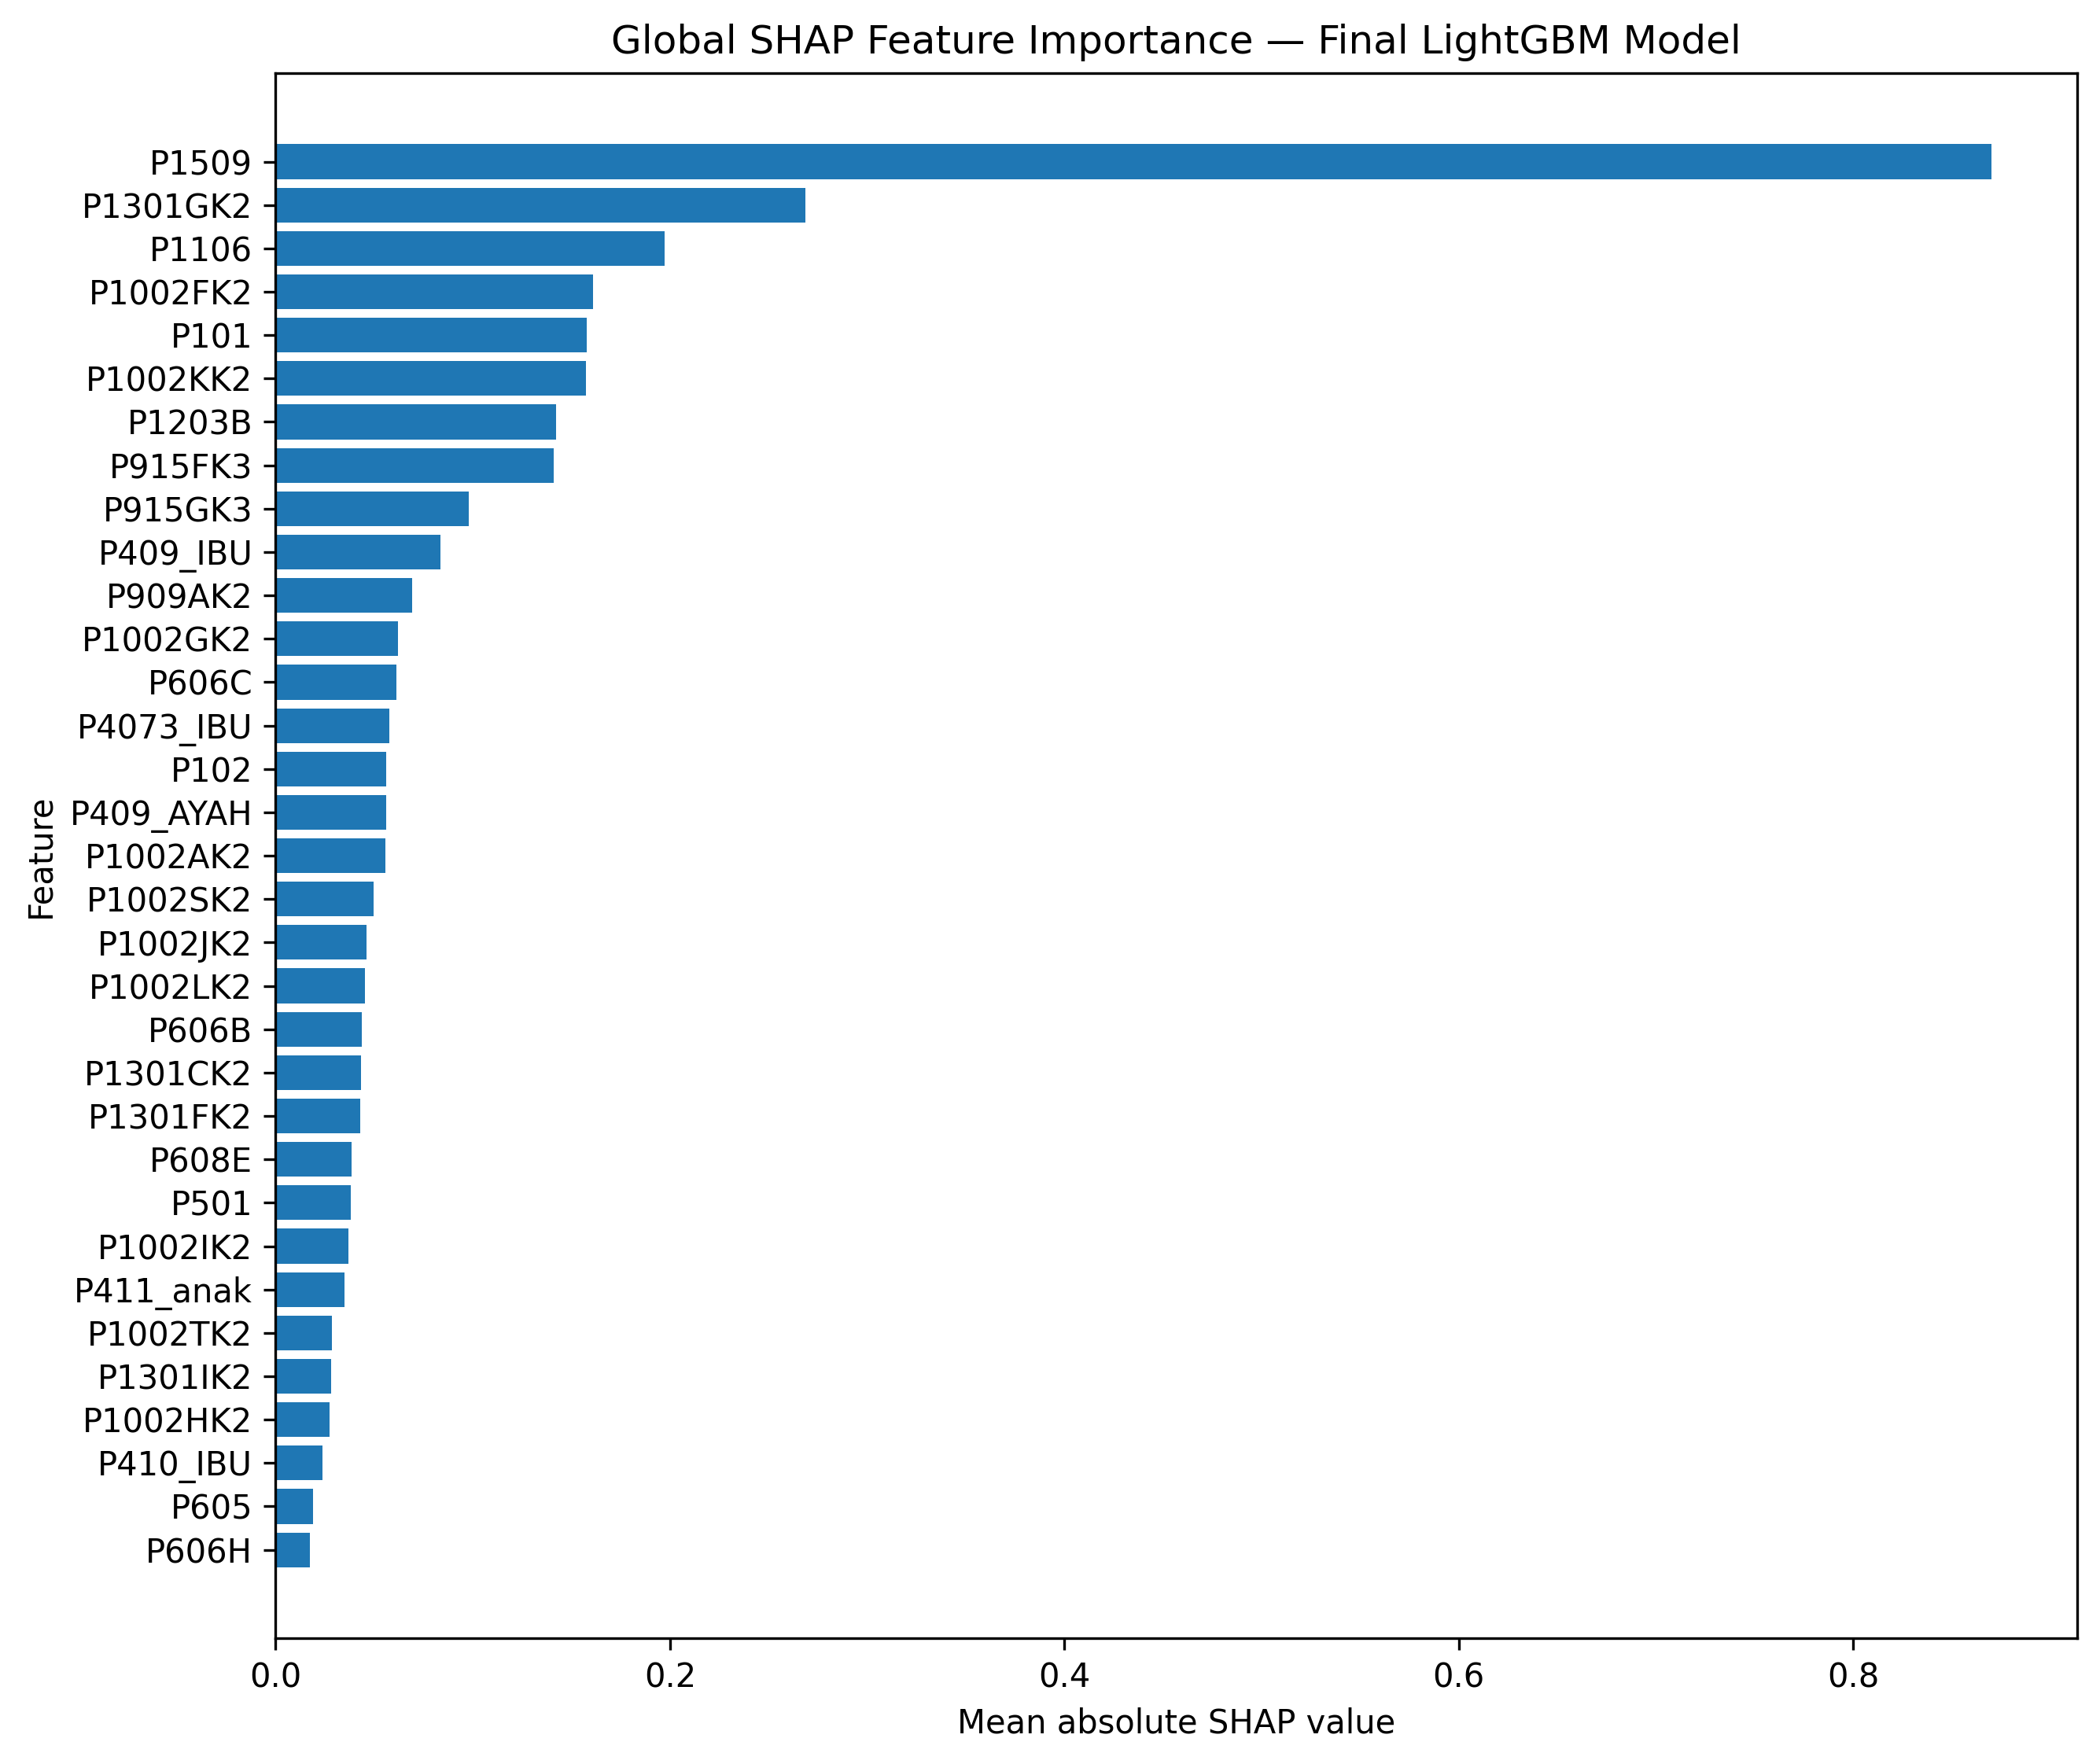

Global_SHAP_Summary.png


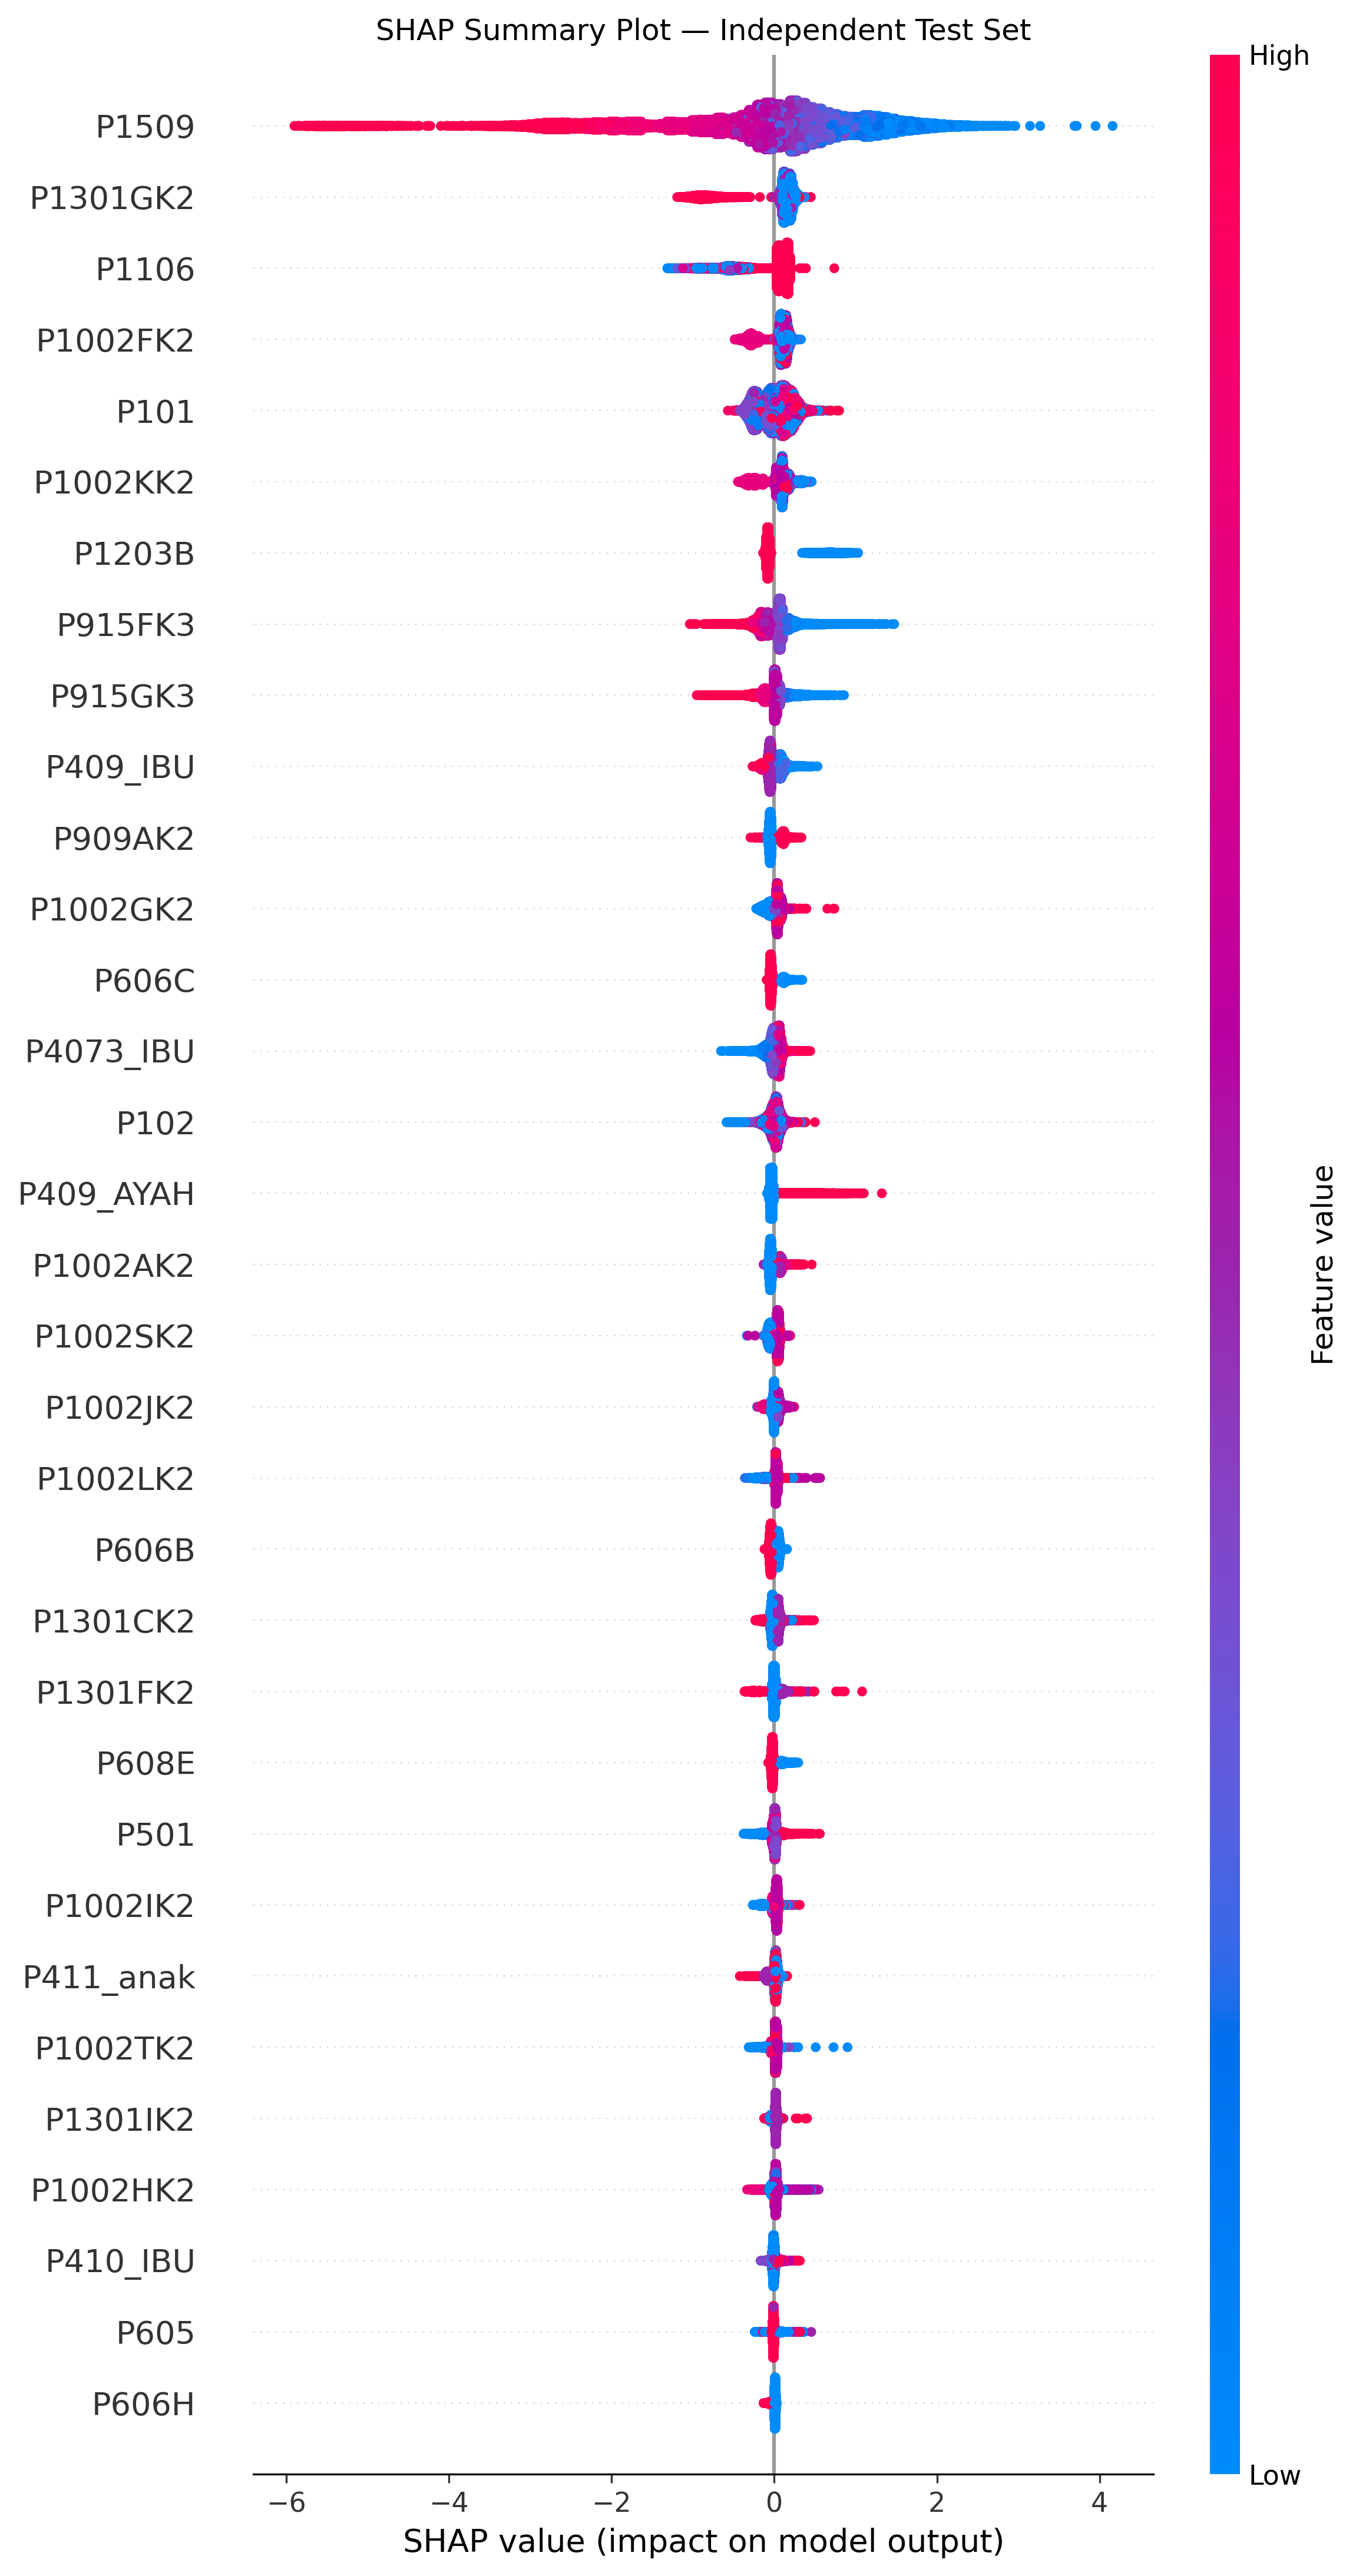

Regional_SHAP_Heatmap.png


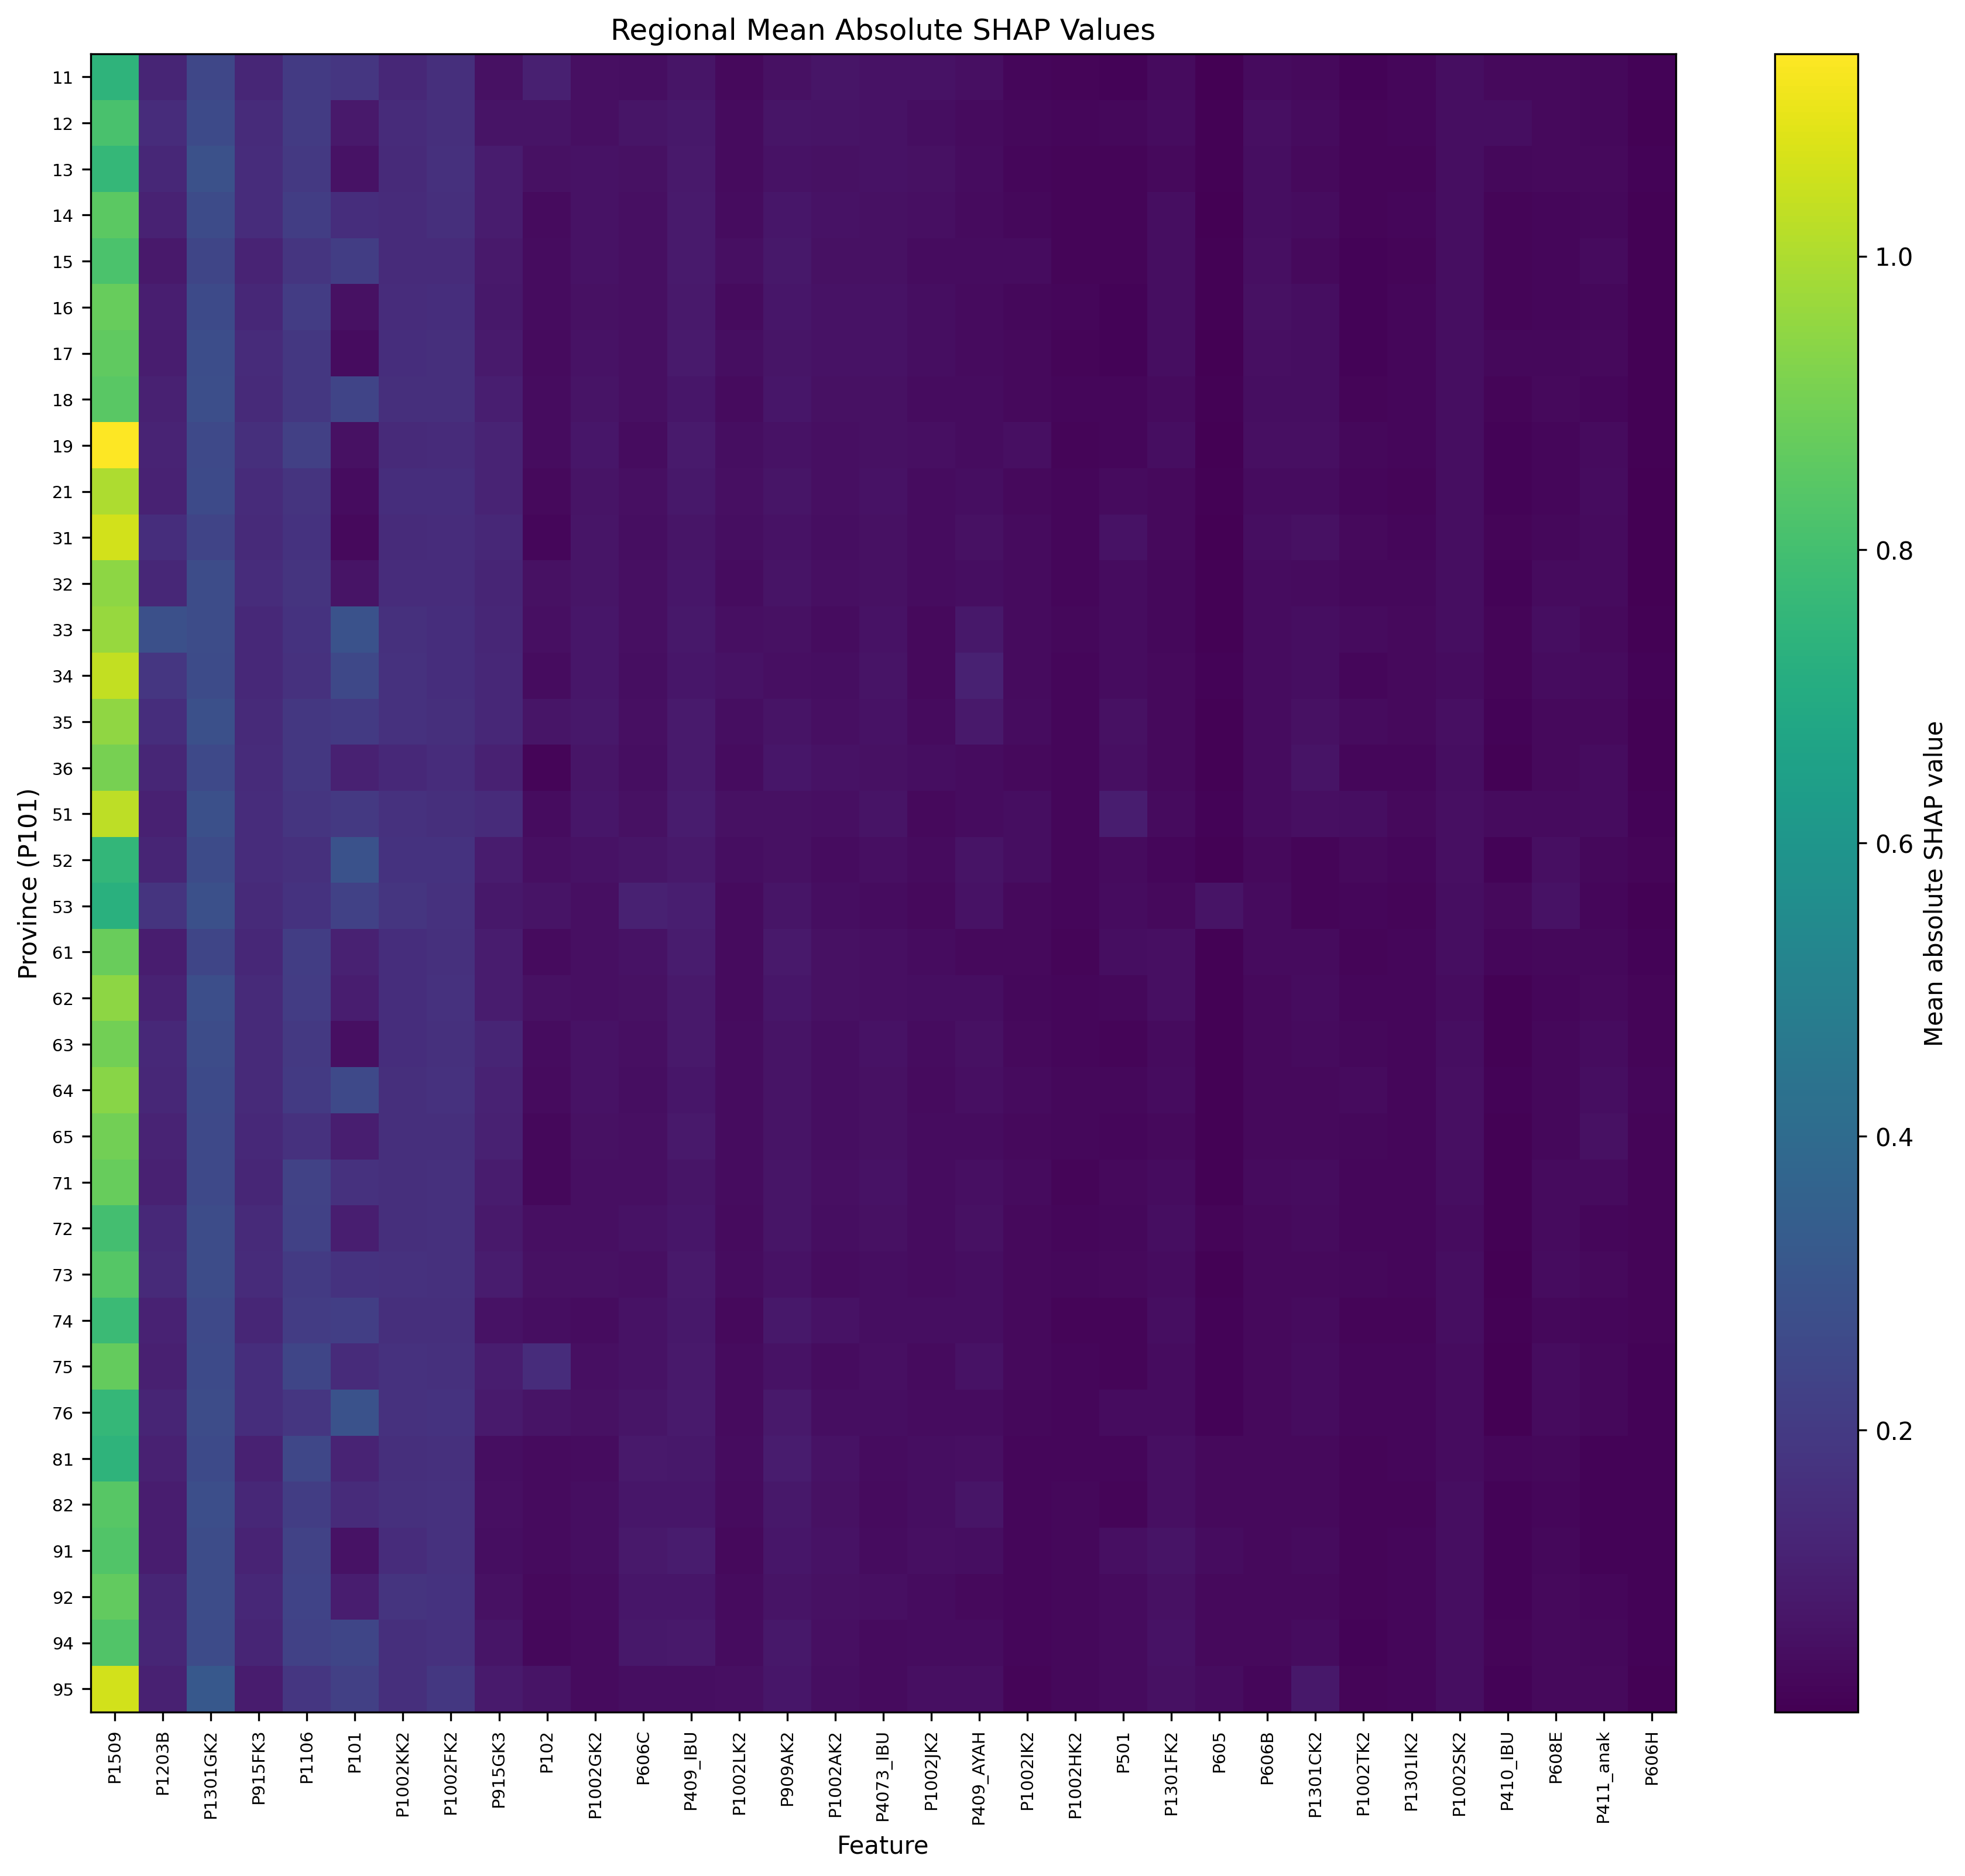

In [ ]:
from IPython.display import display, Image
from pathlib import Path

output_dir = Path("/content/EXP_SHAP_LIGHTGBM_33")

for filename in [
    "Global_SHAP_Bar.png",
    "Global_SHAP_Summary.png",
    "Regional_SHAP_Heatmap.png",
]:
    path = output_dir / filename
    if path.exists():
        print(filename)
        display(Image(filename=str(path)))
    else:
        print(f"File belum ditemukan: {filename}")

In [ ]:


# =============================================================
# EXP-4B: LEAKAGE-AWARE REGIONAL SHAP ANALYSIS
#
# Uses:
#   1. Train_Reconstructed_80.csv
#   2. Test_Reconstructed_20.csv
#   3. Final_Selected_Model.pkl
#   4. Experiment_Configuration.json
#   5. Final_Selected_Features.json
#
# IMPORTANT:
# - Does NOT retrain the final predictive model.
# - Does NOT repeat feature selection.
# - Fits preprocessing on training data only.
# - Applies the same fitted preprocessing to test data.
# - Uses the saved final model and saved feature order.
# =============================================================

from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import shap

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder

warnings.filterwarnings("default")


# =============================================================
# 1. CONFIGURATION
# =============================================================

TRAIN_FILE = Path("Train_Reconstructed_80.csv")
TEST_FILE = Path("Test_Reconstructed_20.csv")

MODEL_FILE = Path("Final_Selected_Model.pkl")
CONFIG_FILE = Path("Experiment_Configuration.json")
FEATURES_FILE = Path("Final_Selected_Features.json")

OUTPUT_DIR = Path("EXP4B_LeakageAware_Regional_SHAP")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "Status"
REGION_COLUMN = "P101"

# Fallback threshold if the configuration does not contain
# a usable scalar threshold.
DEFAULT_THRESHOLD = 0.20

# Numeric variables in the original dataset schema.
# If Experiment_Configuration.json contains an explicit
# numeric-feature list, that list takes precedence.
NUMERIC_SCHEMA = {
    "P915FK3",
    "P915GK3",
    "P1509",
    "P4073_IBU",
    "P4073_AYAH",
}

# Missing-value tokens that may appear in the CSV files.
MISSING_TOKENS = ["#NULL!", "NULL", "null", "N/A", "NA"]

# Use this only if the saved model is the fitted estimator
# and not a complete preprocessing/model pipeline.
EXPECT_TREE_ESTIMATOR = True


# =============================================================
# 2. HELPER FUNCTIONS
# =============================================================

def find_value_by_keys(obj, candidate_keys):
    """
    Recursively search a JSON object for a value associated
    with one of the specified keys.
    """
    candidate_keys = {k.lower() for k in candidate_keys}

    if isinstance(obj, dict):
        for key, value in obj.items():
            if str(key).lower() in candidate_keys:
                return value

        for value in obj.values():
            result = find_value_by_keys(value, candidate_keys)
            if result is not None:
                return result

    elif isinstance(obj, list):
        for value in obj:
            result = find_value_by_keys(value, candidate_keys)
            if result is not None:
                return result

    return None


def extract_feature_list(obj):
    """
    Extract the final ordered feature list from a JSON list
    or a dictionary containing a feature-list field.
    """
    if isinstance(obj, list):
        if all(isinstance(x, str) for x in obj):
            return obj

        raise ValueError(
            "The feature JSON contains a list, but its items "
            "are not all feature-name strings."
        )

    if isinstance(obj, dict):
        preferred_keys = [
            "final_selected_features",
            "selected_features",
            "final_features",
            "features",
            "feature_names",
        ]

        for key in preferred_keys:
            if key in obj:
                value = obj[key]
                if isinstance(value, list) and all(
                    isinstance(x, str) for x in value
                ):
                    return value

        for value in obj.values():
            try:
                return extract_feature_list(value)
            except ValueError:
                pass

    raise ValueError(
        "Could not extract an ordered feature list from "
        "Final_Selected_Features.json."
    )


def load_csv(path):
    """
    Load CSV and normalize common missing-value tokens.
    """
    df = pd.read_csv(path, low_memory=False)
    df = df.replace(MISSING_TOKENS, np.nan)
    return df


def normalize_target(series):
    """
    Convert the original Status coding to:
        0 = Non-stunting
        1 = Stunting

    Accepts original {1, 2} or already-encoded {0, 1}.
    """
    values = pd.to_numeric(series, errors="coerce")
    observed = set(values.dropna().unique())

    if not observed:
        raise ValueError("Target column contains no valid values.")

    if observed.issubset({0, 1}):
        return values

    if observed.issubset({1, 2}):
        return values.map({2: 0, 1: 1})

    raise ValueError(
        "Unexpected Status values. Expected {0, 1} or {1, 2}; "
        f"found {sorted(observed)}."
    )


def find_positive_class_column(model, probability_matrix):
    """
    Identify the probability column for encoded class 1.
    """
    classes = getattr(model, "classes_", None)

    if classes is None:
        if probability_matrix.shape[1] == 2:
            return 1
        raise ValueError(
            "Cannot identify the positive-class probability column."
        )

    positions = [
        i for i, cls in enumerate(classes)
        if cls == 1 or str(cls) == "1"
    ]

    if len(positions) != 1:
        raise ValueError(
            f"Cannot identify class 1 from model.classes_: {classes}"
        )

    return positions[0]


def get_model_feature_names(model):
    """
    Return feature names exposed by the saved estimator,
    when available.
    """
    names = getattr(model, "feature_names_in_", None)

    if names is not None:
        return list(names)

    names = getattr(model, "feature_name_", None)

    if names is not None:
        return list(names)

    booster = getattr(model, "booster_", None)

    if booster is not None and hasattr(booster, "feature_name"):
        names = booster.feature_name()

        # Some models may store generic names rather than
        # the actual original feature names.
        if names and not all(
            str(n).startswith("Column_") for n in names
        ):
            return list(names)

    return None


# =============================================================
# 3. CHECK FILES
# =============================================================

print("=" * 75)
print("EXP-4B: LEAKAGE-AWARE REGIONAL SHAP ANALYSIS")
print("=" * 75)

required_files = [
    TRAIN_FILE,
    TEST_FILE,
    MODEL_FILE,
    CONFIG_FILE,
    FEATURES_FILE,
]

for path in required_files:
    if not path.is_file():
        raise FileNotFoundError(
            f"Required file not found: {path.resolve()}"
        )

print("\nAll five required files were found.")


# =============================================================
# 4. LOAD CONFIGURATION AND FINAL FEATURES
# =============================================================

print("\n" + "=" * 75)
print("LOADING EXPERIMENT CONFIGURATION")
print("=" * 75)

with open(CONFIG_FILE, "r", encoding="utf-8-sig") as f:
    config = json.load(f)

with open(FEATURES_FILE, "r", encoding="utf-8-sig") as f:
    feature_json = json.load(f)

FEATURES = extract_feature_list(feature_json)

if not FEATURES:
    raise ValueError("Final feature list is empty.")

if len(FEATURES) != len(set(FEATURES)):
    raise ValueError(
        "Duplicate feature names found in Final_Selected_Features.json."
    )

# Read threshold from configuration if available.
threshold_value = find_value_by_keys(
    config,
    [
        "selected_threshold",
        "final_threshold",
        "operational_threshold",
        "decision_threshold",
        "threshold",
    ],
)

if (
    isinstance(threshold_value, (int, float))
    and not isinstance(threshold_value, bool)
    and 0 < float(threshold_value) < 1
):
    THRESHOLD = float(threshold_value)
else:
    THRESHOLD = DEFAULT_THRESHOLD
    print(
        "WARNING: No usable scalar threshold was found "
        "in the configuration."
    )
    print("Using the explicitly configured fallback:", THRESHOLD)

selected_model_name = find_value_by_keys(
    config,
    ["selected_model", "final_model", "best_model", "model_name"],
)

print("Configured model name:", selected_model_name)
print("Decision threshold:", THRESHOLD)
print("Number of final features:", len(FEATURES))
print("Final feature order:")

for i, feature in enumerate(FEATURES, start=1):
    print(f"{i:02d}. {feature}")


# =============================================================
# 5. LOAD TRAINING DATA, TEST DATA, AND SAVED MODEL
# =============================================================

print("\n" + "=" * 75)
print("LOADING DATA AND SAVED MODEL")
print("=" * 75)

train = load_csv(TRAIN_FILE)
test = load_csv(TEST_FILE)

print("Training data shape:", train.shape)
print("Testing data shape :", test.shape)

print("\nLoading saved final model...")
model = joblib.load(MODEL_FILE)

print("Loaded model class:", type(model).__name__)

# This script is designed for a saved tree estimator, such as
# the fitted LightGBM classifier. A complete pipeline needs
# separate handling because its preprocessing may already
# be included in the saved object.
if EXPECT_TREE_ESTIMATOR and not hasattr(model, "predict_proba"):
    raise TypeError(
        "The loaded object does not provide predict_proba(). "
        "Inspect the saved object before continuing."
    )

if not hasattr(model, "predict_proba"):
    raise TypeError(
        "The saved model must provide predict_proba() "
        "for this binary-classification workflow."
    )


# =============================================================
# 6. VALIDATE DATA COLUMNS
# =============================================================

print("\n" + "=" * 75)
print("VALIDATING DATA COLUMNS")
print("=" * 75)

for name, df in [("training", train), ("testing", test)]:
    missing_features = [
        feature for feature in FEATURES
        if feature not in df.columns
    ]

    if missing_features:
        raise ValueError(
            f"Missing final features in {name} data: "
            f"{missing_features}"
        )

    if TARGET not in df.columns:
        raise ValueError(
            f"Target column '{TARGET}' is missing from {name} data."
        )

if REGION_COLUMN not in test.columns:
    raise ValueError(
        f"Regional identifier '{REGION_COLUMN}' is missing "
        "from the independent test data."
    )

if REGION_COLUMN not in FEATURES:
    print(
        "P101 is used as a regional identifier and is not "
        "included in the saved final model features."
    )
else:
    print(
        "IMPORTANT: P101 is both a model feature and the "
        "regional identifier. Its SHAP contribution will be "
        "stored separately from the region code."
    )

print("Final feature validation: PASSED")


# =============================================================
# 7. DETERMINE NUMERIC AND CATEGORICAL FEATURES
# =============================================================

print("\n" + "=" * 75)
print("DETERMINING FEATURE TYPES")
print("=" * 75)

# Prefer an explicit numeric-feature list in the configuration.
configured_numeric = find_value_by_keys(
    config,
    [
        "numeric_features",
        "numerical_features",
        "numeric_columns",
        "numerical_columns",
    ],
)

if (
    isinstance(configured_numeric, list)
    and all(isinstance(x, str) for x in configured_numeric)
):
    numeric_set = set(configured_numeric)
    print("Numeric feature definitions: configuration file")
else:
    # Original data schema: five numeric variables.
    numeric_set = set(NUMERIC_SCHEMA)
    print(
        "WARNING: No explicit numeric-feature list was found "
        "in the configuration. Using the known original "
        "dataset schema as the fallback."
    )

NUMERIC_FEATURES = [
    feature for feature in FEATURES
    if feature in numeric_set
]

CATEGORICAL_FEATURES = [
    feature for feature in FEATURES
    if feature not in numeric_set
]

print("Numeric features:", NUMERIC_FEATURES)
print("Categorical features:", CATEGORICAL_FEATURES)

if not NUMERIC_FEATURES and not CATEGORICAL_FEATURES:
    raise ValueError("No model features were identified.")


# =============================================================
# 8. PREPARE TARGET AND PRESERVE ORIGINAL REGION CODES
# =============================================================

print("\n" + "=" * 75)
print("PREPARING TARGET AND REGION IDENTIFIERS")
print("=" * 75)

# Preserve the original province code before encoding P101.
# This is important when P101 is also a model predictor.
region_codes_all = test[REGION_COLUMN].copy()

y_train_all = normalize_target(train[TARGET])
y_test_all = normalize_target(test[TARGET])

valid_train = y_train_all.notna()
valid_test = y_test_all.notna()

if not valid_train.all():
    print(
        "Training rows excluded because Status is missing/invalid:",
        int((~valid_train).sum())
    )

if not valid_test.all():
    print(
        "Testing rows excluded because Status is missing/invalid:",
        int((~valid_test).sum())
    )

train_model = train.loc[valid_train].copy().reset_index(drop=True)
test_model = test.loc[valid_test].copy().reset_index(drop=True)

y_train = (
    y_train_all.loc[valid_train]
    .astype(int)
    .reset_index(drop=True)
)

y_test = (
    y_test_all.loc[valid_test]
    .astype(int)
    .reset_index(drop=True)
)

region_codes = (
    region_codes_all.loc[valid_test]
    .reset_index(drop=True)
)

X_train_raw = train_model[FEATURES].copy()
X_test_raw = test_model[FEATURES].copy()

print("Valid training rows:", len(X_train_raw))
print("Valid testing rows :", len(X_test_raw))


# =============================================================
# 9. FIT PREPROCESSING ON TRAINING DATA ONLY
# =============================================================

print("\n" + "=" * 75)
print("FITTING PREPROCESSING ON TRAINING DATA ONLY")
print("=" * 75)

# Do not fit imputers or encoders on the independent test data.
# Do not run feature selection in this script.

X_train_processed = pd.DataFrame(
    index=X_train_raw.index,
    columns=FEATURES
)

X_test_processed = pd.DataFrame(
    index=X_test_raw.index,
    columns=FEATURES
)

# ----- Numeric imputation: training median -----
if NUMERIC_FEATURES:
    numeric_imputer = SimpleImputer(strategy="median")

    X_train_numeric = numeric_imputer.fit_transform(
        X_train_raw[NUMERIC_FEATURES]
    )

    X_test_numeric = numeric_imputer.transform(
        X_test_raw[NUMERIC_FEATURES]
    )

    X_train_processed.loc[:, NUMERIC_FEATURES] = X_train_numeric
    X_test_processed.loc[:, NUMERIC_FEATURES] = X_test_numeric

# ----- Categorical imputation + ordinal encoding -----
if CATEGORICAL_FEATURES:
    categorical_imputer = SimpleImputer(
        strategy="most_frequent"
    )

    train_cat_imputed = categorical_imputer.fit_transform(
        X_train_raw[CATEGORICAL_FEATURES]
    )

    test_cat_imputed = categorical_imputer.transform(
        X_test_raw[CATEGORICAL_FEATURES]
    )

    categorical_encoder = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )

    train_cat_encoded = categorical_encoder.fit_transform(
        train_cat_imputed
    )

    test_cat_encoded = categorical_encoder.transform(
        test_cat_imputed
    )

    X_train_processed.loc[:, CATEGORICAL_FEATURES] = (
        train_cat_encoded
    )

    X_test_processed.loc[:, CATEGORICAL_FEATURES] = (
        test_cat_encoded
    )

# Restore the exact final feature order from JSON.
X_train_processed = X_train_processed[FEATURES].astype(float)
X_test_processed = X_test_processed[FEATURES].astype(float)

if X_train_processed.isna().any().any():
    raise ValueError(
        "Missing values remain in the transformed training matrix. "
        "Check for entirely missing selected features."
    )

if X_test_processed.isna().any().any():
    raise ValueError(
        "Missing values remain in the transformed test matrix. "
        "Check the original preprocessing specification."
    )

print("Training preprocessing fitted.")
print("Testing preprocessing transformed.")
print("No preprocessing was fitted on test data.")


# =============================================================
# 10. VERIFY MODEL FEATURE COMPATIBILITY
# =============================================================

print("\n" + "=" * 75)
print("VERIFYING SAVED MODEL COMPATIBILITY")
print("=" * 75)

if hasattr(model, "n_features_in_"):
    expected_count = int(model.n_features_in_)

    if expected_count != len(FEATURES):
        raise ValueError(
            f"The saved model expects {expected_count} features, "
            f"but Final_Selected_Features.json contains "
            f"{len(FEATURES)} features."
        )

model_feature_names = get_model_feature_names(model)

if model_feature_names is not None:
    if model_feature_names != FEATURES:
        raise ValueError(
            "Feature names/order from the saved model do not "
            "match Final_Selected_Features.json.\n"
            f"Model feature names: {model_feature_names}\n"
            f"JSON feature names:  {FEATURES}\n"
            "Do not proceed until the model's exact feature "
            "order is established."
        )

print("Number of model features:", len(FEATURES))
print("Feature order verification completed.")


# =============================================================
# 11. INDEPENDENT TEST PREDICTIONS
# =============================================================

print("\n" + "=" * 75)
print("INDEPENDENT TEST SET PREDICTION")
print("=" * 75)

probability_matrix = model.predict_proba(X_test_processed)

positive_class_col = find_positive_class_column(
    model,
    probability_matrix
)

test_probability = probability_matrix[:, positive_class_col]

test_prediction = (
    test_probability >= THRESHOLD
).astype(int)

print("Threshold:", THRESHOLD)
print("Test predictions generated:", len(test_prediction))


# =============================================================
# 12. COMPUTE SHAP VALUES
# =============================================================

print("\n" + "=" * 75)
print("COMPUTING SHAP VALUES")
print("=" * 75)

explainer = shap.TreeExplainer(model)

shap_result = explainer.shap_values(X_test_processed)

# Handle different SHAP return formats.
if isinstance(shap_result, list):
    if len(shap_result) == 2:
        shap_values = np.asarray(shap_result[1])
    else:
        raise ValueError(
            "Unexpected SHAP output list length: "
            f"{len(shap_result)}"
        )
elif hasattr(shap_result, "values"):
    shap_values = np.asarray(shap_result.values)
else:
    shap_values = np.asarray(shap_result)

# Some SHAP versions return:
# (n_samples, n_features, n_classes)
if shap_values.ndim == 3:
    if shap_values.shape[2] == 2:
        shap_values = shap_values[:, :, 1]
    else:
        raise ValueError(
            f"Unexpected SHAP dimensions: {shap_values.shape}"
        )

expected_shape = (len(X_test_processed), len(FEATURES))

if shap_values.shape != expected_shape:
    raise ValueError(
        f"SHAP matrix shape is {shap_values.shape}; "
        f"expected {expected_shape}."
    )

if not np.isfinite(shap_values).all():
    raise ValueError("Non-finite SHAP values were detected.")

print("SHAP matrix shape:", shap_values.shape)


# =============================================================
# 13. SAVE INDIVIDUAL SHAP VALUES
# =============================================================

print("\n" + "=" * 75)
print("SAVING INDIVIDUAL SHAP VALUES")
print("=" * 75)

# Prefix SHAP columns to avoid a collision if P101 is also
# a predictor and a regional identifier.
shap_columns = [f"SHAP_{feature}" for feature in FEATURES]

individual_df = pd.DataFrame(
    shap_values,
    columns=shap_columns
)

individual_df.insert(
    0,
    "Region_Code",
    region_codes.to_numpy()
)

individual_df["Actual_Status"] = y_test.to_numpy()
individual_df["Predicted_Status"] = test_prediction
individual_df["Prediction_Probability"] = test_probability

individual_output = (
    OUTPUT_DIR / "Regional_SHAP_Individual_Values.csv"
)

individual_df.to_csv(individual_output, index=False)

print("Saved:", individual_output)


# =============================================================
# 14. REGIONAL MEAN ABSOLUTE SHAP AND FEATURE RANKING
# =============================================================

print("\n" + "=" * 75)
print("REGIONAL SHAP FEATURE IMPORTANCE")
print("=" * 75)

regional_rows = []

valid_region_mask = individual_df["Region_Code"].notna()

regional_df_input = individual_df.loc[
    valid_region_mask
].copy()

regions = list(regional_df_input["Region_Code"].unique())
regions = sorted(regions, key=lambda value: str(value))

print("Number of regions with valid P101:", len(regions))

if not regions:
    raise ValueError(
        "No valid regional identifiers were found in the test data."
    )

for region in regions:
    mask = (
        regional_df_input["Region_Code"].to_numpy() == region
    )

    region_rows = regional_df_input.loc[mask]
    row_indices = region_rows.index.to_numpy()

    # Recover SHAP rows by matching the corresponding original
    # positions in the full individual SHAP dataframe.
    region_shap = region_rows[shap_columns].to_numpy(dtype=float)

    n_obs = len(region_rows)

    mean_abs_shap = np.abs(region_shap).mean(axis=0)
    total_importance = mean_abs_shap.sum()

    if total_importance > 0:
        importance_pct = (
            mean_abs_shap / total_importance
        ) * 100
    else:
        importance_pct = np.zeros(len(FEATURES))

    order = np.argsort(-mean_abs_shap)
    cumulative_pct = 0.0

    for rank, feature_idx in enumerate(order, start=1):
        cumulative_pct += importance_pct[feature_idx]

        regional_rows.append({
            "Region_Code": region,
            "N_Observations": n_obs,
            "Rank": rank,
            "Feature": FEATURES[feature_idx],
            "Mean_Absolute_SHAP": float(
                mean_abs_shap[feature_idx]
            ),
            "Importance_Percent": float(
                importance_pct[feature_idx]
            ),
            "Cumulative_Percent": float(cumulative_pct)
        })

regional_importance_df = pd.DataFrame(regional_rows)

if regional_importance_df.empty:
    raise ValueError("No regional SHAP rankings were generated.")

regional_ranking_output = (
    OUTPUT_DIR / "Regional_SHAP_Feature_Ranking.xlsx"
)

regional_importance_df.to_excel(
    regional_ranking_output,
    index=False
)

top10_df = regional_importance_df.loc[
    regional_importance_df["Rank"] <= 10
].copy()

top10_output = OUTPUT_DIR / "Regional_SHAP_Top10.xlsx"
top10_df.to_excel(top10_output, index=False)

print("Saved:", regional_ranking_output)
print("Saved:", top10_output)


# =============================================================
# 15. REGIONAL SHAP MATRICES
# =============================================================

mean_abs_matrix = regional_importance_df.pivot(
    index="Region_Code",
    columns="Feature",
    values="Mean_Absolute_SHAP"
)

mean_abs_output = (
    OUTPUT_DIR / "Regional_SHAP_MeanAbsolute_Matrix.xlsx"
)

mean_abs_matrix.to_excel(mean_abs_output)

percentage_matrix = regional_importance_df.pivot(
    index="Region_Code",
    columns="Feature",
    values="Importance_Percent"
)

percentage_output = (
    OUTPUT_DIR / "Regional_SHAP_Importance_Percentage.xlsx"
)

percentage_matrix.to_excel(percentage_output)

print("Saved:", mean_abs_output)
print("Saved:", percentage_output)


# =============================================================
# 16. CROSS-REGIONAL RANKING STABILITY
# =============================================================

print("\n" + "=" * 75)
print("CROSS-REGIONAL RANKING STABILITY")
print("=" * 75)

rank_matrix = regional_importance_df.pivot(
    index="Region_Code",
    columns="Feature",
    values="Rank"
)

rank_matrix = rank_matrix.reindex(columns=FEATURES)

n_regions = len(rank_matrix)

stability_df = pd.DataFrame({
    "Feature": FEATURES,
    "Mean_Rank": rank_matrix.mean(axis=0).reindex(FEATURES).values,
    "Median_Rank": rank_matrix.median(axis=0).reindex(FEATURES).values,
    "SD_Rank": rank_matrix.std(axis=0).reindex(FEATURES).values,
    "Top5_Region_Count": (
        rank_matrix.le(5).sum(axis=0).reindex(FEATURES).values
    ),
    "Top10_Region_Count": (
        rank_matrix.le(10).sum(axis=0).reindex(FEATURES).values
    )
})

stability_df["Top10_Region_Percentage"] = (
    stability_df["Top10_Region_Count"] / n_regions * 100
)

stability_df = stability_df.sort_values(
    ["Mean_Rank", "SD_Rank"],
    ascending=[True, True]
).reset_index(drop=True)

stability_df.insert(
    0,
    "Overall_Rank",
    np.arange(1, len(stability_df) + 1)
)

stability_output = (
    OUTPUT_DIR / "Regional_SHAP_Ranking_Stability.xlsx"
)

stability_df.to_excel(stability_output, index=False)

print("Saved:", stability_output)

print("\nTop 15 features by cross-regional mean rank:")

print(
    stability_df[
        [
            "Overall_Rank",
            "Feature",
            "Mean_Rank",
            "Median_Rank",
            "SD_Rank",
            "Top10_Region_Count",
            "Top10_Region_Percentage"
        ]
    ].head(15).to_string(index=False)
)


# =============================================================
# 17. TOP-10 FEATURE CONSISTENCY
# =============================================================

top_global_features = (
    stability_df.head(10)["Feature"].tolist()
)

consistency_rows = []

for feature in top_global_features:
    feature_ranks = rank_matrix[feature].dropna()

    consistency_rows.append({
        "Feature": feature,
        "Mean_Rank": feature_ranks.mean(),
        "Median_Rank": feature_ranks.median(),
        "SD_Rank": feature_ranks.std(),
        "Minimum_Rank": feature_ranks.min(),
        "Maximum_Rank": feature_ranks.max(),
        "Top5_Region_Count": int(
            (feature_ranks <= 5).sum()
        ),
        "Top10_Region_Count": int(
            (feature_ranks <= 10).sum()
        ),
        "Top10_Region_Percentage": float(
            (feature_ranks <= 10).mean() * 100
        )
    })

consistency_df = pd.DataFrame(consistency_rows)

consistency_output = (
    OUTPUT_DIR / "Regional_SHAP_Top10_Consistency.xlsx"
)

consistency_df.to_excel(consistency_output, index=False)

print("Saved:", consistency_output)


# =============================================================
# 18. SAVE RUN METADATA
# =============================================================

metadata = pd.DataFrame([{
    "Model_File": MODEL_FILE.name,
    "Training_File": TRAIN_FILE.name,
    "Test_File": TEST_FILE.name,
    "Configuration_File": CONFIG_FILE.name,
    "Feature_List_File": FEATURES_FILE.name,
    "Model_Class": type(model).__name__,
    "Number_Training_Rows": len(X_train_processed),
    "Number_Test_Rows": len(X_test_processed),
    "Number_Features": len(FEATURES),
    "Number_Regions": n_regions,
    "Threshold": THRESHOLD,
    "Target_Column": TARGET,
    "Region_Column": REGION_COLUMN,
    "Preprocessing": (
        "Numeric median imputation; categorical most-frequent "
        "imputation and OrdinalEncoder fitted on training only"
    )
}])

metadata_output = OUTPUT_DIR / "EXP4B_Run_Metadata.csv"
metadata.to_csv(metadata_output, index=False)

print("Saved:", metadata_output)


# =============================================================
# 19. SUMMARY
# =============================================================

print("\n" + "=" * 75)
print("EXP-4B COMPLETED")
print("=" * 75)

print("Model class        :", type(model).__name__)
print("Training rows      :", len(X_train_processed))
print("Independent test   :", len(X_test_processed))
print("Final features     :", len(FEATURES))
print("Regions            :", n_regions)
print("Threshold          :", THRESHOLD)
print("Output directory   :", OUTPUT_DIR.resolve())

print("\nGenerated files:")

for output_file in sorted(OUTPUT_DIR.iterdir()):
    print("-", output_file.name)

print("=" * 75)


EXP-4B: LEAKAGE-AWARE REGIONAL SHAP ANALYSIS

All five required files were found.

LOADING EXPERIMENT CONFIGURATION
Configured model name: LightGBM
Decision threshold: 0.2
Number of final features: 33
Final feature order:
01. P1509
02. P1203B
03. P1301GK2
04. P915FK3
05. P1106
06. P101
07. P1002KK2
08. P1002FK2
09. P915GK3
10. P102
11. P1002GK2
12. P606C
13. P409_IBU
14. P1002LK2
15. P909AK2
16. P1002AK2
17. P4073_IBU
18. P1002JK2
19. P409_AYAH
20. P1002IK2
21. P1002HK2
22. P501
23. P1301FK2
24. P605
25. P606B
26. P1301CK2
27. P1002TK2
28. P1301IK2
29. P1002SK2
30. P410_IBU
31. P608E
32. P411_anak
33. P606H

LOADING DATA AND SAVED MODEL


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Training data shape: (197208, 83)
Testing data shape : (49303, 83)

Loading saved final model...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Loaded model class: LGBMClassifier

VALIDATING DATA COLUMNS
IMPORTANT: P101 is both a model feature and the regional identifier. Its SHAP contribution will be stored separately from the region code.
Final feature validation: PASSED

DETERMINING FEATURE TYPES
Numeric feature definitions: configuration file
Numeric features: ['P1509', 'P915FK3', 'P915GK3', 'P4073_IBU']
Categorical features: ['P1203B', 'P1301GK2', 'P1106', 'P101', 'P1002KK2', 'P1002FK2', 'P102', 'P1002GK2', 'P606C', 'P409_IBU', 'P1002LK2', 'P909AK2', 'P1002AK2', 'P1002JK2', 'P409_AYAH', 'P1002IK2', 'P1002HK2', 'P501', 'P1301FK2', 'P605', 'P606B', 'P1301CK2', 'P1002TK2', 'P1301IK2', 'P1002SK2', 'P410_IBU', 'P608E', 'P411_anak', 'P606H']

PREPARING TARGET AND REGION IDENTIFIERS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (8 outputs left out)

Saved: EXP4B_LeakageAware_Regional_SHAP/Regional_SHAP_Individual_Values.csv

REGIONAL SHAP FEATURE IMPORTANCE
Number of regions with valid P101: 36


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Saved: EXP4B_LeakageAware_Regional_SHAP/Regional_SHAP_Feature_Ranking.xlsx
Saved: EXP4B_LeakageAware_Regional_SHAP/Regional_SHAP_Top10.xlsx
Saved: EXP4B_LeakageAware_Regional_SHAP/Regional_SHAP_MeanAbsolute_Matrix.xlsx
Saved: EXP4B_LeakageAware_Regional_SHAP/Regional_SHAP_Importance_Percentage.xlsx

CROSS-REGIONAL RANKING STABILITY
Saved: EXP4B_LeakageAware_Regional_SHAP/Regional_SHAP_Ranking_Stability.xlsx

Top 15 features by cross-regional mean rank:
 Overall_Rank   Feature  Mean_Rank  Median_Rank  SD_Rank  Top10_Region_Count  Top10_Region_Percentage
            1     P1509   1.000000          1.0 0.000000                  36               100.000000
            2     P1106   2.000000          2.0 0.000000                  36               100.000000
            3  P1301GK2   3.138889          3.0 0.424451                  36               100.000000
            4  P1002KK2   5.361111          5.0 0.798312                  36               100.000000
            5 P411_anak   6.30555

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ================================================================
# EXP-4C.....Versi 1 Uji Coba 24/10/2026
# BOOTSTRAP CI + RANK UNCERTAINTY + CROSS-PROVINCIAL
# SPEARMAN RANK CORRELATION
#
# Input:
#   Regional_SHAP_Individual_Values.xlsx
#
# IMPORTANT:
#   P101 = Province Code / Province Identifier
#   P101 is NOT a SHAP feature.
#
# Purpose:
#   Quantify uncertainty and robustness of individual-level
#   SHAP feature importance across provinces.
#
# Data source:
#   Independent Test Set only
#
# No model retraining.
# No threshold modification.
# No training data.
# No regional outcome aggregation.
# ================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr

warnings.filterwarnings("ignore")


# ================================================================
# 1. CONFIGURATION
# ================================================================

INPUT_FILE = "Regional_SHAP_Individual_Values1.xlsx"

OUTPUT_DIR = "EXP4C_Bootstrap_CI_RankCorrelation"

os.makedirs(OUTPUT_DIR, exist_ok=True)


# ------------------------------------------------
# Province identifier
# ------------------------------------------------

PROVINCE_COLUMN = "P101"


# ------------------------------------------------
# Non-SHAP columns
# ------------------------------------------------

NON_SHAP_COLUMNS = [
    "P101",
    "Actual_Status",
    "Predicted_Status",
    "Prediction_Probability"
]


# ------------------------------------------------
# SHAP features
#
# P101 IS INTENTIONALLY EXCLUDED because it is
# the province code.
# ------------------------------------------------

SHAP_FEATURES = [
    "P1509",
    "P1301GK2",
    "P1203B",
    "P915FK3",
    "P1002FK2",
    "P1002KK2",
    "P915GK3",
    "P102",
    "P1002LK2",
    "P1002GK2",
    "P1301FK2",
    "P606C",
    "P1002IK2",
    "P4073_IBU",
    "P409_IBU",
    "P909AK2",
    "P1002JK2",
    "P1002HK2",
    "P1106",
    "P409_AYAH",
    "P501",
    "P1301CK2",
    "P1002TK2",
    "P606B",
    "P1002AK2",
    "P1002SK2",
    "P410_IBU",
    "P605",
    "P1301IK2",
    "P411_anak",
    "P608E",
    "P606H",
    #"P515",
    #"P1002MK2",
    #"P1001"
]


# ================================================================
# 2. REMOVE DUPLICATE FEATURE NAMES
# ================================================================

# Safety protection in case the feature list contains
# accidental duplicate names.

SHAP_FEATURES = list(dict.fromkeys(SHAP_FEATURES))


# ================================================================
# 3. BOOTSTRAP CONFIGURATION
# ================================================================

N_BOOTSTRAP = 1000
CI_LEVEL = 95
RANDOM_SEED = 42

MIN_PROVINCE_N = 30

rng = np.random.default_rng(RANDOM_SEED)


# ================================================================
# 4. HEADER
# ================================================================

print("=" * 70)
print("EXP-4C: BOOTSTRAP CI + RANK UNCERTAINTY")
print("       + CROSS-PROVINCIAL SPEARMAN RANK CORRELATION")
print("=" * 70)

print("\nInput file:")
print(INPUT_FILE)

print("\nOutput directory:")
print(OUTPUT_DIR)


# ================================================================
# 5. CHECK INPUT FILE
# ================================================================

if not os.path.exists(INPUT_FILE):

    raise FileNotFoundError(
        "\nIndividual SHAP file was not found.\n\n"
        f"Expected:\n{INPUT_FILE}\n\n"
        "Please check INPUT_DIR and INPUT_FILE."
    )


# ================================================================
# 6. READ DATA
# ================================================================

print("\nReading individual SHAP values...")

shap_df = pd.read_excel(
    INPUT_FILE,
    sheet_name=0
)

print(f"Rows    : {shap_df.shape[0]:,}")
print(f"Columns : {shap_df.shape[1]}")


# ================================================================
# 7. CHECK REQUIRED COLUMNS
# ================================================================

required_columns = [
    PROVINCE_COLUMN,
    "Actual_Status",
    "Predicted_Status",
    "Prediction_Probability"
]

missing_required = [
    col for col in required_columns
    if col not in shap_df.columns
]

if missing_required:

    raise ValueError(
        "\nMissing required columns:\n"
        + "\n".join(
            f"  - {col}"
            for col in missing_required
        )
    )


# ================================================================
# 8. CHECK SHAP FEATURES
# ================================================================

missing_features = [
    col for col in SHAP_FEATURES
    if col not in shap_df.columns
]

if missing_features:

    raise ValueError(
        "\nThe following SHAP features are missing:\n"
        + "\n".join(
            f"  - {col}"
            for col in missing_features
        )
    )


# ------------------------------------------------
# Check whether P101 accidentally appears as SHAP
# ------------------------------------------------

if PROVINCE_COLUMN in SHAP_FEATURES:

    raise ValueError(
        "\nERROR: P101 is included as a SHAP feature.\n"
        "P101 must only be used as Province Identifier."
    )


print("\nFeature validation:")
print(f"  Province identifier : {PROVINCE_COLUMN}")
print(f"  SHAP features       : {len(SHAP_FEATURES)}")

print("\nSHAP features:")
for i, feature in enumerate(SHAP_FEATURES, start=1):
    print(f"  {i:02d}. {feature}")


# ================================================================
# 9. CLEAN PROVINCE IDENTIFIER
# ================================================================

# Keep P101 as code.
# Do NOT convert it into province names.

shap_df[PROVINCE_COLUMN] = pd.to_numeric(
    shap_df[PROVINCE_COLUMN],
    errors="coerce"
)

before = len(shap_df)

shap_df = shap_df.dropna(
    subset=[PROVINCE_COLUMN]
).copy()

after = len(shap_df)

if before != after:

    print(
        f"\nRemoved {before - after:,} rows "
        "with missing/invalid province code."
    )


# Convert to integer province code

shap_df[PROVINCE_COLUMN] = (
    shap_df[PROVINCE_COLUMN]
    .astype(int)
)


# ================================================================
# 10. CONVERT SHAP COLUMNS TO NUMERIC
# ================================================================

for feature in SHAP_FEATURES:

    shap_df[feature] = pd.to_numeric(
        shap_df[feature],
        errors="coerce"
    )


# ================================================================
# 11. CHECK SHAP MISSINGNESS
# ================================================================

missing_shap = shap_df[SHAP_FEATURES].isna().sum()

if missing_shap.sum() > 0:

    print("\nWARNING: Missing SHAP values detected.")

    print(
        missing_shap[
            missing_shap > 0
        ]
    )

    # Rows with missing SHAP values cannot contribute
    # to complete multivariate rank bootstrap.
    #
    # We therefore remove rows having missing SHAP
    # values across the 33 features.

    before = len(shap_df)

    shap_df = shap_df.dropna(
        subset=SHAP_FEATURES
    ).copy()

    after = len(shap_df)

    print(
        f"Removed {before - after:,} rows "
        "with incomplete SHAP values."
    )


# ================================================================
# 12. BASIC DATA INFORMATION
# ================================================================

provinces = sorted(
    shap_df[PROVINCE_COLUMN].unique()
)

n_provinces = len(provinces)

print("\nData summary:")
print(f"  Total observations : {len(shap_df):,}")
print(f"  Provinces          : {n_provinces}")
print(f"  SHAP features      : {len(SHAP_FEATURES)}")


# ================================================================
# 13. PROVINCE SAMPLE SIZE
# ================================================================

province_n = (
    shap_df
    .groupby(PROVINCE_COLUMN)
    .size()
    .reset_index(name="N")
    .sort_values(PROVINCE_COLUMN)
)

province_n["Small_Sample_Warning"] = (
    province_n["N"] < MIN_PROVINCE_N
)

print("\nProvince sample sizes:")

print(province_n.to_string(index=False))


small_provinces = province_n.loc[
    province_n["Small_Sample_Warning"],
    PROVINCE_COLUMN
].tolist()

if small_provinces:

    print(
        "\nWARNING:"
        f" {len(small_provinces)} province(s) "
        f"have N < {MIN_PROVINCE_N}."
    )

    print(
        "These provinces are retained, but their "
        "bootstrap uncertainty should be interpreted cautiously."
    )


# ================================================================
# 14. BOOTSTRAP FUNCTION
# ================================================================

def bootstrap_multifeature(
    values,
    n_bootstrap=1000,
    random_generator=None
):
    """
    Row-level nonparametric bootstrap.

    Input:
        values : 2D numpy array
                 rows    = individuals
                 columns = SHAP features

    For every bootstrap replicate:
        1. Sample individuals with replacement.
        2. Calculate mean absolute SHAP for ALL features.
        3. Rank all features jointly.

    Returns:
        bootstrap_means
        bootstrap_ranks
    """

    if random_generator is None:

        random_generator = np.random.default_rng(42)

    n, p = values.shape

    bootstrap_means = np.zeros(
        (n_bootstrap, p)
    )

    bootstrap_ranks = np.zeros(
        (n_bootstrap, p)
    )

    absolute_values = np.abs(values)

    for b in range(n_bootstrap):

        # ------------------------------------------------
        # Resample INDIVIDUALS
        # ------------------------------------------------

        indices = random_generator.integers(
            0,
            n,
            size=n
        )

        sample = absolute_values[
            indices,
            :
        ]

        # ------------------------------------------------
        # Mean absolute SHAP
        # ------------------------------------------------

        means = np.mean(
            sample,
            axis=0
        )

        bootstrap_means[b, :] = means

        # ------------------------------------------------
        # Rank features
        #
        # rank 1 = highest mean absolute SHAP
        # ------------------------------------------------

        order = np.argsort(
            -means,
            kind="mergesort"
        )

        ranks = np.empty(
            p,
            dtype=int
        )

        ranks[order] = np.arange(
            1,
            p + 1
        )

        bootstrap_ranks[b, :] = ranks

    return (
        bootstrap_means,
        bootstrap_ranks
    )


# ================================================================
# 15. STEP 1
# BOOTSTRAP 95% CI FOR MEAN ABSOLUTE SHAP
# ================================================================

print("\n" + "=" * 70)
print("STEP 1: BOOTSTRAP 95% CI FOR MEAN ABSOLUTE SHAP")
print("=" * 70)


feature_ci_results = []


for province in provinces:

    print(
        f"\nProvince {province}..."
    )

    province_data = shap_df.loc[
        shap_df[PROVINCE_COLUMN] == province,
        SHAP_FEATURES
    ]

    values = province_data.to_numpy(
        dtype=float
    )

    n = len(values)

    bootstrap_means, _ = (
        bootstrap_multifeature(
            values,
            n_bootstrap=N_BOOTSTRAP,
            random_generator=rng
        )
    )

    observed_means = np.mean(
        np.abs(values),
        axis=0
    )

    lower_percentile = (
        (100 - CI_LEVEL) / 2
    )

    upper_percentile = (
        100 - lower_percentile
    )

    lower_ci = np.percentile(
        bootstrap_means,
        lower_percentile,
        axis=0
    )

    upper_ci = np.percentile(
        bootstrap_means,
        upper_percentile,
        axis=0
    )

    for i, feature in enumerate(
        SHAP_FEATURES
    ):

        feature_ci_results.append({

            "Province": province,

            "Feature": feature,

            "N": n,

            "Mean_Absolute_SHAP":
                observed_means[i],

            "CI_Lower_95":
                lower_ci[i],

            "CI_Upper_95":
                upper_ci[i],

            "CI_Width_95":
                upper_ci[i] -
                lower_ci[i]
        })


bootstrap_feature_ci = pd.DataFrame(
    feature_ci_results
)


# ================================================================
# 16. STEP 2
# BOOTSTRAP RANK UNCERTAINTY
# ================================================================

print("\n" + "=" * 70)
print("STEP 2: BOOTSTRAP FEATURE RANK UNCERTAINTY")
print("=" * 70)


rank_ci_results = []


for province in provinces:

    print(
        f"\nProvince {province}..."
    )

    province_data = shap_df.loc[
        shap_df[PROVINCE_COLUMN] == province,
        SHAP_FEATURES
    ]

    values = province_data.to_numpy(
        dtype=float
    )

    n = len(values)

    bootstrap_means, bootstrap_ranks = (
        bootstrap_multifeature(
            values,
            n_bootstrap=N_BOOTSTRAP,
            random_generator=rng
        )
    )

    observed_mean_abs = np.mean(
        np.abs(values),
        axis=0
    )

    observed_order = np.argsort(
        -observed_mean_abs,
        kind="mergesort"
    )

    observed_ranks = np.empty(
        len(SHAP_FEATURES),
        dtype=int
    )

    observed_ranks[
        observed_order
    ] = np.arange(
        1,
        len(SHAP_FEATURES) + 1
    )

    for i, feature in enumerate(
        SHAP_FEATURES
    ):

        feature_ranks = (
            bootstrap_ranks[:, i]
        )

        rank_ci_lower = np.percentile(
            feature_ranks,
            lower_percentile
        )

        rank_ci_upper = np.percentile(
            feature_ranks,
            upper_percentile
        )

        top5_probability = np.mean(
            feature_ranks <= 5
        )

        top10_probability = np.mean(
            feature_ranks <= 10
        )

        rank_ci_results.append({

            "Province": province,

            "Feature": feature,

            "N": n,

            "Observed_Mean_Absolute_SHAP":
                observed_mean_abs[i],

            "Observed_Rank":
                observed_ranks[i],

            "Bootstrap_Mean_Rank":
                np.mean(feature_ranks),

            "Bootstrap_Median_Rank":
                np.median(feature_ranks),

            "Bootstrap_SD_Rank":
                np.std(
                    feature_ranks,
                    ddof=1
                ),

            "Rank_CI_Lower_95":
                rank_ci_lower,

            "Rank_CI_Upper_95":
                rank_ci_upper,

            "Top5_Probability":
                top5_probability,

            "Top10_Probability":
                top10_probability
        })


bootstrap_rank_ci = pd.DataFrame(
    rank_ci_results
)


# ================================================================
# 17. STEP 3
# OBSERVED RANK SUMMARY ACROSS PROVINCES
# ================================================================

print("\n" + "=" * 70)
print("STEP 3: CROSS-PROVINCIAL RANK SUMMARY")
print("=" * 70)


rank_summary = (
    bootstrap_rank_ci
    .groupby("Feature")
    .agg(

        Mean_Observed_Rank=(
            "Observed_Rank",
            "mean"
        ),

        Median_Observed_Rank=(
            "Observed_Rank",
            "median"
        ),

        SD_Observed_Rank=(
            "Observed_Rank",
            "std"
        ),

        Mean_Bootstrap_Rank=(
            "Bootstrap_Mean_Rank",
            "mean"
        ),

        Mean_Top5_Probability=(
            "Top5_Probability",
            "mean"
        ),

        Mean_Top10_Probability=(
            "Top10_Probability",
            "mean"
        )
    )
    .reset_index()
)


rank_summary = rank_summary.sort_values(
    "Mean_Observed_Rank"
)


# ================================================================
# 18. STEP 4
# PROVINCE × FEATURE RANK MATRIX
# ================================================================

rank_matrix = (
    bootstrap_rank_ci
    .pivot(
        index="Province",
        columns="Feature",
        values="Observed_Rank"
    )
)

rank_matrix = rank_matrix[
    SHAP_FEATURES
]


# ================================================================
# 19. STEP 5
# CROSS-PROVINCIAL SPEARMAN RANK CORRELATION
# ================================================================

print("\n" + "=" * 70)
print("STEP 4: CROSS-PROVINCIAL SPEARMAN RANK CORRELATION")
print("=" * 70)


spearman_matrix = pd.DataFrame(
    np.nan,
    index=provinces,
    columns=provinces,
    dtype=float
)


pairwise_results = []


for i, province_a in enumerate(provinces):

    for j, province_b in enumerate(provinces):

        if i == j:

            spearman_matrix.loc[
                province_a,
                province_b
            ] = 1.0

            continue

        ranks_a = rank_matrix.loc[
            province_a
        ]

        ranks_b = rank_matrix.loc[
            province_b
        ]

        valid = (
            ranks_a.notna()
            &
            ranks_b.notna()
        )

        if valid.sum() < 3:

            continue

        rho, p_value = spearmanr(
            ranks_a[valid],
            ranks_b[valid]
        )

        spearman_matrix.loc[
            province_a,
            province_b
        ] = rho

        # Save each pair only once

        if i < j:

            pairwise_results.append({

                "Province_A":
                    province_a,

                "Province_B":
                    province_b,

                "N_Common_Features":
                    int(valid.sum()),

                "Spearman_Rho":
                    rho,

                "P_Value":
                    p_value
            })


pairwise_spearman = pd.DataFrame(
    pairwise_results
)


# ================================================================
# 20. SPEARMAN SUMMARY
# ================================================================

if not pairwise_spearman.empty:

    spearman_summary = pd.DataFrame({

        "Metric": [

            "Number_of_Provinces",

            "Number_of_Pairs",

            "Mean_Spearman_Rho",

            "Median_Spearman_Rho",

            "SD_Spearman_Rho",

            "Minimum_Spearman_Rho",

            "Maximum_Spearman_Rho",

            "Pairs_Rho_GE_0.70",

            "Pairs_Rho_GE_0.80",

            "Pairs_Rho_GE_0.90"
        ],

        "Value": [

            n_provinces,

            len(pairwise_spearman),

            pairwise_spearman[
                "Spearman_Rho"
            ].mean(),

            pairwise_spearman[
                "Spearman_Rho"
            ].median(),

            pairwise_spearman[
                "Spearman_Rho"
            ].std(),

            pairwise_spearman[
                "Spearman_Rho"
            ].min(),

            pairwise_spearman[
                "Spearman_Rho"
            ].max(),

            (
                pairwise_spearman[
                    "Spearman_Rho"
                ] >= 0.70
            ).sum(),

            (
                pairwise_spearman[
                    "Spearman_Rho"
                ] >= 0.80
            ).sum(),

            (
                pairwise_spearman[
                    "Spearman_Rho"
                ] >= 0.90
            ).sum()
        ]
    })

else:

    spearman_summary = pd.DataFrame()


# ================================================================
# 21. GLOBAL FEATURE IMPORTANCE
# ================================================================

global_mean_abs_shap = (
    shap_df[SHAP_FEATURES]
    .abs()
    .mean()
    .sort_values(
        ascending=False
    )
)

global_importance = (
    global_mean_abs_shap
    .reset_index()
)

global_importance.columns = [
    "Feature",
    "Global_Mean_Absolute_SHAP"
]

global_importance[
    "Global_Rank"
] = np.arange(
    1,
    len(global_importance) + 1
)


# ================================================================
# 22. TOP-10 FEATURES
# ================================================================

top10_features = (
    global_importance
    .head(10)
    ["Feature"]
    .tolist()
)

print("\nGlobal Top-10 SHAP features:")

for rank, feature in enumerate(
    top10_features,
    start=1
):

    value = global_mean_abs_shap[
        feature
    ]

    print(
        f"{rank:02d}. "
        f"{feature:<15} "
        f"{value:.6f}"
    )


# ================================================================
# 23. TOP-10 SPEARMAN MATRIX
# ================================================================

top10_spearman = spearman_matrix.loc[
    :,
    :
]

# Keep only provinces but rank matrix remains based
# on all 33 features.


# ================================================================
# 24. P1509 SPECIFIC RESULTS
# ================================================================

p1509_ci = (
    bootstrap_feature_ci[
        bootstrap_feature_ci["Feature"]
        == "P1509"
    ]
    .copy()
)


# ================================================================
# 25. EXPORT EXCEL
# ================================================================

excel_output = os.path.join(
    OUTPUT_DIR,
    "EXP4C_Bootstrap_CI_RankCorrelation_Results.xlsx"
)

print("\n" + "=" * 70)
print("EXPORTING RESULTS")
print("=" * 70)


with pd.ExcelWriter(
    excel_output,
    engine="openpyxl"
) as writer:

    # ------------------------------------------------
    # Bootstrap mean absolute SHAP CI
    # ------------------------------------------------

    bootstrap_feature_ci.to_excel(
        writer,
        sheet_name="Bootstrap_Feature_CI",
        index=False
    )

    # ------------------------------------------------
    # Bootstrap rank uncertainty
    # ------------------------------------------------

    bootstrap_rank_ci.to_excel(
        writer,
        sheet_name="Bootstrap_Rank_CI",
        index=False
    )

    # ------------------------------------------------
    # Cross-provincial rank summary
    # ------------------------------------------------

    rank_summary.to_excel(
        writer,
        sheet_name="Rank_Summary",
        index=False
    )

    # ------------------------------------------------
    # Province × feature rank matrix
    # ------------------------------------------------

    rank_matrix.to_excel(
        writer,
        sheet_name="Rank_Matrix"
    )

    # ------------------------------------------------
    # Spearman matrix
    # ------------------------------------------------

    spearman_matrix.to_excel(
        writer,
        sheet_name="Spearman_Matrix"
    )

    # ------------------------------------------------
    # Pairwise Spearman
    # ------------------------------------------------

    pairwise_spearman.to_excel(
        writer,
        sheet_name="Pairwise_Spearman",
        index=False
    )

    # ------------------------------------------------
    # Spearman summary
    # ------------------------------------------------

    spearman_summary.to_excel(
        writer,
        sheet_name="Spearman_Summary",
        index=False
    )

    # ------------------------------------------------
    # P1509
    # ------------------------------------------------

    if not p1509_ci.empty:

        p1509_ci.to_excel(
            writer,
            sheet_name="P1509_CI",
            index=False
        )

    # ------------------------------------------------
    # Province N
    # ------------------------------------------------

    province_n.to_excel(
        writer,
        sheet_name="Province_N",
        index=False
    )

    # ------------------------------------------------
    # Global importance
    # ------------------------------------------------

    global_importance.to_excel(
        writer,
        sheet_name="Global_Importance",
        index=False
    )

    # ------------------------------------------------
    # Metadata
    # ------------------------------------------------

    metadata = pd.DataFrame({

        "Parameter": [

            "Input_File",

            "Province_Identifier",

            "Number_of_SHAP_Features",

            "Number_of_Provinces",

            "Total_Independent_Test_Observations",

            "Bootstrap_Iterations",

            "Confidence_Level",

            "Random_Seed",

            "Minimum_Province_N",

            "Bootstrap_Method",

            "P101_Treatment",

            "Model_Retraining",

            "Threshold_Optimization"
        ],

        "Value": [

            INPUT_FILE,

            PROVINCE_COLUMN,

            len(SHAP_FEATURES),

            n_provinces,

            len(shap_df),

            N_BOOTSTRAP,

            CI_LEVEL,

            RANDOM_SEED,

            MIN_PROVINCE_N,

            "Row-level nonparametric bootstrap within province",

            "Province identifier only; excluded from SHAP features",

            "No",

            "No"
        ]
    })

    metadata.to_excel(
        writer,
        sheet_name="EXP4C_Metadata",
        index=False
    )


print(
    f"\nExcel saved:\n{excel_output}"
)


# ================================================================
# 26. EXPORT CSV FILES
# ================================================================

bootstrap_feature_ci.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "EXP4C_Bootstrap_Feature_CI.csv"
    ),
    index=False
)

bootstrap_rank_ci.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "EXP4C_Bootstrap_Rank_CI.csv"
    ),
    index=False
)

rank_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "EXP4C_Rank_Summary.csv"
    ),
    index=False
)

rank_matrix.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "EXP4C_Rank_Matrix.csv"
    )
)

pairwise_spearman.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "EXP4C_Pairwise_Spearman.csv"
    ),
    index=False
)

spearman_matrix.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "EXP4C_Spearman_Matrix.csv"
    )
)

global_importance.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "EXP4C_Global_Importance.csv"
    ),
    index=False
)


# ================================================================
# 27. FIGURE 1
# SPEARMAN RANK CORRELATION HEATMAP
# ================================================================

print("\nCreating Figure 1...")

fig, ax = plt.subplots(
    figsize=(14, 12)
)

im = ax.imshow(
    spearman_matrix.values,
    vmin=-1,
    vmax=1,
    aspect="auto"
)

ax.set_title(
    "Cross-Provincial Spearman Rank Correlation",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel(
    "Province Code",
    fontsize=13
)

ax.set_ylabel(
    "Province Code",
    fontsize=13
)

ax.set_xticks(
    np.arange(len(provinces))
)

ax.set_yticks(
    np.arange(len(provinces))
)

ax.set_xticklabels(
    provinces,
    rotation=90
)

ax.set_yticklabels(
    provinces
)

cbar = fig.colorbar(
    im,
    ax=ax
)

cbar.set_label(
    "Spearman's rho",
    fontsize=12
)

plt.tight_layout()

fig1 = os.path.join(
    OUTPUT_DIR,
    "Figure1_Spearman_Rank_Correlation_Heatmap.png"
)

plt.savefig(
    fig1,
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ================================================================
# 28. FIGURE 2
# TOP-10 RANK BOOTSTRAP CI
# ================================================================

print("Creating Figure 2...")

top10_rank_data = (
    bootstrap_rank_ci[
        bootstrap_rank_ci[
            "Feature"
        ].isin(top10_features)
    ]
    .copy()
)

top10_rank_data = (
    top10_rank_data
    .groupby("Feature")
    .agg(

        Mean_Rank=(
            "Bootstrap_Mean_Rank",
            "mean"
        ),

        Lower_CI=(
            "Rank_CI_Lower_95",
            "mean"
        ),

        Upper_CI=(
            "Rank_CI_Upper_95",
            "mean"
        )
    )
    .reindex(top10_features)
)

fig, ax = plt.subplots(
    figsize=(12, 7)
)

x = np.arange(
    len(top10_rank_data)
)

means = top10_rank_data[
    "Mean_Rank"
].values

lower = top10_rank_data[
    "Lower_CI"
].values

upper = top10_rank_data[
    "Upper_CI"
].values

yerr = np.vstack([
    means - lower,
    upper - means
])

ax.errorbar(
    x,
    means,
    yerr=yerr,
    fmt="o",
    capsize=5
)

ax.set_xticks(x)

ax.set_xticklabels(
    top10_rank_data.index,
    rotation=45,
    ha="right"
)

ax.set_ylabel(
    "Bootstrap Mean Rank",
    fontsize=13
)

ax.set_xlabel(
    "Feature",
    fontsize=13
)

ax.set_title(
    "Top-10 Feature Rank Uncertainty Across Provinces",
    fontsize=16,
    fontweight="bold"
)

ax.invert_yaxis()

ax.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

fig2 = os.path.join(
    OUTPUT_DIR,
    "Figure2_Top10_Rank_Bootstrap_CI.png"
)

plt.savefig(
    fig2,
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ================================================================
# 29. FIGURE 3
# P1509 MEAN ABSOLUTE SHAP CI
# ================================================================

print("Creating Figure 3...")

if not p1509_ci.empty:

    p1509_plot = (
        p1509_ci
        .sort_values("Province")
    )

    x = np.arange(
        len(p1509_plot)
    )

    mean_values = (
        p1509_plot[
            "Mean_Absolute_SHAP"
        ]
        .values
    )

    lower = (
        p1509_plot[
            "CI_Lower_95"
        ]
        .values
    )

    upper = (
        p1509_plot[
            "CI_Upper_95"
        ]
        .values
    )

    yerr = np.vstack([
        mean_values - lower,
        upper - mean_values
    ])

    fig, ax = plt.subplots(
        figsize=(14, 7)
    )

    ax.errorbar(
        x,
        mean_values,
        yerr=yerr,
        fmt="o",
        capsize=4
    )

    ax.set_xticks(x)

    ax.set_xticklabels(
        p1509_plot[
            "Province"
        ],
        rotation=90
    )

    ax.set_xlabel(
        "Province Code",
        fontsize=13
    )

    ax.set_ylabel(
        "Mean Absolute SHAP",
        fontsize=13
    )

    ax.set_title(
        "P1509 SHAP Importance with 95% Bootstrap CI",
        fontsize=16,
        fontweight="bold"
    )

    ax.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()

    fig3 = os.path.join(
        OUTPUT_DIR,
        "Figure3_P1509_SHAP_Bootstrap_CI.png"
    )

    plt.savefig(
        fig3,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()


# ================================================================
# 30. FIGURE 4
# TOP-10 RANKING PROBABILITY
# ================================================================

print("Creating Figure 4...")

top10_probability = (
    bootstrap_rank_ci[
        bootstrap_rank_ci[
            "Feature"
        ].isin(top10_features)
    ]
    .groupby("Feature")
    .agg(

        Top5_Probability=(
            "Top5_Probability",
            "mean"
        ),

        Top10_Probability=(
            "Top10_Probability",
            "mean"
        )
    )
    .reindex(top10_features)
)

fig, ax = plt.subplots(
    figsize=(12, 7)
)

x = np.arange(
    len(top10_probability)
)

width = 0.38

ax.bar(
    x - width / 2,
    top10_probability[
        "Top5_Probability"
    ],
    width,
    label="Top-5"
)

ax.bar(
    x + width / 2,
    top10_probability[
        "Top10_Probability"
    ],
    width,
    label="Top-10"
)

ax.set_xticks(x)

ax.set_xticklabels(
    top10_probability.index,
    rotation=45,
    ha="right"
)

ax.set_ylim(
    0,
    1
)

ax.set_ylabel(
    "Mean Ranking Probability",
    fontsize=13
)

ax.set_xlabel(
    "Feature",
    fontsize=13
)

ax.set_title(
    "Bootstrap Probability of Top-5 and Top-10 Ranking",
    fontsize=16,
    fontweight="bold"
)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

fig4 = os.path.join(
    OUTPUT_DIR,
    "Figure4_Top10_Ranking_Probability.png"
)

plt.savefig(
    fig4,
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ================================================================
# 31. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 70)
print("EXP-4C COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nInput:")
print(
    f"  {INPUT_FILE}"
)

print("\nDataset:")
print(
    f"  Independent test observations : {len(shap_df):,}"
)

print(
    f"  Provinces                     : {n_provinces}"
)

print(
    f"  SHAP features                 : {len(SHAP_FEATURES)}"
)

print(
    f"  Bootstrap iterations          : {N_BOOTSTRAP:,}"
)

print(
    f"  Confidence interval           : {CI_LEVEL}%"
)

print(
    "\nProvince identifier:"
)

print(
    "  P101 = Province Code"
)

print(
    "\nP101 was NOT treated as a SHAP feature."
)

print(
    "\nBootstrap method:"
)

print(
    "  Row-level resampling within each province."
)

print(
    "\nModel:"
)

print(
    "  No retraining."
)

print(
    "\nThreshold:"
)

print(
    "  No modification."
)

print(
    "\nMain output:"
)

print(
    f"  {excel_output}"
)

print("\nFigures:")

print(
    f"  {fig1}"
)

print(
    f"  {fig2}"
)

if not p1509_ci.empty:

    print(
        f"  {fig3}"
    )

print(
    f"  {fig4}"
)

print("\n" + "=" * 70)

EXP-4C: BOOTSTRAP CI + RANK UNCERTAINTY
       + CROSS-PROVINCIAL SPEARMAN RANK CORRELATION

Input file:
Regional_SHAP_Individual_Values1.xlsx

Output directory:
EXP4C_Bootstrap_CI_RankCorrelation

Reading individual SHAP values...
Rows    : 49,303
Columns : 36

Feature validation:
  Province identifier : P101
  SHAP features       : 32

SHAP features:
  01. P1509
  02. P1301GK2
  03. P1203B
  04. P915FK3
  05. P1002FK2
  06. P1002KK2
  07. P915GK3
  08. P102
  09. P1002LK2
  10. P1002GK2
  11. P1301FK2
  12. P606C
  13. P1002IK2
  14. P4073_IBU
  15. P409_IBU
  16. P909AK2
  17. P1002JK2
  18. P1002HK2
  19. P1106
  20. P409_AYAH
  21. P501
  22. P1301CK2
  23. P1002TK2
  24. P606B
  25. P1002AK2
  26. P1002SK2
  27. P410_IBU
  28. P605
  29. P1301IK2
  30. P411_anak
  31. P608E
  32. P606H

Data summary:
  Total observations : 49,303
  Provinces          : 36
  SHAP features      : 32

Province sample sizes:
 P101    N  Small_Sample_Warning
   11 2602                 False
   12 2576

In [ ]:

import pandas as pd
from pathlib import Path
from scipy.stats import spearmanr

# ============================================================
# 1. Folder tempat kedua file berada
# ============================================================
FOLDER = Path(".")  # Jalankan skrip dari folder yang berisi kedua CSV

data_path = FOLDER / "Test_Reconstructed_20.csv"
shap_path = FOLDER / "Global_SHAP_Importance.csv"

# ============================================================
# 2. Baca file
# ============================================================
data = pd.read_csv(data_path)
shap = pd.read_csv(shap_path)

print("Ukuran data pengujian:", data.shape)
print("Kolom tabel SHAP:", shap.columns.tolist())

# ============================================================
# 3. Ambil 10 fitur teratas dari tabel SHAP
#    Asumsi: baris pada file sudah diurutkan dari SHAP tertinggi
# ============================================================
# Periksa nama kolom yang menyimpan nama fitur.
possible_feature_cols = [
    "Feature", "feature", "Feature_Name",
    "feature_name", "Variable", "variable"
]

feature_col = next(
    (c for c in possible_feature_cols if c in shap.columns),
    None
)

if feature_col is None:
    raise ValueError(
        "Kolom nama fitur tidak ditemukan. "
        "Periksa nama kolom di Global_SHAP_Importance.csv."
    )

top_features = shap[feature_col].dropna().head(10).tolist()

# Pastikan fitur memang ada di data pengujian
available = [f for f in top_features if f in data.columns]
missing_features = [f for f in top_features if f not in data.columns]

print("\n10 fitur teratas SHAP:", top_features)
print("Fitur tersedia di data:", available)

if missing_features:
    print("PERINGATAN - fitur tidak ditemukan:", missing_features)

if len(available) < 2:
    raise ValueError("Kurang dari dua fitur tersedia untuk dianalisis.")

# ============================================================
# 4. Konversi nilai ke numerik untuk pemeriksaan awal
#    Nilai nonnumerik akan menjadi missing.
# ============================================================
numeric_data = data[available].copy()

for col in available:
    numeric_data[col] = pd.to_numeric(
        numeric_data[col], errors="coerce"
    )

# Ringkasan missing value
missing_summary = pd.DataFrame({
    "Feature": available,
    "Missing_Count": [numeric_data[c].isna().sum() for c in available],
    "Missing_Percent": [
        numeric_data[c].isna().mean() * 100 for c in available
    ],
    "Unique_Nonmissing": [
        numeric_data[c].nunique(dropna=True) for c in available
    ]
})

missing_summary.to_csv(
    FOLDER / "Top10_SHAP_Missing_Summary.csv", index=False
)

# ============================================================
# 5. Hitung korelasi Spearman untuk setiap pasangan
#    Menggunakan observasi valid untuk masing-masing pasangan
# ============================================================
results = []

for i in range(len(available)):
    for j in range(i + 1, len(available)):
        f1, f2 = available[i], available[j]

        pair = numeric_data[[f1, f2]].dropna()
        n_valid = len(pair)

        if (
            n_valid < 3
            or pair[f1].nunique() < 2
            or pair[f2].nunique() < 2
        ):
            rho, p_value = float("nan"), float("nan")
        else:
            rho, p_value = spearmanr(pair[f1], pair[f2])

        results.append({
            "Feature_1": f1,
            "Feature_2": f2,
            "N_Valid": n_valid,
            "Spearman_Rho": rho,
            "P_Value": p_value,
            "Abs_Rho": abs(rho) if pd.notna(rho) else float("nan")
        })

corr_results = pd.DataFrame(results).sort_values(
    "Abs_Rho", ascending=False, na_position="last"
)

corr_results.to_csv(
    FOLDER / "Top10_SHAP_Spearman_Pairs.csv", index=False
)

print("\nRingkasan missing value:")
print(missing_summary.to_string(index=False))

print("\n10 pasangan dengan |Spearman rho| terbesar:")
print(corr_results.head(10).to_string(index=False))

print("\nFile keluaran:")
print("- Top10_SHAP_Missing_Summary.csv")
print("- Top10_SHAP_Spearman_Pairs.csv")


Ukuran data pengujian: (49303, 83)
Kolom tabel SHAP: ['Rank', 'Feature', 'Mean_Abs_SHAP', 'Mean_Signed_SHAP', 'Relative_Contribution_Percent']

10 fitur teratas SHAP: ['P1509', 'P1301GK2', 'P1106', 'P1002FK2', 'P101', 'P1002KK2', 'P1203B', 'P915FK3', 'P915GK3', 'P409_IBU']
Fitur tersedia di data: ['P1509', 'P1301GK2', 'P1106', 'P1002FK2', 'P101', 'P1002KK2', 'P1203B', 'P915FK3', 'P915GK3', 'P409_IBU']

Ringkasan missing value:
 Feature  Missing_Count  Missing_Percent  Unique_Nonmissing
   P1509             41         0.083159                751
P1301GK2              0         0.000000                  4
   P1106          31890        64.681662                 11
P1002FK2              0         0.000000                  6
    P101              0         0.000000                 36
P1002KK2              0         0.000000                  6
  P1203B           2973         6.030059                  2
 P915FK3           3044         6.174066                811
 P915GK3           8126      

In [ ]:

from pathlib import Path
import os

print("Folder kerja saat ini:")
print(os.getcwd())

print("\nFile CSV yang ditemukan di folder ini:")
for f in Path(".").glob("*.csv"):
    print(f.name)


Folder kerja saat ini:
/content

File CSV yang ditemukan di folder ini:
Test_Reconstructed_20.csv
Global_SHAP_Importance.csv


In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from itertools import combinations
from scipy.stats import spearmanr, kendalltau, chi2_contingency

# ============================================================
# 1. FILE INPUT DAN OUTPUT
# ============================================================
FOLDER = Path("/content")

data_path = FOLDER / "Test_Reconstructed_20.csv"
shap_path = FOLDER / "Global_SHAP_Importance.csv"

if not data_path.exists():
    raise FileNotFoundError(f"File tidak ditemukan: {data_path}")
if not shap_path.exists():
    raise FileNotFoundError(f"File tidak ditemukan: {shap_path}")

data = pd.read_csv(data_path)
shap = pd.read_csv(shap_path)

# Pastikan nama fitur diambil berdasarkan Rank
shap = shap.sort_values("Rank")
top_features = shap["Feature"].dropna().head(10).tolist()

missing_features = [f for f in top_features if f not in data.columns]
if missing_features:
    raise ValueError(f"Fitur tidak ditemukan di data: {missing_features}")

print("Ukuran data:", data.shape)
print("Fitur yang dianalisis:", top_features)

# ============================================================
# 2. KLASIFIKASI TIPE FITUR BERDASARKAN CODEBOOK
# ============================================================
# continuous : numerik kontinu
# nominal    : kategori tanpa urutan
# ordinal    : kategori dengan urutan bermakna

feature_types = {
    "P1509": "continuous",
    "P1301GK2": "nominal",
    "P1106": "ordinal",       # Asumsi sementara: kode mengikuti urutan umur
    "P1002FK2": "nominal",
    "P101": "nominal",        # Kode provinsi bukan skala numerik
    "P1002KK2": "nominal",
    "P1203B": "nominal",
    "P915FK3": "continuous",
    "P915GK3": "continuous",
    "P409_IBU": "ordinal"
}

# ============================================================
# 3. PERSIAPAN DATA
# ============================================================
df = data[top_features].copy()

for col in top_features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Ringkasan missing value
missing_summary = pd.DataFrame({
    "Feature": top_features,
    "Variable_Type": [feature_types[f] for f in top_features],
    "N_Total": len(df),
    "Missing_Count": [df[f].isna().sum() for f in top_features],
    "Missing_Percent": [
        100 * df[f].isna().mean() for f in top_features
    ],
    "Unique_Nonmissing": [
        df[f].nunique(dropna=True) for f in top_features
    ]
})

missing_summary.to_csv(
    FOLDER / "Top10_SHAP_Missing_Summary_v2.csv", index=False
)

# ============================================================
# 4. FUNGSI UKURAN ASOSIASI
# ============================================================
def cramers_v(x, y):
    """Cramér's V dengan koreksi bias."""
    table = pd.crosstab(x, y)

    if min(table.shape) < 2:
        return np.nan

    n = table.to_numpy().sum()
    if n <= 1:
        return np.nan

    chi2 = chi2_contingency(table, correction=False)[0]
    phi2 = chi2 / n
    r, k = table.shape

    # Koreksi bias untuk mengurangi bias sampel
    phi2_corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)

    denominator = min(k_corr - 1, r_corr - 1)
    if denominator <= 0:
        return np.nan

    return np.sqrt(phi2_corr / denominator)


def correlation_ratio(categories, values):
    """
    Eta: ukuran asosiasi antara kategori nominal dan
    variabel numerik kontinu. Rentang 0 sampai 1.
    """
    tmp = pd.DataFrame({
        "category": categories,
        "value": values
    }).dropna()

    if len(tmp) < 3 or tmp["category"].nunique() < 2:
        return np.nan

    y = tmp["value"].to_numpy(dtype=float)
    grand_mean = np.mean(y)
    total_ss = np.sum((y - grand_mean) ** 2)

    if total_ss == 0:
        return np.nan

    between_ss = 0.0
    for _, group in tmp.groupby("category", observed=True):
        between_ss += len(group) * (
            group["value"].mean() - grand_mean
        ) ** 2

    return np.sqrt(between_ss / total_ss)


def calculate_association(f1, f2):
    """Pilih metode sesuai tipe kedua fitur."""
    pair = df[[f1, f2]].dropna()
    n = len(pair)

    result = {
        "Feature_1": f1,
        "Type_1": feature_types[f1],
        "Feature_2": f2,
        "Type_2": feature_types[f2],
        "N_Valid": n,
        "Method": None,
        "Association": np.nan,
        "P_Value": np.nan
    }

    if n < 3:
        result["Method"] = "Insufficient observations"
        return result

    t1, t2 = feature_types[f1], feature_types[f2]
    x, y = pair[f1], pair[f2]

    if x.nunique() < 2 or y.nunique() < 2:
        result["Method"] = "Insufficient variation"
        return result

    if t1 == "continuous" and t2 == "continuous":
        stat, p = spearmanr(x, y)
        result.update({
            "Method": "Spearman correlation",
            "Association": stat,
            "P_Value": p
        })

    elif t1 == "ordinal" and t2 == "ordinal":
        stat, p = kendalltau(x, y, variant="b")
        result.update({
            "Method": "Kendall tau-b",
            "Association": stat,
            "P_Value": p
        })

    elif t1 == "nominal" and t2 == "nominal":
        result.update({
            "Method": "Bias-corrected Cramer's V",
            "Association": cramers_v(x, y)
        })

    elif t1 == "continuous" and t2 == "nominal":
        result.update({
            "Method": "Correlation ratio (eta)",
            "Association": correlation_ratio(y, x)
        })

    elif t1 == "nominal" and t2 == "continuous":
        result.update({
            "Method": "Correlation ratio (eta)",
            "Association": correlation_ratio(x, y)
        })

    elif t1 == "continuous" and t2 == "ordinal":
        stat, p = spearmanr(x, y)
        result.update({
            "Method": "Spearman (ordered category codes)",
            "Association": stat,
            "P_Value": p
        })

    elif t1 == "ordinal" and t2 == "continuous":
        stat, p = spearmanr(x, y)
        result.update({
            "Method": "Spearman (ordered category codes)",
            "Association": stat,
            "P_Value": p
        })

    else:
        # Nominal-ordinal: gunakan Cramér's V tanpa
        # menganggap kode nominal memiliki urutan.
        result.update({
            "Method": "Bias-corrected Cramer's V",
            "Association": cramers_v(x, y)
        })

    return result

# ============================================================
# 5. HITUNG SEMUA 45 PASANGAN FITUR
# ============================================================
results = []

for f1, f2 in combinations(top_features, 2):
    results.append(calculate_association(f1, f2))

association_df = pd.DataFrame(results)
association_df["Abs_Association"] = association_df[
    "Association"
].abs()

association_df = association_df.sort_values(
    "Abs_Association", ascending=False, na_position="last"
)

association_df.to_csv(
    FOLDER / "Top10_SHAP_Association_Pairs.csv", index=False
)

# ============================================================
# 6. TAMPILKAN HASIL
# ============================================================
print("\n=== RINGKASAN MISSING VALUE ===")
print(missing_summary.to_string(index=False))

print("\n=== 15 PASANGAN DENGAN NILAI ASOSIASI TERBESAR ===")
print(
    association_df[
        [
            "Feature_1", "Feature_2", "Method",
            "N_Valid", "Association", "P_Value"
        ]
    ].head(15).to_string(index=False)
)

print("\nFile hasil tersimpan di:")
print(FOLDER / "Top10_SHAP_Missing_Summary_v2.csv")
print(FOLDER / "Top10_SHAP_Association_Pairs.csv")


Ukuran data: (49303, 83)
Fitur yang dianalisis: ['P1509', 'P1301GK2', 'P1106', 'P1002FK2', 'P101', 'P1002KK2', 'P1203B', 'P915FK3', 'P915GK3', 'P409_IBU']

=== RINGKASAN MISSING VALUE ===
 Feature Variable_Type  N_Total  Missing_Count  Missing_Percent  Unique_Nonmissing
   P1509    continuous    49303             41         0.083159                751
P1301GK2       nominal    49303              0         0.000000                  4
   P1106       ordinal    49303          31890        64.681662                 11
P1002FK2       nominal    49303              0         0.000000                  6
    P101       nominal    49303              0         0.000000                 36
P1002KK2       nominal    49303              0         0.000000                  6
  P1203B       nominal    49303           2973         6.030059                  2
 P915FK3    continuous    49303           3044         6.174066                811
 P915GK3    continuous    49303           8126        16.481756  

In [ ]:

import pandas as pd

tab = pd.crosstab(
    data["P1002FK2"],
    data["P1002KK2"],
    margins=True,
    dropna=False
)

print(tab)
print("\nProporsi per kategori P1002FK2:")
print(
    pd.crosstab(
        data["P1002FK2"],
        data["P1002KK2"],
        normalize="index",
        dropna=False
    ).round(3)
)


P1002KK2      1    2     3      4      7     8    All
P1002FK2                                             
1         12202   56    64   2074     17   148  14561
2            43  586    14     65      0    16    724
3            46   14  2793    396      2   101   3352
4           948   29   277  11996      9   105  13364
7             6    0     0      3  12307     0  12316
8            82    9   124    138      1  4632   4986
All       13327  694  3272  14672  12336  5002  49303

Proporsi per kategori P1002FK2:
P1002KK2      1      2      3      4      7      8
P1002FK2                                          
1         0.838  0.004  0.004  0.142  0.001  0.010
2         0.059  0.809  0.019  0.090  0.000  0.022
3         0.014  0.004  0.833  0.118  0.001  0.030
4         0.071  0.002  0.021  0.898  0.001  0.008
7         0.000  0.000  0.000  0.000  0.999  0.000
8         0.016  0.002  0.025  0.028  0.000  0.929


In [ ]:

# ============================================================
# GROUPED PERMUTATION IMPORTANCE
# Reviewer R2.3: SHAP dependence and robustness
# Google Colab - Complete Script
# ============================================================

!pip -q install lightgbm joblib scikit-learn pandas numpy matplotlib

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score
)

print("Library berhasil disiapkan.")


# ============================================================
# 1. FILE CONFIGURATION
# ============================================================

MODEL_PATH = "/content/Final_Selected_Model.pkl"
CONFIG_PATH = "/content/Experiment_Configuration.json"
FEATURES_PATH = "/content/Final_Selected_Features.json"
TEST_PATH = "/content/Test_Reconstructed_20.csv"
TEST_PATH = "/content/Test_Reconstructed_20.csv"

TARGET_COL = "Status"

N_REPEATS = 100
RANDOM_STATE = 42

OUTPUT_DIR = "/content/Grouped_Permutation_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("\nFile configuration:")
print("Model path   :", MODEL_PATH)
print("Config path  :", CONFIG_PATH)
print("Features path:", FEATURES_PATH)
print("Test path    :", TEST_PATH)
print("Output dir   :", OUTPUT_DIR)


# ============================================================
# 2. CHECK FILES
# ============================================================

for path in [MODEL_PATH, FEATURES_PATH, TEST_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"File tidak ditemukan: {path}"
        )

if os.path.exists(CONFIG_PATH):
    print("\nFile konfigurasi eksperimen ditemukan.")
else:
    print(
        "\nPERINGATAN: file konfigurasi eksperimen tidak ditemukan. "
        "Analisis akan menggunakan konfigurasi pada script."
    )


# ============================================================
# 3. LOAD MODEL, SELECTED FEATURES, AND TEST DATA
# ============================================================

model = joblib.load(MODEL_PATH)

with open(FEATURES_PATH, "r", encoding="utf-8") as f:
    selected_features = json.load(f)

if not isinstance(selected_features, list):
    raise ValueError(
        "Final_Selected_Features.json harus berisi daftar fitur."
    )

if len(selected_features) != 33:
    print(
        f"PERINGATAN: jumlah fitur dalam JSON adalah "
        f"{len(selected_features)}, bukan 33."
    )

test_df = pd.read_csv(TEST_PATH)

if TARGET_COL not in test_df.columns:
    raise ValueError(
        f"Kolom target '{TARGET_COL}' tidak ditemukan."
    )

print("\nData berhasil dimuat.")
print("Tipe objek model:", type(model))
print("Test data shape :", test_df.shape)
print("Jumlah fitur terpilih:", len(selected_features))


# ============================================================
# 4. RECODE TARGET
# Original: 1 = stunting, 2 = non-stunting
# Evaluation: 1 = stunting, 0 = non-stunting
# ============================================================

y_original = test_df[TARGET_COL].copy()

target_mapping = {
    1: 1,
    2: 0
}

y_test = y_original.map(target_mapping)

if y_test.isna().any():
    invalid_values = y_original[y_test.isna()].unique()
    raise ValueError(
        f"Target memiliki nilai tidak valid: {invalid_values}"
    )

y_test = y_test.astype(int)

print("\nDistribusi target asli:")
print(y_original.value_counts(dropna=False).sort_index())

print("\nDistribusi target setelah recoding:")
print(y_test.value_counts().sort_index())

print("\nMapping:")
print("1 = stunting")
print("0 = tidak stunting")


# ============================================================
# 5. PREPARE PREDICTORS
# ============================================================

X_test_all = test_df.drop(columns=[TARGET_COL]).copy()

missing_selected = [
    f for f in selected_features
    if f not in X_test_all.columns
]

if missing_selected:
    raise ValueError(
        "Fitur terpilih tidak ditemukan pada test set:\n"
        f"{missing_selected}"
    )

# Gunakan 33 fitur terpilih dengan urutan dari JSON.
X_test = X_test_all[selected_features].copy()

print("\nShape seluruh prediktor:", X_test_all.shape)
print("Shape fitur terpilih   :", X_test.shape)
print("Shape target           :", y_test.shape)


# ============================================================
# 6. CHECK MODEL INPUT COMPATIBILITY
# ============================================================

# Jika model merupakan pipeline, pipeline mungkin mengelola
# preprocessing secara internal. Jika model berupa estimator
# langsung, fitur input harus sesuai dengan format saat training.

if hasattr(model, "n_features_in_"):
    expected_n_features = model.n_features_in_

    print("\nJumlah fitur yang diharapkan model:",
          expected_n_features)

    if expected_n_features != X_test.shape[1]:
        raise ValueError(
            f"Model mengharapkan {expected_n_features} fitur, "
            f"sedangkan X_test yang disiapkan berisi "
            f"{X_test.shape[1]} fitur.\n"
            "Periksa kembali format input saat model dilatih. "
            "Jangan lanjutkan permutation importance sebelum "
            "fitur dan preprocessing sesuai."
        )

if hasattr(model, "feature_name_"):
    model_feature_names = list(model.feature_name_)

    print("Jumlah nama fitur pada model:",
          len(model_feature_names))

    # Validasi nama fitur jika model menyediakan nama fitur
    if len(model_feature_names) == len(selected_features):
        if set(model_feature_names) != set(selected_features):
            print(
                "PERINGATAN: nama fitur model berbeda dari "
                "daftar fitur JSON. Periksa urutan dan "
                "representasi fitur sebelum melanjutkan."
            )

if hasattr(model, "named_steps"):
    print("Pipeline steps:", list(model.named_steps.keys()))

print("\nPemeriksaan awal jumlah fitur selesai.")


# ============================================================
# 7. DEFINE FEATURE GROUPS
# ============================================================

# Group 1: booster immunization variables
GROUP_IMMUNIZATION = [
    "P1002FK2",
    "P1002KK2"
]

# Group 2: birth-size variables
GROUP_BIRTH_SIZE = [
    "P915FK3",
    "P915GK3"
]

# Individual features for comparison
INDIVIDUAL_FEATURES = [
    "P1509",
    "P1301GK2",
    "P1106",
    "P1002FK2",
    "P101",
    "P1002KK2",
    "P1203B",
    "P915FK3",
    "P915GK3",
    "P409_IBU"
]

FEATURE_GROUPS = {
    "Booster immunization group": GROUP_IMMUNIZATION,
    "Birth size group": GROUP_BIRTH_SIZE
}

all_requested = set(INDIVIDUAL_FEATURES)

for features in FEATURE_GROUPS.values():
    all_requested.update(features)

missing_analysis_features = sorted(
    all_requested - set(X_test.columns)
)

if missing_analysis_features:
    raise ValueError(
        "Fitur untuk permutation importance tidak ditemukan:\n"
        f"{missing_analysis_features}"
    )

print("\nFitur untuk analisis individual:")
print(INDIVIDUAL_FEATURES)

print("\nKelompok fitur:")
for group_name, features in FEATURE_GROUPS.items():
    print(f"{group_name}: {features}")


# ============================================================
# 8. POSITIVE-CLASS PROBABILITY
# ============================================================

def get_positive_probability(estimator, X):
    """
    Menghasilkan probabilitas stunting.

    Untuk model yang dilatih dengan label 0/1,
    kelas positif adalah 1.

    Jika model menggunakan label asli 1/2,
    pastikan kelas stunting (1) yang diambil.
    """

    if not hasattr(estimator, "predict_proba"):
        raise AttributeError(
            "Model tidak memiliki predict_proba()."
        )

    probabilities = estimator.predict_proba(X)

    if not hasattr(estimator, "classes_"):
        raise AttributeError(
            "Objek model tidak memiliki classes_. "
            "Periksa format model."
        )

    classes = list(estimator.classes_)

    if 1 not in classes:
        raise ValueError(
            f"Kelas stunting (1) tidak ditemukan pada model. "
            f"Kelas model: {classes}"
        )

    positive_index = classes.index(1)

    return probabilities[:, positive_index]


# ============================================================
# 9. BASELINE PERFORMANCE
# ============================================================

baseline_prob = get_positive_probability(model, X_test)

baseline_ap = average_precision_score(
    y_test, baseline_prob
)

baseline_roc_auc = roc_auc_score(
    y_test, baseline_prob
)

print("\n" + "=" * 65)
print("BASELINE PERFORMANCE")
print("=" * 65)

print(f"Average Precision (AP): {baseline_ap:.6f}")
print(f"ROC-AUC               : {baseline_roc_auc:.6f}")
print(f"Test observations     : {len(y_test):,}")
print(f"Features evaluated    : {X_test.shape[1]}")

EXPECTED_AP = 0.517680
print(f"Previously reported AP: {EXPECTED_AP:.6f}")
print(
    "Absolute AP difference:",
    f"{abs(baseline_ap - EXPECTED_AP):.6f}"
)

if abs(baseline_ap - EXPECTED_AP) > 0.01:
    raise ValueError(
        "\nBaseline AP berbeda lebih dari 0.01 dari hasil "
        "independent testing yang dilaporkan (0.517680).\n"
        "Hentikan analisis dan periksa model, target, fitur, "
        "urutan kolom, dan preprocessing. Jangan gunakan hasil "
        "permutation importance sebelum baseline terverifikasi."
    )


# ============================================================
# 10. PERMUTATION IMPORTANCE FUNCTION
# ============================================================

def permutation_importance_custom(
    model,
    X,
    y,
    feature_names,
    baseline_ap,
    baseline_roc_auc,
    n_repeats=100,
    random_state=42,
    analysis_type="individual"
):
    """
    Mengukur penurunan AP dan ROC-AUC setelah permutasi.

    individual:
        satu fitur diacak.

    group:
        seluruh fitur dalam kelompok diacak dengan urutan
        permutasi baris yang sama.
    """

    rng = np.random.default_rng(random_state)

    ap_drops = []
    roc_drops = []

    for repeat in range(n_repeats):
        X_permuted = X.copy()

        permutation = rng.permutation(len(X))

        # Semua anggota kelompok memakai urutan yang sama
        for feature in feature_names:
            X_permuted[feature] = (
                X[feature].iloc[permutation].to_numpy()
            )

        permuted_prob = get_positive_probability(
            model, X_permuted
        )

        permuted_ap = average_precision_score(
            y, permuted_prob
        )

        permuted_roc = roc_auc_score(
            y, permuted_prob
        )

        ap_drops.append(
            baseline_ap - permuted_ap
        )

        roc_drops.append(
            baseline_roc_auc - permuted_roc
        )

        if (repeat + 1) % 20 == 0:
            print(
                f"{analysis_type}: "
                f"{' + '.join(feature_names)} | "
                f"{repeat + 1}/{n_repeats}"
            )

    ap_drops = np.asarray(ap_drops)
    roc_drops = np.asarray(roc_drops)

    ap_p025, ap_p975 = np.percentile(
        ap_drops, [2.5, 97.5]
    )

    roc_p025, roc_p975 = np.percentile(
        roc_drops, [2.5, 97.5]
    )

    return {
        "Analysis": analysis_type,
        "Feature_or_Group": " + ".join(feature_names),
        "N_Features": len(feature_names),

        "Baseline_AP": baseline_ap,
        "Mean_AP_Drop": ap_drops.mean(),
        "SD_AP_Drop": ap_drops.std(ddof=1),
        "AP_Drop_P2.5": ap_p025,
        "AP_Drop_P97.5": ap_p975,

        "Baseline_ROC_AUC": baseline_roc_auc,
        "Mean_ROC_AUC_Drop": roc_drops.mean(),
        "SD_ROC_AUC_Drop": roc_drops.std(ddof=1),
        "ROC_Drop_P2.5": roc_p025,
        "ROC_Drop_P97.5": roc_p975,

        "N_Repeats": n_repeats
    }


# ============================================================
# 11. INDIVIDUAL PERMUTATION IMPORTANCE
# ============================================================

individual_results = []

for i, feature in enumerate(INDIVIDUAL_FEATURES):

    print("\n" + "=" * 60)
    print(
        f"INDIVIDUAL FEATURE {i + 1}/"
        f"{len(INDIVIDUAL_FEATURES)}"
    )
    print("Feature:", feature)
    print("=" * 60)

    result = permutation_importance_custom(
        model=model,
        X=X_test,
        y=y_test,
        feature_names=[feature],
        baseline_ap=baseline_ap,
        baseline_roc_auc=baseline_roc_auc,
        n_repeats=N_REPEATS,
        random_state=RANDOM_STATE + i,
        analysis_type="individual"
    )

    individual_results.append(result)

individual_df = pd.DataFrame(individual_results)

individual_df = individual_df.sort_values(
    "Mean_AP_Drop",
    ascending=False
).reset_index(drop=True)

individual_path = os.path.join(
    OUTPUT_DIR,
    "Individual_Permutation_Importance.csv"
)

individual_df.to_csv(
    individual_path,
    index=False
)

print("\nIndividual permutation importance:")
display(individual_df)


# ============================================================
# 12. GROUPED PERMUTATION IMPORTANCE
# ============================================================

group_results = []

for i, (group_name, group_features) in enumerate(
    FEATURE_GROUPS.items()
):

    print("\n" + "=" * 60)
    print("GROUP:", group_name)
    print("Features:", group_features)
    print("=" * 60)

    result = permutation_importance_custom(
        model=model,
        X=X_test,
        y=y_test,
        feature_names=group_features,
        baseline_ap=baseline_ap,
        baseline_roc_auc=baseline_roc_auc,
        n_repeats=N_REPEATS,
        random_state=RANDOM_STATE + 100 + i,
        analysis_type="group"
    )

    result["Group_Name"] = group_name
    group_results.append(result)

group_df = pd.DataFrame(group_results)

group_df = group_df.sort_values(
    "Mean_AP_Drop",
    ascending=False
).reset_index(drop=True)

group_path = os.path.join(
    OUTPUT_DIR,
    "Grouped_Permutation_Importance.csv"
)

group_df.to_csv(
    group_path,
    index=False
)

print("\nGrouped permutation importance:")
display(group_df)


# ============================================================
# 13. COMBINED RESULTS
# ============================================================

combined_df = pd.concat(
    [individual_df, group_df],
    ignore_index=True
)

combined_df = combined_df.sort_values(
    "Mean_AP_Drop",
    ascending=False
).reset_index(drop=True)

combined_path = os.path.join(
    OUTPUT_DIR,
    "Combined_Permutation_Importance.csv"
)

combined_df.to_csv(
    combined_path,
    index=False
)

display(
    combined_df[
        [
            "Analysis",
            "Feature_or_Group",
            "N_Features",
            "Mean_AP_Drop",
            "SD_AP_Drop",
            "AP_Drop_P2.5",
            "AP_Drop_P97.5",
            "Mean_ROC_AUC_Drop",
            "SD_ROC_AUC_Drop"
        ]
    ]
)

print("\nCombined results saved:")
print(combined_path)


# ============================================================
# 14. PLOT PERMUTATION IMPORTANCE
# ============================================================

plot_df = combined_df.sort_values(
    "Mean_AP_Drop",
    ascending=True
).copy()

plt.figure(
    figsize=(11, max(6, 0.45 * len(plot_df)))
)

plt.barh(
    plot_df["Feature_or_Group"],
    plot_df["Mean_AP_Drop"],
    xerr=plot_df["SD_AP_Drop"]
)

plt.axvline(
    x=0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Mean decrease in Average Precision (AP)")
plt.ylabel("Feature or feature group")
plt.title(
    "Individual and Grouped Permutation Importance"
)

plt.tight_layout()

plot_path = os.path.join(
    OUTPUT_DIR,
    "Permutation_Importance_Plot.png"
)

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nGrafik disimpan:", plot_path)


# ============================================================
# 15. SUMMARY OF OUTPUT FILES
# ============================================================

print("\n" + "=" * 65)
print("ANALYSIS COMPLETED")
print("=" * 65)

for filename in sorted(os.listdir(OUTPUT_DIR)):
    print(os.path.join(OUTPUT_DIR, filename))


Library berhasil disiapkan.

File configuration:
Model path   : /content/Final_Selected_Model.pkl
Config path  : /content/Experiment_Configuration.json
Features path: /content/Final_Selected_Features.json
Test path    : /content/Test_Reconstructed_20.csv
Output dir   : /content/Grouped_Permutation_Results

File konfigurasi eksperimen ditemukan.

Data berhasil dimuat.
Tipe objek model: <class 'lightgbm.sklearn.LGBMClassifier'>
Test data shape : (49303, 83)
Jumlah fitur terpilih: 33

Distribusi target asli:
Status
1     9472
2    39831
Name: count, dtype: int64

Distribusi target setelah recoding:
Status
0    39831
1     9472
Name: count, dtype: int64

Mapping:
1 = stunting
0 = tidak stunting

Shape seluruh prediktor: (49303, 82)
Shape fitur terpilih   : (49303, 33)
Shape target           : (49303,)

Jumlah fitur yang diharapkan model: 33
Jumlah nama fitur pada model: 33

Pemeriksaan awal jumlah fitur selesai.

Fitur untuk analisis individual:
['P1509', 'P1301GK2', 'P1106', 'P1002FK2', '

ValueError: 
Baseline AP berbeda lebih dari 0.01 dari hasil independent testing yang dilaporkan (0.517680).
Hentikan analisis dan periksa model, target, fitur, urutan kolom, dan preprocessing. Jangan gunakan hasil permutation importance sebelum baseline terverifikasi.

In [ ]:
import json
import os

JSON_PATH = "/content/Final_Selected_Features.json"

with open(JSON_PATH, "r", encoding="utf-8") as f:
    selected_features_data = json.load(f)

print("Tipe data:", type(selected_features_data))

if isinstance(selected_features_data, dict):
    print("Keys:", list(selected_features_data.keys()))
    print("\nIsi file:")
    print(json.dumps(selected_features_data, indent=2)[:5000])

elif isinstance(selected_features_data, list):
    print("Jumlah item:", len(selected_features_data))
    print("Isi awal:")
    print(selected_features_data[:30])

else:
    print(selected_features_data)

Tipe data: <class 'list'>
Jumlah item: 33
Isi awal:
['P1509', 'P1203B', 'P1301GK2', 'P915FK3', 'P1106', 'P101', 'P1002KK2', 'P1002FK2', 'P915GK3', 'P102', 'P1002GK2', 'P606C', 'P409_IBU', 'P1002LK2', 'P909AK2', 'P1002AK2', 'P4073_IBU', 'P1002JK2', 'P409_AYAH', 'P1002IK2', 'P1002HK2', 'P501', 'P1301FK2', 'P605', 'P606B', 'P1301CK2', 'P1002TK2', 'P1301IK2', 'P1002SK2', 'P410_IBU']


In [ ]:
import os

print("File yang tersedia di /content:\n")

for root, dirs, files in os.walk("/content"):
    # Batasi pencarian agar tidak masuk ke folder sistem besar
    dirs[:] = [
        d for d in dirs
        if d not in ["sample_data", ".config", "__pycache__"]
    ]

    for filename in files:
        if filename.lower().endswith(
            (".pkl", ".pickle", ".joblib", ".model", ".txt")
        ):
            print(os.path.join(root, filename))

File yang tersedia di /content:

/content/Final_Selected_Model.pkl


In [ ]:
from pathlib import Path

script = r'''# ================================================================
# BASELINE REPRODUCTION + GROUPED PERMUTATION IMPORTANCE
# SSGI 2024 stunting prediction
#
# IMPORTANT:
# 1) Reconstructs median/mode imputation + OrdinalEncoder using TRAIN
#    data only, following EXP_LEAKAGE_AWARE_5MODEL_CV_REPORT.py.
# 2) Checks the independent-test baseline BEFORE running permutation.
# 3) Stops if baseline metrics do not match the expected reference.
# 4) Grouped permutation importance uses Average Precision (AP) as the
#    primary metric and ROC-AUC as a secondary metric.
#
# Put this script and the five input files in /content, or update paths.
# ================================================================

import os
import json
import warnings
import joblib
import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss,
    confusion_matrix
)

warnings.filterwarnings("ignore")

# --------------------------- CONFIG -------------------------------
BASE_DIR = "/content"
TRAIN_FILE = os.path.join(BASE_DIR, "Train_Reconstructed_80.csv")
TEST_FILE = os.path.join(BASE_DIR, "Test_Reconstructed_20.csv")
MODEL_FILE = os.path.join(BASE_DIR, "Final_Selected_Model.pkl")
FEATURES_FILE = os.path.join(BASE_DIR, "Final_Selected_Features.json")
CONFIG_FILE = os.path.join(BASE_DIR, "Experiment_Configuration.json")

OUTPUT_DIR = os.path.join(BASE_DIR, "Grouped_Permutation_Results")
os.makedirs(OUTPUT_DIR, exist_ok=True)

TARGET = "Status"
THRESHOLD_OVERRIDE = None  # None = use selected_threshold from config
N_REPEATS = 30
RANDOM_STATE = 42

# Reference metrics from the accepted independent-test result.
# The script will STOP if AP or ROC-AUC differ by more than tolerance.
EXPECTED = {
    "AP": 0.517680,
    "ROC_AUC": 0.817613,
    "Brier": 0.121069,
    "Recall": 0.770376,
    "Accuracy": 0.724723,
    "Precision": 0.390339,
    "Specificity": 0.713866,
    "F1": 0.518142,
    "TN": 28434,
    "FP": 11397,
    "FN": 2175,
    "TP": 7297,
}
BASELINE_TOLERANCE = 0.01  # tolerance for continuous metrics

# Feature groups motivated by dependence diagnostics.
# Groups may overlap; therefore their importances are NOT additive.
# Edit these groups only if your manuscript's planned grouping differs.
GROUPS = {
    "DPT_HB_Hib_booster + MR_booster": ["P1002FK2", "P1002KK2"],
    "Child_weight + DPT_HB_Hib_booster": ["P1509", "P1002FK2"],
    "Child_weight + MR_booster": ["P1509", "P1002KK2"],
    "Child_weight + Deworming_medicine": ["P1509", "P1301GK2"],
    "Birth_weight + Birth_length": ["P915FK3", "P915GK3"],
}

# Optional: include individual-feature permutation results as reference.
# Set True to add one group per selected feature.
INCLUDE_SINGLE_FEATURES = True


# ---------------------- INPUT VALIDATION --------------------------
for path in [TRAIN_FILE, TEST_FILE, MODEL_FILE, FEATURES_FILE, CONFIG_FILE]:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Required file not found: {path}\n"
            "Check that all input files are in /content."
        )

train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)
model = joblib.load(MODEL_FILE)

with open(FEATURES_FILE, "r", encoding="utf-8") as f:
    selected_features = json.load(f)

with open(CONFIG_FILE, "r", encoding="utf-8") as f:
    config = json.load(f)

if TARGET not in train_df.columns or TARGET not in test_df.columns:
    raise ValueError(f"Target column '{TARGET}' must exist in train and test CSV.")

if train_df[TARGET].isna().any() or test_df[TARGET].isna().any():
    raise ValueError("Target contains missing values.")

if not set(train_df[TARGET].unique()).issubset({1, 2}):
    raise ValueError("Training Status must contain only original values 1 and 2.")
if not set(test_df[TARGET].unique()).issubset({1, 2}):
    raise ValueError("Testing Status must contain only original values 1 and 2.")

X_train = train_df.drop(columns=[TARGET]).copy()
X_test = test_df.drop(columns=[TARGET]).copy()
y_test = test_df[TARGET].map({1: 1, 2: 0}).astype(int).to_numpy()

# Align test columns to training columns without fitting anything on test.
if set(X_train.columns) != set(X_test.columns):
    missing_test = sorted(set(X_train.columns) - set(X_test.columns))
    extra_test = sorted(set(X_test.columns) - set(X_train.columns))
    raise ValueError(
        f"Train/test predictor mismatch.\nMissing in test: {missing_test}\n"
        f"Extra in test: {extra_test}"
    )
X_test = X_test[X_train.columns]

numeric_cols = config.get(
    "numeric_features",
    ["P915FK3", "P915GK3", "P1509", "P4073_IBU", "P4073_AYAH"]
)
numeric_cols = [c for c in numeric_cols if c in X_train.columns]
categorical_cols = [c for c in X_train.columns if c not in numeric_cols]

missing_features = [c for c in selected_features if c not in X_train.columns]
if missing_features:
    raise ValueError(f"Selected features absent from training data: {missing_features}")

# ----------------- RECONSTRUCT ORIGINAL PREPROCESSING -------------
def fit_encode_features_like_training(X_fit, X_apply, features, numeric_cols):
    """
    Mirrors fit_encode_features() from
    EXP_LEAKAGE_AWARE_5MODEL_CV_REPORT.py:
      - numeric: median imputation fitted on training rows
      - categorical: convert values to strings, mode imputation,
        OrdinalEncoder fitted on training rows
      - unknown test categories: encoded as -1
      - one output column per original feature
    """
    X_fit = X_fit[features].copy()
    X_apply = X_apply[features].copy()

    num_cols = [c for c in features if c in numeric_cols]
    cat_cols = [c for c in features if c not in numeric_cols]

    fit_parts = {}
    apply_parts = {}

    if num_cols:
        fit_num = X_fit[num_cols].apply(pd.to_numeric, errors="coerce")
        apply_num = X_apply[num_cols].apply(pd.to_numeric, errors="coerce")
        usable_num = [c for c in num_cols if fit_num[c].notna().any()]
        if usable_num:
            num_imputer = SimpleImputer(strategy="median")
            fit_arr = num_imputer.fit_transform(fit_num[usable_num])
            apply_arr = num_imputer.transform(apply_num[usable_num])
            for j, col in enumerate(usable_num):
                fit_parts[col] = fit_arr[:, j]
                apply_parts[col] = apply_arr[:, j]

    if cat_cols:
        fit_cat = X_fit[cat_cols].copy()
        apply_cat = X_apply[cat_cols].copy()
        for col in cat_cols:
            fit_cat[col] = fit_cat[col].map(
                lambda v: np.nan if pd.isna(v) else str(v)
            )
            apply_cat[col] = apply_cat[col].map(
                lambda v: np.nan if pd.isna(v) else str(v)
            )

        usable_cat = [c for c in cat_cols if fit_cat[c].notna().any()]
        if usable_cat:
            cat_imputer = SimpleImputer(strategy="most_frequent")
            fit_cat_imp = cat_imputer.fit_transform(fit_cat[usable_cat])
            apply_cat_imp = cat_imputer.transform(apply_cat[usable_cat])

            encoder = OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            )
            fit_enc = encoder.fit_transform(fit_cat_imp)
            apply_enc = encoder.transform(apply_cat_imp)

            for j, col in enumerate(usable_cat):
                fit_parts[col] = fit_enc[:, j]
                apply_parts[col] = apply_enc[:, j]

    usable_features = [c for c in features if c in fit_parts]
    fit_encoded = pd.DataFrame(
        {c: fit_parts[c] for c in usable_features}, index=X_fit.index
    )
    apply_encoded = pd.DataFrame(
        {c: apply_parts[c] for c in usable_features}, index=X_apply.index
    )
    return fit_encoded, apply_encoded, usable_features


X_train_enc, X_test_enc, encoded_features = fit_encode_features_like_training(
    X_train, X_test, selected_features, numeric_cols
)

# Use the exact encoded feature order recorded at training time if available.
configured_order = config.get("encoded_features")
if configured_order:
    if set(configured_order) != set(encoded_features):
        raise ValueError(
            "Encoded feature list reconstructed from training data does not "
            "match Experiment_Configuration.json.\n"
            f"Reconstructed: {encoded_features}\nConfigured: {configured_order}"
        )
    X_train_enc = X_train_enc[configured_order]
    X_test_enc = X_test_enc[configured_order]
    encoded_features = configured_order

# Check model input schema.
model_n_features = getattr(model, "n_features_in_", None)
if model_n_features is not None and model_n_features != X_test_enc.shape[1]:
    raise ValueError(
        f"Model expects {model_n_features} features, but preprocessing produced "
        f"{X_test_enc.shape[1]} features."
    )

model_feature_names = getattr(model, "feature_name_", None)
if model_feature_names:
    # LightGBM may expose names; compare if the saved model retained them.
    if list(model_feature_names) != list(X_test_enc.columns):
        print("WARNING: Model feature names differ from reconstructed column names.")
        print("Model feature names (first 10):", list(model_feature_names)[:10])
        print("Reconstructed names (first 10):", list(X_test_enc.columns)[:10])

print("=" * 78)
print("PREPROCESSING RECONSTRUCTION")
print("=" * 78)
print("Training rows:", len(X_train_enc))
print("Independent test rows:", len(X_test_enc))
print("Selected features:", len(selected_features))
print("Encoded features:", len(encoded_features))
print("Model type:", type(model))
print("Test missing values after encoding:", int(X_test_enc.isna().sum().sum()))

if X_test_enc.isna().any().any():
    raise ValueError("Missing values remain after preprocessing; do not continue.")

# --------------------- BASELINE REPRODUCTION ----------------------
if hasattr(model, "predict_proba"):
    probabilities = model.predict_proba(X_test_enc)[:, 1]
else:
    raise TypeError("Loaded model does not expose predict_proba().")

threshold = (
    float(THRESHOLD_OVERRIDE)
    if THRESHOLD_OVERRIDE is not None
    else float(config.get("selected_threshold", 0.20))
)
predicted = (probabilities >= threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, predicted, labels=[0, 1]).ravel()
specificity = tn / (tn + fp) if (tn + fp) else 0.0

baseline = {
    "Threshold": threshold,
    "Accuracy": accuracy_score(y_test, predicted),
    "Precision": precision_score(y_test, predicted, zero_division=0),
    "Recall": recall_score(y_test, predicted, zero_division=0),
    "Specificity": specificity,
    "F1": f1_score(y_test, predicted, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, probabilities),
    "AP": average_precision_score(y_test, probabilities),
    "Brier": brier_score_loss(y_test, probabilities),
    "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
}

baseline_df = pd.DataFrame([baseline])
baseline_path = os.path.join(OUTPUT_DIR, "Reconstructed_Baseline_Metrics.csv")
baseline_df.to_csv(baseline_path, index=False)

print("\n" + "=" * 78)
print("RECONSTRUCTED INDEPENDENT-TEST BASELINE")
print("=" * 78)
for key, value in baseline.items():
    if isinstance(value, (float, np.floating)):
        print(f"{key:16s}: {value:.6f}")
    else:
        print(f"{key:16s}: {value}")

# Fail-safe baseline validation. Do not bypass this gate.
continuous_keys = ["AP", "ROC_AUC", "Brier", "Recall", "Accuracy", "Precision", "Specificity", "F1"]
mismatches = []
for key in continuous_keys:
    delta = abs(float(baseline[key]) - float(EXPECTED[key]))
    if delta > BASELINE_TOLERANCE:
        mismatches.append(
            f"{key}: obtained={baseline[key]:.6f}, "
            f"expected={EXPECTED[key]:.6f}, abs_diff={delta:.6f}"
        )

for key in ["TN", "FP", "FN", "TP"]:
    if int(baseline[key]) != int(EXPECTED[key]):
        mismatches.append(
            f"{key}: obtained={baseline[key]}, expected={EXPECTED[key]}"
        )

if mismatches:
    message = "\n".join(" - " + m for m in mismatches)
    raise RuntimeError(
        "\nBASELINE VALIDATION FAILED. Grouped permutation importance was NOT run.\n"
        "Do not remove this check. Investigate whether the model, train/test CSVs, "
        "feature JSON, configuration, or preprocessing correspond to the same run.\n"
        + message
        + f"\nBaseline metrics saved to: {baseline_path}"
    )

print("\nBaseline validation PASSED. Proceeding to grouped permutation importance.")

# ---------------- GROUPED PERMUTATION IMPORTANCE ------------------
# Jointly permute rows for all columns in a group using the SAME row order.
# The model is not refitted. Preprocessing remains fixed.
# Importance = baseline metric - permuted metric, so positive means
# performance declined after permutation.
rng = np.random.default_rng(RANDOM_STATE)

groups_to_run = {}
if INCLUDE_SINGLE_FEATURES:
    for feature in encoded_features:
        groups_to_run[f"Single feature: {feature}"] = [feature]

for group_name, members in GROUPS.items():
    present = [f for f in members if f in encoded_features]
    missing = [f for f in members if f not in encoded_features]
    if missing:
        print(f"Skipping group '{group_name}' (features not selected: {missing})")
    elif present:
        groups_to_run[group_name] = present

if not groups_to_run:
    raise ValueError("No valid permutation groups found among selected features.")

baseline_ap = baseline["AP"]
baseline_auc = baseline["ROC_AUC"]
rows = []

X_base = X_test_enc.copy()

for group_name, features in groups_to_run.items():
    ap_drops = []
    auc_drops = []
    ap_permuted_scores = []
    auc_permuted_scores = []

    for repeat in range(N_REPEATS):
        permuted_X = X_base.copy()
        permutation = rng.permutation(len(permuted_X))

        # Joint permutation preserves the within-group row-wise combination.
        permuted_X.loc[:, features] = (
            X_base.iloc[permutation][features].to_numpy()
        )

        permuted_prob = model.predict_proba(permuted_X)[:, 1]
        permuted_ap = average_precision_score(y_test, permuted_prob)
        permuted_auc = roc_auc_score(y_test, permuted_prob)

        ap_permuted_scores.append(permuted_ap)
        auc_permuted_scores.append(permuted_auc)
        ap_drops.append(baseline_ap - permuted_ap)
        auc_drops.append(baseline_auc - permuted_auc)

    rows.append({
        "Group": group_name,
        "Features": " + ".join(features),
        "N_Features": len(features),
        "Baseline_AP": baseline_ap,
        "Permuted_AP_Mean": float(np.mean(ap_permuted_scores)),
        "AP_Importance_MeanDrop": float(np.mean(ap_drops)),
        "AP_Importance_SD_Repeats": float(np.std(ap_drops, ddof=1)) if N_REPEATS > 1 else 0.0,
        "Baseline_ROC_AUC": baseline_auc,
        "Permuted_ROC_AUC_Mean": float(np.mean(auc_permuted_scores)),
        "ROC_AUC_Importance_MeanDrop": float(np.mean(auc_drops)),
        "ROC_AUC_Importance_SD_Repeats": float(np.std(auc_drops, ddof=1)) if N_REPEATS > 1 else 0.0,
        "N_Repeats": N_REPEATS,
    })

importance_df = pd.DataFrame(rows).sort_values(
    "AP_Importance_MeanDrop", ascending=False
)
importance_path = os.path.join(OUTPUT_DIR, "Grouped_Permutation_Importance.csv")
importance_df.to_csv(importance_path, index=False)

print("\n" + "=" * 78)
print("GROUPED PERMUTATION IMPORTANCE (ranked by AP mean drop)")
print("=" * 78)
print(importance_df.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

# Save the per-repeat results summary and the exact baseline probabilities.
pd.DataFrame({
    "Status_Original": test_df[TARGET].to_numpy(),
    "Actual_Stunting": y_test,
    "Predicted_Probability": probabilities,
    "Predicted_Stunting": predicted,
    "Threshold": threshold,
}).to_csv(os.path.join(OUTPUT_DIR, "Reconstructed_Test_Predictions.csv"), index=False)

with open(os.path.join(OUTPUT_DIR, "Run_Notes.txt"), "w", encoding="utf-8") as f:
    f.write("Grouped permutation importance completed only after baseline validation passed.\n")
    f.write(f"Model type: {type(model)}\n")
    f.write(f"Threshold: {threshold}\n")
    f.write(f"Repeats per group: {N_REPEATS}\n")
    f.write("Primary metric: Average Precision (AP)\n")
    f.write("Secondary metric: ROC-AUC\n")
    f.write("Importance = baseline score minus score after joint permutation.\n")
    f.write("Repeat SD is permutation variability, not a population confidence interval.\n")
    f.write("Groups can overlap; group importances are not additive.\n")
    f.write("Permutation can create unrealistic cross-feature combinations.\n")

print("\nCompleted.")
print("Baseline:", baseline_path)
print("Importance:", importance_path)
print("Outputs folder:", OUTPUT_DIR)
'''
path = Path("/mnt/data/reconstruct_baseline_and_grouped_permutation.py")
path.write_text(script, encoding="utf-8")
print(f"Created: {path}\nSize: {path.stat().st_size:,} bytes")


FileNotFoundError: [Errno 2] No such file or directory: '/mnt/data/reconstruct_baseline_and_grouped_permutation.py'

In [ ]:
%run /content/reconstruct_baseline_and_grouped_permutation.py

PREPROCESSING RECONSTRUCTION
Training rows: 197208 | Test rows: 49303
Selected/encoded features: 33 / 33
Model: <class 'lightgbm.sklearn.LGBMClassifier'>

RECONSTRUCTED INDEPENDENT-TEST BASELINE
Threshold       : 0.200000
Accuracy        : 0.724723
Precision       : 0.390339
Recall          : 0.770376
Specificity     : 0.713866
F1              : 0.518142
ROC_AUC         : 0.817613
AP              : 0.517680
Brier           : 0.121069
TN              : 28434
FP              : 11397
FN              : 2175
TP              : 7297

Baseline validation PASSED. Running grouped permutation importance.

GROUPED PERMUTATION IMPORTANCE (ranked by AP mean drop)
                            Group            Features  N_Features  Baseline_AP  Permuted_AP_Mean  AP_Importance_MeanDrop  AP_Importance_SD_Repeats  Baseline_ROC_AUC  Permuted_ROC_AUC_Mean  ROC_AUC_Importance_MeanDrop  ROC_AUC_Importance_SD_Repeats  N_Repeats
            Single feature: P1509               P1509           1     0.517680     

In [ ]:
import pandas as pd

train_path = "/content/Train_Reconstructed_80.csv"

df = pd.read_csv(train_path)

print("Kolom Status ditemukan:", "Status" in df.columns)
print("\nTipe data Status:")
print(df["Status"].dtype)

print("\nJumlah setiap nilai Status:")
print(df["Status"].value_counts(dropna=False).sort_index())

print("\nNilai unik Status:")
print(repr(df["Status"].unique()))

Kolom Status ditemukan: True

Tipe data Status:
int64

Jumlah setiap nilai Status:
Status
1     37888
2    159320
Name: count, dtype: int64

Nilai unik Status:
array([2, 1])
